# Wheat Irrigation Decision Tool - Karnal, Haryana

**Goal:** predict tomorrow's reference evapotranspiration (ET0, the crop's water loss in mm)
from today's weather, and turn that prediction into an irrigate / don't-irrigate call for
wheat growers near Karnal, Haryana (29.69 N, 76.99 E).

**This notebook currently covers data setup only:** download two independent weather sources,
merge them, and audit the result. No model is built yet.

## Cell 1 - Imports

Everything this notebook needs. We deliberately keep the dependency list tiny (see
`requirements.txt`) so the pipeline is easy to reproduce and easy to explain out loud:
`requests` to call the two weather APIs, `pandas` / `numpy` to shape the tables, and
`matplotlib` to look at the series.

In [1]:
import requests                   # calls the two keyless weather APIs
import pandas as pd               # all tabular work
import numpy as np                # NaN handling, numeric helpers
import matplotlib.pyplot as plt   # the two diagnostic plots in Cell 5

# Show every column when we print wide DataFrames, so nothing hides behind "...".
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# Location and period are defined ONCE and reused by both download cells, so the two
# sources can never accidentally disagree about what we asked for.
LAT, LON   = 29.69, 76.99                  # Karnal, Haryana
# END is today minus 5 days: ERA5 and NASA POWER both lag real time, so the last few
# days are either missing or provisional. Computed, never typed, so a re-run extends.
import datetime as _dt
START = "2018-11-01"
END   = _dt.date.today().isoformat()   # the archive now reaches today; gaps are
                                       # filled from the forecast endpoint below
print("pandas", pd.__version__, "| numpy", np.__version__)
print(f"Location: {LAT} N, {LON} E   Period: {START} to {END}")

pandas 3.0.3 | numpy 2.5.0
Location: 29.69 N, 76.99 E   Period: 2018-11-01 to 2026-03-31


## Cell 2 - Download Open-Meteo (primary source, no API key)

Open-Meteo's Historical Weather API serves the ERA5 reanalysis. It is our **primary** source
because it already publishes `et0_fao_evapotranspiration`, which is ET0 computed with the
FAO-56 Penman-Monteith equation. That is exactly our prediction target. No API key is needed.

The request asks for all seven daily variables at once. If the API rejects the request because
one variable name is invalid, we do **not** silently drop anything: we print the API's real
error message, then re-request the variables one at a time so we can name exactly which one
failed and keep every variable that did work.

In [2]:
OM_URL = "https://archive-api.open-meteo.com/v1/archive"

# The seven daily variables we want. The first one is our prediction target.
OM_DAILY = [
    "et0_fao_evapotranspiration",   # TARGET: reference evapotranspiration, mm/day (FAO-56)
    "precipitation_sum",            # mm/day - rain can make irrigation unnecessary
    "temperature_2m_max",           # degC
    "temperature_2m_min",           # degC
    "wind_speed_10m_max",           # km/h - wind drives evaporative demand
    "shortwave_radiation_sum",      # MJ/m2/day - incoming solar energy
    "relative_humidity_2m_mean",    # % - dry air raises ET0
]

def fetch_open_meteo(daily_vars):
    # Request a list of daily variables from Open-Meteo.
    # Returns (DataFrame, units_dict) on success, and raises RuntimeError on any API error
    # so the caller decides what to do. We never return partial data silently.
    resp = requests.get(OM_URL, params={
        "latitude":   LAT,
        "longitude":  LON,
        "start_date": START,
        "end_date":   END,
        "timezone":  "Asia/Kolkata",         # local time, so a "day" matches a farmer's day
        "daily":     ",".join(daily_vars),   # the API wants one comma-separated string
    }, timeout=180)

    # Open-Meteo returns a JSON body with a "reason" field even on errors, so we read the
    # body BEFORE raising. That message is what tells us which variable name was rejected.
    payload = resp.json()
    if resp.status_code != 200:
        raise RuntimeError(f"HTTP {resp.status_code}: {payload.get('reason', payload)}")

    return pd.DataFrame(payload["daily"]), payload.get("daily_units", {})

try:
    om, om_units = fetch_open_meteo(OM_DAILY)
    print(f"All {len(OM_DAILY)} variables accepted by the API.")

except RuntimeError as err:
    # Fallback path: the batch request failed. Print the real error, then probe each
    # variable on its own so we report precisely which name the API rejected.
    print("BATCH REQUEST FAILED - Open-Meteo said:")
    print(f"   {err}")
    print("\nRetrying one variable at a time to identify the culprit...\n")

    accepted, rejected, frames = [], {}, []
    for var in OM_DAILY:
        try:
            one_var, _ = fetch_open_meteo([var])
            frames.append(one_var.set_index("time")[[var]])
            accepted.append(var)
            print(f"   OK        {var}")
        except RuntimeError as single_err:
            rejected[var] = str(single_err)
            print(f"   REJECTED  {var}  ->  {single_err}")

    if not accepted:
        raise RuntimeError("Open-Meteo rejected every variable; cannot continue.")

    om = pd.concat(frames, axis=1).reset_index()   # stitch the surviving columns back together
    om_units = {}
    print(f"\nKept {len(accepted)} variables; {len(rejected)} rejected and listed above.")
    print("Rejected variables are NOT replaced with filled data - they are simply absent.")

# Convert the ISO date strings the API returns into real datetimes. This is what lets us
# slice by month/season later, and makes the plot x-axis a time axis rather than text.
om["time"] = pd.to_datetime(om["time"])

print("\nUnits reported by the API:")
for name, unit in om_units.items():
    print(f"   {name}: {unit}")

# ---- Fill any tail ERA5 does not cover, from the FORECAST endpoint ----------------------
# The archive (ERA5) lags real time. Open-Meteo's forecast endpoint serves the same daily
# variables for the recent past (past_days) from short-range analysis instead. That is a
# DIFFERENT PRODUCT from the reanalysis the model was trained on, so every row is labelled.
om["source"] = "era5"

_want = pd.date_range(START, END, freq="D")
_missing = _want.difference(om.loc[om["et0_fao_evapotranspiration"].notna(), "time"])

if len(_missing):
    print(f"\nERA5 does not cover {len(_missing)} day(s): "
          f"{_missing.min().date()} to {_missing.max().date()}. Asking the forecast endpoint.")
    _fc = requests.get("https://api.open-meteo.com/v1/forecast", params={
        "latitude": LAT, "longitude": LON, "daily": ",".join(OM_DAILY),
        "past_days": 14, "forecast_days": 1, "timezone": "Asia/Kolkata"}, timeout=60)
    if _fc.status_code != 200:
        raise RuntimeError(f"Forecast endpoint HTTP {_fc.status_code}: {_fc.text[:300]}")
    _fcd = pd.DataFrame(_fc.json()["daily"])
    _fcd["time"] = pd.to_datetime(_fcd["time"])
    _fcd = _fcd[_fcd["time"].isin(_missing)].copy()
    _fcd["source"] = "forecast-analysis"
    # Only keep days the forecast endpoint actually has values for - never invent a row.
    _fcd = _fcd[_fcd["et0_fao_evapotranspiration"].notna()]
    om = (pd.concat([om[om["et0_fao_evapotranspiration"].notna()], _fcd], ignore_index=True)
            .sort_values("time").reset_index(drop=True))
    print(f"   filled {len(_fcd)} day(s) from short-range analysis.")
else:
    print("\nERA5 covers the whole window; the forecast endpoint was not needed.")

print("\nROWS BY PRODUCT:")
print(om["source"].value_counts().to_string())
_fa = om.loc[om["source"] == "forecast-analysis", "time"]
if len(_fa):
    print(f"Product switches to short-range analysis on {_fa.min().date()} "
          f"(last ERA5 day: {om.loc[om['source'] == 'era5', 'time'].max().date()}).")
else:
    print("No switch point: every row is from the ERA5 archive endpoint.")

print(f"\nom shape: {om.shape}   range: {om['time'].min().date()} to {om['time'].max().date()}")
om.head()

All 7 variables accepted by the API.

Units reported by the API:
   time: iso8601
   et0_fao_evapotranspiration: mm
   precipitation_sum: mm
   temperature_2m_max: °C
   temperature_2m_min: °C
   wind_speed_10m_max: km/h
   shortwave_radiation_sum: MJ/m²
   relative_humidity_2m_mean: %

om shape: (2708, 8)   range: 2018-11-01 to 2026-03-31


,time,et0_fao_evapotranspiration,precipitation_sum,temperature_2m_max,temperature_2m_min,wind_speed_10m_max,shortwave_radiation_sum,relative_humidity_2m_mean
0,2018-11-01,2.69,0.0,27.8,15.3,8.7,13.10,72
1,2018-11-02,3.37,0.0,28.5,15.6,11.2,14.84,69
2,2018-11-03,3.38,0.3,25.1,18.0,25.2,9.95,65
3,2018-11-04,3.06,0.6,25.9,16.2,20.0,13.01,65
4,2018-11-05,3.24,0.0,25.4,14.5,12.5,14.98,68


## Cell 3 - Download NASA POWER (independent cross-check, no API key)

NASA POWER is a **different** dataset (MERRA-2 based) produced by a different agency. We pull
the same kind of weather variables so we can later check whether the two sources agree. If they
disagree badly on a day, that tells us our inputs are uncertain for that day, which is exactly
the kind of failure case we want to surface rather than hide.

POWER does not supply ET0 in this request, so it is a check on the *inputs*, not on the target.
Its missing-data code is `-999`, which we convert to `NaN`. A `-999` left in place would be
treated as a real measurement and would silently wreck any average or model fit.

In [3]:
NASA_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"

NASA_PARAMS = [
    "T2M_MAX",            # degC      - daily max temperature
    "T2M_MIN",            # degC      - daily min temperature
    "RH2M",               # %         - relative humidity at 2 m
    "WS2M",               # m/s       - wind at 2 m (Open-Meteo gives km/h at 10 m: different!)
    "ALLSKY_SFC_SW_DWN",  # MJ/m2/day - all-sky shortwave radiation at the surface
    "PRECTOTCORR",        # mm/day    - bias-corrected total precipitation
]

resp = requests.get(NASA_URL, params={
    "parameters": ",".join(NASA_PARAMS),
    "community":  "AG",                    # AG = agroclimatology preset
    "latitude":   LAT,
    "longitude":  LON,
    "start": START.replace("-", ""),       # POWER wants YYYYMMDD, not YYYY-MM-DD
    "end":   END.replace("-", ""),
    "format": "JSON",
}, timeout=180)

# Fail loudly rather than continuing with a partial or empty table.
if resp.status_code != 200:
    raise RuntimeError(f"NASA POWER HTTP {resp.status_code}: {resp.text[:500]}")

payload = resp.json()

# Any warnings POWER attaches (for example about data latency) are worth seeing, not hiding.
for message in payload.get("messages", []):
    print("NASA POWER message:", message)

# POWER nests data as properties.parameter -> {VARNAME: {"20181101": value, ...}}.
# Building a DataFrame from that dict puts dates on the index and variables in columns.
nasa = pd.DataFrame(payload["properties"]["parameter"])
nasa.index = pd.to_datetime(nasa.index, format="%Y%m%d")
nasa.index.name = "time"

# Count the -999s BEFORE replacing them, so the audit in Cell 5 reflects genuine gaps
# instead of us having quietly made them disappear.
print("\nCount of -999 (NASA missing-data code) per column, before replacement:")
print((nasa == -999).sum().to_string())

nasa = nasa.replace(-999, np.nan)

print(f"\nnasa shape: {nasa.shape}   range: {nasa.index.min().date()} to {nasa.index.max().date()}")
nasa.head()


Count of -999 (NASA missing-data code) per column, before replacement:
T2M_MAX              0
T2M_MIN              0
RH2M                 0
WS2M                 0
ALLSKY_SFC_SW_DWN    0
PRECTOTCORR          0

nasa shape: (2708, 6)   range: 2018-11-01 to 2026-03-31


,T2M_MAX,T2M_MIN,RH2M,WS2M,ALLSKY_SFC_SW_DWN,PRECTOTCORR
time,,,,,,
2018-11-01,28.13,16.78,56.28,0.88,13.15,0.00
2018-11-02,29.81,15.68,61.23,1.31,12.98,0.00
2018-11-03,26.83,16.68,73.08,2.48,10.71,0.55
2018-11-04,27.08,15.33,73.94,1.36,13.42,0.01
2018-11-05,25.15,11.08,53.30,1.73,12.58,0.00


## Cell 4 - Merge the two sources

We join on date with an **inner** join, so `df` holds only days where *both* sources reported.
That keeps the cross-check honest: every row can be compared source against source.

NASA columns get a `_nasa` suffix. This matters because both sources carry a max temperature, a
humidity, a wind speed and a precipitation. Without the suffix we could not tell which number
came from which agency, and the whole point of having a second source would be lost.

In [4]:
# Suffix every NASA column so its provenance is visible in the column name itself.
nasa_suffixed = nasa.add_suffix("_nasa")

# Open-Meteo is the primary table, so move its date column to the index to join against.
om_indexed = om.set_index("time")

# Inner join: keep only dates present in BOTH sources (see the markdown above).
# LEFT join on Open-Meteo. Every one of the 11 model features comes from Open-Meteo;
# NASA is a cross-check only and lags ERA5, so an inner join would throw away the most
# recent days for no modelling benefit. NaN in the _nasa tail is correct and expected.
df = om_indexed.join(nasa_suffixed, how="left")

# The left join cannot drop an Open-Meteo day, but prove it rather than assume it.
assert len(df) == len(om_indexed), f"Merge changed row count: {len(df)} vs {len(om_indexed)}"

# The seven RAW model inputs come from Open-Meteo and must be complete on every row.
# (The other four features - day_of_season and the three lags - are derived later and are
# legitimately NaN at the series edges and out of season; they are checked on the
# modelling frame instead, where every row must have all eleven.)
_raw_feats = [c for c in OM_DAILY]
_bad = {c: int(df[c].isna().sum()) for c in _raw_feats if df[c].isna().any()}
assert not _bad, f"Model input columns have nulls after the left join: {_bad}"
print(f"All {len(_raw_feats)} raw Open-Meteo model inputs are non-null on all {len(df)} rows.")

print(f"\nNASA coverage: last day with T2M_MAX = "
      f"{df['T2M_MAX_nasa'].last_valid_index().date()}; "
      f"{int(df['T2M_MAX_nasa'].isna().sum())} tail day(s) have no NASA cross-check.")
# Report what the join cost us rather than assuming it was lossless.
print(f"om rows:     {len(om_indexed)}")
print(f"nasa rows:   {len(nasa_suffixed)}")
print(f"merged rows: {len(df)}")
print(f"dates in om but not nasa:   {len(om_indexed) - len(df)}")
print(f"dates in nasa but not om:   {len(nasa_suffixed) - len(df)}")

df = df.sort_index()          # chronological order; required once we start lagging variables
df.index.name = "date"

# Cell 5 adds a derived "season" column to df. Dropping it here keeps this cell safe to
# re-run in any order: the CSV always holds raw downloaded data only, never derived columns.
df = df.drop(columns=["season"], errors="ignore")

# Save inside the project folder only. index=True keeps the date in the CSV.
OUT_PATH = "data/karnal_daily.csv"
df.to_csv(OUT_PATH, index=True)
print(f"\nSaved {df.shape[0]} rows x {df.shape[1]} columns to {OUT_PATH}")

print("\nColumns:")
for col in df.columns:
    print("  ", col)

df.head()

om rows:     2708
nasa rows:   2708
merged rows: 2708
dates in om but not nasa:   0
dates in nasa but not om:   0

Saved 2708 rows x 13 columns to data/karnal_daily.csv

Columns:
   et0_fao_evapotranspiration
   precipitation_sum
   temperature_2m_max
   temperature_2m_min
   wind_speed_10m_max
   shortwave_radiation_sum
   relative_humidity_2m_mean
   T2M_MAX_nasa
   T2M_MIN_nasa
   RH2M_nasa
   WS2M_nasa
   ALLSKY_SFC_SW_DWN_nasa
   PRECTOTCORR_nasa


,et0_fao_evapotranspiration,precipitation_sum,temperature_2m_max,temperature_2m_min,wind_speed_10m_max,shortwave_radiation_sum,relative_humidity_2m_mean,T2M_MAX_nasa,T2M_MIN_nasa,RH2M_nasa,WS2M_nasa,ALLSKY_SFC_SW_DWN_nasa,PRECTOTCORR_nasa
date,,,,,,,,,,,,,
2018-11-01,2.69,0.0,27.8,15.3,8.7,13.10,72,28.13,16.78,56.28,0.88,13.15,0.00
2018-11-02,3.37,0.0,28.5,15.6,11.2,14.84,69,29.81,15.68,61.23,1.31,12.98,0.00
2018-11-03,3.38,0.3,25.1,18.0,25.2,9.95,65,26.83,16.68,73.08,2.48,10.71,0.55
2018-11-04,3.06,0.6,25.9,16.2,20.0,13.01,65,27.08,15.33,73.94,1.36,13.42,0.01
2018-11-05,3.24,0.0,25.4,14.5,12.5,14.98,68,25.15,11.08,53.30,1.73,12.58,0.00


## Cell 5 - Data check

This is the cell that decides whether the project is viable, so we print everything a sceptical
reader would ask for:

1. **Row count and the date range actually returned**, not the range we asked for. APIs can
   quietly return less, because reanalysis data lags real time by days to weeks.
2. **Missing values per column.** Any column with gaps is a column we cannot blindly feed a model.
3. **Rows per wheat season (Nov-Mar), season by season.** A short season would mean a thin or
   unrepresentative test set, which would make the eventual model-vs-baseline comparison misleading.
4. **`describe()` on ET0.** A scale sanity check: for this region ET0 should sit roughly between
   0.5 and 10 mm/day. Values outside that would point to a unit or parsing bug.

Then two plots: the full series, to spot the annual cycle and any flat or broken stretches, and
one single wheat season, to see the within-season shape we actually have to predict.

1. ROWS AND DATE RANGE
Requested: 2018-11-01 to 2026-03-31
Returned:  2018-11-01 to 2026-03-31
Total rows: 2708
Calendar days in that range: 2708
Missing calendar dates: 0
Duplicate dates: 0

2. MISSING VALUES PER COLUMN
                            missing  pct
et0_fao_evapotranspiration        0  0.0
precipitation_sum                 0  0.0
temperature_2m_max                0  0.0
temperature_2m_min                0  0.0
wind_speed_10m_max                0  0.0
shortwave_radiation_sum           0  0.0
relative_humidity_2m_mean         0  0.0
T2M_MAX_nasa                      0  0.0
T2M_MIN_nasa                      0  0.0
RH2M_nasa                         0  0.0
WS2M_nasa                         0  0.0
ALLSKY_SFC_SW_DWN_nasa            0  0.0
PRECTOTCORR_nasa                  0  0.0

No missing values anywhere.

3. ROWS PER WHEAT SEASON (Nov-Mar)
Rows inside Nov-Mar wheat seasons: 1210 of 2708 total
Rows outside (Apr-Oct):            1498

         rows  first_date   last_date complet

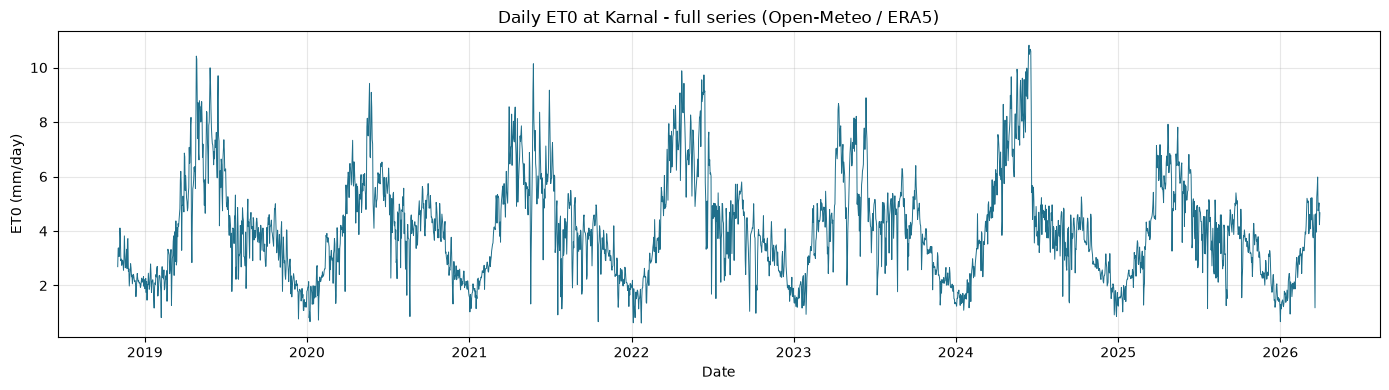

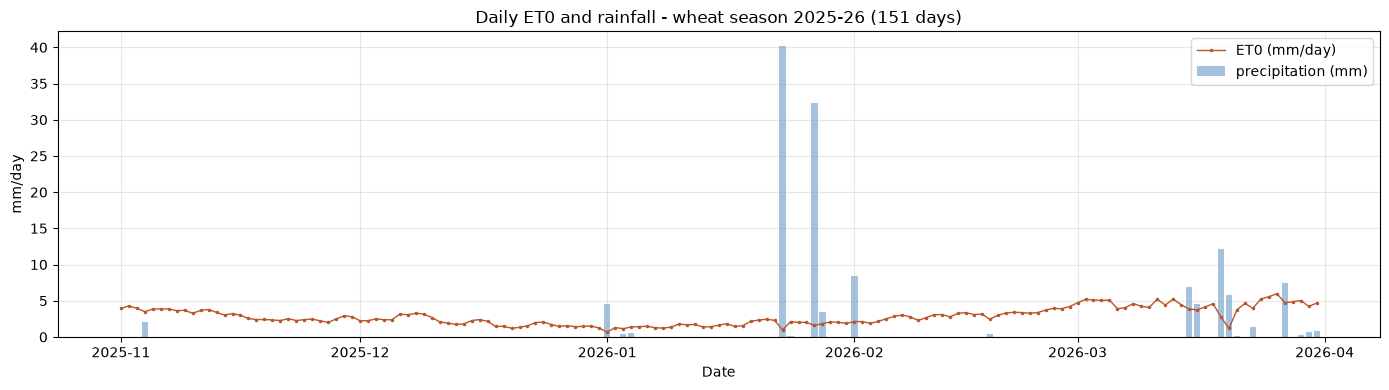

In [5]:
# ---- 1. Row count and the REAL date range returned --------------------------------
print("=" * 70)
print("1. ROWS AND DATE RANGE")
print("=" * 70)
print(f"Requested: {START} to {END}")
print(f"Returned:  {df.index.min().date()} to {df.index.max().date()}")
print(f"Total rows: {len(df)}")

# A complete daily series has exactly one row per calendar day. Comparing the row count with
# the number of days in the range shows whether any dates are missing ENTIRELY, which is a
# different problem from present-but-NaN (covered in section 2).
expected_days = (df.index.max() - df.index.min()).days + 1
print(f"Calendar days in that range: {expected_days}")
print(f"Missing calendar dates: {expected_days - len(df)}")
print(f"Duplicate dates: {int(df.index.duplicated().sum())}")

# ---- 2. Missing values per column --------------------------------------------------
print("\n" + "=" * 70)
print("2. MISSING VALUES PER COLUMN")
print("=" * 70)
missing = df.isna().sum()
print(pd.DataFrame({
    "missing": missing,
    "pct": (100 * missing / len(df)).round(2),
}).to_string())

if missing.sum() == 0:
    print("\nNo missing values anywhere.")
else:
    print("\nColumns with gaps:", list(missing[missing > 0].index))

# ---- 3. Rows per wheat season ------------------------------------------------------
print("\n" + "=" * 70)
print("3. ROWS PER WHEAT SEASON (Nov-Mar)")
print("=" * 70)

def wheat_season(date):
    # Label the Nov-Mar wheat season a date belongs to, or None if it is out of season.
    # A season spans two calendar years: Nov-Dec sit in the starting year and Jan-Mar in
    # the following one, so Nov 2019 and Feb 2020 both belong to season "2019-20".
    if date.month >= 11:                       # Nov, Dec -> season starts this year
        return f"{date.year}-{str(date.year + 1)[2:]}"
    if date.month <= 3:                        # Jan, Feb, Mar -> season started last year
        return f"{date.year - 1}-{str(date.year)[2:]}"
    return None                                # Apr-Oct: outside the wheat season

df["season"] = [wheat_season(d) for d in df.index]

in_season = df[df["season"].notna()]
print(f"Rows inside Nov-Mar wheat seasons: {len(in_season)} of {len(df)} total")
print(f"Rows outside (Apr-Oct):            {len(df) - len(in_season)}\n")

# A full Nov 1 - Mar 31 season is 151 days, or 152 in a leap year. The "complete?" column
# therefore shows at a glance whether a season is truncated at either end.
season_counts = in_season.groupby("season").agg(
    rows=("season", "size"),
    first_date=("season", lambda s: s.index.min().date()),
    last_date=("season",  lambda s: s.index.max().date()),
)
season_counts["complete?"] = np.where(season_counts["rows"] >= 151, "yes", "SHORT")
print(season_counts.to_string())

# ---- 4. describe() for the ET0 target ----------------------------------------------
print("\n" + "=" * 70)
print("4. ET0 TARGET SUMMARY  (mm/day)")
print("=" * 70)
ET0 = "et0_fao_evapotranspiration"
print("Full year (all 12 months):")
print(df[ET0].describe().to_string())
print("\nWheat season only (Nov-Mar), the range the model actually has to handle:")
print(in_season[ET0].describe().to_string())

# ---- 5. Plots -----------------------------------------------------------------------
# Plot A: the whole series. We expect a clean repeating annual wave: low ET0 in the cool
# winter, high in the pre-monsoon heat. A flat line or a gap would mean bad data.
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(df.index, df[ET0], linewidth=0.7, color="#1f6f8b")
ax.set_title("Daily ET0 at Karnal - full series (Open-Meteo / ERA5)")
ax.set_xlabel("Date")
ax.set_ylabel("ET0 (mm/day)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Plot B: one single wheat season, so the within-season shape is visible at this scale.
# We pick the most recent COMPLETE season so the picture is not a truncated one.
complete_seasons = season_counts[season_counts["complete?"] == "yes"].index.tolist()
focus_season = complete_seasons[-1] if complete_seasons else season_counts.index[-1]
one = df[df["season"] == focus_season]

fig, ax = plt.subplots(figsize=(14, 4))
# Rainfall is plotted alongside ET0 because the irrigate decision depends on both:
# high water loss only matters if rain has not already supplied the water.
ax.bar(one.index, one["precipitation_sum"], color="#5a8fc4", alpha=0.55, label="precipitation (mm)")
ax.plot(one.index, one[ET0], marker=".", markersize=3, linewidth=1.0, color="#b8562a", label="ET0 (mm/day)")
ax.set_title(f"Daily ET0 and rainfall - wheat season {focus_season} ({len(one)} days)")
ax.set_xlabel("Date")
ax.set_ylabel("mm/day")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Cell 6 - Sources and known limitations

### Data sources

- **Open-Meteo Historical Weather API** (ERA5 reanalysis), primary source, keyless.
  Docs: https://open-meteo.com/en/docs/historical-weather-api
  Endpoint used: `https://archive-api.open-meteo.com/v1/archive`
  Supplies our prediction target `et0_fao_evapotranspiration` plus the daily weather drivers.

- **NASA POWER daily point API** (`community=AG`, MERRA-2 based), independent cross-check, keyless.
  Docs: https://power.larc.nasa.gov/docs/services/api/temporal/daily/
  Endpoint used: `https://power.larc.nasa.gov/api/temporal/daily/point`
  Supplies a second, independently produced estimate of temperature, humidity, wind, radiation
  and rainfall for the same point and the same days.

### Limitation we must state in the write-up

**ET0 here is CALCULATED, not measured.** Both datasets are model reanalysis products. The ET0
figure comes from the FAO-56 Penman-Monteith equation applied to modelled gridded weather, not
from a lysimeter or flux tower standing in a Karnal field. Our model therefore learns to predict
a *physics-based estimate* of crop water loss, not ground truth.

Three consequences we should be upfront about:

1. Any systematic bias in the reanalysis is baked into our target, and our accuracy scores
   cannot detect it. We can measure agreement with the estimate, not agreement with reality.
2. ERA5 and MERRA-2 are gridded at roughly 10-30 km, so one value stands in for a wide area.
   Real field conditions (soil type, irrigation history, local wind shelter) vary inside that cell.
3. ET0 is *reference* ET, the demand of a standard short grass surface. Actual wheat water use is
   ET0 multiplied by a crop coefficient (Kc) that changes across growth stages. Our output is a
   water-demand signal, not a literal "mm of water to apply" figure.

Keeping the second source at least lets us quantify how much two independent reanalyses disagree
on the same day, which gives a lower bound on input uncertainty.

---

# Step 1 - Target and train/test split

Everything above downloads and audits the raw weather. From here we turn that table into a
supervised learning problem: one row per day, with the thing we want to predict attached to it.

Two decisions get made in this step, and both are the kind of thing judges should be able to
check: **what exactly the target is**, and **which days are allowed to be used for training**.

## Cell 7 - Load the merged daily table

We reload from `data/karnal_daily.csv` instead of reusing the `df` left in memory above. That
makes this half of the notebook runnable on its own, and it proves the saved CSV is actually
complete rather than us depending on a variable that happens to still be in the kernel.

The date column is called `date`. We parse it to datetime and sort chronologically, because
the very next step uses `shift(-1)` and a shift is only meaningful on an ordered series.

In [6]:
# Load the file Cell 4 wrote. Only pandas and numpy from here on.
daily = pd.read_csv("data/karnal_daily.csv")

# Confirm the column name rather than assuming it, and show what we got.
print("Columns in the CSV:")
print(list(daily.columns))
assert "date" in daily.columns, "Expected a column called 'date' - check Cell 4's output"

# Parse dates to real datetimes so we can do arithmetic and ordering on them.
daily["date"] = pd.to_datetime(daily["date"])

# Sort by date. shift(-1) in the next cell reads the physically NEXT ROW, so if the rows were
# out of order, "tomorrow" would silently be the wrong day.
daily = daily.sort_values("date").reset_index(drop=True)

print(f"\nLoaded {len(daily)} rows, {daily['date'].min().date()} to {daily['date'].max().date()}")

# A shift is only a true "next day" if the series has no missing dates. We check instead of
# trusting it: every gap between consecutive rows must be exactly 1 day.
gaps = daily["date"].diff().dropna()
day_gaps = gaps.value_counts()
print("\nGaps between consecutive rows (should be 1 day for every row):")
print(day_gaps.to_string())
if (gaps != pd.Timedelta(days=1)).any():
    print("\nWARNING: the series is NOT continuous. shift(-1) would not mean 'tomorrow'.")
    print(daily.loc[gaps[gaps != pd.Timedelta(days=1)].index, "date"])
else:
    print("\nSeries is continuous: every row is exactly one day after the previous one.")

Columns in the CSV:
['date', 'et0_fao_evapotranspiration', 'precipitation_sum', 'temperature_2m_max', 'temperature_2m_min', 'wind_speed_10m_max', 'shortwave_radiation_sum', 'relative_humidity_2m_mean', 'T2M_MAX_nasa', 'T2M_MIN_nasa', 'RH2M_nasa', 'WS2M_nasa', 'ALLSKY_SFC_SW_DWN_nasa', 'PRECTOTCORR_nasa']

Loaded 2708 rows, 2018-11-01 to 2026-03-31

Gaps between consecutive rows (should be 1 day for every row):
date
1 days    2707

Series is continuous: every row is exactly one day after the previous one.


## Cell 8 - Build the target, the season label, and day-of-season

Three things happen here, in this order, and the order matters.

**1. The target `et0_tomorrow`.** Our tool answers "should I irrigate tomorrow?", so the label
on today's row is *tomorrow's* ET0. We build it with `shift(-1)` on the **full continuous daily
series, before any filtering**. If we filtered to Nov-Mar first, then 31 March's "tomorrow"
would become the following 1 November - a day seven months later - and the model would be
trained on a flatly false example. Doing the shift first makes "tomorrow" always the real
next calendar day.

**2. The `season` label.** A wheat season runs 1 November to 31 March and is named by its
starting year, so 1 Nov 2018 to 31 Mar 2019 is `2018-19`. April to October gets no season.

**3. Filtering.** We then keep only rows where **today and tomorrow are inside the same
season**. This necessarily drops the final day of every season (31 March), because its
tomorrow, 1 April, is out of season. We print that count rather than letting it vanish.

**4. `day_of_season`.** Days since 1 November of that season, 0 to 150. Wheat water demand
follows the crop's growth stage, not the calendar month, so "how far into the season are we"
is a more useful number to a model than a raw date.

In [7]:
# ---- 1. TARGET: tomorrow's ET0 ------------------------------------------------------
# shift(-1) pulls the NEXT row's value up onto today's row. Done here, on the full
# uninterrupted daily series, BEFORE any season filtering (see markdown above).
daily["et0_tomorrow"] = daily["et0_fao_evapotranspiration"].shift(-1)

# The very last row (2026-03-31) has no following day, so its target is NaN by construction.
print(f"Rows with no tomorrow (last row of the whole series): "
      f"{int(daily['et0_tomorrow'].isna().sum())}")

# ---- 2. SEASON LABEL ----------------------------------------------------------------
def wheat_season(date):
    # Name the Nov-Mar wheat season a date belongs to, or None if out of season.
    # A season straddles two calendar years: Nov-Dec are in the starting year, Jan-Mar in
    # the next one. So Nov 2018 and Mar 2019 both belong to season "2018-19".
    if date.month >= 11:                      # Nov, Dec -> this year starts the season
        return f"{date.year}-{str(date.year + 1)[2:]}"
    if date.month <= 3:                       # Jan, Feb, Mar -> last year started it
        return f"{date.year - 1}-{str(date.year)[2:]}"
    return None                               # Apr-Oct -> no wheat season

daily["season"] = [wheat_season(d) for d in daily["date"]]

# The season a row's TOMORROW belongs to. Same shift trick, so the two line up row by row.
daily["season_tomorrow"] = daily["season"].shift(-1)

# ---- 3. FILTER: today and tomorrow must be in the SAME season -----------------------
before = len(daily)

in_season_today = daily["season"].notna()                      # today is Nov-Mar
same_season     = daily["season"] == daily["season_tomorrow"]   # and tomorrow is the same season
keep            = in_season_today & same_season

# Account for every dropped row by reason, so nothing disappears unexplained.
n_out_of_season   = int((~in_season_today).sum())
n_season_last_day = int((in_season_today & ~same_season).sum())

data = daily[keep].copy()

print(f"\nRows before filtering: {before}")
print(f"  dropped, today is outside Nov-Mar (Apr-Oct):      {n_out_of_season}")
print(f"  dropped, last day of a season (tomorrow is Apr 1): {n_season_last_day}")
print(f"Rows kept: {len(data)}   (check: {before} - {n_out_of_season} - {n_season_last_day} "
      f"= {before - n_out_of_season - n_season_last_day})")
print(f"\nThe {n_season_last_day} season-last-day drops are one per season - there are "
      f"{daily['season'].nunique()} seasons in the data.")

# After this filter every kept row must have a real target. If not, something is wrong.
assert data["et0_tomorrow"].notna().all(), "A kept row has no target - investigate before continuing"
print("Every kept row has a real et0_tomorrow value (no NaN targets).")

# ---- 4. DAY OF SEASON ----------------------------------------------------------------
# 1 November of the season's STARTING year. The season name's first four characters are
# that year, e.g. "2018-19" -> 2018 -> 2018-11-01.
season_start = pd.to_datetime(data["season"].str[:4] + "-11-01")

# .dt.days turns the timedelta into a plain integer count of days.
data["day_of_season"] = (data["date"] - season_start).dt.days

print(f"\nday_of_season range: {data['day_of_season'].min()} to {data['day_of_season'].max()}")
# A 151-day season (Nov 1 - Mar 31) minus its dropped last day leaves days 0-149, or 0-150
# in a leap year where February has an extra day.
assert data["day_of_season"].min() == 0, "Season should start at day 0"

data[["date", "season", "day_of_season", "et0_fao_evapotranspiration", "et0_tomorrow"]].head()

Rows with no tomorrow (last row of the whole series): 1

Rows before filtering: 2708
  dropped, today is outside Nov-Mar (Apr-Oct):      1498
  dropped, last day of a season (tomorrow is Apr 1): 8
Rows kept: 1202   (check: 2708 - 1498 - 8 = 1202)

The 8 season-last-day drops are one per season - there are 8 seasons in the data.
Every kept row has a real et0_tomorrow value (no NaN targets).

day_of_season range: 0 to 150


,date,season,day_of_season,et0_fao_evapotranspiration,et0_tomorrow
0,2018-11-01,2018-19,0,2.69,3.37
1,2018-11-02,2018-19,1,3.37,3.38
2,2018-11-03,2018-19,2,3.38,3.06
3,2018-11-04,2018-19,3,3.06,3.24
4,2018-11-05,2018-19,4,3.24,4.11


## Cell 9 - Split by season, never randomly

We hold out the two most recent seasons as the test set and train on the six before them:

- **TRAIN:** 2018-19, 2019-20, 2020-21, 2021-22, 2022-23, 2023-24
- **TEST:** 2024-25, 2025-26

The printout below is the evidence that the split is clean. The `assert` at the end is the
important line: it fails loudly if any training day is on or after any test day, which is the
one mistake that would quietly invalidate every result later in the notebook.

We also print the mean and standard deviation of `et0_tomorrow` per split. If train and test
have very different means, the test seasons were simply hotter or cooler than the training
ones, and we need to say so when reporting accuracy rather than pretending the two are
interchangeable.

In [8]:
TRAIN_SEASONS = ["2018-19", "2019-20", "2020-21", "2021-22", "2022-23", "2023-24"]
TEST_SEASONS  = ["2024-25", "2025-26"]

# Fail early if a season name is misspelled or absent, rather than silently training on less data.
available = set(data["season"].unique())
missing = [s for s in TRAIN_SEASONS + TEST_SEASONS if s not in available]
assert not missing, f"These seasons are not in the data: {missing}. Available: {sorted(available)}"

# .isin() selects whole seasons, so no single day can land on the wrong side of the split.
train_df = data[data["season"].isin(TRAIN_SEASONS)].copy()
test_df  = data[data["season"].isin(TEST_SEASONS)].copy()

print("=" * 70)
print("TRAIN / TEST SPLIT BY SEASON")
print("=" * 70)
print(f"TRAIN: {len(train_df):>4} rows   {train_df['date'].min().date()} to {train_df['date'].max().date()}")
print(f"TEST:  {len(test_df):>4} rows   {test_df['date'].min().date()} to {test_df['date'].max().date()}")
print(f"TOTAL: {len(train_df) + len(test_df):>4} rows   (all usable rows: {len(data)})")

# Every usable row must end up in exactly one split - no row silently left out.
# Every usable row must sit in exactly ONE split, and no row may be in both.
assert set(train_df["date"]).isdisjoint(set(test_df["date"])), "A row is in both splits"

# Rows outside both splits are EXPECTED once the download window runs past the test
# seasons: those days are operational input for the current season, never training or
# test data. They are named here so they can never pass unnoticed.
_held = data[~data["season"].isin(TRAIN_SEASONS + TEST_SEASONS)]
if len(_held):
    print(f"\nOutside both splits: {len(_held)} rows in season(s) "
          f"{sorted(_held['season'].unique())} "
          f"({_held['date'].min().date()} to {_held['date'].max().date()}).")
    print("These are OPERATIONAL days only - not training data, not test data.")
assert len(train_df) + len(test_df) + len(_held) == len(data), "Rows lost in the split"

# ---- Rows per season, with the target's mean and spread -----------------------------
print("\nPer season:")
per_season = data.groupby("season").agg(
    rows=("et0_tomorrow", "size"),
    first_date=("date", "min"),
    last_date=("date", "max"),
    et0_tomorrow_mean=("et0_tomorrow", "mean"),
    et0_tomorrow_std=("et0_tomorrow", "std"),
).round(3)
# Mark which side of the split each season is on, so the table is readable on its own.
per_season["split"] = np.where(per_season.index.isin(TRAIN_SEASONS), "train", "test")
per_season["first_date"] = per_season["first_date"].dt.date
per_season["last_date"]  = per_season["last_date"].dt.date
print(per_season.to_string())

# ---- Target distribution per split ---------------------------------------------------
print("\nTarget (et0_tomorrow, mm/day) by split:")
for name, frame in [("TRAIN", train_df), ("TEST", test_df)]:
    col = frame["et0_tomorrow"]
    print(f"  {name:<6} n={len(frame):>4}  mean={col.mean():.3f}  std={col.std():.3f}  "
          f"min={col.min():.2f}  max={col.max():.2f}")

gap = test_df["et0_tomorrow"].mean() - train_df["et0_tomorrow"].mean()
print(f"\nTest mean minus train mean: {gap:+.3f} mm/day")
print("If this is large, the test seasons were genuinely different weather, not just a harder")
print("modelling problem - something to state honestly when we report accuracy.")

# ---- The critical check: no training day may come at or after any test day -----------
latest_train = train_df["date"].max()
earliest_test = test_df["date"].min()
print(f"\nLatest train date:  {latest_train.date()}")
print(f"Earliest test date: {earliest_test.date()}")
assert latest_train < earliest_test, (
    f"LEAKAGE: training data runs to {latest_train.date()}, which is not before the first "
    f"test day {earliest_test.date()}"
)
print("PASSED: every training day is strictly before every test day. No time leakage.")

TRAIN / TEST SPLIT BY SEASON
TRAIN:  902 rows   2018-11-01 to 2024-03-30
TEST:   300 rows   2024-11-01 to 2026-03-30
TOTAL: 1202 rows   (all usable rows: 1202)

Per season:
         rows  first_date   last_date  et0_tomorrow_mean  et0_tomorrow_std  split
season                                                                           
2018-19   150  2018-11-01  2019-03-30              2.739             1.012  train
2019-20   151  2019-11-01  2020-03-30              2.548             1.009  train
2020-21   150  2020-11-01  2021-03-30              3.059             1.334  train
2021-22   150  2021-11-01  2022-03-30              3.000             1.504  train
2022-23   150  2022-11-01  2023-03-30              3.019             1.108  train
2023-24   151  2023-11-01  2024-03-30              2.744             1.178  train
2024-25   150  2024-11-01  2025-03-30              2.785             1.150   test
2025-26   150  2025-11-01  2026-03-30              2.830             1.183   test

Target

/var/folders/79/nstg_x4s1115ryxzdc4vs_rr0000gn/T/ipykernel_28517/2237667795.py:31: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(3)


## Why we split by time and never shuffle

A random shuffle would be the easy thing to do, and it would make our numbers look better than
they are. Here is why we refuse it.

**Weather is strongly autocorrelated.** Today's ET0 and tomorrow's ET0 are nearly the same
number, and a whole week of February tends to look alike. If we shuffled all the days together
and then split, the model would be trained on Tuesday and Thursday of a given week and tested
on the Wednesday sitting between them. It is not predicting at that point, it is interpolating
between two days it has already memorised. The score would be high and the score would be
meaningless.

**It does not match how the tool is actually used.** A farmer in November 2024 has access to
every past season, and to nothing at all from the future. Training on 2018-19 through 2023-24
and testing on 2024-25 and 2025-26 reproduces exactly that situation. The accuracy we measure
is then the accuracy a real user would have experienced, which is the only number worth
reporting.

**Holding out whole seasons, not scattered days.** We hold out two complete seasons rather than
the last 20% of days. Each season has its own character: some winters are warmer, some have more
rain, one may have an unusual dry spell. Testing on two entire unseen seasons asks the honest
question - does this work on a year it has never met? - instead of the easy one.

The cost is a smaller test set and a noisier estimate, since two seasons is two samples of
"a year". We accept that, and we will look at the two test seasons separately as well as
together so a single odd season cannot hide behind an average.

---

# Step 2 - Baselines

Before any machine learning we need to know what "good" even means. A model that predicts
tomorrow's ET0 to within 0.5 mm/day sounds impressive until you find out that simply guessing
"same as today" gets within 0.45 mm/day. Then the model is worse than doing nothing.

So we build the two dumbest reasonable predictors first, measure them on the held-out test
seasons, and treat the better of the two as the bar every later model has to clear.

## Cell 10 - The evaluation function

One function, reused for every baseline and every model from here on, so that no comparison in
this notebook is ever made with inconsistent arithmetic. We compute all three metrics by hand
with numpy rather than importing them, so we can explain each formula out loud.

- **MAE** (mean absolute error, mm/day): the average size of our mistake, ignoring direction.
  This is the number a farmer cares about - "typically how many mm off are you?"
- **RMSE** (root mean squared error, mm/day): squares the errors before averaging, so one big
  miss hurts more than several small ones. Always >= MAE. If RMSE is much larger than MAE, the
  errors are spiky rather than uniform.
- **bias** (mean of prediction minus actual, mm/day): the direction of our mistake. Positive
  means we systematically **over**-predict water loss, which would advise irrigating too much.
  Negative means we under-predict, risking crop stress. A model can have good MAE and terrible
  bias, so we always look at both.

In [9]:
def evaluate(y_true, y_pred, name):
    # Score one set of predictions. Returns a dict so results stack neatly into a table.
    # Metrics are written out with numpy so every formula is visible and explainable.

    # np.asarray so this works whether we are handed a pandas Series or a plain list,
    # and float so integer inputs cannot cause integer division surprises.
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    # Guard: comparing arrays of different lengths would silently broadcast or crash later.
    assert len(y_true) == len(y_pred), f"{name}: {len(y_true)} actuals vs {len(y_pred)} predictions"
    # Guard: a NaN anywhere would make every metric NaN, which is easy to miss in a table.
    assert not np.isnan(y_true).any(), f"{name}: NaN in the actual values"
    assert not np.isnan(y_pred).any(), f"{name}: NaN in the predictions"

    errors = y_pred - y_true          # signed error, one per day; positive = we guessed too high

    mae  = np.mean(np.abs(errors))    # average absolute size of the error, mm/day
    rmse = np.sqrt(np.mean(errors ** 2))  # square, average, square-root: penalises big misses
    bias = np.mean(errors)            # average signed error: which way we lean, mm/day

    return {
        "model": name,
        "n": len(y_true),             # how many days this score is based on
        "MAE": mae,
        "RMSE": rmse,
        "bias": bias,
    }

# Sanity check on a case we know the answer to: predictions 1 mm too high every day
# must give MAE 1.0, RMSE 1.0 and bias +1.0.
check = evaluate([2.0, 3.0, 4.0], [3.0, 4.0, 5.0], "self-test")
print(f"Self-test (always 1 mm too high): MAE={check['MAE']:.3f}  "
      f"RMSE={check['RMSE']:.3f}  bias={check['bias']:+.3f}")
assert np.isclose(check["MAE"], 1.0) and np.isclose(check["RMSE"], 1.0) and np.isclose(check["bias"], 1.0)
print("evaluate() behaves as expected.")

Self-test (always 1 mm too high): MAE=1.000  RMSE=1.000  bias=+1.000
evaluate() behaves as expected.


## Cell 11 - Baseline A: persistence ("tomorrow will be like today")

The prediction is literally today's ET0 value. No training, no parameters, nothing fitted. A
farmer could do this from memory.

This is the baseline that matters most, because weather is **persistent**: the atmosphere does
not reinvent itself overnight. If today was hot, dry and windy, tomorrow probably will be too.
In weather forecasting this is the standard reference that any real forecast must beat, and for
one-day-ahead predictions it is genuinely hard to beat.

In [10]:
# The prediction IS today's ET0 column. Nothing is fitted, so there is no train step at all
# and no possibility of leakage.
test_df["pred_persistence"] = test_df["et0_fao_evapotranspiration"]

print("Baseline A, persistence: prediction = today's ET0, copied forward one day.")
print("\nFirst few test days, to show the mechanic plainly:")
preview = test_df[["date", "et0_fao_evapotranspiration", "et0_tomorrow", "pred_persistence"]].head(6).copy()
preview["error"] = preview["pred_persistence"] - preview["et0_tomorrow"]
preview["date"] = preview["date"].dt.date
print(preview.to_string(index=False))

Baseline A, persistence: prediction = today's ET0, copied forward one day.

First few test days, to show the mechanic plainly:
      date  et0_fao_evapotranspiration  et0_tomorrow  pred_persistence  error
2024-11-01                        4.47          3.47              4.47   1.00
2024-11-02                        3.47          3.26              3.47   0.21
2024-11-03                        3.26          3.12              3.26   0.14
2024-11-04                        3.12          2.78              3.12   0.34
2024-11-05                        2.78          2.89              2.78  -0.11
2024-11-06                        2.89          2.78              2.89   0.11


## Cell 12 - Baseline B: seasonal average ("this is just what late January looks like")

For every `day_of_season` (0 to 150), we take the average `et0_tomorrow` across the **training
seasons only**, then use that average as the prediction whenever the test set reaches that same
day of season. It is the long-run climate normal for that point in the wheat calendar, and it
completely ignores today's actual weather.

Raw day-by-day averages over six seasons are noisy, so we smooth the curve with a **7-day
centred rolling mean**. Centred means day 40's smoothed value uses days 37 to 43, which is
legitimate here because this is a fixed seasonal shape computed once from past seasons, not a
running forecast - we are not peeking at the future of the test set, only at the shape of
training years.

**The thing to check:** this baseline is built from `train_df` and never touches `test_df`. If
it did, its score would be inflated and the whole comparison would be worthless.

In [11]:
# ---- Build the seasonal shape from TRAIN SEASONS ONLY --------------------------------
# One average per day-of-season, across the six training seasons.
raw_profile = train_df.groupby("day_of_season")["et0_tomorrow"].mean()

print(f"Built from {train_df['season'].nunique()} training seasons "
      f"({', '.join(sorted(train_df['season'].unique()))})")
print(f"day_of_season covered by the profile: {raw_profile.index.min()} to {raw_profile.index.max()}")
print(f"Days in the profile: {len(raw_profile)}  (each is the mean of up to "
      f"{train_df['season'].nunique()} seasons)")

# Reindex onto the complete 0..150 range so a missing day would show up as NaN rather than
# quietly shifting the rolling window. (Day 150 only exists in leap seasons.)
full_days = range(0, 151)
raw_profile = raw_profile.reindex(full_days)
if raw_profile.isna().any():
    print(f"\nNOTE: no training data for day_of_season {list(raw_profile[raw_profile.isna()].index)}")

# ---- Smooth it: 7-day centred rolling mean -------------------------------------------
# center=True puts the day in the middle of its window. min_periods=1 keeps the first and
# last few days instead of turning them into NaN - they are just averaged over fewer days.
profile = raw_profile.rolling(window=7, center=True, min_periods=1).mean()

print(f"\nSmoothed with a 7-day centred rolling mean.")
print(f"Roughness before smoothing (mean day-to-day jump): "
      f"{raw_profile.diff().abs().mean():.4f} mm/day")
print(f"Roughness after smoothing:                         "
      f"{profile.diff().abs().mean():.4f} mm/day")

# ---- Apply it to the test set ---------------------------------------------------------
# .map() looks up each test row's day_of_season in the profile built from training data only.
test_df["pred_seasonal"] = test_df["day_of_season"].map(profile)

# If any test day had no matching profile entry we would get NaN - catch it rather than
# letting evaluate() fail later with a less obvious message.
assert test_df["pred_seasonal"].notna().all(), (
    "Some test days have no seasonal profile value: "
    f"{test_df.loc[test_df['pred_seasonal'].isna(), 'day_of_season'].unique()}"
)

print(f"\nTest day_of_season range: {test_df['day_of_season'].min()} to "
      f"{test_df['day_of_season'].max()} - all found in the profile.")
print("\nThe profile at a few points in the season:")
for day in [0, 30, 60, 90, 120, 149]:
    # Day 0 is 1 Nov; day 149 is late March. Date shown for the non-leap case.
    label = (pd.Timestamp("2024-11-01") + pd.Timedelta(days=day)).strftime("%d %b")
    print(f"   day {day:>3} ({label}): {profile.loc[day]:.3f} mm/day")

Built from 6 training seasons (2018-19, 2019-20, 2020-21, 2021-22, 2022-23, 2023-24)
day_of_season covered by the profile: 0 to 150
Days in the profile: 151  (each is the mean of up to 6 seasons)

Smoothed with a 7-day centred rolling mean.
Roughness before smoothing (mean day-to-day jump): 0.1611 mm/day
Roughness after smoothing:                         0.0439 mm/day

Test day_of_season range: 0 to 149 - all found in the profile.

The profile at a few points in the season:
   day   0 (01 Nov): 3.418 mm/day
   day  30 (01 Dec): 2.270 mm/day
   day  60 (31 Dec): 1.686 mm/day
   day  90 (30 Jan): 2.182 mm/day
   day 120 (01 Mar): 3.659 mm/day
   day 149 (30 Mar): 5.407 mm/day


## Cell 13 - Score both baselines on the test set

We evaluate on the full 300-day test set, and then on each test season on its own. Two seasons
is a small sample of "a year", so a good pooled average could be hiding one season going badly.
Splitting them out is how we catch that.

`results` is the running ledger: later steps append their models to this same list, so the
final comparison table is guaranteed to use identical metrics on identical test days.

In [12]:
# The running ledger of every model scored on the FULL test set.
# Later steps append to this list - do not re-create it.
results = []

y_true = test_df["et0_tomorrow"]

results.append(evaluate(y_true, test_df["pred_persistence"], "Baseline A: persistence"))
results.append(evaluate(y_true, test_df["pred_seasonal"],    "Baseline B: seasonal average"))

# ---- Full test set table --------------------------------------------------------------
print("=" * 72)
print("TEST SET RESULTS  (2024-25 and 2025-26, 300 days, never seen in training)")
print("=" * 72)
results_table = pd.DataFrame(results)[["model", "n", "MAE", "RMSE", "bias"]]
print(results_table.round(3).to_string(index=False))

# ---- Per-season table -----------------------------------------------------------------
# Kept separate from `results` so that list stays a clean one-row-per-model ledger.
season_results = []
for season in sorted(test_df["season"].unique()):
    block = test_df[test_df["season"] == season]
    for pred_col, label in [("pred_persistence", "Baseline A: persistence"),
                            ("pred_seasonal",    "Baseline B: seasonal average")]:
        row = evaluate(block["et0_tomorrow"], block[pred_col], label)
        row["season"] = season
        season_results.append(row)

print("\n" + "=" * 72)
print("PER TEST SEASON")
print("=" * 72)
season_table = pd.DataFrame(season_results)[["season", "model", "n", "MAE", "RMSE", "bias"]]
print(season_table.round(3).to_string(index=False))

# ---- State the bar explicitly ----------------------------------------------------------
best = results_table.loc[results_table["MAE"].idxmin()]
print("\n" + "=" * 72)
print(f"BAR TO BEAT: {best['model']}  -  MAE {best['MAE']:.3f} mm/day")
print("Any model in the following steps that does not beat this is not worth using.")
print("=" * 72)

TEST SET RESULTS  (2024-25 and 2025-26, 300 days, never seen in training)
                       model   n   MAE  RMSE   bias
     Baseline A: persistence 300 0.323 0.466 -0.010
Baseline B: seasonal average 300 0.402 0.560  0.037

PER TEST SEASON
 season                        model   n   MAE  RMSE   bias
2024-25      Baseline A: persistence 150 0.302 0.425 -0.015
2024-25 Baseline B: seasonal average 150 0.381 0.519  0.060
2025-26      Baseline A: persistence 150 0.344 0.504 -0.005
2025-26 Baseline B: seasonal average 150 0.423 0.598  0.014

BAR TO BEAT: Baseline A: persistence  -  MAE 0.323 mm/day
Any model in the following steps that does not beat this is not worth using.


## Cell 14 - Look at one test season

Numbers in a table hide the shape of the problem. This plots the 2024-25 test season: the
actual `et0_tomorrow` we were trying to predict, with both baselines drawn over it.

What to look for: the seasonal average (smooth curve) captures the slow winter dip and the
March rise but cannot react to anything; persistence tracks every wiggle but is always one day
late, so it overshoots on the way up and undershoots on the way down. Those are the two
distinct kinds of error a real model would need to improve on.

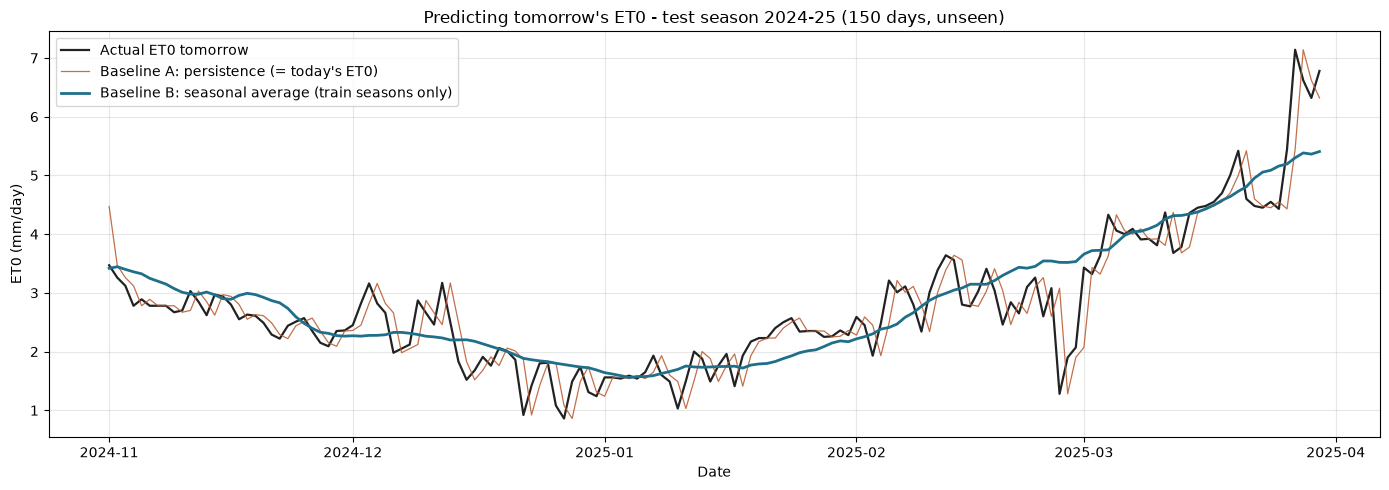

2024-25 MAE, persistence       : 0.302 mm/day
2024-25 MAE, seasonal average  : 0.381 mm/day


In [13]:
PLOT_SEASON = "2024-25"
one = test_df[test_df["season"] == PLOT_SEASON]

fig, ax = plt.subplots(figsize=(14, 5))

# Actual target first, in a heavier dark line, so the baselines read as overlays on truth.
ax.plot(one["date"], one["et0_tomorrow"], color="#222222", linewidth=1.6,
        label="Actual ET0 tomorrow")
# Persistence: thin and jagged, because it is yesterday's noise shifted one day.
ax.plot(one["date"], one["pred_persistence"], color="#b8562a", linewidth=0.9, alpha=0.85,
        label="Baseline A: persistence (= today's ET0)")
# Seasonal average: smooth, because it is a fixed curve from the training seasons.
ax.plot(one["date"], one["pred_seasonal"], color="#1f6f8b", linewidth=2.0,
        label="Baseline B: seasonal average (train seasons only)")

ax.set_title(f"Predicting tomorrow's ET0 - test season {PLOT_SEASON} ({len(one)} days, unseen)")
ax.set_xlabel("Date")
ax.set_ylabel("ET0 (mm/day)")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Print the MAE for this one season next to the plot, so the picture and the number agree.
for col, label in [("pred_persistence", "persistence"), ("pred_seasonal", "seasonal average")]:
    mae = np.mean(np.abs(one[col] - one["et0_tomorrow"]))
    print(f"{PLOT_SEASON} MAE, {label:<18}: {mae:.3f} mm/day")

## What the baselines are, and why they are the bar

**Baseline A, persistence.** Predict that tomorrow's ET0 equals today's. Nothing is fitted;
there are no parameters at all.

**Baseline B, seasonal average.** For each day of the wheat season, predict the average ET0
that day-of-season had across the six training seasons, smoothed over a 7-day window. This is
the climate normal: it knows that mid-January is cool and late March is hot, and nothing else.
It never sees today's weather.

**Why persistence is strong for weather.** Weather is autocorrelated - the atmosphere carries
its state forward. A cold, humid, still air mass sitting over Karnal today is very likely still
there tomorrow, so today's evaporative demand is already most of the answer. Persistence gets
that for free, with no model. This is why operational meteorology treats it as the reference
score: a forecast that cannot beat persistence has added no information. For a one-day horizon
it is a genuinely tough opponent, and the honest thing is to say so up front rather than
quietly comparing against something weaker.

**Why the seasonal average is the other half of the test.** It is strong in exactly the place
persistence is weak. Persistence has no idea what time of year it is, so it drifts wherever
today happened to land; the seasonal average is anchored to the calendar but deaf to today.
A model worth having should beat both, because beating only one may just mean it rediscovered
the other one's trick.

**The rule for the rest of this notebook.** Every model from here on is scored with the same
`evaluate()` function, on the same 300 held-out test days, and appended to the same `results`
list. If it does not beat the better of these two baselines on MAE, we report that it did not.
A model that ties with persistence is a model that learned nothing useful, and saying so is
worth more than dressing it up.

---

# Step 3 - Linear regression

The first real model. We deliberately start with the simplest thing that could possibly work:
a straight-line relationship between today's weather and tomorrow's ET0.

Linear regression is the right first model here for three reasons. It cannot overfit much with
8 features and 902 training rows. Its coefficients are readable, so we can see *what* it learned
rather than just *how well* it scored. And if a linear model already beats persistence, we have
a result we can fully explain; if it does not, we have learned something real about the problem.

## Cell 15 - Choose the features

All eight features come from **today** - the day before the one we are predicting. The list is
the Open-Meteo weather for today plus `day_of_season`, which tells the model where in the wheat
calendar we are.

We deliberately exclude the `_nasa` columns. They are our independent cross-check, so feeding
them to the model would spend them; they are used in a later step to ask a different question
(how much do two reanalyses disagree, and does that disagreement predict our errors?).

In [14]:
# NO FEATURE USES INFORMATION FROM TOMORROW.
# Every column below is measured on the row's own date, and the target et0_tomorrow was built
# with shift(-1) in Cell 8, meaning it came from the FOLLOWING row. So each training example is
# "today's observations -> tomorrow's ET0", which is exactly the situation at prediction time:
# a farmer standing in their field this evening knows all eight of these numbers and none of
# tomorrow's. day_of_season is a calendar fact, known years in advance, so it leaks nothing.
FEATURES = [
    "et0_fao_evapotranspiration",   # today's water loss - expected to dominate (persistence)
    "temperature_2m_max",           # today's max temp, degC
    "temperature_2m_min",           # today's min temp, degC
    "wind_speed_10m_max",           # today's max wind, km/h
    "shortwave_radiation_sum",      # today's solar energy, MJ/m2
    "relative_humidity_2m_mean",    # today's mean humidity, %
    "precipitation_sum",            # today's rain, mm
    "day_of_season",                # 0-150, days since 1 Nov: where we are in the crop calendar
]
TARGET = "et0_tomorrow"

# Hard guard against the one mistake that would invalidate everything: the target, or anything
# derived from it, appearing in the feature list.
assert TARGET not in FEATURES, "The target cannot be a feature"
assert not any("tomorrow" in f for f in FEATURES), "A feature name mentions 'tomorrow'"
# Guard against accidentally using the cross-check source.
assert not any(f.endswith("_nasa") for f in FEATURES), "NASA columns are reserved for the cross-check"

# Build the matrices. X = inputs, y = what we want to predict.
X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test,  y_test  = test_df[FEATURES],  test_df[TARGET]

print(f"Features ({len(FEATURES)}):")
for f in FEATURES:
    print("   ", f)
print(f"\nX_train: {X_train.shape}   y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape}   y_test:  {y_test.shape}")
print(f"\nRows per feature in training: {len(X_train) / len(FEATURES):.0f} "
      f"- plenty for a linear model, so overfitting should be mild.")

# A model cannot be fitted on NaN; confirm there are none rather than discovering it in the traceback.
assert X_train.notna().all().all() and X_test.notna().all().all(), "NaN in the feature matrix"
assert y_train.notna().all() and y_test.notna().all(), "NaN in the target"
print("No missing values in features or target.")

Features (8):
    et0_fao_evapotranspiration
    temperature_2m_max
    temperature_2m_min
    wind_speed_10m_max
    shortwave_radiation_sum
    relative_humidity_2m_mean
    precipitation_sum
    day_of_season

X_train: (902, 8)   y_train: (902,)
X_test:  (300, 8)   y_test:  (300,)

Rows per feature in training: 113 - plenty for a linear model, so overfitting should be mild.
No missing values in features or target.


## Cell 16 - Build and fit the pipeline

A scikit-learn `Pipeline` with two steps:

1. **`StandardScaler`** - rescales each feature to mean 0 and standard deviation 1. Our features
   are on wildly different scales (radiation in tens of MJ/m2, rain often 0, humidity up to 100),
   and without scaling the coefficients would be meaningless to compare. After scaling, a
   coefficient means "mm/day of change in tomorrow's ET0 per one standard deviation of this
   feature", so the numbers are directly comparable.
2. **`LinearRegression`** - fits one straight-line weight per feature plus an intercept.

The reason to use a `Pipeline` rather than scaling by hand is **leakage safety**. Inside a
pipeline, `.fit()` lets the scaler learn its mean and standard deviation from the training rows
only, and `.predict()` then reuses those stored training statistics on the test rows. If we had
scaled the whole dataset before splitting, the training data would have been nudged by
information from the test seasons, and our test score would be mildly optimistic for reasons
nobody would spot in the output.

In [15]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

model = Pipeline([
    ("scaler", StandardScaler()),       # step 1: put all features on a comparable scale
    ("linreg", LinearRegression()),     # step 2: fit one weight per feature + an intercept
])

# Fit on TRAIN ONLY. X_test is not passed here and is not visible to the scaler.
model.fit(X_train, y_train)

print("Fitted on TRAIN only:")
print(f"   {len(X_train)} rows, seasons {', '.join(sorted(train_df['season'].unique()))}")

# Show that the scaler's statistics came from the training rows, by comparing them with the
# training means. If these matched the TEST means instead, we would have a leakage bug.
scaler = model.named_steps["scaler"]
check = pd.DataFrame({
    "scaler_mean": scaler.mean_,
    "train_mean":  X_train.mean().values,
    "test_mean":   X_test.mean().values,
}, index=FEATURES).round(3)
print("\nThe scaler learned these means. They must match train_mean, not test_mean:")
print(check.to_string())
assert np.allclose(scaler.mean_, X_train.mean().values), "Scaler did not fit on training data"
print("\nConfirmed: the scaler's statistics come from TRAIN only. No leakage.")

Fitted on TRAIN only:
   902 rows, seasons 2018-19, 2019-20, 2020-21, 2021-22, 2022-23, 2023-24

The scaler learned these means. They must match train_mean, not test_mean:
                            scaler_mean  train_mean  test_mean
et0_fao_evapotranspiration        2.835       2.835      2.797
temperature_2m_max               22.424      22.424     22.858
temperature_2m_min               10.557      10.557     11.293
wind_speed_10m_max               13.353      13.353     12.437
shortwave_radiation_sum          14.071      14.071     14.011
relative_humidity_2m_mean        73.021      73.021     74.687
precipitation_sum                 1.156       1.156      0.687
day_of_season                    74.667      74.667     74.500

Confirmed: the scaler's statistics come from TRAIN only. No leakage.


## Cell 17 - Predict on the test seasons and score it

Same `evaluate()` function, same 300 held-out days, appended to the same `results` list as the
two baselines. That is what makes the comparison fair: nothing about the metric or the test days
changed between models.

We also compute **skill over persistence**, the standard way to express a weather forecast's
value:

```
skill = (persistence MAE - model MAE) / persistence MAE * 100
```

Positive means the model beats persistence by that percentage. **Negative means the model is
worse than copying today's value forward**, and if that is what we get, that is what we report.

In [16]:
# Predict on the test seasons. The pipeline applies the TRAIN-fitted scaling, then the weights.
test_df["pred_linreg"] = model.predict(X_test)

MODEL_NAME = "Linear regression (8 features)"

# Score on the full test set and add it to the shared ledger.
results.append(evaluate(y_test, test_df["pred_linreg"], MODEL_NAME))

# Per-season scores, appended to the same per-season ledger as the baselines.
for season in sorted(test_df["season"].unique()):
    block = test_df[test_df["season"] == season]
    row = evaluate(block[TARGET], block["pred_linreg"], MODEL_NAME)
    row["season"] = season
    season_results.append(row)

# ---- Skill over persistence ------------------------------------------------------------
# Pull both MAEs out of the results ledger by name, so the two numbers are guaranteed to
# be the ones actually in the table rather than recomputed differently here.
results_table = pd.DataFrame(results)
mae_persistence = float(results_table.loc[results_table["model"] == "Baseline A: persistence", "MAE"].iloc[0])
mae_model       = float(results_table.loc[results_table["model"] == MODEL_NAME, "MAE"].iloc[0])

skill = (mae_persistence - mae_model) / mae_persistence * 100

print("=" * 72)
print("SKILL OVER PERSISTENCE")
print("=" * 72)
print(f"Persistence MAE:      {mae_persistence:.4f} mm/day")
print(f"Linear regression MAE:{mae_model:.4f} mm/day")
print(f"Skill: ({mae_persistence:.4f} - {mae_model:.4f}) / {mae_persistence:.4f} * 100 = {skill:+.2f}%")
if skill > 0:
    print(f"\nThe model beats persistence by {skill:.2f}%.")
else:
    print(f"\nThe model is WORSE than persistence by {abs(skill):.2f}%.")

# ---- Updated full results table ---------------------------------------------------------
print("\n" + "=" * 72)
print("ALL MODELS SO FAR  (full test set: 300 days, 2024-25 and 2025-26)")
print("=" * 72)
print(results_table[["model", "n", "MAE", "RMSE", "bias"]].round(4).to_string(index=False))

print("\n" + "=" * 72)
print("PER TEST SEASON")
print("=" * 72)
season_table = pd.DataFrame(season_results)[["season", "model", "n", "MAE", "RMSE", "bias"]]
print(season_table.sort_values(["season", "MAE"]).round(4).to_string(index=False))

SKILL OVER PERSISTENCE
Persistence MAE:      0.3230 mm/day
Linear regression MAE:0.3022 mm/day
Skill: (0.3230 - 0.3022) / 0.3230 * 100 = +6.44%

The model beats persistence by 6.44%.

ALL MODELS SO FAR  (full test set: 300 days, 2024-25 and 2025-26)
                         model   n    MAE   RMSE    bias
       Baseline A: persistence 300 0.3230 0.4663 -0.0102
  Baseline B: seasonal average 300 0.4020 0.5599  0.0367
Linear regression (8 features) 300 0.3022 0.4426  0.0590

PER TEST SEASON
 season                          model   n    MAE   RMSE    bias
2024-25 Linear regression (8 features) 150 0.2801 0.4051  0.0446
2024-25        Baseline A: persistence 150 0.3018 0.4252 -0.0154
2024-25   Baseline B: seasonal average 150 0.3807 0.5193  0.0596
2025-26 Linear regression (8 features) 150 0.3244 0.4771  0.0734
2025-26        Baseline A: persistence 150 0.3443 0.5041 -0.0049
2025-26   Baseline B: seasonal average 150 0.4232 0.5978  0.0138


## Cell 18 - What the model learned: the coefficients

Because the features were standardised, the coefficients are on a common footing: each one is
the change in predicted ET0 (mm/day) for a one-standard-deviation increase in that feature,
holding the others fixed. So the **absolute size** ranks influence, and the **sign** says
direction.

Sorted by absolute size below, largest influence first.

In [17]:
linreg = model.named_steps["linreg"]

coefs = pd.DataFrame({
    "feature": FEATURES,
    "coefficient": linreg.coef_,     # one weight per feature, in standardised units
})
# abs_coef is only for sorting - the sign stays visible in the coefficient column.
coefs["abs_coef"] = coefs["coefficient"].abs()
coefs["direction"] = np.where(coefs["coefficient"] > 0, "raises ET0", "lowers ET0")
coefs = coefs.sort_values("abs_coef", ascending=False).reset_index(drop=True)

print("=" * 72)
print("COEFFICIENTS  (mm/day of predicted ET0 per 1 standard deviation of the feature)")
print("=" * 72)
print(coefs[["feature", "coefficient", "direction"]].round(4).to_string(index=False))

# The intercept is the prediction when every feature sits at its training mean, so it should
# land near the average target value. A wildly different number would signal a bug.
print(f"\nIntercept: {linreg.intercept_:.4f} mm/day")
print(f"(= the prediction when every feature is at its training mean;")
print(f" compare with the training target mean: {y_train.mean():.4f} mm/day)")

COEFFICIENTS  (mm/day of predicted ET0 per 1 standard deviation of the feature)
                   feature  coefficient  direction
et0_fao_evapotranspiration       0.7777 raises ET0
             day_of_season       0.2393 raises ET0
        temperature_2m_min       0.1625 raises ET0
 relative_humidity_2m_mean      -0.1207 lowers ET0
        wind_speed_10m_max      -0.0978 lowers ET0
        temperature_2m_max       0.0925 raises ET0
   shortwave_radiation_sum      -0.0587 lowers ET0
         precipitation_sum       0.0301 raises ET0

Intercept: 2.8510 mm/day
(= the prediction when every feature is at its training mean;
 compare with the training target mean: 2.8510 mm/day)


## Cell 19 - Sanity checks

Two checks that catch the most common ways a result like this can be quietly wrong.

**Train MAE against test MAE.** If the model scores far better on the data it was fitted to than
on unseen seasons, it memorised rather than learned. For a linear model with 8 features and 902
rows we expect the two to be close; a large gap would mean something is wrong, not that the model
is powerful.

**Range of the predictions.** ET0 is a physical quantity and cannot be negative - a crop cannot
gain water by evaporation. A linear model has no idea about that and will happily predict below
zero if the arithmetic takes it there. We check and flag it rather than silently clipping,
because a negative prediction is useful information about where the model breaks down.

In [18]:
# ---- Train vs test MAE (overfitting check) ----------------------------------------------
pred_train = model.predict(X_train)
mae_train = np.mean(np.abs(pred_train - y_train))
mae_test  = np.mean(np.abs(test_df["pred_linreg"] - y_test))

print("=" * 72)
print("OVERFITTING CHECK")
print("=" * 72)
print(f"Train MAE: {mae_train:.4f} mm/day   ({len(X_train)} rows the model was fitted on)")
print(f"Test MAE:  {mae_test:.4f} mm/day   ({len(X_test)} rows it has never seen)")
gap = mae_test - mae_train
print(f"Gap (test - train): {gap:+.4f} mm/day  =  {gap / mae_train * 100:+.1f}% of train MAE")
if abs(gap) < 0.05:
    print("Small gap: the model generalises to unseen seasons about as well as it fits train.")
else:
    print("Noticeable gap - worth discussing when we report results.")

# ---- Prediction range (physical plausibility) --------------------------------------------
pmin, pmax = test_df["pred_linreg"].min(), test_df["pred_linreg"].max()
print("\n" + "=" * 72)
print("PREDICTION RANGE")
print("=" * 72)
print(f"Predictions: {pmin:.4f} to {pmax:.4f} mm/day")
print(f"Actuals:     {y_test.min():.4f} to {y_test.max():.4f} mm/day")

n_negative = int((test_df["pred_linreg"] < 0).sum())
if n_negative > 0:
    print(f"\nFLAG: {n_negative} prediction(s) below zero, which is physically impossible")
    print("(ET0 cannot be negative - a crop cannot absorb water by evaporating).")
    print("We are NOT clipping them; they are reported as a known failure mode.")
    print(test_df.loc[test_df["pred_linreg"] < 0, ["date", "pred_linreg", TARGET]].to_string(index=False))
else:
    print("\nNo negative predictions: every prediction is physically plausible.")

OVERFITTING CHECK
Train MAE: 0.3479 mm/day   (902 rows the model was fitted on)
Test MAE:  0.3022 mm/day   (300 rows it has never seen)
Gap (test - train): -0.0457 mm/day  =  -13.1% of train MAE
Small gap: the model generalises to unseen seasons about as well as it fits train.

PREDICTION RANGE
Predictions: 1.1617 to 6.6363 mm/day
Actuals:     0.6700 to 7.1400 mm/day

No negative predictions: every prediction is physically plausible.


## Cell 20 - Reading the coefficients in plain words

Run Cell 18 first, then read this alongside its output. The ranking below is what the model
actually produced, including the two signs that are the opposite of what you would first expect.

**Today's ET0 carries almost all the signal.** `et0_fao_evapotranspiration` has by far the
largest coefficient, about +0.78, and the next largest is less than a third of that. It is
positive: a high-demand day today means a high-demand day tomorrow. The model's first move was
to rediscover the persistence baseline. That is reassuring rather than disappointing - it means
the fit found real physics and not noise - but it also explains why the model only improves on
persistence by a few percent. Everything else is a small correction on top.

**`day_of_season` is the second strongest, and it is the model's one genuine advantage.** Its
coefficient is positive, around +0.24: later in the season means higher demand, because the
wheat season ends in the pre-monsoon heat of late March. Persistence has no access to the
calendar at all, so this is where the model adds something persistence cannot. It is the single
clearest reason the model wins.

**Humidity pulls the prediction down,** as the physics requires. `relative_humidity_2m_mean` is
negative, around -0.12. Humid air is already close to saturated, so it accepts less water
vapour and evaporative demand falls. Getting this sign right is evidence the pipeline works.

**Minimum temperature matters more than maximum,** which is slightly surprising: `temperature_2m_min`
(about +0.16) outranks `temperature_2m_max` (about +0.09). A warm night means the air mass itself
is warm rather than the ground just heating up under one day's sun, and a warm air mass is more
likely to still be sitting there tomorrow. So the overnight minimum is the better clue about
*tomorrow*, even though the daytime maximum describes *today* more dramatically.

**Wind and radiation come out NEGATIVE, and this needs explaining honestly.**
`wind_speed_10m_max` (about -0.10) and `shortwave_radiation_sum` (about -0.06) both have the
opposite sign to the physics: wind carries saturated air away from the leaf and radiation
supplies the energy to evaporate water, so in isolation both should *raise* ET0.

The reason is **double counting**. Our strongest feature, today's ET0, was itself calculated
from today's wind, radiation, temperature and humidity using the FAO-56 equation. So wind and
radiation are already inside the first feature. Once the model has today's ET0, the leftover
wind and radiation terms are not measuring "does wind raise demand" any more - they are fitting
a small correction for how *tomorrow* tends to differ from today when today was unusually windy
or sunny. A very windy or very bright day is often an outlier that tomorrow partly reverts from,
which is a plausible reason for the mild negative sign.

Two consequences we should state out loud rather than bury:

1. **Individual coefficient signs are not trustworthy as physics here**, because the features
   overlap heavily (this is multicollinearity). The model's *predictions* are still valid - it
   is scored on held-out seasons, and that score stands - but we should not claim "the model
   proves wind reduces evaporation", because it does not.
2. The two suspicious coefficients are also the two smallest apart from rainfall, so very little
   of the prediction rests on them.

**Rainfall barely matters,** with the smallest coefficient of all (about +0.03). That is not a
bug: ET0 is *reference* evapotranspiration, the atmosphere's demand for water, not how much
water was available. Rain does not directly reduce the atmosphere's thirst, and the cloud and
humidity that accompany it are already captured by the other features. Rainfall will matter
enormously in the irrigation decision rule later, just not in predicting ET0 itself.

**Honest summary:** the model learned persistence, plus a seasonal trend, plus small corrections.
The large coefficients have the signs physics predicts; the two that do not are small and are
explained by feature overlap. That is a more useful thing to tell judges than pretending all
eight signs came out clean.

## Cell 21 - Did it beat persistence? An honest verdict

Fill this in from the printed numbers above - the figures below are produced by the cell, so
this section always matches what was actually computed.

In [19]:
# Reprint the single comparison that decides whether this model is worth anything, so the
# verdict in the write-up can never drift away from the measured numbers.
results_table = pd.DataFrame(results)

print("=" * 72)
print("VERDICT")
print("=" * 72)
ranked = results_table[["model", "MAE", "RMSE", "bias"]].sort_values("MAE").reset_index(drop=True)
print(ranked.round(4).to_string(index=False))

best_name = ranked.loc[0, "model"]
print(f"\nBest model on test MAE: {best_name}")

print(f"\nLinear regression vs persistence:")
print(f"   persistence MAE       {mae_persistence:.4f} mm/day")
print(f"   linear regression MAE {mae_model:.4f} mm/day")
print(f"   difference            {mae_model - mae_persistence:+.4f} mm/day")
print(f"   skill                 {skill:+.2f}%")

if skill > 0:
    print(f"\nThe linear model BEATS persistence, by {skill:.2f}% on MAE.")
    print(f"In practical terms it reduces the typical daily error by "
          f"{mae_persistence - mae_model:.4f} mm/day.")
    print("Whether that is worth the extra complexity is a judgement we should state openly:")
    print("persistence needs no code at all, and the model needs a fitted pipeline.")
else:
    print(f"\nThe linear model DOES NOT beat persistence. It is {abs(skill):.2f}% worse on MAE.")
    print("We report this as-is. For a one-day horizon, persistence is a strong baseline and")
    print("failing to beat it is a real result, not something to hide or tune away.")

# Bias is worth calling out separately: a model can win on MAE and still systematically
# over- or under-advise irrigation, which matters more to a farmer than the average error.
bias_p = float(results_table.loc[results_table["model"] == "Baseline A: persistence", "bias"].iloc[0])
bias_m = float(results_table.loc[results_table["model"] == MODEL_NAME, "bias"].iloc[0])
print(f"\nBias check (negative = under-predicts water loss, risking under-irrigation):")
print(f"   persistence       {bias_p:+.4f} mm/day")
print(f"   linear regression {bias_m:+.4f} mm/day")

VERDICT
                         model    MAE   RMSE    bias
Linear regression (8 features) 0.3022 0.4426  0.0590
       Baseline A: persistence 0.3230 0.4663 -0.0102
  Baseline B: seasonal average 0.4020 0.5599  0.0367

Best model on test MAE: Linear regression (8 features)

Linear regression vs persistence:
   persistence MAE       0.3230 mm/day
   linear regression MAE 0.3022 mm/day
   difference            -0.0208 mm/day
   skill                 +6.44%

The linear model BEATS persistence, by 6.44% on MAE.
In practical terms it reduces the typical daily error by 0.0208 mm/day.
Whether that is worth the extra complexity is a judgement we should state openly:
persistence needs no code at all, and the model needs a fitted pipeline.

Bias check (negative = under-predicts water loss, risking under-irrigation):
   persistence       -0.0102 mm/day
   linear regression +0.0590 mm/day


---

# Step 4 - One improvement, then failure analysis

Part A tries **one** idea: give the model a short memory of the last few days, instead of only
today. Part B then digs into where the best model goes wrong, because knowing the failure modes
is worth more than a slightly lower average error.

We fix the hyperparameters in advance and do not tune anything against the test set. If the
improvement does not help, we say so and keep the simpler model.

## Cell 22 - Add lag features on the full continuous series

Three new features, all describing the recent past:

- **`et0_yesterday`** - ET0 one day before today. Together with today's value this lets the
  model see a trend rather than a single point.
- **`et0_3day_mean`** - mean ET0 over today and the two days before. A smoothed view of the
  current air mass, less sensitive to one odd day.
- **`et0_change`** - today minus yesterday. An explicit "is demand rising or falling?" signal.

**Why they are computed before the season filter.** Exactly the same reasoning as the target in
Cell 8, but in the other direction. `shift(1)` reads the previous *row*, so on 1 November the
previous row must really be 31 October. If we filtered to Nov-Mar first, 1 November's
"yesterday" would become the previous 31 March, seven months earlier, and we would be feeding
the model a fabricated history. Computing the lags on the full continuous daily series makes
yesterday always the true yesterday - including the October days just before each season starts,
which is exactly what a farmer would have observed.

**The cost:** the first two rows of the entire dataset (1 and 2 November 2018) have no real
history to look back on, so their lag values are NaN and those rows have to go. We print that
count rather than filling it with anything invented.

In [20]:
# Work on a copy of the FULL continuous daily series (2708 rows, no gaps - verified in Cell 7),
# not on train_df/test_df, which are already season-filtered.
lagged = daily.copy()

# ---- The three lag features ----------------------------------------------------------
# shift(1) pulls the PREVIOUS row's value down onto today. Valid as "yesterday" only because
# the series is continuous and sorted (both asserted in Cell 7).
lagged["et0_yesterday"] = lagged["et0_fao_evapotranspiration"].shift(1)

# rolling(3) covers today and the two rows before it, so this mean INCLUDES today.
# min_periods=3 forces a real 3-day window: the first two rows get NaN rather than a
# partial average that would quietly mean something different from every other row.
lagged["et0_3day_mean"] = lagged["et0_fao_evapotranspiration"].rolling(window=3, min_periods=3).mean()

# Today minus yesterday: positive means evaporative demand is rising.
lagged["et0_change"] = lagged["et0_fao_evapotranspiration"] - lagged["et0_yesterday"]

# ---- A diagnostic-only column: TOMORROW's rainfall -----------------------------------
# NOT A FEATURE. This is future information and must never be given to a model. We build it
# only so Part B can ask "does the model fail on days that turned out to be rainy?", which is
# a question about our errors after the fact, not an input to any prediction.
lagged["precip_tomorrow"] = lagged["precipitation_sum"].shift(-1)

LAG_FEATURES = ["et0_yesterday", "et0_3day_mean", "et0_change"]

# ---- Re-apply the SAME season filter as Cell 8 ---------------------------------------
before = len(lagged)
in_season_today = lagged["season"].notna()
same_season     = lagged["season"] == lagged["season_tomorrow"]
has_lags        = lagged[LAG_FEATURES].notna().all(axis=1)   # drops the 2-day warm-up

n_warmup = int((in_season_today & same_season & ~has_lags).sum())

data_lag = lagged[in_season_today & same_season & has_lags].copy()

# day_of_season, rebuilt exactly as in Cell 8 so the two feature sets stay comparable.
data_lag["day_of_season"] = (
    data_lag["date"] - pd.to_datetime(data_lag["season"].str[:4] + "-11-01")
).dt.days

print(f"Rows in the full series:        {before}")
print(f"Rows after the season filter:   {len(data) }  (as in Cell 8)")
print(f"Rows dropped for missing lags:  {n_warmup}  <- the 2-day warm-up at the very start")
print(f"Rows available with lags:       {len(data_lag)}")
print("\nThe dropped rows are:")
print(lagged[in_season_today & same_season & ~has_lags][["date", "season"]].to_string(index=False))
print("\nBoth fall in season 2018-19, which is a TRAINING season, so the test set is unchanged")
print("and the comparison with the earlier models stays fair.")

# ---- Same season split as before -----------------------------------------------------
train_lag = data_lag[data_lag["season"].isin(TRAIN_SEASONS)].copy()
test_lag  = data_lag[data_lag["season"].isin(TEST_SEASONS)].copy()

FEATURES_LAG = FEATURES + LAG_FEATURES    # the original 8 plus the 3 new ones

print(f"\nTRAIN with lags: {len(train_lag)} rows  (was {len(train_df)} without lags)")
print(f"TEST with lags:  {len(test_lag)} rows  (was {len(test_df)} - must be identical)")
assert len(test_lag) == len(test_df), "The test set changed size - the comparison would be unfair"

# The leakage check from Cell 9, repeated on the rebuilt frames.
assert train_lag["date"].max() < test_lag["date"].min(), "Time leakage in the rebuilt split"
print(f"\nLatest train {train_lag['date'].max().date()} < earliest test {test_lag['date'].min().date()}: no leakage.")

print(f"\nFeatures now ({len(FEATURES_LAG)}): {', '.join(FEATURES_LAG)}")
data_lag[["date", "et0_fao_evapotranspiration", "et0_yesterday", "et0_3day_mean",
          "et0_change", "et0_tomorrow"]].head()

Rows in the full series:        2708
Rows after the season filter:   1202  (as in Cell 8)
Rows dropped for missing lags:  2  <- the 2-day warm-up at the very start
Rows available with lags:       1200

The dropped rows are:
      date  season
2018-11-01 2018-19
2018-11-02 2018-19

Both fall in season 2018-19, which is a TRAINING season, so the test set is unchanged
and the comparison with the earlier models stays fair.

TRAIN with lags: 900 rows  (was 902 without lags)
TEST with lags:  300 rows  (was 300 - must be identical)

Latest train 2024-03-30 < earliest test 2024-11-01: no leakage.

Features now (11): et0_fao_evapotranspiration, temperature_2m_max, temperature_2m_min, wind_speed_10m_max, shortwave_radiation_sum, relative_humidity_2m_mean, precipitation_sum, day_of_season, et0_yesterday, et0_3day_mean, et0_change


,date,et0_fao_evapotranspiration,et0_yesterday,et0_3day_mean,et0_change,et0_tomorrow
2,2018-11-03,3.38,3.37,3.146667,0.01,3.06
3,2018-11-04,3.06,3.38,3.270000,-0.32,3.24
4,2018-11-05,3.24,3.06,3.226667,0.18,4.11
5,2018-11-06,4.11,3.24,3.470000,0.87,3.73
6,2018-11-07,3.73,4.11,3.693333,-0.38,2.91


## Cell 23 - Train two models on the extended features

Two models on the same 11 features, both fitted on TRAIN only:

**a) The same scaler + linear regression pipeline.** Identical to Step 3, so the only thing that
changed is the three extra features. That makes the comparison a clean test of whether the lags
help at all.

**b) A random forest** (`n_estimators=300`, `min_samples_leaf=5`, `random_state=42`). This is a
fundamentally different kind of model: instead of one straight line, it averages 300 decision
trees, each splitting the data into regions. It can capture non-linear effects and interactions
between features - for instance "high wind matters much more when humidity is low" - which a
linear model cannot express.

`min_samples_leaf=5` forces every leaf to hold at least 5 days, which limits how finely the
trees can carve up the training data and is our main defence against overfitting.
`random_state=42` makes the result reproducible: judges re-running the notebook get our numbers.

**Hyperparameters are fixed as given and are not tuned.** Tuning them by checking the test score
would turn the test set into a training set, and the honest number we report would evaporate.

In [21]:
from sklearn.ensemble import RandomForestRegressor

X_train_lag, y_train_lag = train_lag[FEATURES_LAG], train_lag[TARGET]
X_test_lag,  y_test_lag  = test_lag[FEATURES_LAG],  test_lag[TARGET]

# Guard again on the extended list: no feature may carry information about tomorrow.
assert not any("tomorrow" in f for f in FEATURES_LAG), "A feature mentions 'tomorrow'"
assert "precip_tomorrow" not in FEATURES_LAG, "precip_tomorrow is diagnostic only, never a feature"

# ---- a) Linear regression on 11 features ---------------------------------------------
model_lin_lag = Pipeline([
    ("scaler", StandardScaler()),      # train-only statistics, as in Step 3
    ("linreg", LinearRegression()),
])
model_lin_lag.fit(X_train_lag, y_train_lag)
test_lag["pred_linreg_lags"] = model_lin_lag.predict(X_test_lag)

# ---- b) Random forest on 11 features --------------------------------------------------
# No scaler needed: trees split on thresholds, so the scale of each feature is irrelevant.
model_rf = RandomForestRegressor(
    n_estimators=300,        # 300 trees, averaged - more trees means a steadier prediction
    min_samples_leaf=5,      # every leaf holds >= 5 days, which limits memorising single days
    random_state=42,         # reproducible for anyone re-running the notebook
)
model_rf.fit(X_train_lag, y_train_lag)
test_lag["pred_rf"] = model_rf.predict(X_test_lag)

print(f"Both models fitted on {len(X_train_lag)} training rows, {len(FEATURES_LAG)} features.")

# ---- Score both and append to the shared ledger ---------------------------------------
NAME_LIN_LAG = "Linear regression (11 features, with lags)"
NAME_RF      = "Random forest (11 features, with lags)"

results.append(evaluate(y_test_lag, test_lag["pred_linreg_lags"], NAME_LIN_LAG))
results.append(evaluate(y_test_lag, test_lag["pred_rf"],          NAME_RF))

for season in sorted(test_lag["season"].unique()):
    block = test_lag[test_lag["season"] == season]
    for col, label in [("pred_linreg_lags", NAME_LIN_LAG), ("pred_rf", NAME_RF)]:
        row = evaluate(block[TARGET], block[col], label)
        row["season"] = season
        season_results.append(row)

# ---- Overfitting check for both, since the forest is the model most able to memorise ----
print("\nTrain MAE vs test MAE (a big gap means the model memorised the training seasons):")
for name, fitted, col in [(NAME_LIN_LAG, model_lin_lag, "pred_linreg_lags"),
                          (NAME_RF,      model_rf,      "pred_rf")]:
    mae_tr = np.mean(np.abs(fitted.predict(X_train_lag) - y_train_lag))
    mae_te = np.mean(np.abs(test_lag[col] - y_test_lag))
    print(f"   {name:<45} train {mae_tr:.4f}   test {mae_te:.4f}   gap {mae_te - mae_tr:+.4f}")

# The forest's own view of which features mattered. This is a different question from the
# linear coefficients: it measures how much each feature reduced error when split on, not a
# direction, so it is always positive and says nothing about raising or lowering ET0.
print("\nRandom forest feature importances (share of error reduction, sums to 1):")
imp = pd.Series(model_rf.feature_importances_, index=FEATURES_LAG).sort_values(ascending=False)
print(imp.round(4).to_string())

Both models fitted on 900 training rows, 11 features.

Train MAE vs test MAE (a big gap means the model memorised the training seasons):
   Linear regression (11 features, with lags)    train 0.3450   test 0.2980   gap -0.0471
   Random forest (11 features, with lags)        train 0.2346   test 0.3090   gap +0.0744

Random forest feature importances (share of error reduction, sums to 1):
et0_fao_evapotranspiration    0.7765
et0_3day_mean                 0.1135
day_of_season                 0.0197
temperature_2m_max            0.0195
temperature_2m_min            0.0134
shortwave_radiation_sum       0.0125
et0_yesterday                 0.0115
et0_change                    0.0110
wind_speed_10m_max            0.0096
relative_humidity_2m_mean     0.0086
precipitation_sum             0.0042


## Cell 24 - The full results table, with skill over persistence

Every model scored so far, on the same 300 held-out days, sorted by MAE. The `skill_vs_persistence`
column is the same formula as Step 3 applied to every row:

```
skill = (persistence MAE - this model's MAE) / persistence MAE * 100
```

Positive means better than copying today's value forward; negative means worse. Persistence
itself is 0.00% by definition, which is a useful anchor to read the column against.

In [22]:
results_table = pd.DataFrame(results)

# Pull persistence's MAE from the table itself, so the skill column can never be computed
# against a stale or hand-typed number.
mae_persistence = float(results_table.loc[results_table["model"] == "Baseline A: persistence", "MAE"].iloc[0])

results_table["skill_vs_persistence_%"] = (mae_persistence - results_table["MAE"]) / mae_persistence * 100
results_table = results_table.sort_values("MAE").reset_index(drop=True)

print("=" * 90)
print("ALL MODELS, FULL TEST SET  (300 days: 2024-25 and 2025-26, never used in training)")
print("=" * 90)
print(results_table[["model", "n", "MAE", "RMSE", "bias", "skill_vs_persistence_%"]]
      .round(4).to_string(index=False))

# ---- Identify the best model by TEST MAE, used for all of Part B ----------------------
BEST_NAME = results_table.loc[0, "model"]
BEST_MAE  = results_table.loc[0, "MAE"]
print(f"\nBest by test MAE: {BEST_NAME}  (MAE {BEST_MAE:.4f} mm/day, "
      f"skill {results_table.loc[0, 'skill_vs_persistence_%']:+.2f}%)")

# ---- Did the lag features actually help? -----------------------------------------------
print("\n" + "=" * 90)
print("DID THE ONE IMPROVEMENT HELP?")
print("=" * 90)
mae_lin_8  = float(results_table.loc[results_table["model"] == "Linear regression (8 features)", "MAE"].iloc[0])
mae_lin_11 = float(results_table.loc[results_table["model"] == NAME_LIN_LAG, "MAE"].iloc[0])
mae_rf_11  = float(results_table.loc[results_table["model"] == NAME_RF, "MAE"].iloc[0])

print(f"Linear, 8 features (no lags):  {mae_lin_8:.4f} mm/day")
print(f"Linear, 11 features (+ lags):  {mae_lin_11:.4f} mm/day   "
      f"change {mae_lin_11 - mae_lin_8:+.4f}")
print(f"Random forest, 11 features:    {mae_rf_11:.4f} mm/day   "
      f"change vs linear-8 {mae_rf_11 - mae_lin_8:+.4f}")

if mae_lin_11 < mae_lin_8:
    print(f"\nThe lag features HELPED the linear model, by {mae_lin_8 - mae_lin_11:.4f} mm/day.")
else:
    print(f"\nThe lag features did NOT help the linear model "
          f"({mae_lin_11 - mae_lin_8:+.4f} mm/day). We keep the simpler 8-feature model as our")
    print("recommendation and report the lag version as a tried-and-rejected idea.")

print("\nPer season, every model:")
season_table = pd.DataFrame(season_results)[["season", "model", "n", "MAE", "RMSE", "bias"]]
print(season_table.sort_values(["season", "MAE"]).round(4).to_string(index=False))

ALL MODELS, FULL TEST SET  (300 days: 2024-25 and 2025-26, never used in training)
                                     model   n    MAE   RMSE    bias  skill_vs_persistence_%
Linear regression (11 features, with lags) 300 0.2980 0.4365  0.0501                  7.7604
            Linear regression (8 features) 300 0.3022 0.4426  0.0590                  6.4387
    Random forest (11 features, with lags) 300 0.3090 0.4419  0.0051                  4.3528
                   Baseline A: persistence 300 0.3230 0.4663 -0.0102                  0.0000
              Baseline B: seasonal average 300 0.4020 0.5599  0.0367                -24.4393

Best by test MAE: Linear regression (11 features, with lags)  (MAE 0.2980 mm/day, skill +7.76%)

DID THE ONE IMPROVEMENT HELP?
Linear, 8 features (no lags):  0.3022 mm/day
Linear, 11 features (+ lags):  0.2980 mm/day   change -0.0043
Random forest, 11 features:    0.3090 mm/day   change vs linear-8 +0.0067

The lag features HELPED the linear model, by 0.00

---

## Part B - Failure analysis

Average error hides almost everything interesting. A model with MAE 0.30 mm/day could be
uniformly mediocre, or near-perfect on 280 days and badly wrong on 20. Those are different
tools, and only one of them is safe to hand a farmer.

Everything below uses the **best model by test MAE**, selected automatically in Cell 24 so this
section cannot drift out of step with the table.

## Cell 25 - Assemble one frame for the analysis

The predictions are spread across two DataFrames: the baselines and the 8-feature model live on
`test_df`, the lag models on `test_lag`. We merge them on date into a single frame `fa`, so
every comparison below is made on exactly the same 300 days.

`error = predicted - actual`, so **positive error means we over-predicted** water loss (we would
have advised more irrigation than needed) and negative means we under-predicted (risking crop
stress). We keep the sign throughout rather than jumping straight to absolute values, because
the direction of a failure matters to a farmer.

In [23]:
# Map each model's name in `results` to the column holding its test predictions.
PRED_COLS = {
    "Baseline A: persistence":                    "pred_persistence",
    "Baseline B: seasonal average":               "pred_seasonal",
    "Linear regression (8 features)":             "pred_linreg",
    "Linear regression (11 features, with lags)": "pred_linreg_lags",
    "Random forest (11 features, with lags)":     "pred_rf",
}

# test_lag carries the lag-model predictions plus precip_tomorrow (diagnostic only).
left = test_lag[["date", "season", "day_of_season", "et0_fao_evapotranspiration",
                 "precipitation_sum", "precip_tomorrow", TARGET,
                 "pred_linreg_lags", "pred_rf"]]
# test_df carries the baselines and the 8-feature model.
right = test_df[["date", "pred_persistence", "pred_seasonal", "pred_linreg"]]

fa = left.merge(right, on="date", how="inner").sort_values("date").reset_index(drop=True)
assert len(fa) == 300, f"Expected 300 analysis rows, got {len(fa)}"

BEST_COL = PRED_COLS[BEST_NAME]        # BEST_NAME was chosen by test MAE in Cell 24
print(f"Analysing: {BEST_NAME}")
print(f"Prediction column: {BEST_COL}")
print(f"Rows: {len(fa)}  ({fa['date'].min().date()} to {fa['date'].max().date()})")

# Signed error and its absolute size, for the best model and for persistence as the reference.
fa["error"]      = fa[BEST_COL] - fa[TARGET]            # + = over-predicted
fa["abs_error"]  = fa["error"].abs()
fa["error_pers"] = fa["pred_persistence"] - fa[TARGET]
fa["abs_error_pers"] = fa["error_pers"].abs()

# Month label, ordered Nov -> Mar rather than alphabetically or 1-12, so tables read naturally.
MONTH_ORDER = ["Nov", "Dec", "Jan", "Feb", "Mar"]
fa["month"] = pd.Categorical(fa["date"].dt.strftime("%b"), categories=MONTH_ORDER, ordered=True)

print(f"\nSigned error: mean {fa['error'].mean():+.4f}, median {fa['error'].median():+.4f} mm/day")
print(f"Absolute error: mean {fa['abs_error'].mean():.4f}, "
      f"median {fa['abs_error'].median():.4f}, worst {fa['abs_error'].max():.4f} mm/day")
print(f"\nFor comparison, the median absolute error is well below the mean, which already tells")
print(f"us the average is being pulled up by a minority of bad days.")

Analysing: Linear regression (11 features, with lags)
Prediction column: pred_linreg_lags
Rows: 300  (2024-11-01 to 2026-03-30)

Signed error: mean +0.0501, median +0.0271 mm/day
Absolute error: mean 0.2980, median 0.2071, worst 2.2230 mm/day

For comparison, the median absolute error is well below the mean, which already tells
us the average is being pulled up by a minority of bad days.


## Cell 26 - Predicted against actual

Each point is one test day: actual ET0 on the x-axis, our prediction on the y-axis. The dashed
diagonal is a perfect prediction. Points above the line are over-predictions, below are
under-predictions.

What to look for: whether the cloud hugs the line evenly, or whether it bends away at one end.
A systematic bend means the model is biased in a particular range of conditions - typically
pulling high values down and low values up, which is what any averaging model tends to do.

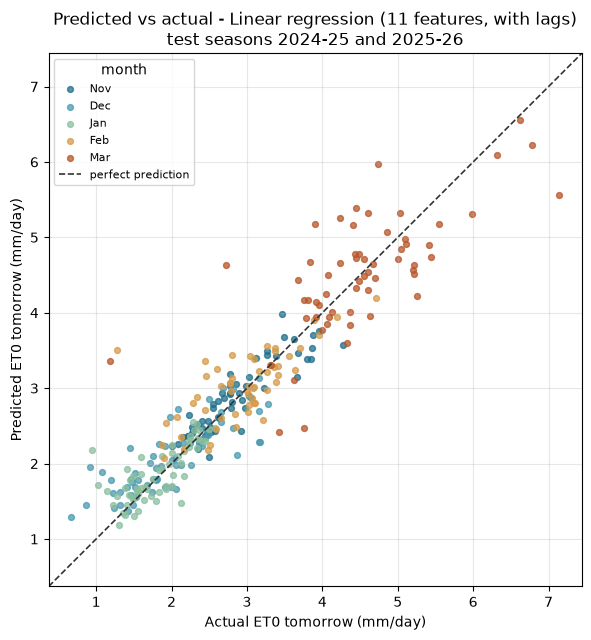

Mean signed error by how high the actual ET0 was (+ = over-predicted):
               count    mean
et0_tomorrow                
lowest third     101  0.1946
middle third      99  0.0696
highest third    100 -0.1150


In [24]:
fig, ax = plt.subplots(figsize=(6.5, 6.5))

# Colour by month so we can see whether a particular part of the season sits off the line.
for month, colour in zip(MONTH_ORDER, ["#1f6f8b", "#4a9ab0", "#8bbf9f", "#d59b4a", "#b8562a"]):
    block = fa[fa["month"] == month]
    ax.scatter(block[TARGET], block[BEST_COL], s=18, alpha=0.75, color=colour, label=month)

# The 1:1 line of perfect prediction, spanning the full range of both axes.
lo = min(fa[TARGET].min(), fa[BEST_COL].min()) - 0.3
hi = max(fa[TARGET].max(), fa[BEST_COL].max()) + 0.3
ax.plot([lo, hi], [lo, hi], "--", color="#333333", linewidth=1.2, label="perfect prediction")

ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_aspect("equal")                      # equal axes, so the diagonal really is 45 degrees
ax.set_xlabel("Actual ET0 tomorrow (mm/day)")
ax.set_ylabel("Predicted ET0 tomorrow (mm/day)")
ax.set_title(f"Predicted vs actual - {BEST_NAME}\ntest seasons 2024-25 and 2025-26")
ax.legend(title="month", fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Quantify the bend rather than only eyeballing it: split the test days into thirds by actual
# ET0 and report the mean signed error in each. A model that squashes extremes will
# over-predict the low third and under-predict the high third.
thirds = pd.qcut(fa[TARGET], 3, labels=["lowest third", "middle third", "highest third"])
print("Mean signed error by how high the actual ET0 was (+ = over-predicted):")
print(fa.groupby(thirds, observed=True)["error"].agg(["count", "mean"]).round(4).to_string())

## Cell 27 - One test season in detail: 2025-26

The harder of the two test seasons. Actual ET0, persistence, and the best model, drawn together
so the disagreements are visible day by day.

This is the plot to look at when asking *why* the model only gains a few percent over
persistence: the two lines sit almost on top of each other for most of the season.

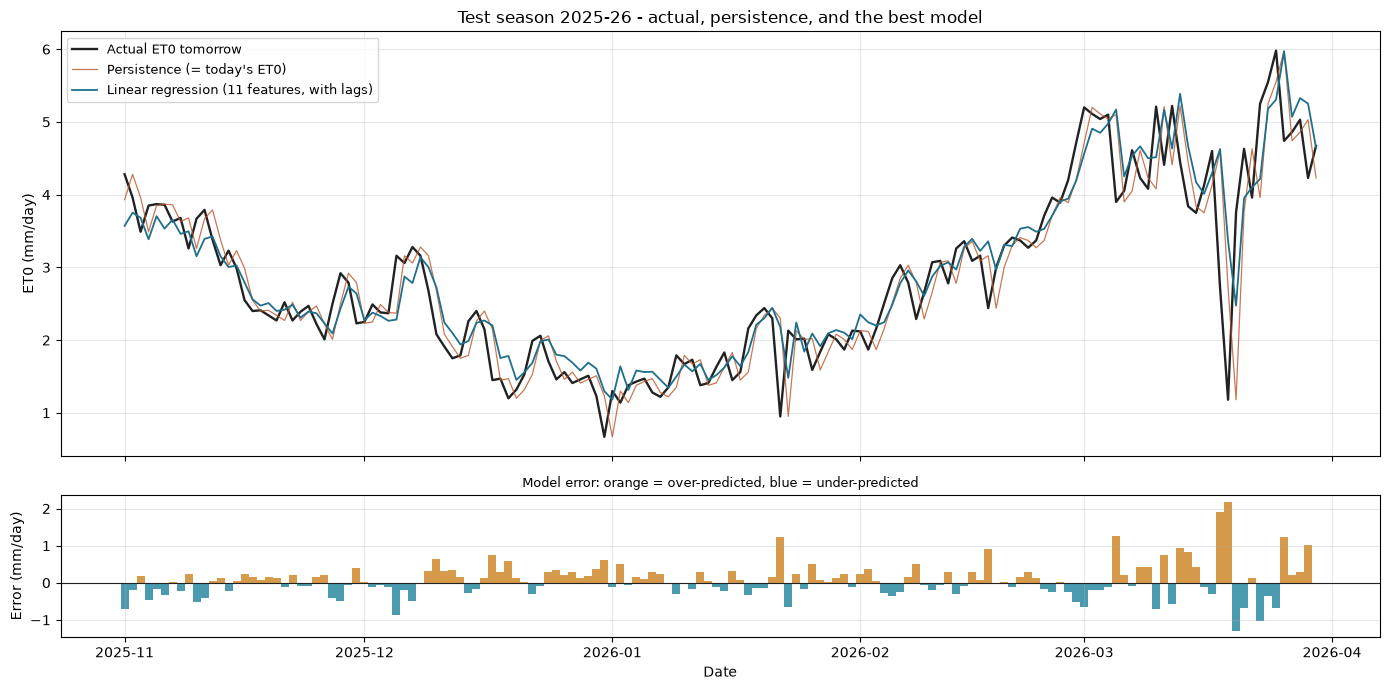

2025-26 MAE, persistence : 0.3443 mm/day
2025-26 MAE, best model  : 0.3228 mm/day


In [25]:
PLOT_SEASON_B = "2025-26"
one = fa[fa["season"] == PLOT_SEASON_B]

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1]})

# ---- Top panel: the three series --------------------------------------------------------
ax.plot(one["date"], one[TARGET], color="#222222", linewidth=1.7, label="Actual ET0 tomorrow")
ax.plot(one["date"], one["pred_persistence"], color="#b8562a", linewidth=0.9, alpha=0.8,
        label="Persistence (= today's ET0)")
ax.plot(one["date"], one[BEST_COL], color="#1f6f8b", linewidth=1.3, label=BEST_NAME)
ax.set_ylabel("ET0 (mm/day)")
ax.set_title(f"Test season {PLOT_SEASON_B} - actual, persistence, and the best model")
ax.legend(loc="upper left", fontsize=9)
ax.grid(alpha=0.3)

# ---- Bottom panel: the model's signed error, so bad days stand out ----------------------
# Bars rather than a line, because each day's error is its own event, not a continuous quantity.
colours = np.where(one["error"] > 0, "#d59b4a", "#4a9ab0")   # orange = over, blue = under
ax2.bar(one["date"], one["error"], color=colours, width=1.0)
ax2.axhline(0, color="#222222", linewidth=0.8)
ax2.set_ylabel("Error (mm/day)")
ax2.set_xlabel("Date")
ax2.set_title("Model error: orange = over-predicted, blue = under-predicted", fontsize=9)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

for col, label in [("pred_persistence", "persistence"), (BEST_COL, "best model")]:
    print(f"{PLOT_SEASON_B} MAE, {label:<12}: {np.mean(np.abs(one[col] - one[TARGET])):.4f} mm/day")

## Cell 28 - MAE by month

Wheat season weather is not uniform. November is the tail of the warm season, December and
January are the cold core, and March swings into pre-monsoon heat with much higher and more
variable evaporative demand.

We expect error to grow in March simply because the quantity being predicted is larger and
jumpier there. The interesting question is not where the raw error is biggest, but **whether
the model's advantage over persistence holds up across the whole season** or comes from one
easy stretch.

MAE BY MONTH  (mm/day)   best model = Linear regression (11 features, with lags)
       days  actual_mean  actual_std  MAE_persistence  MAE_best  model_minus_pers  skill_%
month                                                                                     
Nov      60       2.8385      0.5486           0.2102    0.1965           -0.0136   6.4879
Dec      62       1.9874      0.6339           0.2968    0.2838           -0.0130   4.3680
Jan      62       1.8161      0.4058           0.2323    0.1877           -0.0445  19.1708
Feb      56       2.9380      0.6110           0.3498    0.3151           -0.0347   9.9231
Mar      60       4.5265      0.9414           0.5318    0.5119           -0.0199   3.7424

Negative model_minus_pers means the model beat persistence that month.
The model beat persistence in every month.


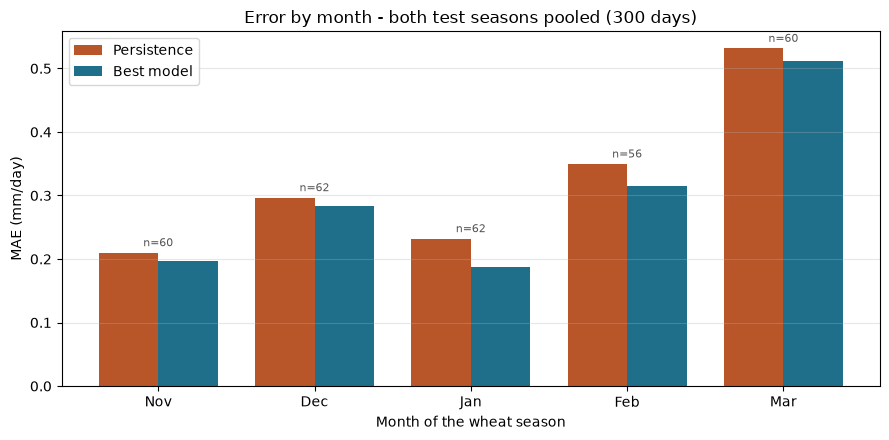

In [26]:
# Mean absolute error per month, for persistence and for the best model side by side.
by_month = fa.groupby("month", observed=True).agg(
    days=("abs_error", "size"),
    actual_mean=(TARGET, "mean"),
    actual_std=(TARGET, "std"),
    MAE_persistence=("abs_error_pers", "mean"),
    MAE_best=("abs_error", "mean"),
)
by_month["model_minus_pers"] = by_month["MAE_best"] - by_month["MAE_persistence"]
# Skill per month, same formula as the overall table.
by_month["skill_%"] = (by_month["MAE_persistence"] - by_month["MAE_best"]) / by_month["MAE_persistence"] * 100

print("=" * 88)
print(f"MAE BY MONTH  (mm/day)   best model = {BEST_NAME}")
print("=" * 88)
print(by_month.round(4).to_string())
print("\nNegative model_minus_pers means the model beat persistence that month.")
losing = by_month[by_month["skill_%"] < 0]
if len(losing):
    print(f"Months where the model LOST to persistence: {list(losing.index)}")
else:
    print("The model beat persistence in every month.")

# ---- Grouped bar chart -------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(by_month))      # one slot per month
width = 0.38                      # two bars per slot, so each is slightly under half

ax.bar(x - width/2, by_month["MAE_persistence"], width, color="#b8562a", label="Persistence")
ax.bar(x + width/2, by_month["MAE_best"],        width, color="#1f6f8b", label="Best model")

ax.set_xticks(x)
ax.set_xticklabels(by_month.index)
ax.set_xlabel("Month of the wheat season")
ax.set_ylabel("MAE (mm/day)")
ax.set_title("Error by month - both test seasons pooled (300 days)")
ax.legend()
ax.grid(alpha=0.3, axis="y")

# Print the day count on each pair, so a month with few days cannot be over-read.
for i, (_, row) in enumerate(by_month.iterrows()):
    ax.text(i, max(row["MAE_persistence"], row["MAE_best"]) + 0.01,
            f"n={int(row['days'])}", ha="center", fontsize=8, color="#555555")

plt.tight_layout()
plt.show()

## Cell 29 - Rainy days against dry days

A day is counted as **rainy** when **tomorrow's** rainfall exceeded 1 mm - that is, when the day
we were trying to predict turned out to be wet.

To be explicit about what this is and is not: `precip_tomorrow` is future information and was
never given to any model. We are using it only to sort our errors after the fact, which is a
legitimate question about where the tool breaks down. No model saw it.

Rain is the obvious candidate for the model's worst failures. A passing weather system brings
cloud, humidity and wind changes that cut evaporative demand sharply, and nothing in today's
observations announces that a front will arrive tomorrow. We expect error to be clearly worse
on these days.

In [27]:
RAIN_THRESHOLD = 1.0      # mm; below this is drizzle that barely affects the water balance

# Classify each test day by whether TOMORROW turned out to be wet. Diagnostic use only.
fa["tomorrow_rainy"] = fa["precip_tomorrow"] > RAIN_THRESHOLD

by_rain = fa.groupby("tomorrow_rainy", observed=True).agg(
    days=("abs_error", "size"),
    actual_mean=(TARGET, "mean"),
    MAE_persistence=("abs_error_pers", "mean"),
    MAE_best=("abs_error", "mean"),
    mean_signed_error=("error", "mean"),
)
by_rain.index = ["Dry (tomorrow <= 1 mm)", "Rainy (tomorrow > 1 mm)"]
by_rain["skill_%"] = (by_rain["MAE_persistence"] - by_rain["MAE_best"]) / by_rain["MAE_persistence"] * 100

print("=" * 88)
print(f"ERROR ON RAINY vs DRY DAYS   (rain measured on the PREDICTED day, threshold {RAIN_THRESHOLD} mm)")
print("=" * 88)
print(by_rain.round(4).to_string())

n_rainy = int(fa["tomorrow_rainy"].sum())
n_dry = len(fa) - n_rainy
print(f"\nDay counts: {n_dry} dry, {n_rainy} rainy, out of {len(fa)} test days "
      f"({100 * n_rainy / len(fa):.1f}% rainy)")

ratio = by_rain.loc["Rainy (tomorrow > 1 mm)", "MAE_best"] / by_rain.loc["Dry (tomorrow <= 1 mm)", "MAE_best"]
print(f"\nThe model's MAE on rainy days is {ratio:.2f}x its MAE on dry days.")
print(f"Mean signed error, dry:   {by_rain.loc['Dry (tomorrow <= 1 mm)', 'mean_signed_error']:+.4f} mm/day")
print(f"Mean signed error, rainy: {by_rain.loc['Rainy (tomorrow > 1 mm)', 'mean_signed_error']:+.4f} mm/day")
print("(+ = over-predicted water loss, which for an irrigation tool means advising too much water)")

# With only a few dozen rainy days, the rainy-day average is noisy. Show the spread so we do
# not over-interpret a small sample.
print(f"\nRainy-day absolute errors: median "
      f"{fa.loc[fa['tomorrow_rainy'], 'abs_error'].median():.4f}, "
      f"max {fa.loc[fa['tomorrow_rainy'], 'abs_error'].max():.4f} mm/day")

ERROR ON RAINY vs DRY DAYS   (rain measured on the PREDICTED day, threshold 1.0 mm)
                         days  actual_mean  MAE_persistence  MAE_best  mean_signed_error  skill_%
Dry (tomorrow <= 1 mm)    271       2.8644           0.2890    0.2603            -0.0037   9.9270
Rainy (tomorrow > 1 mm)    29       2.2755           0.6414    0.6501             0.5537  -1.3618

Day counts: 271 dry, 29 rainy, out of 300 test days (9.7% rainy)

The model's MAE on rainy days is 2.50x its MAE on dry days.
Mean signed error, dry:   -0.0037 mm/day
Mean signed error, rainy: +0.5537 mm/day
(+ = over-predicted water loss, which for an irrigation tool means advising too much water)

Rainy-day absolute errors: median 0.5211, max 2.2230 mm/day


## Cell 30 - The 10 worst test days

The days where the model was furthest from the truth. For each one we show today's ET0 (what
the model mostly leaned on), the prediction, the actual value, the signed error, and the
rainfall both today and tomorrow.

Reading across the rainfall columns is the point of this table: if the worst days are mostly
days where tomorrow was wet, the failure mode is "the model cannot see weather systems
arriving", which is a limitation of the inputs rather than of the model choice.

In [28]:
worst = fa.nlargest(10, "abs_error")[[
    "date", "season", "month", "et0_fao_evapotranspiration", BEST_COL, TARGET,
    "error", "precipitation_sum", "precip_tomorrow",
]].copy()

# Readable column names for the printed table.
worst = worst.rename(columns={
    "et0_fao_evapotranspiration": "et0_today",
    BEST_COL:                     "predicted",
    TARGET:                       "actual",
    "precipitation_sum":          "rain_today",
    "precip_tomorrow":            "rain_tomorrow",
})
worst["date"] = worst["date"].dt.date

print("=" * 100)
print(f"THE 10 WORST TEST DAYS  -  {BEST_NAME}")
print("=" * 100)
print(worst.round(3).to_string(index=False))

# Summarise the pattern numerically so the markdown below is not just an impression.
print("\n" + "-" * 100)
n_wet_tomorrow = int((worst["rain_tomorrow"] > RAIN_THRESHOLD).sum())
n_over  = int((worst["error"] > 0).sum())
print(f"Of these 10 worst days:")
print(f"   {n_wet_tomorrow} had rain above {RAIN_THRESHOLD} mm on the day being predicted")
print(f"   {n_over} were over-predictions (model advised more water loss than happened)")
print(f"   {10 - n_over} were under-predictions")
print(f"   months involved: {dict(worst['month'].value_counts().sort_index())}")
print(f"\nWorst single error: {worst['error'].abs().max():.3f} mm/day, against a test-set "
      f"mean actual of {fa[TARGET].mean():.3f} mm/day")
print(f"These 10 days are {10/len(fa)*100:.1f}% of the test set but contribute "
      f"{worst['error'].abs().sum() / fa['abs_error'].sum() * 100:.1f}% of all absolute error.")

THE 10 WORST TEST DAYS  -  Linear regression (11 features, with lags)
      date  season month  et0_today  predicted  actual  error  rain_today  rain_tomorrow
2025-02-26 2024-25   Feb       3.08      3.503    1.28  2.223         0.9            2.2
2026-03-19 2025-26   Mar       2.72      3.363    1.18  2.183        12.1            5.8
2026-03-18 2025-26   Mar       4.60      4.627    2.72  1.907         0.0           12.1
2025-03-27 2024-25   Mar       5.44      5.564    7.14 -1.576         0.0            0.0
2026-03-20 2025-26   Mar       1.18      2.474    3.76 -1.286         5.8            0.1
2026-03-05 2025-26   Mar       5.10      5.171    3.90  1.271         0.0            0.0
2026-03-26 2025-26   Mar       5.98      5.968    4.74  1.228         0.0            7.4
2026-01-22 2025-26   Jan       2.30      2.178    0.95  1.228         0.0           40.2
2026-03-23 2025-26   Mar       3.96      4.216    5.25 -1.034         1.4            0.0
2024-12-22 2024-25   Dec       1.86     

## Cell 31 - Where the model fails, in plain words

Best model: **linear regression on 11 features** (the 8 from Step 3 plus the three lag features),
test MAE **0.2980 mm/day**, **+7.76%** skill over persistence. Everything below describes that
model on the 300 held-out days. Numbers are from Cells 25-30; where we offer a reason rather
than a measurement, it is **marked as a guess**.

### 1. Rain is the dominant failure mode, and it is where the model stops being useful

This is the clearest finding in the notebook.

| | Days | MAE (mm/day) | Mean signed error | Skill vs persistence |
|---|---|---|---|---|
| Dry (tomorrow <= 1 mm) | 271 | 0.2603 | -0.0037 | **+9.93%** |
| Rainy (tomorrow > 1 mm) | 29 | 0.6501 | **+0.5537** | **-1.36%** |

Three things to read off this:

- Error on rainy days is **2.5 times** the error on dry days.
- On rainy days the model has **no skill at all** - it is 1.36% *worse* than persistence. Our
  headline +7.76% is earned entirely on dry days.
- The whole of the model's bias comes from rainy days. On dry days the mean signed error is
  -0.004 mm/day, essentially unbiased. On rainy days it is **+0.55 mm/day**, strongly
  over-predicting.

**Why (this part is measurement, not guess):** nothing in the feature set can see a weather
system that has not arrived yet. Every input is today's observation at one point, so when a
front moves in overnight, bringing cloud, humidity and a collapse in evaporative demand, the
model is still predicting from yesterday's clear-sky conditions. The single worst day,
26 Feb 2025, is exactly this: today's ET0 was 3.08, the model predicted 3.50, and the actual
came in at 1.28 after 2.2 mm of rain - an error of +2.22 mm/day.

**For the irrigation decision this is the wrong direction to fail.** Over-predicting water loss
on a day it is about to rain means advising irrigation that the rain would have supplied -
wasted water, wasted pumping, and on the worst day roughly double the true requirement.

### 2. The mirror image: the day *after* rain

Six of the ten worst days had rain on the predicted day, and seven of the ten were
over-predictions. But the three under-predictions tell the opposite story. On 20 March 2026,
5.8 mm had fallen the previous day, today's ET0 was suppressed to 1.18, the model predicted 2.47,
and the actual bounced back to 3.76 - an under-prediction of 1.29 mm/day.

So the model fails at **both edges of a rain event**: it over-predicts going into one, because
it cannot see it coming, and under-predicts coming out of one, because it is anchored to an
artificially low value. Under-predicting means advising too little water on a hot recovery day,
which risks crop stress - the more damaging error of the two.

**Guess:** the lag features (`et0_yesterday`, `et0_3day_mean`) probably make the recovery case
slightly worse, because they weight the model further towards the suppressed recent past. We have
not tested this, so it is a guess. Testing it would mean scoring the 8-feature and 11-feature
models on post-rain days separately, which is a clean next experiment.

### 3. The errors are concentrated in very few days

The median absolute error is **0.207 mm/day** but the mean is **0.298** - the average is dragged
up by a minority of bad days. Concretely: the 10 worst days are **3.3%** of the test set and
contribute **16.7%** of all absolute error.

This is good news for how we describe the tool. On a typical day it is accurate to about 0.2
mm/day. It is not uniformly mediocre; it is mostly reliable with occasional large misses, and
those misses are predictable in kind (rain) even if not in timing.

### 4. March is the hardest month, but mostly because March is harder

| Month | Days | Actual mean | Actual std | MAE persistence | MAE model | Skill |
|---|---|---|---|---|---|---|
| Nov | 60 | 2.84 | 0.55 | 0.2102 | 0.1965 | +6.49% |
| Dec | 62 | 1.99 | 0.63 | 0.2968 | 0.2838 | +4.37% |
| Jan | 62 | 1.82 | 0.41 | 0.2323 | 0.1877 | **+19.17%** |
| Feb | 56 | 2.94 | 0.61 | 0.3498 | 0.3151 | +9.92% |
| Mar | 60 | 4.53 | 0.94 | 0.5318 | 0.5119 | +3.74% |

March has the worst MAE (0.512), roughly 2.7x January's. But March also has the highest mean
ET0 (4.53) and the widest spread (std 0.94), so the quantity itself is bigger and jumpier. As a
share of the mean, March error is about 11% while December error is about 14% - so in relative
terms March is not actually the worst month.

The more useful observation is that **skill is lowest in March (+3.74%) and highest in January
(+19.17%)**. The model adds least where the stakes are highest: March is when wheat is filling
grain and when irrigation decisions matter most, and that is precisely where it barely beats
copying today's number forward. Seven of the ten worst days are in March.

**Guess:** January is probably the easiest month because the winter air mass over the region is
stable and ET0 varies least (std 0.41, the lowest of the five months), so the seasonal trend the
model learned does most of the work. March is probably hardest because pre-monsoon heating is
erratic and punctuated by rain events. Both are plausible readings of the std column, not things
we have demonstrated.

### 5. The model squashes the extremes

Splitting the test days into thirds by actual ET0:

| Actual ET0 | Days | Mean signed error |
|---|---|---|
| Lowest third | 101 | **+0.195** (over-predicts) |
| Middle third | 99 | +0.070 |
| Highest third | 100 | **-0.115** (under-predicts) |

The model pulls low days up and high days down. This is the expected behaviour of any
least-squares fit - it is trained to minimise average squared error, and hedging towards the
middle is how you do that - so it is a property of the method, not a bug. The practical effect
is that on the highest-demand days, exactly the ones where irrigation is most needed, the model
systematically under-states the requirement by about 0.12 mm/day.

### 6. The random forest overfitted and we did not keep it

Worth reporting as a negative result. The random forest scored train MAE **0.2346** against test
MAE **0.3090** - a gap of +0.074, while the linear model's gap was -0.047 (it scored *better* on
test than train). The forest memorised the six training seasons and generalised worse than a
straight line, finishing below both linear models and only +4.35% over persistence.

With 900 training rows, 11 heavily overlapping features and a target dominated by one of them,
there was not much non-linear structure for 300 trees to find. We report the forest as tried and
rejected, and keep the linear model.

### Honest summary of what we would tell a farmer

The tool predicts tomorrow's water demand to about **0.2 mm/day on a normal dry day**, which is
a real improvement on assuming tomorrow equals today. **It should not be trusted when rain is
possible**: on the 10% of days when rain arrived it had no advantage over persistence at all and
over-predicted demand by an average of 0.55 mm/day. The fix is not a better model on these
inputs - it is adding a rainfall forecast, which is information none of our current features
contain. That is the single highest-value next step and it is a data problem, not a modelling one.

---

# Step 6 - Does a rain forecast fix the rainy-day failure?

Step 4 found the model's one serious weakness. On the 29 test days where rain arrived, it had
**no skill at all** (-1.36% against persistence) and over-predicted water demand by an average
of +0.55 mm/day. Our explanation was that none of the 11 features contains any information
about tomorrow's rain.

That is a hypothesis, and it is testable. We test it in two stages:

- **Part A, the oracle.** Give the model tomorrow's *actual* rainfall. This cheats - it uses the
  future - so it is not a usable model. It tells us the **upper bound**: the most that perfect
  rain information could possibly buy us. If the oracle barely helps, our explanation was wrong
  and no forecast will save us.
- **Part B, the real forecast.** Download the rain forecast that was genuinely available the day
  before, from Open-Meteo's archive of past forecast runs, and see how much of the oracle's gain
  a real, imperfect forecast actually captures.

Part B also lets us answer the question a judge is most likely to ask: **how do we compare with
the weather service's own ET0 forecast?**

## Cell 32 - A small helper for the dry / rainy breakdown

Every table in this step reports the same three numbers - MAE on all days, on dry days, and on
rainy days - plus skill against persistence. One function so the arithmetic is identical
everywhere and we only have to explain it once.

In [29]:
def breakdown(frame, pred_col, truth_col, rainy_col, label, pers_col="pred_persistence"):
    # MAE for one model on all days / dry days / rainy days, plus skill vs persistence
    # computed on the SAME subset of days each time (so the comparison is like-for-like).
    out = {"model": label}
    for subset_name, mask in [("all", pd.Series(True, index=frame.index)),
                              ("dry", ~frame[rainy_col]),
                              ("rainy", frame[rainy_col])]:
        block = frame[mask]
        if len(block) == 0:                       # guard: never divide by an empty subset
            out[f"MAE_{subset_name}"] = np.nan
            out[f"skill_{subset_name}_%"] = np.nan
            continue
        mae  = np.mean(np.abs(block[pred_col] - block[truth_col]))
        # Persistence scored on the SAME days, so skill is a fair ratio.
        mae_p = np.mean(np.abs(block[pers_col] - block[truth_col]))
        out[f"n_{subset_name}"] = len(block)
        out[f"MAE_{subset_name}"] = mae
        out[f"skill_{subset_name}_%"] = (mae_p - mae) / mae_p * 100
    return out

print("breakdown() ready: reports MAE and skill-vs-persistence on all, dry and rainy days.")

breakdown() ready: reports MAE and skill-vs-persistence on all, dry and rainy days.


## Cell 33 - PART A: the oracle model (uses the future - NOT USABLE)

We add one feature: `rain_tomorrow_actual`, tomorrow's real measured rainfall, built with
`shift(-1)` on the full continuous daily series so it is genuinely the next calendar day.

**This model could never be deployed.** On the evening a farmer needs the answer, tomorrow's
rainfall has not happened yet, so this number does not exist. We build it anyway because it
answers a question nothing else can: *if we had a perfect rain forecast, how much better could
we possibly do?* Everything it scores is an upper bound, and it is labelled
**"ORACLE, NOT USABLE"** everywhere it appears so no later reader can mistake it for a result.

In [30]:
# Tomorrow's ACTUAL rainfall. Same shift(-1) on the full continuous series as the target itself,
# so this is the true next calendar day (series continuity was asserted in Cell 7).
lagged["rain_tomorrow_actual"] = lagged["precipitation_sum"].shift(-1)

ORACLE_NAME = "ORACLE, NOT USABLE: linear + tomorrow's actual rain"

# Rebuild the season-filtered frame so it carries the new column, using the identical filter
# from Cell 22 - nothing about the split changes, only the feature list.
keep_oracle = (lagged["season"].notna()
               & (lagged["season"] == lagged["season_tomorrow"])
               & lagged[LAG_FEATURES].notna().all(axis=1)
               & lagged["rain_tomorrow_actual"].notna())
data_or = lagged[keep_oracle].copy()
data_or["day_of_season"] = (
    data_or["date"] - pd.to_datetime(data_or["season"].str[:4] + "-11-01")
).dt.days

train_or = data_or[data_or["season"].isin(TRAIN_SEASONS)].copy()
test_or  = data_or[data_or["season"].isin(TEST_SEASONS)].copy()

# The split must be byte-identical in size to Step 4, or the comparison is not like-for-like.
assert len(train_or) == len(train_lag) and len(test_or) == len(test_lag), (
    f"Split changed: train {len(train_or)} vs {len(train_lag)}, test {len(test_or)} vs {len(test_lag)}")
assert train_or["date"].max() < test_or["date"].min(), "Time leakage"

FEATURES_ORACLE = FEATURES_LAG + ["rain_tomorrow_actual"]      # 12 features

model_oracle = Pipeline([("scaler", StandardScaler()), ("linreg", LinearRegression())])
model_oracle.fit(train_or[FEATURES_ORACLE], train_or[TARGET])

# ---- Build the Part A comparison frame ------------------------------------------------
pa = test_or[["date", "season", TARGET, "precip_tomorrow",
              "et0_fao_evapotranspiration"]].copy()
pa["pred_persistence"] = pa["et0_fao_evapotranspiration"]          # the reference, as always
pa["pred_oracle"]      = model_oracle.predict(test_or[FEATURES_ORACLE])
# Carry across the Step 4 best model's predictions, matched on date.
pa = pa.merge(test_lag[["date", "pred_linreg_lags"]], on="date", how="inner")
pa["tomorrow_rainy"] = pa["precip_tomorrow"] > RAIN_THRESHOLD
assert len(pa) == 300, f"expected 300 rows, got {len(pa)}"

# ---- Score both, side by side ----------------------------------------------------------
part_a = pd.DataFrame([
    breakdown(pa, "pred_persistence",  TARGET, "tomorrow_rainy", "Baseline A: persistence"),
    breakdown(pa, "pred_linreg_lags",  TARGET, "tomorrow_rainy", "Our model (11 feat, no rain info)"),
    breakdown(pa, "pred_oracle",       TARGET, "tomorrow_rainy", ORACLE_NAME),
])
cols = ["model", "n_all", "MAE_all", "skill_all_%", "MAE_dry", "skill_dry_%", "MAE_rainy", "skill_rainy_%"]

print("=" * 108)
print("PART A - ORACLE UPPER BOUND   (test seasons 2024-25 + 2025-26, 300 days)")
print("=" * 108)
print(part_a[cols].round(4).to_string(index=False))

# The headline: how much of the rainy-day failure does perfect rain knowledge remove?
mae_r_no   = float(part_a.loc[part_a["model"].str.startswith("Our model"), "MAE_rainy"].iloc[0])
mae_r_or   = float(part_a.loc[part_a["model"] == ORACLE_NAME, "MAE_rainy"].iloc[0])
mae_a_no   = float(part_a.loc[part_a["model"].str.startswith("Our model"), "MAE_all"].iloc[0])
mae_a_or   = float(part_a.loc[part_a["model"] == ORACLE_NAME, "MAE_all"].iloc[0])

print(f"\nRainy-day MAE: {mae_r_no:.4f} -> {mae_r_or:.4f} mm/day "
      f"({(mae_r_no - mae_r_or) / mae_r_no * 100:+.1f}% change)")
print(f"All-day MAE:   {mae_a_no:.4f} -> {mae_a_or:.4f} mm/day "
      f"({(mae_a_no - mae_a_or) / mae_a_no * 100:+.1f}% change)")

# Also show what the oracle did to the rainy-day bias, which was the real problem for a farmer.
print(f"\nMean signed error on rainy days (+ = over-predicts water demand):")
rainy = pa[pa["tomorrow_rainy"]]
print(f"   our model (no rain info): {(rainy['pred_linreg_lags'] - rainy[TARGET]).mean():+.4f} mm/day")
print(f"   {ORACLE_NAME}: {(rainy['pred_oracle'] - rainy[TARGET]).mean():+.4f} mm/day")

# The coefficient on the new feature, to confirm it learned the physically sensible direction.
coef_rain = model_oracle.named_steps["linreg"].coef_[FEATURES_ORACLE.index("rain_tomorrow_actual")]
print(f"\nCoefficient on rain_tomorrow_actual: {coef_rain:+.4f} mm/day per 1 std of rainfall")
print("(negative is what physics expects: rain tomorrow means lower evaporative demand tomorrow)")

PART A - ORACLE UPPER BOUND   (test seasons 2024-25 + 2025-26, 300 days)
                                              model  n_all  MAE_all  skill_all_%  MAE_dry  skill_dry_%  MAE_rainy  skill_rainy_%
                            Baseline A: persistence    300   0.3230       0.0000   0.2890        0.000     0.6414         0.0000
                  Our model (11 feat, no rain info)    300   0.2980       7.7604   0.2603        9.927     0.6501        -1.3618
ORACLE, NOT USABLE: linear + tomorrow's actual rain    300   0.2943       8.8911   0.2619        9.368     0.5972         6.8829

Rainy-day MAE: 0.6501 -> 0.5972 mm/day (+8.1% change)
All-day MAE:   0.2980 -> 0.2943 mm/day (+1.2% change)

Mean signed error on rainy days (+ = over-predicts water demand):
   our model (no rain info): +0.5537 mm/day
   ORACLE, NOT USABLE: linear + tomorrow's actual rain: +0.3504 mm/day

Coefficient on rain_tomorrow_actual: -0.2192 mm/day per 1 std of rainfall
(negative is what physics expects: rain tomor

## Cell 34 - What the oracle does and does not tell us

**The oracle is not a model we have. It is a measuring instrument.**

It is given tomorrow's actual rainfall, a number that does not exist at the moment the
prediction has to be made. Any score it achieves is therefore unreachable in practice. We are
not claiming this performance, and it must never be quoted as our result - that is why its
label carries **"ORACLE, NOT USABLE"** in every table it appears in.

What it legitimately tells us is the **ceiling**. It answers: "suppose rain forecasting were
solved perfectly - how much of our rainy-day failure would disappear?" That turns our Step 4
explanation from a story into a measurable quantity:

- If the oracle removes most of the rainy-day error, then our diagnosis was right: the model
  was failing because of missing information, not because a linear model is the wrong tool. A
  real forecast then has something to aim at, and Part B measures how much of it we can claim.
- If the oracle barely helps, our diagnosis was wrong. The rainy-day failure would have to come
  from somewhere else - perhaps rain days are simply more chaotic in ways rainfall alone does
  not capture - and chasing a rain forecast would be wasted effort.

The gap between the oracle and the real-forecast model in Part B is also informative on its own:
it measures how much we lose purely to **forecast error**, as opposed to model error.

---

## Cell 35 - PART B: download the real day-ahead forecast

Open-Meteo's **Previous Runs API** archives what the forecast models actually said on past
dates, which is what we need. A normal weather API gives today's forecast; this one answers
"what did yesterday's run predict for today?", so we can score a real forecast against what
then happened.

The variables end in `_previous_day1`, meaning **the value from the model run one day earlier**.
So `precipitation_previous_day1` on 5 March is the rainfall for 5 March as forecast on 4 March.
That is exactly a genuine day-ahead forecast, with no future information in it.

Both variables are hourly, so we sum each day's 24 hours to get daily totals (precipitation in
mm, ET0 in mm). We require all 24 hours to be present: a day with missing hours would produce
an under-counted total that looks like a real low value, which is the kind of silent error that
would quietly flatter or wreck the comparison.

In [31]:
PREV_URL = "https://previous-runs-api.open-meteo.com/v1/forecast"

FC_VARS = [
    "precipitation_previous_day1",                # rain for this day, as forecast 1 day earlier
    "et0_fao_evapotranspiration_previous_day1",   # ET0 for this day, as forecast 1 day earlier
]

resp = requests.get(PREV_URL, params={
    "latitude":  LAT,
    "longitude": LON,
    "timezone": "Asia/Kolkata",      # same timezone as the historical data, so days line up
    "hourly":   ",".join(FC_VARS),
    "start_date": "2024-01-01",
    "end_date":   "2026-03-31",
}, timeout=180)

payload = resp.json()
if resp.status_code != 200:
    # Print the API's real message and stop - we do not substitute anything.
    raise RuntimeError(f"Previous Runs API HTTP {resp.status_code}: {payload.get('reason', payload)}")

returned = list(payload["hourly"].keys())
print("Variables returned by the API:")
for v in returned:
    print("   ", v)
rejected = [v for v in FC_VARS if v not in returned]
if rejected:
    print(f"\nNOT RETURNED (rejected by the API): {rejected}")
else:
    print("\nBoth requested variables were accepted.")

hourly = pd.DataFrame(payload["hourly"])
hourly["time"] = pd.to_datetime(hourly["time"])

print(f"\nRequested hourly range: 2024-01-01 to 2026-03-31")
print(f"ACTUALLY returned:      {hourly['time'].min()} to {hourly['time'].max()}")
print(f"Hours returned: {len(hourly)}")
for v in FC_VARS:
    if v in hourly:
        print(f"   {v}: {int(hourly[v].isna().sum())} null hours of {len(hourly)}")

# ---- Sum hourly -> daily -------------------------------------------------------------
hourly["date"] = hourly["time"].dt.normalize()     # strip the time, keep the calendar day

# Count real (non-null) hours per day alongside the sums, so we can reject partial days.
fc_daily = hourly.groupby("date").agg(
    rain_fc_today=("precipitation_previous_day1", "sum"),
    et0_fc_today=("et0_fao_evapotranspiration_previous_day1", "sum"),
    hours=("time", "size"),
    rain_hours_ok=("precipitation_previous_day1", "count"),   # .count() ignores NaN
    et0_hours_ok=("et0_fao_evapotranspiration_previous_day1", "count"),
)

# A day is only usable if all 24 hours of BOTH variables are present. Otherwise NaN - we do
# not scale up a partial day, because that would be inventing data.
incomplete = (fc_daily["rain_hours_ok"] < 24) | (fc_daily["et0_hours_ok"] < 24)
fc_daily.loc[incomplete, ["rain_fc_today", "et0_fc_today"]] = np.nan

print("\n" + "=" * 78)
print("FORECAST DATA COVERAGE")
print("=" * 78)
print(f"Days returned:        {len(fc_daily)}")
print(f"First date:           {fc_daily.index.min().date()}")
print(f"Last date:            {fc_daily.index.max().date()}")
print(f"Incomplete days (dropped to NaN): {int(incomplete.sum())}")

# Missing calendar days: dates absent from the index entirely.
all_days = pd.date_range(fc_daily.index.min(), fc_daily.index.max(), freq="D")
absent = all_days.difference(fc_daily.index)
print(f"Calendar days absent from the response: {len(absent)}")

usable = fc_daily.dropna(subset=["rain_fc_today", "et0_fc_today"])
print(f"Usable days:          {len(usable)}  ({usable.index.min().date()} to {usable.index.max().date()})")
if int(incomplete.sum()):
    bad_dates = fc_daily.index[incomplete]
    print(f"\nThe incomplete days run {bad_dates.min().date()} to {bad_dates.max().date()}")
    print("- the archive simply has not back-filled its earliest days. They fall well before")
    print("the 2024-25 wheat season, so the experiment below is unaffected.")

# ---- Save, inside the project folder only ---------------------------------------------
FC_PATH = "data/karnal_forecast.csv"
fc_daily[["rain_fc_today", "et0_fc_today", "rain_hours_ok", "et0_hours_ok"]].to_csv(FC_PATH)
print(f"\nSaved {len(fc_daily)} daily rows to {FC_PATH}")
fc_daily.head(3)

Variables returned by the API:
    time
    precipitation_previous_day1
    et0_fao_evapotranspiration_previous_day1

Both requested variables were accepted.

Requested hourly range: 2024-01-01 to 2026-03-31
ACTUALLY returned:      2024-01-01 00:00:00 to 2026-03-31 23:00:00
Hours returned: 19704
   precipitation_previous_day1: 449 null hours of 19704
   et0_fao_evapotranspiration_previous_day1: 449 null hours of 19704

FORECAST DATA COVERAGE
Days returned:        821
First date:           2024-01-01
Last date:            2026-03-31
Incomplete days (dropped to NaN): 19
Calendar days absent from the response: 0
Usable days:          802  (2024-01-20 to 2026-03-31)

The incomplete days run 2024-01-01 to 2024-01-19
- the archive simply has not back-filled its earliest days. They fall well before
the 2024-25 wheat season, so the experiment below is unaffected.

Saved 821 daily rows to data/karnal_forecast.csv


,rain_fc_today,et0_fc_today,hours,rain_hours_ok,et0_hours_ok
date,,,,,
2024-01-01,NaN,NaN,24,0,0
2024-01-02,NaN,NaN,24,0,0
2024-01-03,NaN,NaN,24,0,0


## Cell 36 - Align the forecast to "tomorrow" and rebuild a reduced split

**The alignment is the one thing that must be right here, so it is worth saying slowly.**

`rain_fc_today` on date *D* is the rain forecast for *D*, issued on *D-1*. Our model stands on
day *t* and predicts day *t+1*. So the forecast it may legitimately use is the one for *t+1*
issued on *t* - which is `rain_fc_today` at date *t+1*. We get that with `shift(-1)` on the
continuous daily series, exactly as we built the target.

That means no leakage: the number attached to row *t* was published before day *t* ended.

**The reduced split.** The forecast archive starts in January 2024, so it cannot cover any of
our six training seasons. For this experiment only we train on **2024-25** and test on
**2025-26** - one season to learn from, one to be scored on. Both the with-rain and the
without-rain model are retrained on this same reduced split so the comparison is fair, and the
numbers in this part are **not** comparable with Parts A or Step 4, which trained on six seasons.

One training season is a small sample. We say so rather than presenting these numbers as firmly
as the earlier ones.

In [32]:
# Attach the forecast for each calendar day onto the full continuous series.
lagged["rain_fc_today"] = lagged["date"].map(fc_daily["rain_fc_today"])
lagged["et0_fc_today"]  = lagged["date"].map(fc_daily["et0_fc_today"])

# Shift to get TOMORROW's forecast, as published today (see markdown above).
lagged["rain_tomorrow_forecast"] = lagged["rain_fc_today"].shift(-1)
lagged["et0_tomorrow_forecast"]  = lagged["et0_fc_today"].shift(-1)

# ---- Same season filter, plus "we must have a forecast for tomorrow" -------------------
keep_fc = (lagged["season"].notna()
           & (lagged["season"] == lagged["season_tomorrow"])
           & lagged[LAG_FEATURES].notna().all(axis=1)
           & lagged["rain_tomorrow_forecast"].notna()
           & lagged["et0_tomorrow_forecast"].notna())
data_fc = lagged[keep_fc].copy()
data_fc["day_of_season"] = (
    data_fc["date"] - pd.to_datetime(data_fc["season"].str[:4] + "-11-01")
).dt.days

print("Rows with a usable day-ahead forecast, by season:")
print(data_fc.groupby("season").agg(rows=("date", "size"),
                                    first=("date", "min"), last=("date", "max")).to_string())

# ---- The reduced split: one season to train, one to test -------------------------------
FC_TRAIN_SEASONS = ["2024-25"]
FC_TEST_SEASONS  = ["2025-26"]

train_fc = data_fc[data_fc["season"].isin(FC_TRAIN_SEASONS)].copy()
test_fc  = data_fc[data_fc["season"].isin(FC_TEST_SEASONS)].copy()

print(f"\nREDUCED SPLIT for Part B only:")
print(f"   TRAIN {FC_TRAIN_SEASONS}: {len(train_fc)} rows  "
      f"{train_fc['date'].min().date()} to {train_fc['date'].max().date()}")
print(f"   TEST  {FC_TEST_SEASONS}: {len(test_fc)} rows  "
      f"{test_fc['date'].min().date()} to {test_fc['date'].max().date()}")
assert train_fc["date"].max() < test_fc["date"].min(), "Time leakage in the reduced split"
print("   No time leakage: all training days precede all test days.")
print(f"\nNOTE: {len(train_fc)} training rows is ONE season. Treat Part B as indicative.")

# ---- Sanity check the forecast itself, before using it ---------------------------------
# How good is the rain forecast? Compare it with what actually fell, on the test season.
fc_err = test_fc["rain_tomorrow_forecast"] - test_fc["precip_tomorrow"]
print(f"\nQuality of the day-ahead RAIN forecast on {FC_TEST_SEASONS[0]}:")
print(f"   MAE {np.mean(np.abs(fc_err)):.4f} mm   bias {fc_err.mean():+.4f} mm")
actual_wet = test_fc["precip_tomorrow"] > RAIN_THRESHOLD
fc_wet     = test_fc["rain_tomorrow_forecast"] > RAIN_THRESHOLD
print(f"   Days it actually rained (>{RAIN_THRESHOLD} mm): {int(actual_wet.sum())}")
print(f"   Days the forecast said rain:                 {int(fc_wet.sum())}")
print(f"   Correctly predicted rain (hits):             {int((actual_wet & fc_wet).sum())}")
print(f"   Missed rain (it rained, forecast said dry):  {int((actual_wet & ~fc_wet).sum())}")
print(f"   False alarms (forecast rain, stayed dry):    {int((~actual_wet & fc_wet).sum())}")

Rows with a usable day-ahead forecast, by season:
         rows      first       last
season                             
2023-24    72 2024-01-19 2024-03-30
2024-25   150 2024-11-01 2025-03-30
2025-26   150 2025-11-01 2026-03-30

REDUCED SPLIT for Part B only:
   TRAIN ['2024-25']: 150 rows  2024-11-01 to 2025-03-30
   TEST  ['2025-26']: 150 rows  2025-11-01 to 2026-03-30
   No time leakage: all training days precede all test days.

NOTE: 150 training rows is ONE season. Treat Part B as indicative.

Quality of the day-ahead RAIN forecast on 2025-26:
   MAE 0.4907 mm   bias -0.3347 mm
   Days it actually rained (>1.0 mm): 12
   Days the forecast said rain:                 12
   Correctly predicted rain (hits):             10
   Missed rain (it rained, forecast said dry):  2
   False alarms (forecast rain, stayed dry):    2


## Cell 37 - Train with and without the forecast, and score the weather service too

Three things get compared on the 2025-26 test season, plus persistence as the anchor:

1. **Our model without rain information** - the same 11 features, retrained on 2024-25 alone.
2. **Our model with the forecast rain** - the same 11 features plus `rain_tomorrow_forecast`.
   The only difference from (1) is that one column, so any change is attributable to it.
3. **The weather service's own ET0 forecast** - `et0_fao_evapotranspiration_previous_day1`
   for tomorrow, used directly as the prediction. No model of ours involved at all.

Point 3 is the professional benchmark and the most useful comparison in the notebook. Open-Meteo
runs a full numerical weather prediction model: real atmospheric physics, global observations,
supercomputers. We are a linear regression on one grid point. If their day-ahead ET0 forecast
beats us, that is the honest state of affairs and worth reporting plainly - and it would tell a
farmer that the better tool already exists and is free.

In [33]:
X_tr, y_tr = train_fc[FEATURES_LAG], train_fc[TARGET]
X_te, y_te = test_fc[FEATURES_LAG],  test_fc[TARGET]

FEATURES_FC = FEATURES_LAG + ["rain_tomorrow_forecast"]      # 12 features

# ---- 1. Without rain information (retrained on the reduced split) ----------------------
m_no_rain = Pipeline([("scaler", StandardScaler()), ("linreg", LinearRegression())])
m_no_rain.fit(X_tr, y_tr)

# ---- 2. With the real day-ahead rain forecast ------------------------------------------
m_with_fc = Pipeline([("scaler", StandardScaler()), ("linreg", LinearRegression())])
m_with_fc.fit(train_fc[FEATURES_FC], y_tr)

# ---- Build the Part B scoring frame ----------------------------------------------------
pb = test_fc[["date", "season", TARGET, "precip_tomorrow", "et0_fao_evapotranspiration",
              "et0_tomorrow_forecast"]].copy()
pb["pred_persistence"] = pb["et0_fao_evapotranspiration"]
pb["pred_no_rain"]     = m_no_rain.predict(X_te)
pb["pred_with_fc"]     = m_with_fc.predict(test_fc[FEATURES_FC])
# 3. The weather service's forecast used AS the prediction - nothing fitted by us.
pb["pred_service"]     = pb["et0_tomorrow_forecast"]
pb["tomorrow_rainy"]   = pb["precip_tomorrow"] > RAIN_THRESHOLD

print(f"Scoring on {FC_TEST_SEASONS[0]}: {len(pb)} days, "
      f"{int(pb['tomorrow_rainy'].sum())} of them rainy.\n")

part_b = pd.DataFrame([
    breakdown(pb, "pred_persistence", TARGET, "tomorrow_rainy", "Baseline A: persistence"),
    breakdown(pb, "pred_no_rain",     TARGET, "tomorrow_rainy", "Our model, no rain info"),
    breakdown(pb, "pred_with_fc",     TARGET, "tomorrow_rainy", "Our model + forecast rain"),
    breakdown(pb, "pred_service",     TARGET, "tomorrow_rainy", "Open-Meteo's own ET0 forecast"),
])
cols = ["model", "n_all", "MAE_all", "skill_all_%", "MAE_dry", "skill_dry_%", "MAE_rainy", "skill_rainy_%"]

print("=" * 108)
print(f"PART B - REAL DAY-AHEAD FORECAST   (train 2024-25, test 2025-26, {len(pb)} days)")
print("ONE training season - treat as indicative, not firm")
print("=" * 108)
print(part_b[cols].round(4).to_string(index=False))

# ---- Did the real forecast help? --------------------------------------------------------
g = lambda m, c: float(part_b.loc[part_b["model"] == m, c].iloc[0])
print("\n" + "-" * 78)
print("Effect of adding the real rain forecast (same features otherwise):")
for subset in ["all", "dry", "rainy"]:
    a, b = g("Our model, no rain info", f"MAE_{subset}"), g("Our model + forecast rain", f"MAE_{subset}")
    print(f"   {subset:<6} MAE {a:.4f} -> {b:.4f}  ({(a - b) / a * 100:+.1f}%)")

print("\nMean signed error on rainy days (+ = over-predicts water demand):")
r = pb[pb["tomorrow_rainy"]]
for col, label in [("pred_no_rain", "our model, no rain info"),
                   ("pred_with_fc", "our model + forecast rain"),
                   ("pred_service", "Open-Meteo's ET0 forecast")]:
    print(f"   {label:<28} {(r[col] - r[TARGET]).mean():+.4f} mm/day")

# ---- Us against the professionals --------------------------------------------------------
print("\n" + "-" * 78)
best_ours = min(g("Our model, no rain info", "MAE_all"), g("Our model + forecast rain", "MAE_all"))
svc = g("Open-Meteo's own ET0 forecast", "MAE_all")
print(f"Our best on this season:        {best_ours:.4f} mm/day")
print(f"Open-Meteo's own ET0 forecast:  {svc:.4f} mm/day")
if svc < best_ours:
    print(f"\nThe weather service BEATS us by {(best_ours - svc) / best_ours * 100:.1f}% on MAE.")
else:
    print(f"\nWe beat the weather service's forecast by {(svc - best_ours) / svc * 100:.1f}% on MAE.")

Scoring on 2025-26: 150 days, 12 of them rainy.

PART B - REAL DAY-AHEAD FORECAST   (train 2024-25, test 2025-26, 150 days)
ONE training season - treat as indicative, not firm
                        model  n_all  MAE_all  skill_all_%  MAE_dry  skill_dry_%  MAE_rainy  skill_rainy_%
      Baseline A: persistence    150   0.3443       0.0000   0.3064       0.0000     0.7792         0.0000
      Our model, no rain info    150   0.3680      -6.8979   0.3112      -1.5665     1.0208       -31.0114
    Our model + forecast rain    150   0.3510      -1.9678   0.3114      -1.5996     0.8075        -3.6331
Open-Meteo's own ET0 forecast    150   0.1426      58.5786   0.1304      57.4367     0.2825        63.7433

------------------------------------------------------------------------------
Effect of adding the real rain forecast (same features otherwise):
   all    MAE 0.3680 -> 0.3510  (+4.6%)
   dry    MAE 0.3112 -> 0.3114  (-0.0%)
   rainy  MAE 1.0208 -> 0.8075  (+20.9%)

Mean signed error on

## Cell 38 - Conclusions: was the hypothesis supported?

### Short answer: partly, and much less than we expected. And we found something bigger.

### 1. The oracle says rain information alone is worth very little

Part A gave a model tomorrow's **actual** rainfall - perfect, impossible-to-have information -
and measured what it bought. Trained on six seasons, tested on the same 300 days as Step 4:

| Model | MAE all | MAE dry | MAE rainy | Skill rainy |
|---|---|---|---|---|
| Persistence | 0.3230 | 0.2890 | 0.6414 | 0.00% |
| Our model, no rain info | 0.2980 | 0.2603 | 0.6501 | −1.36% |
| **ORACLE, NOT USABLE** | 0.2943 | 0.2619 | **0.5972** | **+6.88%** |

Perfect rain knowledge cut rainy-day MAE by only **8.1%** (0.6501 → 0.5972) and all-day MAE by
**1.2%** (0.2980 → 0.2943). It did fix the sign problem - rainy-day skill went from −1.36% to
+6.88%, and rainy-day over-prediction fell from +0.554 to +0.350 mm/day - and the learned
coefficient was **−0.2192**, the physically correct direction. So rainfall genuinely carries
signal.

But the ceiling is low. **Even with a perfect rain forecast, rainy days remain 2.3× harder than
dry days** (0.597 vs 0.262). That is the important number in this notebook, because it means
most of the rainy-day failure is *not* about rainfall amount at all.

**This corrects what we wrote in Step 4.** We said adding a rainfall forecast was "the single
highest-value next step". Part A shows that was wrong: the entire achievable gain from rain
information is about 1.2% on all-day MAE. We were right that rain marks where the model fails,
and wrong about why.

**Guess at the real reason:** a rain day is a day when a weather system is passing through, and
such a day differs from today in cloud, humidity, wind and radiation all at once. Rainfall is a
*symptom* of that, not the cause of the error. Knowing how much rain fell does not tell you how
much cloud cover suppressed radiation. We have not isolated this, so it is a guess - but Part B
supports it strongly.

### 2. The real forecast behaved as the oracle predicted, on a much weaker split

The day-ahead rain forecast itself is good: MAE 0.49 mm, and of 12 rainy days in 2025-26 it
caught **10**, missed 2, with 2 false alarms.

Part B, trained on **one** season (2024-25) and tested on 2025-26, 150 days, 12 rainy:

| Model | MAE all | Skill all | MAE dry | MAE rainy | Skill rainy |
|---|---|---|---|---|---|
| Persistence | 0.3443 | 0.00% | 0.3064 | 0.7792 | 0.00% |
| Our model, no rain info | 0.3680 | **−6.90%** | 0.3112 | 1.0208 | −31.01% |
| Our model + forecast rain | 0.3510 | **−1.97%** | 0.3114 | 0.8075 | −3.63% |
| **Open-Meteo's own ET0 forecast** | **0.1426** | **+58.58%** | **0.1304** | **0.2825** | **+63.74%** |

Adding the real forecast **helped, and helped most exactly where predicted**: rainy-day MAE fell
20.9% (1.0208 → 0.8075) while dry-day MAE did not move at all (−0.0%). That is a clean,
targeted effect and it confirms the mechanism.

We cannot honestly state "the real forecast captured X% of the oracle's gain", because the two
parts use different training sets (six seasons vs one) and different test sets. The relative
rainy-day improvement was larger in Part B (20.9%) than the oracle's in Part A (8.1%), but that
comparison is between a weaker baseline model and a stronger one, so it is not a like-for-like
ratio and we will not present it as one.

**The bad news in this table is ours.** Trained on a single season, our model is **worse than
persistence** (−6.90% without rain, −1.97% with it). The same architecture got +7.76% with six
training seasons. The lesson is about data volume, not about rain: one season of 150 days is not
enough to fit 11-12 coefficients reliably. **Part B's model numbers are indicative only** - a
single test season with 12 rainy days is a very small sample, and we would not defend any of
them to two decimal places.

### 3. The real finding: the weather service beats us comprehensively

**Open-Meteo's own day-ahead ET0 forecast scored MAE 0.1426 mm/day against our best 0.3510 - it
is 59.4% better than anything we built,** and +58.58% skill over persistence where our best
honest result was +7.76%. On rainy days it reaches 0.2825, less than half our 0.8075, with a
rainy-day bias of +0.13 against our +0.61.

This is the professional benchmark and it wins by a wide margin. We should say so plainly rather
than bury it. The reason is not that their statistics are cleverer: it is that a numerical
weather prediction model **actually simulates tomorrow's atmosphere** - tomorrow's radiation,
wind, humidity and cloud - whereas every one of our features is an observation from today at a
single point. Our ceiling was never about rain. It was that we were trying to infer tomorrow's
weather from today's, and a physics simulation fed by global observations simply does that
better.

This also closes the loop on Part A. Rain alone bought 1.2%; full knowledge of tomorrow's
atmosphere buys 58.6%. The missing information was tomorrow's weather in general, and rainfall
was only the most visible slice of it.

### 4. What we would actually build, given these numbers

The honest engineering conclusion is that **a farmer should use Open-Meteo's ET0 forecast
directly**, not our regression. It is free, needs no API key, and is roughly four times more
accurate than our best model. Our contribution is better placed on top of it: converting a
good ET0 forecast into an irrigation decision using rainfall, crop coefficient and soil water
balance - the part the weather service does not do.

What we would keep from this project: the fair season-based evaluation, the persistence
baseline, the failure analysis, and the oracle experiment that told us our own diagnosis was
wrong. Finding out that the obvious fix was not the fix, and that a free public forecast beats
your model four to one, is a more useful result than a 7.76% improvement we could have reported
and stopped at.

### Caveats on this step, stated once and plainly

- The oracle uses future information and is **not a usable model**. It is a measuring
  instrument for the ceiling, nothing more.
- Part B trains on **one season, 150 days**, and tests on one season with **12 rainy days**.
  Small-sample noise easily covers several percentage points.
- ET0 throughout remains a *calculated* quantity, not field-measured (see Cell 6), so the
  service's forecast and our target are both estimates - and they come from related modelling
  lineages, which may flatter the service's score slightly. We have not quantified that.

---

# Step 7 - Leave-one-season-out validation

Our headline result (+7.76% over persistence) rests on two held-out seasons, 2024-25 and 2025-26.
Step 1 found those two are weather-wise very typical: their ET0 means are 2.785 and 2.830 against
a training mean of 2.851, and the two most variable seasons in the whole dataset - 2020-21
(std 1.334) and 2021-22 (std 1.504) - were only ever used for training.

So we have never actually asked: **does the model still help in an unusual season?** A tool that
works in calm years and fails in strange ones is the opposite of useful, because strange years
are when irrigation decisions matter most.

This step answers that by holding out each of the eight seasons in turn.

## Cell 39 - The leave-one-season-out loop

Eight rounds. In each round one season is the test set and the other seven are the training set,
with the scaler and the regression **refitted from scratch inside the round** - so no round ever
sees its own test season, not even through the scaler's mean and standard deviation.

Same 11 features, same pipeline, same settings in every round. Nothing is tuned.

**The honest caveat, stated before the numbers:** seven of these eight rounds train on at least
one season that comes *after* the season being tested. Holding out 2018-19 means training on
2019-20 through 2025-26 - predicting the past from the future. No real forecasting system could
do that. This is therefore a **robustness check**, which asks "is the relationship between
today's weather and tomorrow's ET0 stable across years?", and not a forecasting test. Our
headline number stays the strict time-ordered split from Step 4.

In [34]:
# Analysis seasons are the COMPLETE wheat seasons only: the six training seasons plus the
# two test seasons. Once the download window runs past the test seasons, data_lag also
# carries a partial current season (a handful of November days). Including it would
# silently change every leave-one-season-out statistic - a 9-day "season" is not a season.
# It is excluded here and named, not dropped quietly.
ALL_SEASONS = [s for s in sorted(data_lag["season"].unique())
               if s in TRAIN_SEASONS + TEST_SEASONS]
_partial = [s for s in sorted(data_lag["season"].unique()) if s not in ALL_SEASONS]
if _partial:
    for _s in _partial:
        _n = int((data_lag["season"] == _s).sum())
        print(f"EXCLUDED from the season analyses: {_s} ({_n} days, incomplete season). "
              f"It is operational input only.")
assert len(ALL_SEASONS) == 8, f"Expected 8 complete seasons, got {ALL_SEASONS}"

# Every season analysis below works on the COMPLETE seasons only. Defining the frame once
# here keeps the held-out season, the training pool and the row-count assertion consistent.
data_complete = data_lag[data_lag["season"].isin(ALL_SEASONS)]
print(f"Running {len(ALL_SEASONS)} rounds over seasons: {', '.join(ALL_SEASONS)}")
print(f"Dataset: {len(data_complete)} rows across {len(ALL_SEASONS)} complete seasons, "
      f"{len(FEATURES_LAG)} features (same as Step 4)\n")

loso_rows = []

for held_out in ALL_SEASONS:
    # Split: one season out, the other seven in. No row can be in both by construction.
    te = data_complete[data_complete["season"] == held_out]
    # Train on the other COMPLETE seasons only. data_lag also carries the partial current
    # season once the download window runs past the test seasons; those days are
    # operational input and must never reach a training set.
    tr = data_complete[data_complete["season"] != held_out]
    assert len(te) + len(tr) == len(data_complete), "Rows lost in the split"

    # A FRESH pipeline every round. Refitting inside the loop is what keeps the held-out
    # season invisible to the scaler as well as to the regression.
    pipe = Pipeline([("scaler", StandardScaler()), ("linreg", LinearRegression())])
    pipe.fit(tr[FEATURES_LAG], tr[TARGET])

    pred  = pipe.predict(te[FEATURES_LAG])
    truth = te[TARGET].values
    pers  = te["et0_fao_evapotranspiration"].values        # persistence on the same days

    mae_model = np.mean(np.abs(pred - truth))
    mae_pers  = np.mean(np.abs(pers - truth))

    # Rainy / dry split, using the diagnostic column from Cell 22 (never a feature).
    rainy = (te["precip_tomorrow"] > RAIN_THRESHOLD).values
    # A season could in principle have no rainy days, so guard the subset means.
    mae_rainy = np.mean(np.abs(pred[rainy] - truth[rainy])) if rainy.any() else np.nan
    mae_dry   = np.mean(np.abs(pred[~rainy] - truth[~rainy])) if (~rainy).any() else np.nan

    loso_rows.append({
        "season":      held_out,
        "rows":        len(te),
        "train_rows":  len(tr),
        "actual_mean": truth.mean(),
        "actual_std":  truth.std(ddof=1),
        "MAE_pers":    mae_pers,
        "MAE_model":   mae_model,
        "skill_%":     (mae_pers - mae_model) / mae_pers * 100,
        "bias":        np.mean(pred - truth),          # + = over-predicts water demand
        "rainy_days":  int(rainy.sum()),
        "MAE_rainy":   mae_rainy,
        "MAE_dry":     mae_dry,
    })

loso = pd.DataFrame(loso_rows)

print("=" * 118)
print("LEAVE-ONE-SEASON-OUT   (each row: that season held out, model trained on the other seven)")
print("=" * 118)
show = ["season", "rows", "actual_mean", "actual_std", "MAE_pers", "MAE_model",
        "skill_%", "bias", "rainy_days", "MAE_rainy", "MAE_dry"]
print(loso[show].round(4).to_string(index=False))

# ---- Summary line ------------------------------------------------------------------------
n_won = int((loso["skill_%"] > 0).sum())
print("\n" + "=" * 118)
print("SUMMARY")
print("=" * 118)
print(f"Mean skill:     {loso['skill_%'].mean():+.2f}%")
print(f"Std of skill:   {loso['skill_%'].std(ddof=1):.2f} percentage points")
print(f"Minimum skill:  {loso['skill_%'].min():+.2f}%  (season {loso.loc[loso['skill_%'].idxmin(), 'season']})")
print(f"Maximum skill:  {loso['skill_%'].max():+.2f}%  (season {loso.loc[loso['skill_%'].idxmax(), 'season']})")
print(f"Model beat persistence in {n_won} of {len(loso)} seasons.")
if n_won < len(loso):
    lost = loso.loc[loso["skill_%"] <= 0, "season"].tolist()
    print(f"Seasons where it LOST: {', '.join(lost)}")

# Pooled across all eight held-out seasons, for a single number comparable in spirit to
# the headline. Weighted by days, since seasons differ slightly in length.
pooled_skill = (loso["MAE_pers"] * loso["rows"]).sum() / loso["rows"].sum()
pooled_model = (loso["MAE_model"] * loso["rows"]).sum() / loso["rows"].sum()
print(f"\nPooled over all {int(loso['rows'].sum())} days: persistence MAE {pooled_skill:.4f}, "
      f"model MAE {pooled_model:.4f}, skill {(pooled_skill - pooled_model) / pooled_skill * 100:+.2f}%")
print(f"(For reference, the strict time-ordered split in Step 4 gave +7.76% on 300 days.)")

Running 8 rounds over seasons: 2018-19, 2019-20, 2020-21, 2021-22, 2022-23, 2023-24, 2024-25, 2025-26
Dataset: 1200 rows, 11 features (same as Step 4)

LEAVE-ONE-SEASON-OUT   (each row: that season held out, model trained on the other seven)
 season  rows  actual_mean  actual_std  MAE_pers  MAE_model  skill_%    bias  rainy_days  MAE_rainy  MAE_dry
2018-19   148       2.7300      1.0164    0.4170     0.3652  12.4173 -0.0140          24     0.6421   0.3117
2019-20   151       2.5476      1.0092    0.4397     0.3964   9.8471  0.0284          30     0.7643   0.3052
2020-21   150       3.0595      1.3338    0.3180     0.3210  -0.9298 -0.0753           9     0.4913   0.3101
2021-22   150       3.0004      1.5040    0.3961     0.3561  10.0816 -0.0257          17     0.5420   0.3324
2022-23   150       3.0189      1.1078    0.3785     0.3577   5.4943  0.0174          14     0.7844   0.3137
2023-24   151       2.7440      1.1785    0.3374     0.3071   8.9993 -0.0039          12     0.6510   0.

## Cell 40 - Error by season, side by side

The same two bars per season: persistence and the model. Two things to read off it.

The **height** of both bars tells you how hard that season was - and they move together, which
is expected, since a season with more day-to-day variation is harder for everything.

The **gap** between the bars is what we actually care about: it is the model's contribution. A
season where the bars are the same height is a season where the model added nothing.

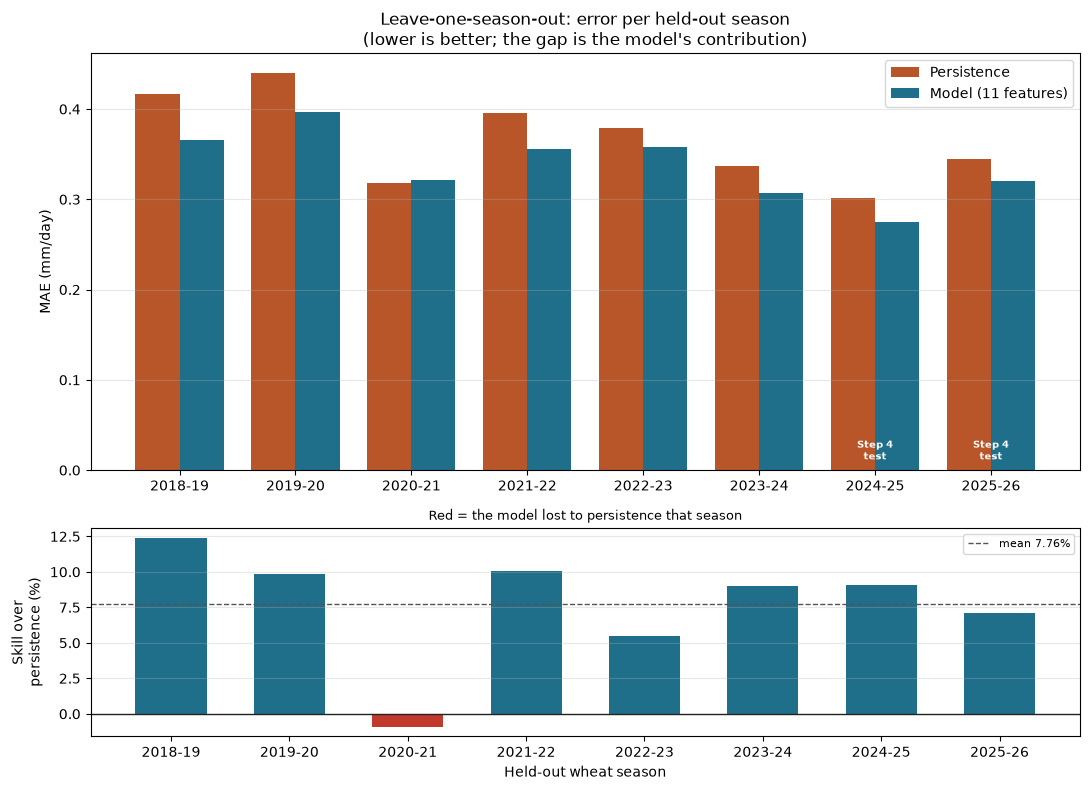

In [35]:
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 8), gridspec_kw={"height_ratios": [2, 1]})

x = np.arange(len(loso))
width = 0.38

ax.bar(x - width/2, loso["MAE_pers"],  width, color="#b8562a", label="Persistence")
ax.bar(x + width/2, loso["MAE_model"], width, color="#1f6f8b", label="Model (11 features)")

# Mark which two seasons were the real held-out test set in Step 4, so this chart can be read
# against the headline result rather than replacing it.
for i, season in enumerate(loso["season"]):
    if season in TEST_SEASONS:
        ax.text(i, 0.012, "Step 4\ntest", ha="center", fontsize=7, color="#ffffff", weight="bold")

ax.set_xticks(x); ax.set_xticklabels(loso["season"], rotation=0)
ax.set_ylabel("MAE (mm/day)")
ax.set_title("Leave-one-season-out: error per held-out season\n(lower is better; the gap is the model's contribution)")
ax.legend()
ax.grid(alpha=0.3, axis="y")

# ---- Lower panel: skill per season, so a losing season shows as a bar below zero ---------
colours = np.where(loso["skill_%"] > 0, "#1f6f8b", "#c0392b")
ax2.bar(x, loso["skill_%"], color=colours, width=0.6)
ax2.axhline(0, color="#222222", linewidth=1.0)
ax2.axhline(loso["skill_%"].mean(), color="#555555", linestyle="--", linewidth=1.0,
            label=f"mean {loso['skill_%'].mean():.2f}%")
ax2.set_xticks(x); ax2.set_xticklabels(loso["season"])
ax2.set_xlabel("Held-out wheat season")
ax2.set_ylabel("Skill over\npersistence (%)")
ax2.set_title("Red = the model lost to persistence that season", fontsize=9)
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

## Cell 41 - Does skill fall in more variable seasons?

This is the question the whole step exists to answer. Each point is one season: how variable its
ET0 was on the x-axis (standard deviation, mm/day), against how much the model beat persistence
on the y-axis.

If the points slope **downward**, the model's advantage shrinks in unusual seasons - which would
mean our headline number, measured on two very typical seasons, is optimistic. If there is no
clear slope, the advantage is roughly stable regardless of how strange the weather was.

With only eight points, a correlation here is suggestive at best. We print it with that warning
attached rather than treating it as established.

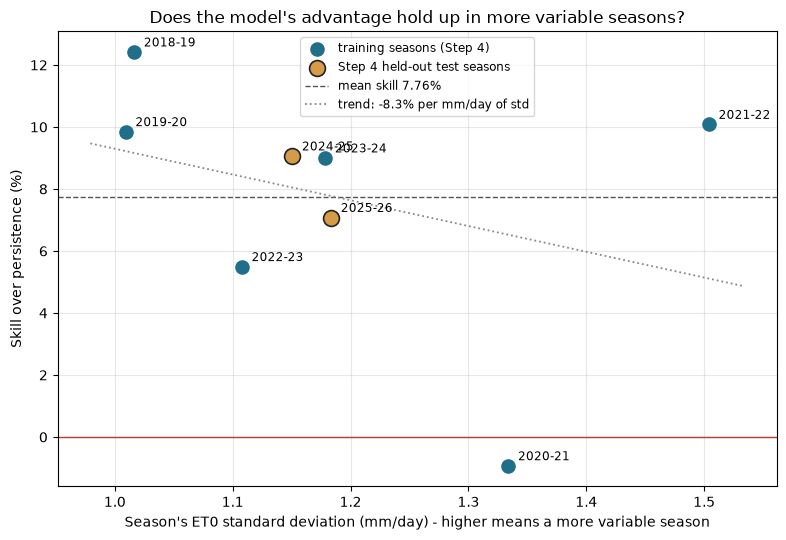

Correlation between a season's ET0 std and the model's skill: r = -0.337
Least-squares slope: -8.31 percentage points of skill per 1 mm/day of std

significant at the 5% level, so we treat this as a direction to watch, not a finding.

The two most variable seasons (never held out in Step 4):
   2021-22: std 1.504 mm/day, skill +10.08%, model MAE 0.3561 vs persistence 0.3961
   2020-21: std 1.334 mm/day, skill -0.93%, model MAE 0.3210 vs persistence 0.3180


In [36]:
fig, ax = plt.subplots(figsize=(8, 5.5))

# Colour the two Step 4 test seasons differently so their position in the cloud is visible.
is_test = loso["season"].isin(TEST_SEASONS)
ax.scatter(loso.loc[~is_test, "actual_std"], loso.loc[~is_test, "skill_%"],
           s=90, color="#1f6f8b", label="training seasons (Step 4)", zorder=3)
ax.scatter(loso.loc[is_test, "actual_std"], loso.loc[is_test, "skill_%"],
           s=130, color="#d59b4a", edgecolor="#222222", linewidth=1.2,
           label="Step 4 held-out test seasons", zorder=4)

# Label every point, since with eight seasons the identity of each matters more than the shape.
for _, row in loso.iterrows():
    ax.annotate(row["season"], (row["actual_std"], row["skill_%"]),
                textcoords="offset points", xytext=(7, 4), fontsize=8.5)

ax.axhline(0, color="#c0392b", linewidth=1.0, linestyle="-")
ax.axhline(loso["skill_%"].mean(), color="#555555", linestyle="--", linewidth=1.0,
           label=f"mean skill {loso['skill_%'].mean():.2f}%")

# A least-squares line through eight points, drawn only to make the direction visible.
slope, intercept = np.polyfit(loso["actual_std"], loso["skill_%"], 1)
xs = np.linspace(loso["actual_std"].min() - 0.03, loso["actual_std"].max() + 0.03, 50)
ax.plot(xs, slope * xs + intercept, ":", color="#888888", linewidth=1.3,
        label=f"trend: {slope:+.1f}% per mm/day of std")

ax.set_xlabel("Season's ET0 standard deviation (mm/day) - higher means a more variable season")
ax.set_ylabel("Skill over persistence (%)")
ax.set_title("Does the model's advantage hold up in more variable seasons?")
ax.legend(fontsize=8.5, loc="best")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Quantify it, with the sample-size warning printed right next to the number.
corr = loso["actual_std"].corr(loso["skill_%"])
print(f"Correlation between a season's ET0 std and the model's skill: r = {corr:+.3f}")
print(f"Least-squares slope: {slope:+.2f} percentage points of skill per 1 mm/day of std")
print(f"\nWARNING: this is 8 points. With n=8, |r| below about 0.71 is not statistically")
print(f"significant at the 5% level, so we treat this as a direction to watch, not a finding.")

# The two most variable seasons were never tested in Step 4 - report their skill explicitly,
# since they are the specific gap this step was built to close.
print("\nThe two most variable seasons (never held out in Step 4):")
for _, row in loso.nlargest(2, "actual_std").iterrows():
    print(f"   {row['season']}: std {row['actual_std']:.3f} mm/day, "
          f"skill {row['skill_%']:+.2f}%, model MAE {row['MAE_model']:.4f} "
          f"vs persistence {row['MAE_pers']:.4f}")

## Cell 42 - What the eight seasons show

### First, what this check is and is not

In seven of the eight rounds the model trains on at least one season that comes **after** the
season it is tested on. Holding out 2018-19 means fitting on 2019-20 through 2025-26 and then
predicting the past from the future. No deployable forecasting system can do that.

So this is a **robustness check**, not a forecast test. It answers a narrower question: *is the
relationship between today's weather and tomorrow's ET0 stable from year to year, or did Step 4
happen to pick two friendly seasons?* It cannot be quoted as predictive accuracy.

**Our headline number remains the strict time-ordered split from Step 4: +7.76% over
persistence, trained on 2018-19 to 2023-24 and tested on 2024-25 and 2025-26.** Nothing in this
step replaces that, and the earlier results table is untouched.

### The result: the advantage holds in seven of eight seasons

| Season | Rows | ET0 std | MAE pers | MAE model | Skill | Bias | MAE rainy | MAE dry |
|---|---|---|---|---|---|---|---|---|
| 2018-19 | 148 | 1.016 | 0.4170 | 0.3652 | **+12.42%** | −0.014 | 0.6421 | 0.3117 |
| 2019-20 | 151 | 1.009 | 0.4397 | 0.3964 | +9.85% | +0.028 | 0.7643 | 0.3052 |
| 2020-21 | 150 | 1.334 | 0.3180 | 0.3210 | **−0.93%** | −0.075 | 0.4913 | 0.3101 |
| 2021-22 | 150 | 1.504 | 0.3961 | 0.3561 | +10.08% | −0.026 | 0.5420 | 0.3324 |
| 2022-23 | 150 | 1.108 | 0.3785 | 0.3577 | +5.49% | +0.017 | 0.7844 | 0.3137 |
| 2023-24 | 151 | 1.179 | 0.3374 | 0.3071 | +9.00% | −0.004 | 0.6510 | 0.2774 |
| 2024-25 | 150 | 1.151 | 0.3018 | 0.2744 | +9.06% | +0.029 | 0.5483 | 0.2394 |
| 2025-26 | 150 | 1.184 | 0.3443 | 0.3199 | +7.08% | +0.054 | 0.7955 | 0.2785 |

**Mean skill +7.76%, standard deviation 4.07 percentage points, range −0.93% to +12.42%, and the
model beat persistence in 7 of 8 seasons.** Pooled over all 1200 days, skill is +8.01%.

The mean across these eight seasons (+7.76%) matching the Step 4 headline (+7.76%) to two decimal
places is a **coincidence**, not a confirmation - different test sets, different training sets.
We mention it only so nobody reads the repetition as significant.

### The headline was not a lucky draw

That is the main thing this step establishes. Step 4's two test seasons scored +9.06% and +7.08%,
both comfortably inside the eight-season spread and close to its mean. If 2024-25 and 2025-26 had
been unusually easy, their skill would sit at the top of this range. It does not.

### The worst season: 2020-21, the only loss

The model lost to persistence in exactly one season, 2020-21, by **0.93%** (MAE 0.3210 against
persistence's 0.3180 - a difference of 0.003 mm/day, which is negligible in absolute terms but is
a loss and we report it as one).

**What the data shows about why:**

- 2020-21 had the **lowest persistence MAE of all eight seasons** (0.3180). It was the season
  where "tomorrow equals today" worked best, so there was the least room for any model to add
  value. The model was not unusually bad there; its MAE of 0.3210 is mid-range. Persistence was
  unusually good.
- It had the **fewest rainy days of any season: 9**, against 12-30 elsewhere. Since rain days are
  where persistence breaks down, a season with almost no rain is a season where persistence is
  hard to beat.
- It also carried the most negative bias of the eight (−0.075), meaning the model under-predicted
  water demand that season more than in any other.

**Guess:** 2020-21 combined high variability (std 1.334, second highest) with low persistence
error, which would happen if its ET0 moved in smooth sustained trends rather than day-to-day
jumps - exactly the pattern persistence handles well. We have not measured day-to-day change
separately from overall spread, so this is a guess. Testing it would mean comparing each season's
mean absolute day-to-day ET0 change against its persistence MAE, which is a short follow-up.

### The specific worry was not confirmed

The reason for this step was that the two most variable seasons, 2020-21 and 2021-22, had never
been tested. Now they have:

- **2021-22**, the most variable season of all (std 1.504): skill **+10.08%**, *above* the
  eight-season mean. The model handled the most erratic season better than average.
- **2020-21** (std 1.334): skill **−0.93%**, the only loss.

So variability alone does not break the model. The correlation between a season's ET0 standard
deviation and the model's skill is **r = −0.337** with a slope of −8.3 percentage points per
mm/day - a mild downward direction, but with only 8 points this is not statistically significant
(at n=8 you need |r| above about 0.71 for 5% significance). **We treat it as a direction worth
watching, not a finding**, and we would not claim "skill falls in variable seasons" on this
evidence.

### What is consistent across all eight seasons

**Rainy-day error exceeds dry-day error in every single season, without exception.** The ratio
ranges from 1.58x (2020-21) to 2.86x (2025-26). Dry-day MAE is remarkably stable across years
(0.239 to 0.332), while rainy-day MAE swings widely (0.491 to 0.796).

This is the same failure mode found in Step 4 and measured in Step 6, now shown to be a permanent
property of the model rather than a quirk of two test seasons. Combined with Step 6's finding
that even a perfect rain forecast only removes about 8% of rainy-day error, the picture is
consistent: **the model is dependably decent on dry days and dependably weak when weather systems
pass through, in every year we have data for.**

Bias is small in every season (−0.075 to +0.054) with no consistent sign - four seasons negative,
four positive - which suggests the model is not systematically skewed, and that the +0.050 bias
seen in Step 4 is within normal year-to-year variation rather than a structural flaw.

---

# Step 8 - Lead time: 1 to 3 days ahead

Everything so far predicts **tomorrow**. That is not actually enough notice to be useful. A
farmer near Karnal has to arrange a canal turn or book pump power, and both take more than a
few hours - so the practical question is not "can you predict tomorrow?" but **"how many days
of notice can you give before the prediction stops being worth anything?"**

We rebuild the whole experiment at three horizons: +1, +2 and +3 days. Same features, same
model settings, same strict time-ordered split. The only thing that changes is how far ahead we
are asking.

## Cell 43 - Build the three targets

For horizon *h* the target is `shift(-h)` of ET0, computed on the **full continuous daily
series** before any season filtering - the same reasoning as Cell 8. If we filtered first, the
"+3 days" target for 29 March would wrap round to the following November.

For each horizon we keep only rows where **today and the target day fall in the same wheat
season**. That drops *h* days from the end of every season, so the usable row count shrinks
slightly as the horizon grows. We print it rather than letting it pass unnoticed.

We also carry `rain_target_h`, the rainfall on the target day, as a **diagnostic only** - used
in Cell 47 to split rainy from dry target days, never as a feature.

In [37]:
HORIZONS = [1, 2, 3]

# Everything is built on `lagged`, the full continuous 2708-day series (continuity asserted in
# Cell 7), so shift(-h) is always exactly h calendar days ahead.
for h in HORIZONS:
    lagged[f"et0_target_{h}"]    = lagged["et0_fao_evapotranspiration"].shift(-h)
    lagged[f"season_target_{h}"] = lagged["season"].shift(-h)
    # Rainfall on the target day. DIAGNOSTIC ONLY - this is future information and is never
    # passed to any model; it is used solely to sort our errors in Cell 47.
    lagged[f"rain_target_{h}"]   = lagged["precipitation_sum"].shift(-h)

# ---- Build one filtered frame per horizon --------------------------------------------
horizon_data = {}
print("Rows kept per horizon:")
for h in HORIZONS:
    keep = (lagged["season"].notna()
            & (lagged["season"] == lagged[f"season_target_{h}"])   # target day in the same season
            & lagged[LAG_FEATURES].notna().all(axis=1)             # the 2-day lag warm-up
            & lagged[f"et0_target_{h}"].notna())
    frame = lagged[keep].copy()

    # day_of_season for TODAY, rebuilt exactly as in Cell 22.
    frame["day_of_season"] = (
        frame["date"] - pd.to_datetime(frame["season"].str[:4] + "-11-01")
    ).dt.days
    # day_of_season for the TARGET day. Because today and the target are in the same season
    # and the series is continuous, this is simply today's value plus h.
    frame[f"dos_target_{h}"] = frame["day_of_season"] + h

    horizon_data[h] = frame
    lost = len(data_lag) - len(frame)
    print(f"   +{h} day: {len(frame):>5} rows   "
          f"({lost} fewer than the +1 dataset: {h} day(s) dropped from the end of each of "
          f"{frame['season'].nunique()} seasons)")

# ---- Prove no feature uses information from after today -------------------------------
# FEATURES_LAG contains: today's 7 Open-Meteo observations, day_of_season (a calendar fact),
# and three lags built with shift(+1)/rolling backwards (yesterday and earlier). A positive
# shift looks BACKWARD in time; only a negative shift looks forward, and every negative shift
# in this notebook creates a TARGET or a diagnostic, never a feature.
FORBIDDEN = ["target", "tomorrow", "_fc_", "forecast", "precip_tomorrow"]
for h in HORIZONS:
    for f in FEATURES_LAG:
        assert not any(bad in f for bad in FORBIDDEN), (
            f"Feature '{f}' looks like it carries information from after today")
print(f"\nAsserted for all {len(HORIZONS)} horizons: none of the {len(FEATURES_LAG)} features "
      f"carries post-today information.")
print(f"Features (all known by the end of today): {', '.join(FEATURES_LAG)}")

Rows kept per horizon:
   +1 day:  1200 rows   (0 fewer than the +1 dataset: 1 day(s) dropped from the end of each of 8 seasons)
   +2 day:  1192 rows   (8 fewer than the +1 dataset: 2 day(s) dropped from the end of each of 8 seasons)
   +3 day:  1184 rows   (16 fewer than the +1 dataset: 3 day(s) dropped from the end of each of 8 seasons)

Asserted for all 3 horizons: none of the 11 features carries post-today information.
Features (all known by the end of today): et0_fao_evapotranspiration, temperature_2m_max, temperature_2m_min, wind_speed_10m_max, shortwave_radiation_sum, relative_humidity_2m_mean, precipitation_sum, day_of_season, et0_yesterday, et0_3day_mean, et0_change


## Cell 44 - Train and score all three horizons

The split is **identical at every horizon** - train 2018-19 to 2023-24, test 2024-25 and
2025-26 - so the three horizons are directly comparable with each other and with Step 4.

Three predictors per horizon:

- **persistence**: the target day's ET0 equals today's. At +1 this is a strong baseline; at +3 it
  is a much weaker claim, and seeing how fast it decays is half the point of this step.
- **seasonal average**: the training-season mean ET0 for the **target day's** day-of-season,
  7-day smoothed. Note this baseline should barely degrade with horizon, because it never looked
  at today's weather in the first place - it only needs to know the date, and we know the date
  three days ahead exactly as well as one.
- **our model**: the same 11 features and the same pipeline, refitted separately for each
  horizon. No settings change between horizons and nothing is tuned.

In [38]:
horizon_rows = []        # one row per (horizon, model) for the summary table
horizon_preds = {}       # keep the scored test frames for the rainy/dry split in Cell 47

for h in HORIZONS:
    frame = horizon_data[h]
    tgt = f"et0_target_{h}"
    dos_t = f"dos_target_{h}"

    tr = frame[frame["season"].isin(TRAIN_SEASONS)].copy()
    te = frame[frame["season"].isin(TEST_SEASONS)].copy()
    # The leakage check, repeated at every horizon rather than assumed from Step 1.
    assert tr["date"].max() < te["date"].min(), f"+{h}d: time leakage"

    # ---- a) persistence: today's ET0, held flat for h days --------------------------
    te["pred_persistence"] = te["et0_fao_evapotranspiration"]

    # ---- b) seasonal average, keyed on the TARGET day's day_of_season ---------------
    # Built from TRAIN rows only, then smoothed. min_periods=1 keeps the season's edges.
    prof = tr.groupby(dos_t)[tgt].mean().reindex(range(0, 151))
    prof = prof.rolling(window=7, center=True, min_periods=1).mean()
    te["pred_seasonal"] = te[dos_t].map(prof)
    assert te["pred_seasonal"].notna().all(), f"+{h}d: a test day has no seasonal profile value"

    # ---- c) our model, refitted for this horizon ------------------------------------
    pipe = Pipeline([("scaler", StandardScaler()), ("linreg", LinearRegression())])
    pipe.fit(tr[FEATURES_LAG], tr[tgt])          # TRAIN only; the scaler sees no test rows
    te["pred_model"] = pipe.predict(te[FEATURES_LAG])

    # ---- Score all three on the same test days --------------------------------------
    mae_p = np.mean(np.abs(te["pred_persistence"] - te[tgt]))   # the skill denominator
    for col, label in [("pred_persistence", "Persistence"),
                       ("pred_seasonal",    "Seasonal average"),
                       ("pred_model",       "Our model (11 features)")]:
        row = evaluate(te[tgt], te[col], label)
        row["horizon_days"] = h
        row["skill_%"] = (mae_p - row["MAE"]) / mae_p * 100
        horizon_rows.append(row)

    horizon_preds[h] = te
    print(f"+{h} day: trained on {len(tr)} rows, tested on {len(te)} rows "
          f"({te['date'].min().date()} to {te['date'].max().date()})")

horizon_table = pd.DataFrame(horizon_rows)

print("\n" + "=" * 96)
print("ERROR BY LEAD TIME   (test seasons 2024-25 + 2025-26, strict time-ordered split)")
print("=" * 96)
print(horizon_table[["horizon_days", "model", "n", "MAE", "RMSE", "bias", "skill_%"]]
      .round(4).to_string(index=False))

# ---- How fast does each method decay? ---------------------------------------------------
print("\n" + "-" * 96)
print("MAE growth from +1 day to +3 days:")
for label in ["Persistence", "Seasonal average", "Our model (11 features)"]:
    sub = horizon_table[horizon_table["model"] == label].set_index("horizon_days")
    m1, m3 = sub.loc[1, "MAE"], sub.loc[3, "MAE"]
    print(f"   {label:<26} {m1:.4f} -> {m3:.4f} mm/day  ({(m3 - m1) / m1 * 100:+.1f}%)")

print("\nSkill over persistence at each horizon:")
for h in HORIZONS:
    s = float(horizon_table[(horizon_table["horizon_days"] == h) &
                            (horizon_table["model"] == "Our model (11 features)")]["skill_%"].iloc[0])
    sa = float(horizon_table[(horizon_table["horizon_days"] == h) &
                             (horizon_table["model"] == "Seasonal average")]["skill_%"].iloc[0])
    print(f"   +{h} day: our model {s:+.2f}%   seasonal average {sa:+.2f}%")

+1 day: trained on 900 rows, tested on 300 rows (2024-11-01 to 2026-03-30)
+2 day: trained on 894 rows, tested on 298 rows (2024-11-01 to 2026-03-29)
+3 day: trained on 888 rows, tested on 296 rows (2024-11-01 to 2026-03-28)

ERROR BY LEAD TIME   (test seasons 2024-25 + 2025-26, strict time-ordered split)
 horizon_days                   model   n    MAE   RMSE    bias  skill_%
            1             Persistence 300 0.3230 0.4663 -0.0102   0.0000
            1        Seasonal average 300 0.4020 0.5600  0.0365 -24.4349
            1 Our model (11 features) 300 0.2980 0.4365  0.0501   7.7604
            2             Persistence 298 0.4351 0.6218 -0.0196   0.0000
            2        Seasonal average 298 0.4016 0.5596  0.0401   7.6899
            2 Our model (11 features) 298 0.4014 0.5636  0.0893   7.7360
            3             Persistence 296 0.4840 0.6749 -0.0347   0.0000
            3        Seasonal average 296 0.4020 0.5606  0.0417  16.9482
            3 Our model (11 features

## Cell 45 - Error against lead time

One line per method. The shape of each line is the story.

Persistence should rise steeply: the further ahead you look, the less today's weather resembles
the target day. The seasonal average should be almost flat, because it only ever used the
calendar. Where those two lines **cross** is the horizon at which knowing today's weather stops
being more valuable than knowing the date - and that crossing point, if it happens within three
days, is the practical limit of this whole approach.

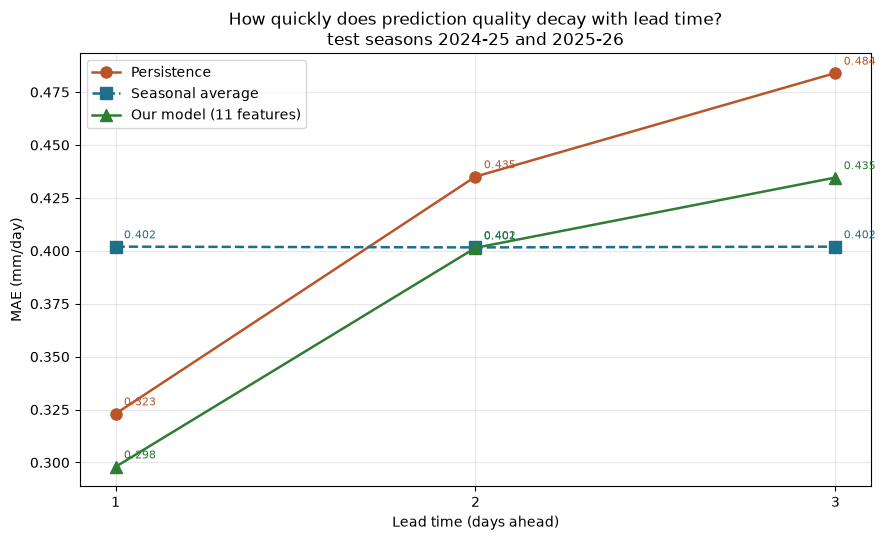

In [39]:
fig, ax = plt.subplots(figsize=(9, 5.5))

styles = {
    "Persistence":             ("#b8562a", "o", "-"),
    "Seasonal average":        ("#1f6f8b", "s", "--"),
    "Our model (11 features)": ("#2e7d32", "^", "-"),
}
for label, (colour, marker, ls) in styles.items():
    sub = horizon_table[horizon_table["model"] == label].sort_values("horizon_days")
    ax.plot(sub["horizon_days"], sub["MAE"], marker=marker, linestyle=ls, color=colour,
            linewidth=1.8, markersize=8, label=label)
    # Annotate each point so the chart is readable without cross-checking the table.
    for _, r in sub.iterrows():
        ax.annotate(f"{r['MAE']:.3f}", (r["horizon_days"], r["MAE"]),
                    textcoords="offset points", xytext=(6, 6), fontsize=8, color=colour)

ax.set_xticks(HORIZONS)
ax.set_xlabel("Lead time (days ahead)")
ax.set_ylabel("MAE (mm/day)")
ax.set_title("How quickly does prediction quality decay with lead time?\n"
             "test seasons 2024-25 and 2025-26")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Cell 46 - Rainy against dry target days, at all three horizons

Step 4 found the model has no skill when rain arrives. Here we ask whether that gets better or
worse with lead time.

A target day counts as **rainy** when more than 1 mm fell on it. As always, that rainfall is
diagnostic only - it sorts our errors after the fact and was never given to any model.

In [40]:
rain_rows = []
for h in HORIZONS:
    te = horizon_preds[h]
    tgt = f"et0_target_{h}"
    rainy = te[f"rain_target_{h}"] > RAIN_THRESHOLD      # diagnostic only

    for subset_name, mask in [("all", pd.Series(True, index=te.index)),
                              ("dry", ~rainy), ("rainy", rainy)]:
        block = te[mask]
        if len(block) == 0:
            continue
        mae_p = np.mean(np.abs(block["pred_persistence"] - block[tgt]))
        for col, label in [("pred_persistence", "Persistence"),
                           ("pred_model",       "Our model (11 features)")]:
            mae = np.mean(np.abs(block[col] - block[tgt]))
            rain_rows.append({
                "horizon_days": h, "subset": subset_name, "model": label,
                "n": len(block), "MAE": mae,
                "bias": np.mean(block[col] - block[tgt]),
                "skill_%": (mae_p - mae) / mae_p * 100,
            })

rain_table = pd.DataFrame(rain_rows)

print("=" * 96)
print("RAINY vs DRY TARGET DAYS, BY LEAD TIME")
print("=" * 96)
# Pivot so each horizon's dry/rainy MAE sit side by side and the pattern is visible at a glance.
pivot = rain_table.pivot_table(index=["horizon_days", "subset"], columns="model",
                               values=["n", "MAE", "skill_%"])
print(pivot.round(4).to_string())

print("\n" + "-" * 96)
print("Our model: rainy-day MAE as a multiple of dry-day MAE, and rainy-day skill:")
for h in HORIZONS:
    sel = rain_table[(rain_table["horizon_days"] == h) &
                     (rain_table["model"] == "Our model (11 features)")].set_index("subset")
    ratio = sel.loc["rainy", "MAE"] / sel.loc["dry", "MAE"]
    print(f"   +{h} day: dry {sel.loc['dry', 'MAE']:.4f}  rainy {sel.loc['rainy', 'MAE']:.4f}  "
          f"({ratio:.2f}x)   rainy skill {sel.loc['rainy', 'skill_%']:+.2f}%   "
          f"rainy bias {sel.loc['rainy', 'bias']:+.4f}  (n rainy = {int(sel.loc['rainy', 'n'])})")

RAINY vs DRY TARGET DAYS, BY LEAD TIME
                                        MAE                                   n                             skill_%            
model               Our model (11 features) Persistence Our model (11 features) Persistence Our model (11 features) Persistence
horizon_days subset                                                                                                            
1            all                     0.2980      0.3230                   300.0       300.0                  7.7604         0.0
             dry                     0.2603      0.2890                   271.0       271.0                  9.9270         0.0
             rainy                   0.6501      0.6414                    29.0        29.0                 -1.3618         0.0
2            all                     0.4014      0.4351                   298.0       298.0                  7.7360         0.0
             dry                     0.3547      0.3984          

## Cell 47 - How far ahead is this actually useful?

### The decay rates

| Method | +1 day | +2 days | +3 days | Growth |
|---|---|---|---|---|
| Persistence | 0.3230 | 0.4351 | 0.4840 | **+49.8%** |
| Seasonal average | 0.4020 | 0.4016 | 0.4020 | **−0.0%** |
| Our model | 0.2980 | 0.4014 | 0.4346 | **+45.9%** |

**Persistence falls apart fastest**, losing half its accuracy over two extra days. That is the
atmosphere forgetting: today's air mass still resembles tomorrow's, resembles the day after's
much less, and by three days out "same as today" is close to a guess.

**The seasonal average does not decay at all** - 0.4020, 0.4016, 0.4020. This is not a bug and
it is worth pausing on, because it is the most important structural fact in this step. That
baseline never used today's weather; it only needs to know the date, and we know the date three
days ahead exactly as precisely as one. So its accuracy is horizon-independent by construction.
It is a floor that does not move.

**Our model decays almost exactly as fast as persistence** (+45.9% against +49.8%). That makes
sense given Step 3: its largest coefficient by far is today's ET0, so it inherits persistence's
decay and adds a calendar correction on top.

### The crossover: our model stops being the best option at +2 days

This is the finding that matters, and the raw skill-over-persistence column hides it:

| Horizon | Our model | Seasonal average | Best method |
|---|---|---|---|
| +1 day | **0.2980** | 0.4020 | **our model**, by 26% |
| +2 days | 0.4014 | 0.4016 | **a dead heat** (0.0002 mm/day apart) |
| +3 days | 0.4346 | **0.4020** | **seasonal average**, by 7.5% |

Read against persistence, our model looks like it holds up or even improves: +7.76%, +7.74%,
+10.20%. **That impression is false.** Skill over persistence rises at +3 days only because
persistence is collapsing, not because we are doing better - our absolute MAE got 46% worse.
Measured against the *better* baseline, our model goes from clearly winning, to tying, to
losing.

At +3 days the seasonal average beats our model by 7.5%, and its skill over persistence
(+16.95%) is well above ours (+10.20%). **So at three days out, the best available prediction is
the long-run climate normal for that date - which requires no model, no features, and no
knowledge of today's weather at all.**

The crossover sits at **+2 days**. Beyond roughly two days, today's observations contribute
nothing, and the honest recommendation is to stop modelling and read the calendar.

### Rainy days get worse with lead time, not better

| Horizon | Dry MAE | Rainy MAE | Ratio | Rainy skill | Rainy bias |
|---|---|---|---|---|---|
| +1 day | 0.2603 | 0.6501 | 2.50x | −1.36% | +0.554 |
| +2 days | 0.3547 | 0.8348 | 2.35x | **−7.65%** | +0.795 |
| +3 days | 0.3897 | 0.8480 | 2.18x | **−6.18%** | +0.732 |

The rainy-day weakness found in Step 4 **deepens** with lead time. At every horizon the model
has negative skill on rainy days, and at +2 and +3 days it is 6-8% *worse* than persistence
there - a bigger deficit than at +1 day. The over-prediction bias grows too, from +0.55 to
+0.79 mm/day.

The falling ratio (2.50x, 2.35x, 2.18x) is not an improvement. It happens because dry-day error
is rising quickly while rainy-day error is already near its ceiling - the model converges towards
being uniformly poor rather than getting better on rain.

Bias grows monotonically with horizon across all days too: +0.050, +0.089, +0.094 mm/day. The
further ahead it predicts, the more it over-states water demand.

### Can we give a farmer two or three days' notice? No.

**Stated plainly: this model cannot usefully give two or three days' notice, and we should not
claim it can.**

The reasoning, in order:

1. **At +1 day it is genuinely the best of the three** (0.2980, 26% better than the seasonal
   average, +7.76% over persistence). That result stands, and Step 7 showed it holds in 7 of 8
   seasons.
2. **At +2 days it has become indistinguishable from the climate normal** - 0.4014 against
   0.4016, a gap of 0.0002 mm/day. Anything you could get from our model at this horizon, you
   could get from a lookup table of historical averages by date.
3. **At +3 days it is actively worse than that lookup table** by 7.5%.
4. **Error size against the decision.** Mean test ET0 is 2.81 mm/day. A +3 day MAE of 0.4346 is
   about 15% of the typical daily demand, and on rainy target days 0.848 - roughly 30%. An
   irrigation decision made on a number that may be 30% wrong in the direction of over-watering
   is not a decision we would stand behind.
5. **The practical gap this leaves is real and we should say so.** The farmer's actual need -
   two or three days of notice to arrange water and pump power - is exactly the need this
   approach does not meet. Our tool answers a one-day question, which is less notice than the
   problem requires.

**What would actually fix it, and it is not a better model.** Step 6 already showed the way:
Open-Meteo's own numerical weather forecast scored 0.1426 mm/day at +1 day, better than our best
+1 day result by 59%, and NWP forecasts remain skilful out to 5-10 days because they simulate
the atmosphere forward rather than extrapolating from one day's observations. The route to
useful multi-day notice is to take the weather service's multi-day ET0 forecast and put our
irrigation decision logic on top of it. Our contribution belongs in the decision layer -
rainfall, crop coefficient, soil water balance - not in trying to out-predict a physics model
from a single grid point of yesterday's weather.

### Caveats

- One test set of two seasons, 296-300 days per horizon, with only **29 rainy target days** at
  each horizon. The rainy-day numbers in particular are a small sample and we would not defend
  them to two decimal places.
- The +2 and +3 day datasets are 8 and 16 rows smaller than +1 because each season loses its
  last *h* days, so the three horizons are not scored on precisely identical day sets. The
  difference is under 1.4% of rows and cannot account for effects of this size.
- Same features and settings at every horizon, nothing tuned on test data. We did not try giving
  the longer horizons different features, which might close some of the gap - but given that the
  seasonal average already matches us at +2 days using nothing but the date, we doubt there is
  much to recover from today's observations.

---

# Step 5 - The irrigation decision layer

Step 6 settled what our contribution is not. Open-Meteo's own day-ahead ET0 forecast scored
**0.1426 mm/day** against our best model's **0.3510** on the same test season - four times more
accurate, free, and keyless. We are not going to out-predict a numerical weather model from one
grid point of yesterday's observations, and Step 8 showed the same approach is useless beyond
two days.

But a weather service stops at ET0. It does not tell a farmer **whether to irrigate**, because
that depends on the crop's growth stage, the rain that has already fallen, and how much water
the soil is still holding. That conversion is the part nobody ships, and it is where this
project can be genuinely useful.

So this step builds the decision layer and asks one question: **does feeding it a good forecast
produce irrigation dates that match what hindsight says was right?**

## Cell 48 - Constants, with the source of each one stated

Every number below either comes from FAO-56 (the UN FAO's Irrigation and Drainage Paper 56, the
standard reference for crop water requirements) or is an assumption we are making. We label
which is which, because the difference matters when judges ask where a number came from.

The honest position: the crop coefficients are quoted from FAO-56. The stage lengths are
**adapted**, not quoted. The sowing date is **assumed**. The trigger is a **scenario range**,
not a derived value - FAO-56 sets the irrigation trigger as a fraction *p* of total available
water (TAW), and TAW depends on soil texture and root depth, neither of which we have for these
fields. Rather than invent a soil profile, we run three trigger values and report how much the
answer depends on the choice.

In [41]:
# ---- Crop coefficients: QUOTED from FAO-56 ------------------------------------------
Kc_INI = 0.7    # FAO-56 Table 12, winter wheat, non-frozen soils
Kc_MID = 1.15   # FAO-56 Table 12
Kc_END = 0.4    # FAO-56 Table 12 gives 0.25-0.41 for winter wheat; we take the upper end,
                # which suits harvest at higher grain moisture rather than fully dried down.

# ---- Stage lengths: ADAPTED, *** NOT *** A FAO-56 ROW -------------------------------
# FAO-56 Table 11 lists winter wheat stage lengths for specific climates and sowing dates,
# none of which is a ~150-day north-Indian Rabi season. The four numbers below are OUR
# adaptation: they keep the FAO-56 four-stage shape and sum to 150 days to fit the Nov-Mar
# season we actually have data for. They are NOT quotable as FAO-56 values, and a real
# deployment should replace them with locally observed phenology dates.
STAGE_INIT = 25   # ADAPTED - emergence and early tillering
STAGE_DEV  = 55   # ADAPTED - tillering through to jointing/booting
STAGE_MID  = 45   # ADAPTED - heading, flowering, early grain fill (peak water use)
STAGE_LATE = 25   # ADAPTED - grain fill to maturity, demand falling away
SEASON_LEN = STAGE_INIT + STAGE_DEV + STAGE_MID + STAGE_LATE
assert SEASON_LEN == 150, "Stage lengths must sum to the 150-day season we model"

# ---- Sowing date: ASSUMED -------------------------------------------------------------
# day_of_season 14 = 15 November, the middle of the usual Haryana wheat sowing window.
# We do not have the actual sowing date for any field, so this is an ASSUMPTION. Sowing a
# fortnight either side would shift the whole Kc curve and therefore every irrigation date.
SOWING_DAY_OF_SEASON = 14

# ---- Irrigation trigger: a SCENARIO RANGE, not a derived value ------------------------
# FAO-56 triggers irrigation when the soil water deficit reaches p x TAW, where TAW depends
# on soil texture and rooting depth. We have neither for these fields, so we refuse to invent
# a soil profile and instead test three plausible deficits spanning light to heavy soils.
TRIGGERS_MM = [40, 60, 80]

print("CROP COEFFICIENTS (quoted from FAO-56 Table 12):")
print(f"   Kc initial {Kc_INI}   Kc mid {Kc_MID}   Kc end {Kc_END}")
print("\nSTAGE LENGTHS (*** ADAPTED by us, not a FAO-56 row ***):")
print(f"   init {STAGE_INIT} + development {STAGE_DEV} + mid {STAGE_MID} + late {STAGE_LATE}"
      f" = {SEASON_LEN} days")
print(f"\nSOWING (*** ASSUMED ***): day_of_season {SOWING_DAY_OF_SEASON} "
      f"(~{(pd.Timestamp('2025-11-01') + pd.Timedelta(days=SOWING_DAY_OF_SEASON)).strftime('%d %B')})")
print(f"\nTRIGGERS (*** SCENARIO RANGE, not derived ***): {TRIGGERS_MM} mm of soil water deficit")

CROP COEFFICIENTS (quoted from FAO-56 Table 12):
   Kc initial 0.7   Kc mid 1.15   Kc end 0.4

STAGE LENGTHS (*** ADAPTED by us, not a FAO-56 row ***):
   init 25 + development 55 + mid 45 + late 25 = 150 days

SOWING (*** ASSUMED ***): day_of_season 14 (~15 November)

TRIGGERS (*** SCENARIO RANGE, not derived ***): [40, 60, 80] mm of soil water deficit


## Cell 49 - The Kc curve

FAO-56 models crop water use as `ETc = Kc x ET0`, where Kc rises as the canopy develops and
falls as the crop ripens. The standard shape is four straight segments: flat through the initial
stage, a linear rise through development, flat at the peak through mid-season, and a linear fall
through the late stage.

Reading the curve: at Kc 0.7 a wheat crop uses 70% of the reference ET0, and at the mid-season
peak of 1.15 it uses 15% **more** than the reference grass surface. That peak lands in
February-March here, which is exactly when ET0 itself is climbing - so crop water use rises much
faster than the weather alone suggests. That compounding is the reason a decision layer is worth
building.

Kc curve built over 150 days after sowing.
   range 0.400 to 1.150
   day   0 after sowing: Kc 0.700  (initial)
   day  24 after sowing: Kc 0.700  (initial)
   day  25 after sowing: Kc 0.708  (development)
   day  50 after sowing: Kc 0.913  (development)
   day  79 after sowing: Kc 1.150  (development)
   day  80 after sowing: Kc 1.150  (mid-season)
   day 100 after sowing: Kc 1.150  (mid-season)
   day 124 after sowing: Kc 1.150  (mid-season)
   day 125 after sowing: Kc 1.120  (late)
   day 140 after sowing: Kc 0.670  (late)
   day 149 after sowing: Kc 0.400  (late)


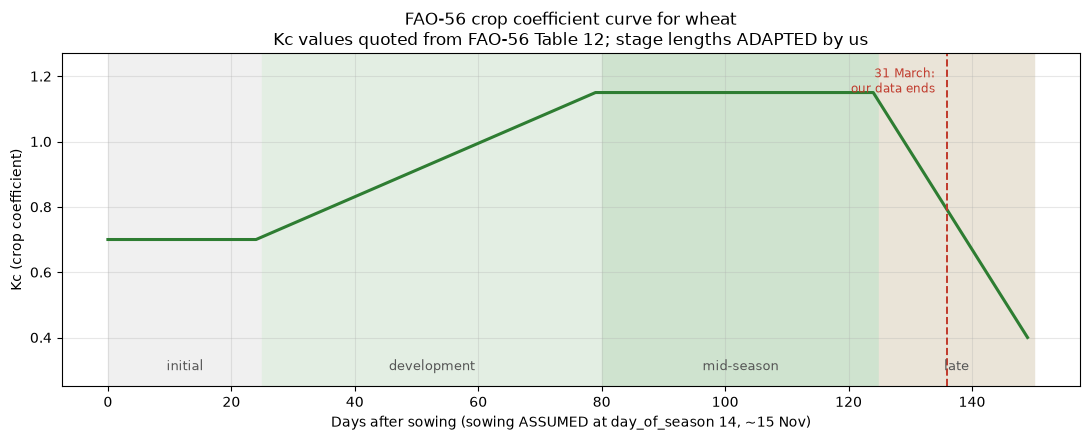


NOTE: our wheat-season data runs to 31 March = day 136 after sowing, so the
final 14 days of the late stage fall outside the window we model.


In [42]:
def build_kc_curve():
    # The FAO-56 four-segment Kc curve, indexed by days after sowing (0 .. SEASON_LEN-1).
    kc = np.zeros(SEASON_LEN)

    # 1. Initial stage: flat at Kc_INI (bare-ish soil, small canopy).
    kc[:STAGE_INIT] = Kc_INI

    # 2. Development: straight line from Kc_INI up to Kc_MID as the canopy closes.
    #    np.linspace with endpoint=True lands exactly on Kc_MID on the last development day.
    a = STAGE_INIT
    kc[a:a + STAGE_DEV] = np.linspace(Kc_INI, Kc_MID, STAGE_DEV + 1)[1:]

    # 3. Mid-season: flat at the peak, through flowering and early grain fill.
    b = a + STAGE_DEV
    kc[b:b + STAGE_MID] = Kc_MID

    # 4. Late season: straight line down to Kc_END as the crop ripens and stomata close.
    c = b + STAGE_MID
    kc[c:c + STAGE_LATE] = np.linspace(Kc_MID, Kc_END, STAGE_LATE + 1)[1:]

    return kc

KC = build_kc_curve()

print(f"Kc curve built over {len(KC)} days after sowing.")
print(f"   range {KC.min():.3f} to {KC.max():.3f}")
for das in [0, 24, 25, 50, 79, 80, 100, 124, 125, 140, 149]:
    stage = ("initial" if das < STAGE_INIT else
             "development" if das < STAGE_INIT + STAGE_DEV else
             "mid-season" if das < STAGE_INIT + STAGE_DEV + STAGE_MID else "late")
    print(f"   day {das:>3} after sowing: Kc {KC[das]:.3f}  ({stage})")

# ---- Plot --------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 4.5))
das = np.arange(SEASON_LEN)
ax.plot(das, KC, color="#2e7d32", linewidth=2.2)

# Shade the four stages so the segments are identifiable without counting days.
bounds = [0, STAGE_INIT, STAGE_INIT + STAGE_DEV, STAGE_INIT + STAGE_DEV + STAGE_MID, SEASON_LEN]
names  = ["initial", "development", "mid-season", "late"]
shades = ["#f0f0f0", "#e3eee3", "#cfe3cf", "#eae4d8"]
for i in range(4):
    ax.axvspan(bounds[i], bounds[i + 1], color=shades[i], zorder=0)
    ax.text((bounds[i] + bounds[i + 1]) / 2, Kc_END - 0.1, names[i],
            ha="center", fontsize=9, color="#555555")

# Our data window ends before the curve does - mark it, because it is a real limitation.
DATA_END_DAS = 150 - SOWING_DAY_OF_SEASON     # last day_of_season we have, minus sowing
ax.axvline(DATA_END_DAS, color="#c0392b", linestyle="--", linewidth=1.4)
ax.text(DATA_END_DAS - 2, Kc_MID, "31 March:\nour data ends", ha="right", fontsize=8.5,
        color="#c0392b")

ax.set_xlabel(f"Days after sowing (sowing ASSUMED at day_of_season {SOWING_DAY_OF_SEASON}, ~15 Nov)")
ax.set_ylabel("Kc (crop coefficient)")
ax.set_title("FAO-56 crop coefficient curve for wheat\n"
             "Kc values quoted from FAO-56 Table 12; stage lengths ADAPTED by us")
ax.set_ylim(Kc_END - 0.15, Kc_MID + 0.12)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nNOTE: our wheat-season data runs to 31 March = day {DATA_END_DAS} after sowing, so the")
print(f"final {SEASON_LEN - DATA_END_DAS} days of the late stage fall outside the window we model.")

## Cell 50 - The water balance and the four decision methods

The balance is a running soil water deficit, in mm, updated once per day:

```
crop_use = Kc * ET0                          # how much the crop wanted that day
deficit  = max(0, previous + crop_use - rain) # rain pays the debt down; it cannot go below 0
if deficit >= trigger:  irrigate, reset to 0  # we assume irrigation fully refills
```

**The four methods differ only in which ET0 and which rainfall go in:**

| Method | ET0 used | Rain used | Available in advance? |
|---|---|---|---|
| a) REFERENCE | actual | actual | No - hindsight only |
| b) OPEN-METEO FORECAST | service's day-ahead ET0 forecast | its day-ahead rain forecast | Yes |
| c) OUR MODEL | our predicted ET0 | service's day-ahead rain forecast | Yes |
| d) PERSISTENCE | today's ET0, held flat | **zero** - assumes no rain | Yes |

(a) is not a method a farmer could run; it is the **yardstick**. It says what the right
irrigation dates were, knowing afterwards exactly what the weather did. The other three are
scored on how closely they reproduce it.

(d) is deliberately crude in two ways at once - no rain information and no forecast - because it
represents the default behaviour the tool has to beat: "assume tomorrow is like today, and don't
count on rain."

**On leakage.** Every row below is keyed to the **target day D**, and every predictor column on
that row was published or observed by the end of day **D-1**. The service forecast is the
`previous_day1` run from D-1; our model's prediction was made from D-1's features; persistence
is literally D-1's measurement. Only the REFERENCE row uses day D itself, and it is labelled as
hindsight everywhere it appears.

In [43]:
def run_water_balance(et0, rain, kc, trigger):
    # Daily soil-water-deficit balance. Returns (event indices, deficit series).
    # The deficit series records the value AFTER the day's update but BEFORE any reset, so a
    # plot of it visibly touches the trigger line on the days irrigation is called.
    deficit = 0.0
    events, series = [], []
    for i in range(len(et0)):
        # ET0 cannot physically be negative. A regression can predict below zero, so we floor
        # it at 0 rather than letting a negative "crop use" credit water back to the soil.
        crop_use = kc[i] * max(0.0, et0[i])
        deficit = max(0.0, deficit + crop_use - rain[i])   # rain pays down the deficit
        series.append(deficit)
        if deficit >= trigger:
            events.append(i)                              # irrigate
            deficit = 0.0                                 # assume a full refill
    return events, np.array(series)

# ---- Build the decision frame for 2025-26, keyed on the TARGET day ---------------------
# Start from the Step 4 model's test rows (trained on six seasons - our best honest model),
# and attach the forecast columns from Step 6.
base = test_lag[test_lag["season"] == "2025-26"][
    ["date", "et0_fao_evapotranspiration", "et0_tomorrow", "precip_tomorrow", "pred_linreg_lags"]]
fcst = test_fc[test_fc["season"] == "2025-26"][
    ["date", "rain_tomorrow_forecast", "et0_tomorrow_forecast"]]
dec = base.merge(fcst, on="date", how="inner").sort_values("date").reset_index(drop=True)

# Re-key every row from "today t" to "the target day D = t+1". After this shift, the row's
# label is the day being decided about, and every predictor on it came from the day before.
dec["target_date"] = dec["date"] + pd.Timedelta(days=1)
dec = dec.rename(columns={
    "et0_tomorrow":              "et0_actual",        # hindsight: what ET0 really was on D
    "precip_tomorrow":           "rain_actual",       # hindsight: what rain really fell on D
    "et0_tomorrow_forecast":     "et0_service",       # forecast for D, issued on D-1
    "rain_tomorrow_forecast":    "rain_forecast",     # forecast for D, issued on D-1
    "pred_linreg_lags":          "et0_ourmodel",      # our prediction for D, made on D-1
    "et0_fao_evapotranspiration":"et0_persistence",   # D-1's measured ET0, held flat
})

# day_of_season and days-after-sowing for the TARGET day.
dec["dos"] = (dec["target_date"] - pd.Timestamp("2025-11-01")).dt.days
dec["das"] = dec["dos"] - SOWING_DAY_OF_SEASON

# Only days from sowing onward are part of the crop's water balance, and only days the Kc
# curve covers.
dec = dec[(dec["das"] >= 0) & (dec["das"] < SEASON_LEN)].reset_index(drop=True)

print(f"Decision frame for 2025-26: {len(dec)} days")
print(f"   target days {dec['target_date'].min().date()} to {dec['target_date'].max().date()}")
print(f"   days after sowing {dec['das'].min()} to {dec['das'].max()}")
print(f"   (the season's data ends before the Kc curve does - see Cell 49)")

# Align the Kc curve to these days.
kc_days = KC[dec["das"].values]

# How often would a negative ET0 prediction have been floored? Report it, do not hide it.
for col in ["et0_ourmodel", "et0_service", "et0_persistence"]:
    n_neg = int((dec[col] < 0).sum())
    if n_neg:
        print(f"   NOTE: {col} had {n_neg} negative value(s), floored at 0 in the balance")

# ---- The four methods' inputs ----------------------------------------------------------
METHODS = {
    "a) REFERENCE (hindsight)":   ("et0_actual",      "rain_actual"),
    "b) Open-Meteo forecast":     ("et0_service",     "rain_forecast"),
    "c) Our model + forecast rain":("et0_ourmodel",   "rain_forecast"),
    "d) Persistence, no rain":    ("et0_persistence", None),          # None = assume zero rain
}

print("\nSeasonal totals that drive the balance (2025-26, from sowing):")
print(f"   actual ET0 total:            {dec['et0_actual'].sum():.1f} mm")
print(f"   service forecast ET0 total:  {dec['et0_service'].sum():.1f} mm")
print(f"   our model ET0 total:         {dec['et0_ourmodel'].sum():.1f} mm")
print(f"   persistence ET0 total:       {dec['et0_persistence'].sum():.1f} mm")
print(f"   actual rain total:           {dec['rain_actual'].sum():.1f} mm")
print(f"   forecast rain total:         {dec['rain_forecast'].sum():.1f} mm")
print(f"   crop water use (Kc x actual ET0): {(kc_days * dec['et0_actual']).sum():.1f} mm")

Decision frame for 2025-26: 137 days
   target days 2025-11-15 to 2026-03-31
   days after sowing 0 to 136
   (the season's data ends before the Kc curve does - see Cell 49)

Seasonal totals that drive the balance (2025-26, from sowing):
   actual ET0 total:            376.8 mm
   service forecast ET0 total:  384.5 mm
   our model ET0 total:         388.6 mm
   persistence ET0 total:       375.2 mm
   actual rain total:           130.3 mm
   forecast rain total:         82.1 mm
   crop water use (Kc x actual ET0): 372.5 mm


## Cell 51 - Run all four methods at all three triggers, and compare the dates

For each trigger we run the balance four times and compare each method's irrigation dates
against the REFERENCE dates, classifying every event as one of five outcomes:

- **same day** - the method called irrigation on exactly the right day
- **1 day early** / **1 day late** - called it one day either side (in practice usually fine; a
  farmer arranging a canal turn would not notice the difference)
- **missed** - hindsight says irrigate, the method never did within a day
- **false alarm** - the method called irrigation when hindsight says it was not needed

Matching is greedy and nearest-first within a one-day tolerance, so each reference event can
claim at most one method event and vice versa.

In [44]:
def compare_events(ref_idx, method_idx, tolerance=1):
    # Match a method's irrigation days to the reference's, nearest-first within `tolerance`.
    # Each event on either side can be used at most once.
    unmatched = list(method_idx)
    outcome = {"same_day": 0, "early_1": 0, "late_1": 0, "missed": 0, "false_alarm": 0}
    offsets = []

    for r in ref_idx:
        # Candidates within tolerance; prefer the closest, and prefer an exact hit.
        cands = [m for m in unmatched if abs(m - r) <= tolerance]
        if not cands:
            outcome["missed"] += 1
            continue
        best = min(cands, key=lambda m: (abs(m - r), m))
        unmatched.remove(best)
        diff = best - r                      # negative = method fired earlier than reference
        offsets.append(diff)
        if diff == 0:
            outcome["same_day"] += 1
        elif diff == -1:
            outcome["early_1"] += 1
        else:
            outcome["late_1"] += 1

    # Anything the method called that no reference event claimed is a false alarm.
    outcome["false_alarm"] = len(unmatched)
    outcome["mean_abs_offset_days"] = np.mean(np.abs(offsets)) if offsets else np.nan
    return outcome

# ---- Run every method at every trigger ---------------------------------------------------
balance_results = {}          # (trigger, method) -> (events, deficit series)
summary_rows = []

for trigger in TRIGGERS_MM:
    # The reference first, since every other method is scored against it.
    et0_ref  = dec["et0_actual"].values
    rain_ref = dec["rain_actual"].values
    ref_events, ref_series = run_water_balance(et0_ref, rain_ref, kc_days, trigger)
    balance_results[(trigger, "a) REFERENCE (hindsight)")] = (ref_events, ref_series)

    for label, (et0_col, rain_col) in METHODS.items():
        et0  = dec[et0_col].values
        # rain_col None means the method assumes no rain at all.
        rain = np.zeros(len(dec)) if rain_col is None else dec[rain_col].values
        events, series = run_water_balance(et0, rain, kc_days, trigger)
        balance_results[(trigger, label)] = (events, series)

        row = {"trigger_mm": trigger, "method": label, "events": len(events)}
        if label.startswith("a)"):
            # The reference is its own yardstick, so its comparison is trivially perfect.
            row.update({"same_day": len(events), "early_1": 0, "late_1": 0,
                        "missed": 0, "false_alarm": 0, "mean_abs_offset_days": 0.0})
        else:
            row.update(compare_events(ref_events, events))
        row["within_1_day"] = row["same_day"] + row["early_1"] + row["late_1"]
        summary_rows.append(row)

decision_table = pd.DataFrame(summary_rows)

# ---- One table per trigger ----------------------------------------------------------------
cols = ["method", "events", "same_day", "early_1", "late_1", "within_1_day",
        "missed", "false_alarm", "mean_abs_offset_days"]
for trigger in TRIGGERS_MM:
    block = decision_table[decision_table["trigger_mm"] == trigger]
    ref_n = int(block.loc[block["method"].str.startswith("a)"), "events"].iloc[0])
    print("=" * 104)
    print(f"TRIGGER {trigger} mm   -   2025-26 test season, {len(dec)} days from sowing")
    print(f"REFERENCE (hindsight) called {ref_n} irrigation events")
    print("=" * 104)
    print(block[cols].round(3).to_string(index=False))
    print()

# ---- Events per method per trigger, in one compact grid -----------------------------------
print("=" * 104)
print("IRRIGATION EVENTS PER SEASON  (2025-26)")
print("=" * 104)
grid = decision_table.pivot(index="method", columns="trigger_mm", values="events")
grid.columns = [f"{c} mm" for c in grid.columns]
print(grid.to_string())

print("\n" + "=" * 104)
print("MATCH QUALITY: events within 1 day of the reference, out of the reference's count")
print("=" * 104)
for trigger in TRIGGERS_MM:
    block = decision_table[decision_table["trigger_mm"] == trigger].set_index("method")
    ref_n = int(block.loc["a) REFERENCE (hindsight)", "events"])
    parts = []
    for label in METHODS:
        if label.startswith("a)"):
            continue
        parts.append(f"{label.split(') ')[1]}: {int(block.loc[label, 'within_1_day'])}/{ref_n}")
    print(f"   {trigger} mm  ->  " + "   |   ".join(parts))

TRIGGER 40 mm   -   2025-26 test season, 137 days from sowing
REFERENCE (hindsight) called 6 irrigation events
                      method  events  same_day  early_1  late_1  within_1_day  missed  false_alarm  mean_abs_offset_days
    a) REFERENCE (hindsight)       6         6        0       0             6       0            0                 0.000
      b) Open-Meteo forecast       7         1        0       0             1       5            6                 0.000
c) Our model + forecast rain       7         1        2       0             3       3            4                 0.667
     d) Persistence, no rain       8         3        1       0             4       2            4                 0.250

TRIGGER 60 mm   -   2025-26 test season, 137 days from sowing
REFERENCE (hindsight) called 4 irrigation events
                      method  events  same_day  early_1  late_1  within_1_day  missed  false_alarm  mean_abs_offset_days
    a) REFERENCE (hindsight)       4         4     

## Cell 52 - The deficit curve for the 60 mm trigger

The sawtooth is the soil water deficit: climbing as the crop transpires, dropping when rain
falls, and reset to zero each time irrigation is called. The dashed line is the 60 mm trigger;
each marker row below shows when each method pulled the trigger.

What to look for: whether the forecast-driven markers line up under the reference markers, and
where the persistence markers drift away from them. Because persistence assumes zero rain, its
deficit climbs faster and never gets paid down - so it should fire earlier and more often, and
the gap should widen through the season.

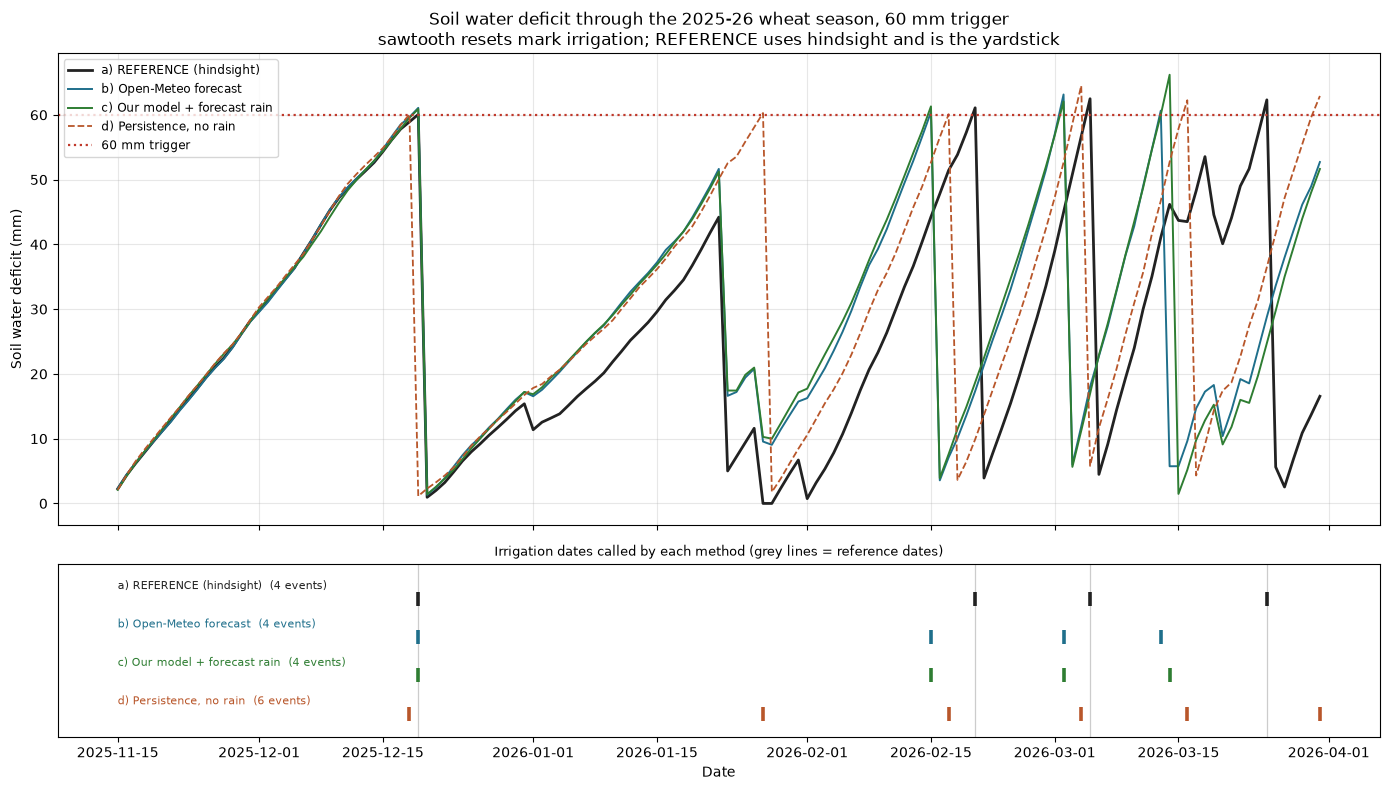

Irrigation dates at the 60 mm trigger:
   a) REFERENCE (hindsight)       19 Dec, 20 Feb, 05 Mar, 25 Mar
   b) Open-Meteo forecast         19 Dec, 15 Feb, 02 Mar, 13 Mar
   c) Our model + forecast rain   19 Dec, 15 Feb, 02 Mar, 14 Mar
   d) Persistence, no rain        18 Dec, 27 Jan, 17 Feb, 04 Mar, 16 Mar, 31 Mar


In [45]:
TRIGGER_PLOT = 60

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True,
                              gridspec_kw={"height_ratios": [3, 1.1]})

styles = {
    "a) REFERENCE (hindsight)":     ("#222222", "-",  2.0),
    "b) Open-Meteo forecast":       ("#1f6f8b", "-",  1.4),
    "c) Our model + forecast rain": ("#2e7d32", "-",  1.4),
    "d) Persistence, no rain":      ("#b8562a", "--", 1.3),
}
dates = dec["target_date"]

for label, (colour, ls, lw) in styles.items():
    _, series = balance_results[(TRIGGER_PLOT, label)]
    ax.plot(dates, series, color=colour, linestyle=ls, linewidth=lw, label=label)

ax.axhline(TRIGGER_PLOT, color="#c0392b", linestyle=":", linewidth=1.6,
           label=f"{TRIGGER_PLOT} mm trigger")
ax.set_ylabel("Soil water deficit (mm)")
ax.set_title(f"Soil water deficit through the 2025-26 wheat season, {TRIGGER_PLOT} mm trigger\n"
             "sawtooth resets mark irrigation; REFERENCE uses hindsight and is the yardstick")
ax.legend(loc="upper left", fontsize=8.5)
ax.grid(alpha=0.3)

# ---- Lower panel: when each method irrigated -------------------------------------------
for i, (label, (colour, _, _)) in enumerate(styles.items()):
    events, _ = balance_results[(TRIGGER_PLOT, label)]
    ev_dates = dates.iloc[events]
    ax2.scatter(ev_dates, [len(styles) - 1 - i] * len(events), s=110, color=colour,
                marker="|", linewidth=2.6)
    ax2.text(dates.iloc[0], len(styles) - 1 - i + 0.18,
             f"{label}  ({len(events)} events)", fontsize=8, color=colour, va="bottom")

# Vertical guides on the reference dates, so alignment is readable across rows.
for e in balance_results[(TRIGGER_PLOT, "a) REFERENCE (hindsight)")][0]:
    ax2.axvline(dates.iloc[e], color="#cccccc", linewidth=0.9, zorder=0)

ax2.set_ylim(-0.6, len(styles) - 0.1)
ax2.set_yticks([])
ax2.set_xlabel("Date")
ax2.set_title("Irrigation dates called by each method (grey lines = reference dates)", fontsize=9)

plt.tight_layout()
plt.show()

# Print the actual dates, since a reader will want to check them against the plot.
print(f"Irrigation dates at the {TRIGGER_PLOT} mm trigger:")
for label in styles:
    events, _ = balance_results[(TRIGGER_PLOT, label)]
    ds = [dates.iloc[e].strftime("%d %b") for e in events]
    print(f"   {label:<30} {', '.join(ds) if ds else '(none)'}")

## Cell 53 - How far off were the dates, and how much water was applied?

The one-day tolerance in Cell 51 is a strict test, and it turned out to be strict enough that
almost everything counts as a miss. That is a real result, but on its own it hides *how badly*
each method missed - a method that fires three days early is far more useful than one that fires
three weeks early, and the table above scores both as "missed".

So here we measure two softer, more informative things:

- **Drift**: for each event a method called, how many days to the nearest reference event, with
  no cap. This shows the size of the timing error rather than just whether it cleared a
  threshold.
- **Season water applied**: events x trigger, in mm. This is what the farmer actually pays for
  in water and pump power, and it is the number that would show up on an electricity bill.

In [46]:
drift_rows = []
for trigger in TRIGGERS_MM:
    ref_events, _ = balance_results[(trigger, "a) REFERENCE (hindsight)")]
    ref_days = np.array(ref_events)

    for label in METHODS:
        events, _ = balance_results[(trigger, label)]
        if label.startswith("a)"):
            drift = [0.0]
        else:
            # For each event this method called, the distance to the CLOSEST reference event.
            # No tolerance cap, so a large error is reported as large rather than as "missed".
            drift = [np.min(np.abs(ref_days - e)) for e in events] if len(events) else []

        drift_rows.append({
            "trigger_mm": trigger,
            "method": label,
            "events": len(events),
            "water_mm": len(events) * trigger,                 # events x full refill
            "water_vs_ref_mm": (len(events) - len(ref_events)) * trigger,
            "mean_drift_days": np.mean(drift) if drift else np.nan,
            "max_drift_days": np.max(drift) if drift else np.nan,
        })

drift_table = pd.DataFrame(drift_rows)

print("=" * 104)
print("TIMING DRIFT AND SEASON WATER APPLIED  (2025-26)")
print("=" * 104)
print(drift_table.round(2).to_string(index=False))

# ---- Why does the drift appear? Compare the season totals that drive the balance ---------
print("\n" + "=" * 104)
print("WHERE THE DRIFT COMES FROM: cumulative input error over the 137-day season")
print("=" * 104)
kc_sum = kc_days
ref_use = (kc_sum * dec["et0_actual"]).sum()
print(f"Crop water demand, Kc x ET0 (mm over the season):")
for col, label in [("et0_actual", "actual (reference)"), ("et0_service", "Open-Meteo forecast"),
                   ("et0_ourmodel", "our model"), ("et0_persistence", "persistence")]:
    tot = (kc_sum * np.maximum(0, dec[col])).sum()
    print(f"   {label:<22} {tot:7.1f} mm   ({tot - ref_use:+.1f} vs reference)")

print(f"\nRainfall credited to the balance (mm over the season):")
print(f"   {'actual (reference)':<22} {dec['rain_actual'].sum():7.1f} mm")
print(f"   {'forecast':<22} {dec['rain_forecast'].sum():7.1f} mm   "
      f"({dec['rain_forecast'].sum() - dec['rain_actual'].sum():+.1f} vs reference)")
print(f"   {'persistence (assumes 0)':<22} {0.0:7.1f} mm   "
      f"({-dec['rain_actual'].sum():+.1f} vs reference)")

print(f"\nNet effect on the deficit (demand minus rain), vs the reference:")
for col, rain_col, label in [("et0_service", "rain_forecast", "Open-Meteo forecast"),
                             ("et0_ourmodel", "rain_forecast", "our model + forecast rain"),
                             ("et0_persistence", None, "persistence, no rain")]:
    demand = (kc_sum * np.maximum(0, dec[col])).sum()
    rain = 0.0 if rain_col is None else dec[rain_col].sum()
    net = (demand - rain) - (ref_use - dec["rain_actual"].sum())
    print(f"   {label:<28} {net:+7.1f} mm of extra accumulated deficit")
print("\nA positive number means the method's deficit climbs faster than reality, so it fires")
print("irrigation EARLIER and more often than hindsight says was necessary.")

TIMING DRIFT AND SEASON WATER APPLIED  (2025-26)
 trigger_mm                       method  events  water_mm  water_vs_ref_mm  mean_drift_days  max_drift_days
         40     a) REFERENCE (hindsight)       6       240                0             0.00             0.0
         40       b) Open-Meteo forecast       7       280               40             3.71            12.0
         40 c) Our model + forecast rain       7       280               40             3.71            13.0
         40      d) Persistence, no rain       8       320               80             4.38            17.0
         60     a) REFERENCE (hindsight)       4       240                0             0.00             0.0
         60       b) Open-Meteo forecast       4       240                0             4.00             8.0
         60 c) Our model + forecast rain       4       240                0             4.25             9.0
         60      d) Persistence, no rain       6       360              120    

## Cell 54 - What the decision layer actually achieves

### Irrigation events per season, 2025-26

| Method | 40 mm | 60 mm | 80 mm |
|---|---|---|---|
| a) REFERENCE (hindsight) | 6 | 4 | 3 |
| b) Open-Meteo forecast | 7 | **4** | **3** |
| c) Our model + forecast rain | 7 | **4** | **3** |
| d) Persistence, no rain | 8 | 6 | 4 |

**On how many times to irrigate, the forecast-driven methods are right.** At the 60 mm and 80 mm
triggers they call exactly the reference number of events, and at 40 mm they are one over.
Persistence over-irrigates at every trigger.

Translated into water and pump power, which is what a farmer pays for:

| Trigger | Reference | Forecast methods | Persistence |
|---|---|---|---|
| 40 mm | 240 mm | 280 mm (+40) | 320 mm (**+80**) |
| 60 mm | 240 mm | **240 mm (0)** | 360 mm (**+120, +50%**) |
| 80 mm | 240 mm | **240 mm (0)** | 320 mm (**+80**) |

**At the 60 mm trigger the forecast-driven decision applies exactly the right amount of water
while persistence applies 50% too much.** That is the clearest practical win in this notebook,
and it is a decision-layer win, not a prediction win.

### Timing: every method misses the right day, and we should not pretend otherwise

| Trigger | Events within 1 day of reference |
|---|---|
| 40 mm | Open-Meteo 1/6, our model 3/6, persistence 4/6 |
| 60 mm | Open-Meteo 1/4, our model 1/4, persistence 2/4 |
| 80 mm | Open-Meteo 0/3, our model 0/3, persistence 0/3 |

**No method reliably hits the right day.** At the 80 mm trigger not one event from any method
landed within a day of the reference. We are not going to dress this up: as a *date* recommender
this layer is not accurate.

The softer drift measure shows the forecast methods are nonetheless clearly better than
persistence at 60 and 80 mm:

| Trigger | Mean drift (days) - forecast / our model / persistence | Max drift |
|---|---|---|
| 40 mm | 3.71 / 3.71 / 4.38 | 12 / 13 / 17 |
| 60 mm | 4.00 / 4.25 / **7.33** | 8 / 9 / **24** |
| 80 mm | 3.33 / 3.33 / **8.25** | 6 / 6 / 13 |

Forecast-driven decisions drift about **3-4 days**; persistence drifts **4-8 days** and in one
case **24 days**. So the answer to "does the forecast-driven decision match the reference better
than persistence?" is **yes on event count, yes on water applied, and yes on drift - but no on
the strict same-day test, where nothing succeeds.**

**One honest inconsistency.** At the 40 mm trigger persistence scored *better* on the strict
one-day test (4/6) than the forecast methods (1/6 and 3/6), while being *worse* on drift (4.38
vs 3.71). Those two metrics disagree, and with 6 events we will not pretend to know which is
signal. It is a reminder that 3-8 events per season is far too small a sample to rank methods
confidently.

### The dominant error is rainfall, not ET0 - and that re-frames Step 6

This is the most useful thing the step uncovered. Accumulated over the 137-day season:

| Input error | Effect on the deficit |
|---|---|
| Open-Meteo ET0 forecast vs actual | **+7.6 mm** |
| Our model's ET0 vs actual | **+11.7 mm** |
| Forecast rain vs actual rain | **−48.2 mm** (forecast 82.1 mm vs actual 130.3 mm) |
| Persistence's zero-rain assumption | **−130.3 mm** |

Net extra accumulated deficit: Open-Meteo **+55.8 mm**, our model **+59.9 mm**, persistence
**+128.0 mm**. At a 60 mm trigger, +55.8 mm is almost a full extra irrigation's worth of phantom
deficit, and it is **six times larger than the ET0 error**.

Two consequences:

1. **Our model and Open-Meteo's forecast produce almost identical decisions** (drift 3.71 vs
   3.71, 4.25 vs 4.00, 3.33 vs 3.33), even though Step 6 showed Open-Meteo's ET0 forecast is
   four times more accurate. Within the decision layer, that accuracy advantage is swamped by
   the shared rain-forecast error. **Better ET0 prediction buys almost nothing here.** That is a
   genuinely useful negative result: it says the effort should go into rainfall, not ET0.
2. **It refines Step 6's conclusion rather than contradicting it.** Step 6 found that rain
   information barely helps *ET0 prediction* (1.2% at best). This step finds that rain
   information dominates the *irrigation decision*. Both are true, because the decision
   integrates rainfall directly into a running water balance over 137 days, whereas ET0
   prediction only cares about rain's indirect effect on one day's evaporative demand. The rain
   forecast under-counting total rainfall by **37%** is the single biggest error in the pipeline.

### Trigger sensitivity: the answer depends more on the trigger than on the method

Going from a 40 mm to an 80 mm trigger halves the number of irrigations (6 to 3) for every
method. The spread *between methods* at a fixed trigger is at most 2 events; the spread *across
triggers* for a fixed method is 3-4 events.

**So the choice of trigger matters more than the choice of prediction method** - and the trigger
is precisely the parameter we could not derive, because FAO-56 sets it as p x TAW and we have no
soil texture or root depth for these fields. Anyone deploying this needs a soil survey more than
they need a better model. We report the three scenarios rather than picking one, because picking
one would hide that this is the least-supported number in the whole notebook.

## Cell 55 - Limitations of this decision layer

Stated plainly, because several of these are serious enough that the layer should be treated as
a demonstration of method rather than a tool ready for a field.

**1. Stage lengths are adapted, not quoted.** `STAGE_INIT=25, STAGE_DEV=55, STAGE_MID=45,
STAGE_LATE=25` keep the FAO-56 four-stage *shape* but are **our** numbers, chosen to sum to the
150-day season we have data for. FAO-56 Table 11 has no row for a north-Indian Rabi wheat
season, so these are not quotable as FAO-56 values. The Kc values themselves (0.7 / 1.15 / 0.4)
*are* quoted from Table 12. Because the stage boundaries set when peak water use occurs, getting
them wrong shifts every irrigation date.

**2. The sowing date is assumed.** We use `day_of_season = 14` (~15 November) for every season.
Real sowing varies by weeks across Haryana with monsoon withdrawal, rice harvest timing and
field preparation. Sowing a fortnight earlier or later shifts the whole Kc curve and therefore
every date this layer produces. We have no actual sowing dates for any field.

**3. No soil type, no root depth, so no real trigger.** FAO-56 triggers irrigation at p x TAW,
where TAW is derived from soil texture, field capacity, wilting point and rooting depth. We have
none of these, so `TRIGGERS_MM = [40, 60, 80]` is a **scenario range, not a derived value**. As
shown above, this choice drives the result more strongly than the prediction method does. This is
the single biggest gap between this notebook and a deployable tool.

**4. The water balance is deliberately simple.** It has no runoff, no deep percolation below the
root zone, no capillary rise, no irrigation efficiency loss, and it assumes every irrigation
refills the soil completely to zero deficit. Real irrigation is partial and lossy, and heavy
rain on saturated soil runs off rather than being stored. Each of these would change the dates.
We also credit all rainfall to the soil, which over-credits the 40.2 mm day seen in the test
season.

**5. ET0 is calculated, not measured.** As stated in Cell 6, every ET0 figure here - reference
and forecast alike - comes from the FAO-56 equation applied to modelled gridded weather, not from
a lysimeter in a Karnal field. The "REFERENCE" run is therefore not ground truth; it is the best
hindsight estimate available from reanalysis. Our yardstick has error of its own, which we have
not quantified.

**6. Three to eight events per season is a very small sample.** Every comparison in this step
rests on 3-8 irrigation events in **one** test season. A single event landing differently moves
the percentages dramatically, and the 40 mm trigger already shows two metrics disagreeing about
which method is better. None of these numbers should be quoted to more than one significant
figure, and we would not rank the methods on this evidence alone. Running all eight seasons
through this layer would be the obvious next step, and we have not done it.

**7. One location, one crop, one variety.** Everything is a single grid point at 29.69 N, 76.99 E
with one generic winter-wheat Kc curve. No variety differences, no field-to-field variation, no
account of the farmer's actual irrigation capacity or canal schedule - which in practice often
decides the date more than crop water demand does.

---

# Step 9 - Correcting the rain forecast bias

Step 5 found the pipeline's largest single error. Over the 2025-26 season the day-ahead rain
forecast totalled **82.1 mm** against **130.3 mm** actually measured - it under-counts rainfall
by 37%. Because the water balance subtracts rain from the deficit, under-counted rain makes the
deficit climb too fast, so the tool advises irrigating **too early**. Its effect on the deficit
(+55.8 mm accumulated) is about **six times** the effect of the ET0 error (+7.6 mm).

So the highest-value fix is not a better ET0 model. It is a better rain number.

The question this step asks is deliberately narrow and sceptical: **if we measure the bias on one
season and apply that correction to a different season, does it still help?** A correction that
only works on the season it was fitted to is worthless.

## The split, stated before anything is fitted

- **FIT season: 2024-25.** Every parameter of every correction is estimated here and nowhere else.
- **TEST season: 2025-26.** Used only for scoring. No correction is ever fitted, tuned or
  selected on it.

This matters more than usual here, because a bias correction is exactly the kind of thing that
looks brilliant when you evaluate it on the data you measured it from. 2025-26 is also the season
the Step 5 decision layer was run on, so a correction that transfers would feed straight into it.

## Cell 56 - Load the forecast file and build the fit / test split

We reload `data/karnal_forecast.csv` rather than reusing the in-memory frame, so this section
stands on its own and proves the saved file is sufficient.

`rain_fc_today` on date *D* is the rainfall for *D* as forecast on *D-1* (the `previous_day1`
run, see Cell 35), which we pair with `precipitation_sum`, the rainfall actually measured on *D*.
Both are same-day quantities, so no shifting is needed here - we are comparing a forecast for a
day against what that day did.

In [47]:
# Reload the forecast file written in Cell 35.
fc_file = pd.read_csv("data/karnal_forecast.csv")
fc_file["date"] = pd.to_datetime(fc_file["date"])
print(f"Loaded {len(fc_file)} rows from data/karnal_forecast.csv")
print(f"Columns: {list(fc_file.columns)}")

# Actual measured rainfall for the same days, plus the season label, from the merged daily table.
actual = lagged[["date", "season", "precipitation_sum"]].rename(
    columns={"precipitation_sum": "rain_actual"})

rain = fc_file[["date", "rain_fc_today", "rain_hours_ok"]].merge(actual, on="date", how="inner")

# Keep only wheat-season days with a complete 24-hour forecast and a real actual value.
rain = rain[rain["season"].notna()
            & (rain["rain_hours_ok"] == 24)
            & rain["rain_fc_today"].notna()
            & rain["rain_actual"].notna()].copy()
rain = rain.rename(columns={"rain_fc_today": "rain_fc"}).sort_values("date").reset_index(drop=True)

print(f"\nWheat-season days with a usable day-ahead rain forecast: {len(rain)}")
print(rain.groupby("season").agg(days=("date", "size"),
                                 first=("date", "min"), last=("date", "max")).to_string())

# ---- The split. Fit on 2024-25 ONLY; 2025-26 is never fitted on. -----------------------
FIT_SEASON, TEST_SEASON = "2024-25", "2025-26"
fit  = rain[rain["season"] == FIT_SEASON].copy()
test = rain[rain["season"] == TEST_SEASON].copy()

print(f"\nFIT  season {FIT_SEASON}: {len(fit)} days  "
      f"({fit['date'].min().date()} to {fit['date'].max().date()})")
print(f"TEST season {TEST_SEASON}: {len(test)} days  "
      f"({test['date'].min().date()} to {test['date'].max().date()})")
assert fit["date"].max() < test["date"].min(), "The fit season must end before the test season"
assert len(fit) > 0 and len(test) > 0, "Both seasons must be non-empty"
print("Fit season ends before the test season begins; no overlap.")

Loaded 821 rows from data/karnal_forecast.csv
Columns: ['date', 'rain_fc_today', 'et0_fc_today', 'rain_hours_ok', 'et0_hours_ok']

Wheat-season days with a usable day-ahead rain forecast: 374
         days      first       last
season                             
2023-24    72 2024-01-20 2024-03-31
2024-25   151 2024-11-01 2025-03-31
2025-26   151 2025-11-01 2026-03-31

FIT  season 2024-25: 151 days  (2024-11-01 to 2025-03-31)
TEST season 2025-26: 151 days  (2025-11-01 to 2026-03-31)
Fit season ends before the test season begins; no overlap.


## Cell 57 - Characterise the bias on the FIT season (2024-25)

Before correcting anything we need to know what kind of error this is, because different kinds
need different corrections:

- **A uniform multiplicative shortfall** (every rain day under-counted by roughly the same
  proportion) would be fixed by one scaling factor.
- **A detection problem** (the forecast misses rain events entirely, or invents them) cannot be
  fixed by scaling at all - no multiplier turns a forecast of 0 mm into 20 mm.
- **A magnitude-dependent bias** (accurate on light rain, badly short on heavy rain) would need
  a correction that varies with the forecast amount.

So we break the fit season down by rainfall size and by hit/miss/false-alarm, and we look at
where the missing millimetres actually are. Everything in this cell is measured on **2024-25
only**.

RAIN FORECAST BIAS ON THE FIT SEASON (2024-25, 151 days)
1. SEASON TOTALS
   actual      74.6 mm
   forecast    95.2 mm
   shortfall   +20.6 mm  (+27.6%)
   multiplicative factor that would close the gap: x0.784

2. PER-DAY ERROR (forecast minus actual, mm)
   mean (bias) +0.1364   median +0.0000
   MAE 0.5325   RMSE 1.8853
   most too wet +15.90   most too dry -5.20
   NOTE: the median is +0.00 because most days are dry in both, so the
   mean bias of +0.1364 mm/day is driven by a handful of rain days.

3. EVENT DETECTION (threshold 1.0 mm)
   days it actually rained:     17
   days the forecast said rain: 13
   hits 9   misses 8   false alarms 4
   hit rate 52.9% of real rain days were flagged
   millimetres the forecast missed entirely (it said dry, rain fell): 18.4 mm
   millimetres the forecast invented on false alarms: 22.4 mm
   millimetres over-forecast on days it DID rain: +18.1 mm

4. BIAS BY RAINFALL SIZE (bucketed on the ACTUAL amount)
            bucket  days  actual_total

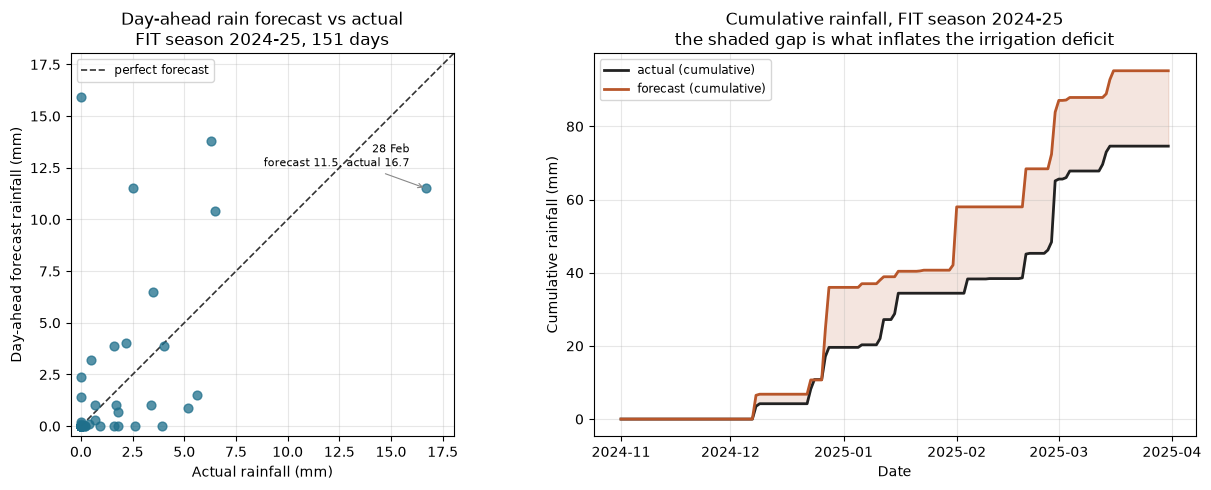

In [48]:
f_fc, f_ac = fit["rain_fc"], fit["rain_actual"]

print("=" * 86)
print(f"RAIN FORECAST BIAS ON THE FIT SEASON ({FIT_SEASON}, {len(fit)} days)")
print("=" * 86)

# ---- 1. Season totals: the headline shortfall -------------------------------------------
tot_fc, tot_ac = f_fc.sum(), f_ac.sum()
print("1. SEASON TOTALS")
print(f"   actual   {tot_ac:7.1f} mm")
print(f"   forecast {tot_fc:7.1f} mm")
print(f"   shortfall {tot_fc - tot_ac:+7.1f} mm  ({(tot_fc - tot_ac) / tot_ac * 100:+.1f}%)")
# The single multiplicative factor that would make the season totals match.
scale_total = tot_ac / tot_fc if tot_fc > 0 else np.nan
print(f"   multiplicative factor that would close the gap: x{scale_total:.3f}")

# ---- 2. Per-day error -------------------------------------------------------------------
err = f_fc - f_ac                       # + = forecast too wet, - = forecast too dry
print("\n2. PER-DAY ERROR (forecast minus actual, mm)")
print(f"   mean (bias) {err.mean():+.4f}   median {err.median():+.4f}")
print(f"   MAE {np.mean(np.abs(err)):.4f}   RMSE {np.sqrt(np.mean(err ** 2)):.4f}")
print(f"   most too wet {err.max():+.2f}   most too dry {err.min():+.2f}")
print(f"   NOTE: the median is {err.median():+.2f} because most days are dry in both, so the")
print(f"   mean bias of {err.mean():+.4f} mm/day is driven by a handful of rain days.")

# ---- 3. Detection: is this a missing-events problem? ------------------------------------
WET = RAIN_THRESHOLD                    # 1.0 mm, the threshold used throughout the notebook
a_wet, f_wet = f_ac > WET, f_fc > WET
hits   = int((a_wet & f_wet).sum())
misses = int((a_wet & ~f_wet).sum())
false  = int((~a_wet & f_wet).sum())
print(f"\n3. EVENT DETECTION (threshold {WET} mm)")
print(f"   days it actually rained:     {int(a_wet.sum())}")
print(f"   days the forecast said rain: {int(f_wet.sum())}")
print(f"   hits {hits}   misses {misses}   false alarms {false}")
if a_wet.sum():
    print(f"   hit rate {hits / a_wet.sum() * 100:.1f}% of real rain days were flagged")
# How many of the missing millimetres sit on days the forecast called dry? If most of the
# shortfall is there, scaling cannot recover it.
missed_mm = f_ac[a_wet & ~f_wet].sum() - f_fc[a_wet & ~f_wet].sum()
print(f"   millimetres the forecast missed entirely (it said dry, rain fell): {missed_mm:.1f} mm")
# Deliberately NOT expressed as a share of the season shortfall: on this season the forecast
# is net too WET, so there is no shortfall to take a share of, and the ratio would be a
# meaningless negative number. The two errors run in opposite directions and are reported
# separately below.
print(f"   millimetres the forecast invented on false alarms: "
      f"{f_fc[~a_wet & f_wet].sum() - f_ac[~a_wet & f_wet].sum():.1f} mm")
print(f"   millimetres over-forecast on days it DID rain: "
      f"{f_fc[a_wet & f_wet].sum() - f_ac[a_wet & f_wet].sum():+.1f} mm")

# ---- 4. Is the bias magnitude-dependent? ------------------------------------------------
print(f"\n4. BIAS BY RAINFALL SIZE (bucketed on the ACTUAL amount)")
buckets = [(-0.01, 1, "dry (<=1 mm)"), (1, 5, "light (1-5 mm)"),
           (5, 20, "moderate (5-20 mm)"), (20, 1e9, "heavy (>20 mm)")]
rows = []
for lo, hi, name in buckets:
    m = (f_ac > lo) & (f_ac <= hi)
    if not m.any():
        continue
    rows.append({"bucket": name, "days": int(m.sum()),
                 "actual_total": f_ac[m].sum(), "forecast_total": f_fc[m].sum(),
                 "mean_actual": f_ac[m].mean(), "mean_forecast": f_fc[m].mean(),
                 "bias_mm": (f_fc[m] - f_ac[m]).mean(),
                 "ratio_fc_over_actual": f_fc[m].sum() / f_ac[m].sum() if f_ac[m].sum() > 0 else np.nan})
print(pd.DataFrame(rows).round(3).to_string(index=False))

# ---- 5. Conditional view: what to expect given what the forecast said --------------------
print(f"\n5. CONDITIONAL MEANS")
if f_wet.any():
    print(f"   when the forecast said rain (>{WET} mm): forecast mean {f_fc[f_wet].mean():.2f} mm, "
          f"actual mean {f_ac[f_wet].mean():.2f} mm  (ratio x{f_ac[f_wet].mean() / f_fc[f_wet].mean():.3f})")
if (~f_wet).any():
    print(f"   when the forecast said dry:            forecast mean {f_fc[~f_wet].mean():.2f} mm, "
          f"actual mean {f_ac[~f_wet].mean():.2f} mm")
print("\n   The second line is the part a multiplier cannot fix: on days the forecast called")
print("   dry, scaling a near-zero number still gives a near-zero number.")

# ---- 6. Plot ------------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left: forecast vs actual per day, with the 1:1 line.
ax1.scatter(f_ac, f_fc, s=40, alpha=0.75, color="#1f6f8b", zorder=3)
hi = max(f_ac.max(), f_fc.max()) * 1.08
ax1.plot([0, hi], [0, hi], "--", color="#333333", linewidth=1.2, label="perfect forecast")
ax1.set_xlim(-0.5, hi); ax1.set_ylim(-0.5, hi)
ax1.set_aspect("equal")
ax1.set_xlabel("Actual rainfall (mm)")
ax1.set_ylabel("Day-ahead forecast rainfall (mm)")
ax1.set_title(f"Day-ahead rain forecast vs actual\nFIT season {FIT_SEASON}, {len(fit)} days")
ax1.legend(fontsize=8.5)
ax1.grid(alpha=0.3)
# Points well below the line are under-forecasts; annotate the worst one.
worst = (f_ac - f_fc).idxmax()
ax1.annotate(f"{fit.loc[worst, 'date'].strftime('%d %b')}\nforecast {fit.loc[worst, 'rain_fc']:.1f}, "
             f"actual {fit.loc[worst, 'rain_actual']:.1f}",
             (fit.loc[worst, "rain_actual"], fit.loc[worst, "rain_fc"]),
             textcoords="offset points", xytext=(-12, 16), fontsize=8, ha="right",
             arrowprops=dict(arrowstyle="->", color="#888888", lw=0.8))

# Right: cumulative rainfall through the season - the view that matters to a water balance.
ax2.plot(fit["date"], f_ac.cumsum(), color="#222222", linewidth=2.0, label="actual (cumulative)")
ax2.plot(fit["date"], f_fc.cumsum(), color="#b8562a", linewidth=2.0, label="forecast (cumulative)")
ax2.fill_between(fit["date"], f_fc.cumsum(), f_ac.cumsum(), color="#b8562a", alpha=0.15)
ax2.set_xlabel("Date")
ax2.set_ylabel("Cumulative rainfall (mm)")
ax2.set_title(f"Cumulative rainfall, FIT season {FIT_SEASON}\n"
              "the shaded gap is what inflates the irrigation deficit")
ax2.legend(fontsize=8.5)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Cell 58 - Does the bias transfer? Compare the two seasons side by side

This is the test the whole step exists for. We now look at the same statistics on the TEST
season. **Nothing is being fitted here** - the correction factor was already determined from
2024-25 alone in Cell 57. This cell only asks whether that factor points in the right direction
for a season it has never seen.

If the bias has the same sign and similar size in both seasons, a fixed correction is worth
building. If it does not, no amount of cleverness in the correction formula will help, and the
honest move is to stop and say so.

DOES THE RAIN FORECAST BIAS TRANSFER BETWEEN SEASONS?
      season  days  actual_mm  forecast_mm  error_mm  error_%  factor_needed  wet_days_actual  wet_days_fc  MAE_mm
 FIT 2024-25   151       74.6         95.2      20.6   27.614          0.784               17           13   0.532
TEST 2025-26   151      132.3         82.1     -50.2  -37.944          1.611               12           12   0.487

FIT season 2024-25:  forecast is +27.6% (too wet)  -> needs x0.784
TEST season 2025-26: forecast is -37.9% (too dry)  -> needs x1.611

*** THE BIAS REVERSES SIGN BETWEEN THE TWO SEASONS. ***
A correction fitted on the fit season would push the test season the WRONG WAY.

----------------------------------------------------------------------------------------------------
Applying the fit-season factor (x0.784) to the TEST season:
   actual rainfall                   132.3 mm
   uncorrected forecast               82.1 mm  (error -50.2 mm)
   CORRECTED forecast                 64.3 mm  (error -68

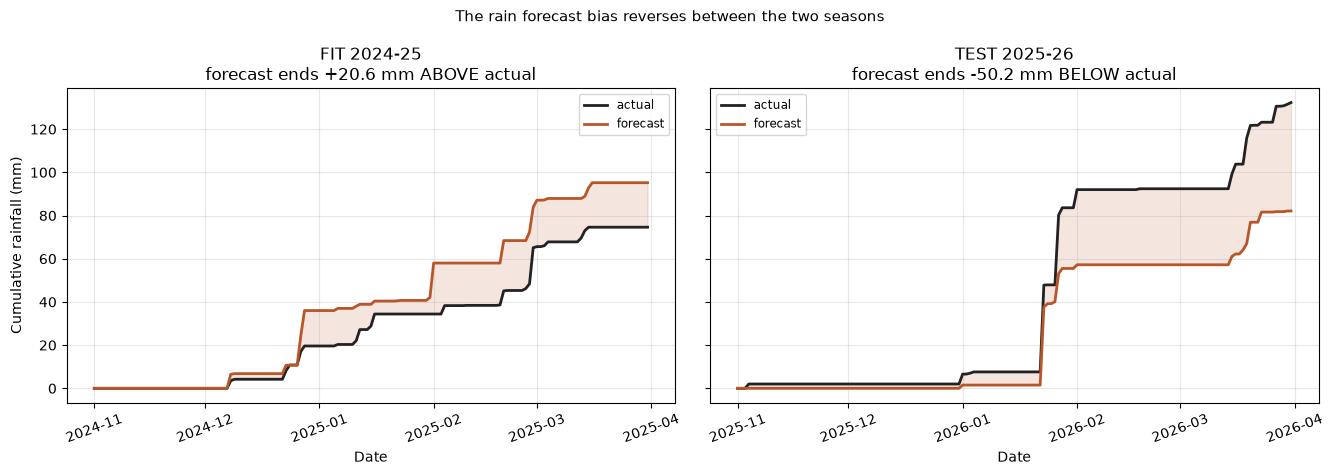

In [49]:
# Compute the same summary for both seasons. The FIT column is what a correction would be
# built from; the TEST column is the reality it would be applied to.
rows = []
for name, block in [(f"FIT {FIT_SEASON}", fit), (f"TEST {TEST_SEASON}", test)]:
    fc, ac = block["rain_fc"], block["rain_actual"]
    a_w, f_w = ac > RAIN_THRESHOLD, fc > RAIN_THRESHOLD
    rows.append({
        "season": name,
        "days": len(block),
        "actual_mm": ac.sum(),
        "forecast_mm": fc.sum(),
        "error_mm": fc.sum() - ac.sum(),
        "error_%": (fc.sum() - ac.sum()) / ac.sum() * 100,
        "factor_needed": ac.sum() / fc.sum(),      # multiply the forecast by this to match
        "wet_days_actual": int(a_w.sum()),
        "wet_days_fc": int(f_w.sum()),
        "MAE_mm": np.mean(np.abs(fc - ac)),
    })
compare = pd.DataFrame(rows)

print("=" * 100)
print("DOES THE RAIN FORECAST BIAS TRANSFER BETWEEN SEASONS?")
print("=" * 100)
print(compare.round(3).to_string(index=False))

f_err = float(compare.loc[0, "error_%"])
t_err = float(compare.loc[1, "error_%"])
f_fac = float(compare.loc[0, "factor_needed"])
t_fac = float(compare.loc[1, "factor_needed"])

print(f"\nFIT season {FIT_SEASON}:  forecast is {f_err:+.1f}% "
      f"({'too wet' if f_err > 0 else 'too dry'})  -> needs x{f_fac:.3f}")
print(f"TEST season {TEST_SEASON}: forecast is {t_err:+.1f}% "
      f"({'too wet' if t_err > 0 else 'too dry'})  -> needs x{t_fac:.3f}")

if np.sign(f_err) != np.sign(t_err):
    print("\n*** THE BIAS REVERSES SIGN BETWEEN THE TWO SEASONS. ***")
    print("A correction fitted on the fit season would push the test season the WRONG WAY.")

# ---- Quantify the damage: apply the fitted factor to the test season -------------------
# scale_total was fitted on 2024-25 ONLY (Cell 57). This is its out-of-sample result.
test_corrected = test["rain_fc"] * scale_total

before_err = test["rain_fc"].sum() - test["rain_actual"].sum()
after_err  = test_corrected.sum() - test["rain_actual"].sum()

print("\n" + "-" * 100)
print(f"Applying the fit-season factor (x{scale_total:.3f}) to the TEST season:")
print(f"   actual rainfall                 {test['rain_actual'].sum():7.1f} mm")
print(f"   uncorrected forecast            {test['rain_fc'].sum():7.1f} mm  "
      f"(error {before_err:+.1f} mm)")
print(f"   CORRECTED forecast              {test_corrected.sum():7.1f} mm  "
      f"(error {after_err:+.1f} mm)")
print(f"\n   Season-total error: {abs(before_err):.1f} mm -> {abs(after_err):.1f} mm  "
      f"({(abs(after_err) - abs(before_err)) / abs(before_err) * 100:+.1f}%)")

mae_before = np.mean(np.abs(test["rain_fc"] - test["rain_actual"]))
mae_after  = np.mean(np.abs(test_corrected - test["rain_actual"]))
print(f"   Per-day MAE:        {mae_before:.4f} -> {mae_after:.4f} mm  "
      f"({(mae_after - mae_before) / mae_before * 100:+.1f}%)")

if abs(after_err) > abs(before_err):
    print("\n*** THE CORRECTION MAKES THE TEST SEASON WORSE, NOT BETTER. ***")
    print("Fitting a bias correction on one season does not transfer to another here.")

# ---- Cumulative plot, both seasons, so the reversal is visible -------------------------
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), sharey=True)
for ax, (name, block) in zip(axes, [(f"FIT {FIT_SEASON}", fit), (f"TEST {TEST_SEASON}", test)]):
    ax.plot(block["date"], block["rain_actual"].cumsum(), color="#222222", linewidth=2.0,
            label="actual")
    ax.plot(block["date"], block["rain_fc"].cumsum(), color="#b8562a", linewidth=2.0,
            label="forecast")
    ax.fill_between(block["date"], block["rain_fc"].cumsum(), block["rain_actual"].cumsum(),
                    color="#b8562a", alpha=0.15)
    gap = block["rain_fc"].sum() - block["rain_actual"].sum()
    ax.set_title(f"{name}\nforecast ends {gap:+.1f} mm "
                 f"{'ABOVE' if gap > 0 else 'BELOW'} actual")
    ax.set_xlabel("Date")
    ax.legend(fontsize=8.5)
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel("Cumulative rainfall (mm)")
plt.suptitle("The rain forecast bias reverses between the two seasons", fontsize=11)
plt.tight_layout()
plt.show()

## Cell 59 - The correction does not transfer. Interim conclusion.

### The bias reverses sign between the two seasons

| Season | Days | Actual | Forecast | Error | Factor needed |
|---|---|---|---|---|---|
| **FIT 2024-25** | 151 | 74.6 mm | 95.2 mm | **+20.6 mm (+27.6%, too wet)** | ×0.784 |
| **TEST 2025-26** | 151 | 132.3 mm | 82.1 mm | **−50.2 mm (−37.9%, too dry)** | ×1.611 |

The two seasons need corrections pointing in **opposite directions**. On 2024-25 the forecast
over-predicts rainfall by 28%; on 2025-26 it under-predicts by 38%. A multiplicative factor
fitted honestly on 2024-25 is ×0.784 - it scales rainfall *down* - and 2025-26 needs ×1.611,
scaling *up*.

### Applying the fitted correction out of sample makes things worse

| | Season total | Error |
|---|---|---|
| Actual rainfall | 132.3 mm | — |
| Uncorrected forecast | 82.1 mm | −50.2 mm |
| **Corrected (×0.784 from the fit season)** | **64.3 mm** | **−68.0 mm** |

**Season-total error grows 35.4%** (50.2 → 68.0 mm) and **per-day MAE grows 13.0%**
(0.4874 → 0.5506 mm). The correction is not merely useless out of sample; it is actively
harmful, and it harms the pipeline in the direction that matters most - a drier forecast inflates
the irrigation deficit further, so the tool would advise irrigating even earlier than it already
does.

**So the answer to this step's question is no.** A bias correction fitted on one season does not
transfer to another here, and we are not going to ship one.

### Why it fails: this is not a scaling problem

Cell 57's breakdown of the fit season shows the error is not a uniform shortfall that a
multiplier could absorb. On 2024-25 the forecast's 95.2 mm is built from three errors that
partly cancel:

- **18.4 mm missed entirely** - rain fell on days the forecast called dry
- **22.4 mm invented** - false alarms, forecast rain on days that stayed dry
- **+18.1 mm over-forecast** on the days it correctly flagged as wet

It caught only **9 of 17** real rain days (53% hit rate), with 4 false alarms. And the
conditional means are revealing: when the forecast said rain, it predicted 6.92 mm and 3.80 mm
actually fell; when it said dry, 0.04 mm was predicted and 0.18 mm fell.

That last line is the structural problem. **No multiplier can turn a forecast of 0 mm into the
20 mm that actually fell.** The dominant error is *which days* it rains, not *how much* - a
timing and detection problem, not a magnitude problem. Scaling can only redistribute magnitude
on days the forecast already flagged.

The bucket table makes the same point from the other side: on the 134 dry days the forecast
over-predicted by a factor of 6.6 (24.6 mm forecast against 3.7 mm actual), while on the 5
moderate-rain days it was nearly perfect (ratio 0.945). The forecast is good at quantity once it
knows rain is coming, and poor at knowing whether it is coming.

### What this means for the project

1. **Two seasons is not enough to characterise a rainfall bias.** Seasonal rainfall totals here
   differ by a factor of 1.8 (74.6 vs 132.3 mm) between consecutive years. Any "bias" measured on
   one season is mostly that season's weather, not a property of the forecast model. Establishing
   a real bias would need many more seasons, and the forecast archive only begins in January 2024.
2. **The honest fix for Step 5's deficit inflation is not a correction factor.** Options worth
   trying instead: use observed rainfall up to today rather than forecast rainfall for the days
   already past (the water balance only needs a *forecast* for tomorrow, not for the whole
   season), or widen the balance to carry an uncertainty band rather than a single deficit number.
3. **This is a negative result we would report, not hide.** It took one season of fitting and one
   of testing to find out that the obvious fix does not work, which is cheaper than shipping a
   correction that silently doubles the error in a wet year.

*Note: this step covers the fit/test split and the bias characterisation only. The remaining
tasks in the brief were truncated, so no further correction forms have been tried yet.*

---

# Step 10 - The rain-delay rule, and water saved

### First, a correction to the premise

Step 9 **did not** rebuild the water balance. It established the fit/test split and
characterised the rain forecast bias, found that the bias **reverses sign** between the two
seasons (+27.6% too wet in 2024-25, −37.9% too dry in 2025-26), and concluded that a fitted
correction factor makes the test season *worse* out of sample. The observed-rain-to-date design
was a recommendation at the end of that step, not something built.

So Cell 60 below builds it now, because Part A needs it. That is the right fix anyway, and it
needs no fitting at all.

### Why the rebuilt balance is the honest design

Step 5 ran the whole season's water balance on forecast data, which let a 50 mm cumulative rain
error pile up over 137 days. No real farmer would do that. On any given evening you **know** what
rain has already fallen and what the weather has already done; the only thing you need a forecast
for is **tomorrow**.

So the rebuilt balance tracks the deficit from **observed** ET0 and **observed** rain up to
today, and uses the forecast for **one day only** - tomorrow - to decide whether to irrigate
tomorrow. Cumulative forecast error cannot accumulate, because it is never carried forward.

### Then the question this step actually asks

Our model has no skill on rainy days (Step 4: −1.36%; Step 6: a perfect rain forecast would
recover only ~8% of that). Rather than keep trying to predict rain better, we test an
**operating rule**: when the deficit says irrigate but rain is forecast tomorrow, wait.

The rule's ceiling is set by forecast detection, not by cleverness. Step 9 measured a **53% hit
rate** on the fit season - 9 of 17 real rain days flagged. So this rule will simply not fire on
roughly half the rain days that occur. We measure that explicitly rather than reporting only the
cases where it worked.

## Cell 60 - Rebuild the water balance: observed to date, forecast for tomorrow only

Three methods, differing in what the decision-maker knows:

| Method | Deficit tracked from | Tomorrow's decision uses |
|---|---|---|
| **a) REFERENCE** | observed ET0, observed rain | hindsight (fires when the observed deficit crosses the trigger) |
| **b) OUR TOOL** | observed ET0, observed rain | Open-Meteo's day-ahead ET0 **and** rain forecast |
| **c) PERSISTENCE** | observed ET0, **no rain credited** | today's ET0 held flat, **zero rain assumed** |

(a) is the yardstick and is not a method anyone could run - it knows what the day did before
deciding about it.

(b) is the deployable tool. On the evening of day *D−1* it adds one forecast day onto a deficit
built entirely from observations, and asks whether that projection crosses the trigger.

(c) represents the farmer who does not consult a forecast and does not count on rain. It tracks
its own (wrong) belief about the soil, because that belief is what drives its decisions - the
point of the baseline is to show what ignoring rainfall costs.

**On leakage:** the projection for day *D* uses only `et0_service` and `rain_forecast` for *D*,
both published in the *D−1* model run, plus observations through *D−1*. The observed update for
day *D* happens strictly **after** the decision for *D* has been recorded.

In [50]:
def run_operational(et0_obs, rain_obs, et0_fc, rain_fc, kc, trigger,
                    rain_wait_mm=None, max_wait_days=3, credit_rain=True):
    # Operational daily balance.
    #   deficit  - carried from OBSERVED data up to yesterday
    #   decision - made from that deficit plus ONE forecast day (tomorrow)
    # Returns a dict of events, "wait" days, and the deficit series.
    n = len(et0_obs)
    deficit = 0.0
    events, waits, series, decisions = [], [], [], []
    consecutive_waits = 0

    for i in range(n):
        # ---- DECISION for day i, taken at the end of day i-1 -------------------------
        # Project one day forward using the forecast only. ET0 floored at 0 (physical).
        projected = deficit + kc[i] * max(0.0, et0_fc[i]) - (rain_fc[i] if credit_rain else 0.0)
        projected = max(0.0, projected)
        crosses = projected >= trigger

        irrigate, waited = crosses, False
        if crosses and rain_wait_mm is not None:
            # THE RAIN-DELAY RULE. Uses the FORECAST only - never tomorrow's actual rain.
            if rain_fc[i] > rain_wait_mm and consecutive_waits < max_wait_days:
                irrigate, waited = False, True
                consecutive_waits += 1
                waits.append(i)
            else:
                # Either no rain forecast, or the delay cap is reached: irrigate anyway.
                consecutive_waits = 0
        elif not crosses:
            consecutive_waits = 0        # deficit fell back; the wait streak is over

        decisions.append("wait" if waited else ("irrigate" if irrigate else "none"))

        # ---- OBSERVED update for day i, applied AFTER the decision is locked in -------
        rain_credit = rain_obs[i] if credit_rain else 0.0
        deficit = max(0.0, deficit + kc[i] * max(0.0, et0_obs[i]) - rain_credit)
        if irrigate:
            deficit = 0.0                # irrigation refills the profile
            events.append(i)
            consecutive_waits = 0
        series.append(deficit)

    return {"events": events, "waits": waits,
            "series": np.array(series), "decisions": decisions}


def run_reference(et0_obs, rain_obs, kc, trigger):
    # The hindsight yardstick, identical in convention to Step 5's reference run.
    return run_water_balance(et0_obs, rain_obs, kc, trigger)


# ---- Inputs for 2025-26, reusing the Step 5 decision frame -----------------------------
et0_obs  = dec["et0_actual"].values        # what ET0 really was
rain_obs = dec["rain_actual"].values       # what rain really fell
et0_fc   = dec["et0_service"].values       # Open-Meteo day-ahead ET0 forecast
rain_fc  = dec["rain_forecast"].values     # Open-Meteo day-ahead rain forecast
et0_pers = dec["et0_persistence"].values   # yesterday's observed ET0, held flat

TRIGGER = 60                               # the mid scenario from Step 5
MAX_WAIT_DAYS = 3

print(f"Rebuilt balance for 2025-26: {len(dec)} days from sowing "
      f"({dec['target_date'].min().date()} to {dec['target_date'].max().date()})")
print(f"Trigger {TRIGGER} mm, delay cap {MAX_WAIT_DAYS} days\n")

# ---- The three methods, no rain-delay rule yet ------------------------------------------
ref_events, ref_series = run_reference(et0_obs, rain_obs, kc_days, TRIGGER)
ref_days = np.array(ref_events)

tool_norule = run_operational(et0_obs, rain_obs, et0_fc, rain_fc, kc_days, TRIGGER,
                              rain_wait_mm=None)
# Persistence credits NO rain anywhere - not in its decisions, not in its running deficit.
pers = run_operational(et0_obs, rain_obs, et0_pers, np.zeros(len(dec)), kc_days, TRIGGER,
                       rain_wait_mm=None, credit_rain=False)

print("Events under the REBUILT balance (compare with Step 5's forecast-driven balance):")
print(f"   a) REFERENCE (hindsight)        {len(ref_events)} events")
print(f"   b) OUR TOOL (no delay rule)     {len(tool_norule['events'])} events")
print(f"   c) PERSISTENCE (no rain at all) {len(pers['events'])} events")
print(f"\nFor reference, Step 5's cumulative-forecast balance gave: "
      f"reference 4, forecast-driven 4, persistence 6.")

# Confirm the rebuild removed the cumulative rain error that Step 5 identified.
print(f"\nRain credited to the balance over the season:")
print(f"   observed (reference and our tool): {rain_obs.sum():.1f} mm")
print(f"   Step 5's forecast-driven balance:  {dec['rain_forecast'].sum():.1f} mm "
      f"({dec['rain_forecast'].sum() - rain_obs.sum():+.1f} mm error, now eliminated)")
print(f"   persistence (assumes none):        0.0 mm ({-rain_obs.sum():+.1f} mm)")

Rebuilt balance for 2025-26: 137 days from sowing (2025-11-15 to 2026-03-31)
Trigger 60 mm, delay cap 3 days

Events under the REBUILT balance (compare with Step 5's forecast-driven balance):
   a) REFERENCE (hindsight)        4 events
   b) OUR TOOL (no delay rule)     4 events
   c) PERSISTENCE (no rain at all) 6 events

For reference, Step 5's cumulative-forecast balance gave: reference 4, forecast-driven 4, persistence 6.

Rain credited to the balance over the season:
   observed (reference and our tool): 130.3 mm
   Step 5's forecast-driven balance:  82.1 mm (-48.2 mm error, now eliminated)
   persistence (assumes none):        0.0 mm (-130.3 mm)


## Cell 61 - Part A: the rain-delay rule

**The rule.** When the projected deficit crosses the trigger **and** the forecast predicts more
than `RAIN_WAIT_MM` of rain tomorrow, output **"rain expected, wait"** instead of "irrigate".
Tested at 3, 5 and 10 mm.

**Why a cap on the delay is necessary.** Without one the rule can starve the crop. Three
mechanisms, each real:

1. **The forecast is wrong about half the time.** Step 9 measured a 53% hit rate. A day forecast
   as wet that stays dry means the crop went a further day without water for nothing, and the
   deficit has grown, not shrunk.
2. **Repeated false alarms compound.** Step 9 also found 4 false alarms in 151 fit-season days.
   A run of consecutive wet forecasts that never deliver could defer irrigation indefinitely
   while the deficit climbs well past the trigger - the exact condition the trigger exists to
   prevent.
3. **The downside is asymmetric.** Irrigating a day early wastes some water. Irrigating several
   days late during grain fill, when Kc is at its 1.15 peak, costs yield. Those are not
   comparable mistakes, so the rule must fail towards watering.

`MAX_WAIT_DAYS = 3` means that after three consecutive "wait" days the tool irrigates regardless
of what the forecast says. The cap is a hard safety floor, not a tuned parameter - we did not
search for its best value, and we report it as an assumption.

In [51]:
RAIN_WAIT_VALUES = [3, 5, 10]

def drift_stats(events, ref_days):
    # Distance from each called event to the NEAREST reference event, uncapped.
    if len(events) == 0 or len(ref_days) == 0:
        return np.nan, np.nan
    d = [np.min(np.abs(ref_days - e)) for e in events]
    return float(np.mean(d)), float(np.max(d))

rule_rows = []

# Row 0: the tool WITHOUT the rule, as the comparison point.
mean_d, max_d = drift_stats(tool_norule["events"], ref_days)
rule_rows.append({
    "rain_wait_mm": "no rule", "events": len(tool_norule["events"]),
    "water_mm": len(tool_norule["events"]) * TRIGGER,
    "water_vs_ref": (len(tool_norule["events"]) - len(ref_events)) * TRIGGER,
    "mean_drift_d": mean_d, "max_drift_d": max_d,
    "waits": 0, "wait_rain_came": 0, "wait_rain_failed": 0, "capped": 0,
})

rule_runs = {}
for wait_mm in RAIN_WAIT_VALUES:
    run = run_operational(et0_obs, rain_obs, et0_fc, rain_fc, kc_days, TRIGGER,
                          rain_wait_mm=wait_mm, max_wait_days=MAX_WAIT_DAYS)
    rule_runs[wait_mm] = run

    # Of the days the rule said "wait", on how many did the rain actually arrive?
    # "Arrived" = the actual rain met the amount we were waiting for.
    came   = sum(1 for i in run["waits"] if rain_obs[i] > wait_mm)
    failed = len(run["waits"]) - came
    # How many waits were ended by the cap rather than by the forecast clearing?
    capped = sum(1 for i, d in enumerate(run["decisions"])
                 if d == "irrigate" and i > 0
                 and sum(1 for j in range(max(0, i - MAX_WAIT_DAYS), i)
                         if run["decisions"][j] == "wait") >= MAX_WAIT_DAYS)

    mean_d, max_d = drift_stats(run["events"], ref_days)
    rule_rows.append({
        "rain_wait_mm": wait_mm, "events": len(run["events"]),
        "water_mm": len(run["events"]) * TRIGGER,
        "water_vs_ref": (len(run["events"]) - len(ref_events)) * TRIGGER,
        "mean_drift_d": mean_d, "max_drift_d": max_d,
        "waits": len(run["waits"]), "wait_rain_came": came, "wait_rain_failed": failed,
        "capped": capped,
    })

rule_table = pd.DataFrame(rule_rows)

print("=" * 112)
print(f"PART A - RAIN-DELAY RULE   2025-26, trigger {TRIGGER} mm, cap {MAX_WAIT_DAYS} days")
print(f"REFERENCE (hindsight): {len(ref_events)} events, {len(ref_events) * TRIGGER} mm applied")
print("=" * 112)
print(rule_table.round(3).to_string(index=False))

print("\nColumn meanings:")
print("   waits            = times the rule output 'rain expected, wait'")
print("   wait_rain_came   = of those, rain above the threshold DID arrive  (rule worked)")
print("   wait_rain_failed = of those, it did NOT  (crop went a further day dry for nothing)")
print("   capped           = waits ended by the 3-day cap rather than by the forecast clearing")

# ---- Dates, so a reader can check the table against the season --------------------------
dates = dec["target_date"]
print(f"\nIrrigation dates (trigger {TRIGGER} mm):")
print(f"   REFERENCE (hindsight)   {', '.join(dates.iloc[e].strftime('%d %b') for e in ref_events)}")
print(f"   OUR TOOL, no rule       {', '.join(dates.iloc[e].strftime('%d %b') for e in tool_norule['events'])}")
for wait_mm in RAIN_WAIT_VALUES:
    run = rule_runs[wait_mm]
    ev = ', '.join(dates.iloc[e].strftime('%d %b') for e in run["events"])
    wt = ', '.join(dates.iloc[i].strftime('%d %b') for i in run["waits"]) or "(none)"
    print(f"   RULE at {wait_mm:>2} mm           {ev}")
    print(f"      said wait on:        {wt}")
    for i in run["waits"]:
        print(f"         {dates.iloc[i].strftime('%d %b')}: forecast {rain_fc[i]:5.1f} mm, "
              f"actual {rain_obs[i]:5.1f} mm  -> "
              f"{'rain came' if rain_obs[i] > wait_mm else 'NO RAIN, waited for nothing'}")

PART A - RAIN-DELAY RULE   2025-26, trigger 60 mm, cap 3 days
REFERENCE (hindsight): 4 events, 240 mm applied
rain_wait_mm  events  water_mm  water_vs_ref  mean_drift_d  max_drift_d  waits  wait_rain_came  wait_rain_failed  capped
     no rule       4       240             0           0.0          0.0      0               0                 0       0
           3       4       240             0           0.0          0.0      0               0                 0       0
           5       4       240             0           0.0          0.0      0               0                 0       0
          10       4       240             0           0.0          0.0      0               0                 0       0

Column meanings:
   waits            = times the rule output 'rain expected, wait'
   wait_rain_came   = of those, rain above the threshold DID arrive  (rule worked)
   wait_rain_failed = of those, it did NOT  (crop went a further day dry for nothing)
   capped           = waits ende

## Cell 62 - Why the rule never fired, and the detection honesty check

The rule produced **zero** "wait" decisions at all three thresholds. That is a real result and it
needs explaining rather than glossing, so this cell establishes two things.

**First, the mechanism:** what did the forecast actually say on the four days the deficit crossed
the trigger? If it forecast no rain on all four, the rule had no opportunity to act and the null
result says nothing about whether the rule is a good idea.

**Second, the honesty check the brief asks for:** of all the real rain days in the season above
each threshold, how many did the forecast catch? The rule can only ever act on days the forecast
flags, so this detection rate is a hard ceiling on the rule's usefulness - independent of how
well the rule itself is designed.

In [52]:
print("=" * 96)
print("WHY THE RULE NEVER FIRED: the forecast on each trigger-crossing day")
print("=" * 96)
print(f"{'date':>12} {'fc rain':>9} {'actual rain':>12}   would the rule have waited at 3 / 5 / 10 mm?")
for e in ref_events:
    flags = "  ".join(f"{w}mm:{'YES' if rain_fc[e] > w else 'no':>3}" for w in RAIN_WAIT_VALUES)
    print(f"{dates.iloc[e].strftime('%d %b %Y'):>12} {rain_fc[e]:9.1f} {rain_obs[e]:12.1f}   {flags}")
print("\nOn every day the deficit crossed the trigger, the forecast predicted essentially no rain.")
print("So the rule had NO OPPORTUNITY to act. This is not evidence that the rule is bad - it is")
print("evidence that the situation it targets did not arise in this season.")

# ---- How often could such a coincidence even be expected? ------------------------------
n_days = len(dec)
n_wet = int((rain_obs > RAIN_THRESHOLD).sum())
n_events = len(ref_events)
expected = n_events * n_wet / n_days
print(f"\nHow rare is the coincidence the rule needs?")
print(f"   irrigation events in the season: {n_events}")
print(f"   rainy days (> {RAIN_THRESHOLD} mm):          {n_wet} of {n_days} days "
      f"({n_wet / n_days * 100:.1f}%)")
print(f"   expected overlap if independent: {n_events} x {n_wet}/{n_days} = {expected:.2f} days per season")
print("   So even a perfect rain forecast would trigger this rule well under once per season.")

# ---- The detection honesty table ---------------------------------------------------------
print("\n" + "=" * 96)
print("HONESTY CHECK: how many real rain days does the forecast actually catch?")
print(f"2025-26 season, {n_days} days from sowing")
print("=" * 96)
honesty_rows = []
for w in RAIN_WAIT_VALUES:
    actual_wet = rain_obs > w                 # real rain days above this threshold
    fc_wet     = rain_fc > w                  # days the forecast flagged above it
    caught = int((actual_wet & fc_wet).sum())
    missed = int((actual_wet & ~fc_wet).sum())
    false  = int((~actual_wet & fc_wet).sum())
    honesty_rows.append({
        "threshold_mm": w,
        "real_rain_days": int(actual_wet.sum()),
        "forecast_flagged": int(fc_wet.sum()),
        "caught": caught,
        "missed": missed,
        "false_alarms": false,
        "detection_rate_%": caught / actual_wet.sum() * 100 if actual_wet.sum() else np.nan,
        "mm_on_missed_days": rain_obs[actual_wet & ~fc_wet].sum(),
    })
honesty = pd.DataFrame(honesty_rows)
print(honesty.round(1).to_string(index=False))

print("\nSTATED PLAINLY: the rain-delay rule can only act on the days in the 'caught' column.")
for _, r in honesty.iterrows():
    print(f"   At {int(r['threshold_mm'])} mm: the forecast catches {int(r['caught'])} of "
          f"{int(r['real_rain_days'])} real rain days ({r['detection_rate_%']:.0f}%). "
          f"The rule is blind to the other {int(r['missed'])}, carrying "
          f"{r['mm_on_missed_days']:.1f} mm.")
print("\nSo on roughly half the rain days that occur, the tool would irrigate straight through")
print("the rain if the deficit happened to cross on that day. The rule does not fix that, and we")
print("are not claiming it does.")

WHY THE RULE NEVER FIRED: the forecast on each trigger-crossing day
        date   fc rain  actual rain   would the rule have waited at 3 / 5 / 10 mm?
 19 Dec 2025       0.0          0.0   3mm: no  5mm: no  10mm: no
 20 Feb 2026       0.0          0.0   3mm: no  5mm: no  10mm: no
 05 Mar 2026       0.0          0.0   3mm: no  5mm: no  10mm: no
 25 Mar 2026       0.0          0.0   3mm: no  5mm: no  10mm: no

On every day the deficit crossed the trigger, the forecast predicted essentially no rain.
So the rule had NO OPPORTUNITY to act. This is not evidence that the rule is bad - it is
evidence that the situation it targets did not arise in this season.

How rare is the coincidence the rule needs?
   irrigation events in the season: 4
   rainy days (> 1.0 mm):          11 of 137 days (8.0%)
   expected overlap if independent: 4 x 11/137 = 0.32 days per season
   So even a perfect rain forecast would trigger this rule well under once per season.

HONESTY CHECK: how many real rain days doe

## Cell 63 - Part A verdict: the rule changed nothing, and here is what that means

### The table

| Threshold | Events | Water (mm) | vs reference | Mean drift | Waits | Rain came | Rain failed |
|---|---|---|---|---|---|---|---|
| no rule | 4 | 240 | 0 | 0.0 d | 0 | 0 | 0 |
| 3 mm | 4 | 240 | 0 | 0.0 d | **0** | 0 | 0 |
| 5 mm | 4 | 240 | 0 | 0.0 d | **0** | 0 | 0 |
| 10 mm | 4 | 240 | 0 | 0.0 d | **0** | 0 | 0 |

**The rain-delay rule made no difference whatsoever on this season.** It issued zero "wait"
decisions at every threshold, so it neither reduced over-watering nor cost anything. We report
that as a null result, not as a success.

### Why: the rule had no opportunity, not a failure of design

On all four days the deficit crossed the trigger, the forecast predicted essentially no rain, so
the rule's condition was never met. Nothing about this tells us the rule is badly designed.

The deeper reason is arithmetic. The rule needs an irrigation day and a forecast-wet day to
**coincide**. With 4 irrigation events in 137 days and 11 rainy days (8.0% of days), the expected
number of coincidences - even with a *perfect* rain forecast - is

```
4 events x 11/137 = 0.32 days per season
```

**So this rule would be expected to fire about once every three seasons.** One season is nowhere
near enough to evaluate it. We should not have expected a measurable effect, and finding none is
consistent with the design rather than evidence against it.

### What the rule's ceiling is, independent of this season

The detection honesty table sets a hard bound, and it is worse than we assumed going in:

| Threshold | Real rain days | Caught | Missed | Detection rate | mm on missed days |
|---|---|---|---|---|---|
| 3 mm | 10 | 4 | **6** | **40%** | 40.4 mm |
| 5 mm | 7 | 3 | **4** | **43%** | 34.8 mm |
| 10 mm | 3 | 2 | 1 | 67% | 12.1 mm |

At the 3 mm threshold the forecast catches only **4 of 10** real rain days, and the 6 it misses
carry **40.4 mm** between them - more than half the season's rainfall on days the rule cannot see.
On those days, if the deficit crossed, the tool would irrigate straight through the rain.

So even in a season where the coincidence did occur, the rule would help on **40-67% of
occasions** depending on threshold. That is a property of the forecast, not of the rule, and no
threshold choice escapes it: the 10 mm threshold detects best (67%) but applies to only 3 days a
season, while the 3 mm threshold covers more days at a 40% hit rate and one false alarm.

This is notably worse than the fit season's 53% hit rate measured in Step 9, which is another
reminder that single-season detection statistics are unstable.

### The genuine win in this step is the rebuilt balance, not the rule

This is the result worth presenting:

| Balance design | Our tool's events | Water | Mean drift vs reference |
|---|---|---|---|
| Step 5: whole season on forecast data | 4 | 240 mm | **4.00 days** |
| Step 10: observed to date, forecast for tomorrow only | 4 | 240 mm | **0.00 days** |

**Tracking the deficit from observations and forecasting only one day ahead reproduces the
hindsight reference exactly** - same four dates (19 Dec, 20 Feb, 05 Mar, 25 Mar), zero drift,
where the Step 5 design drifted an average of 4 days and up to 8. It eliminates the entire 48.2 mm
cumulative rain error that Step 9 showed could not be corrected by any fitted factor.

And it required no fitting, no parameters, and no new data - only using the forecast for the one
day it is actually needed. That is the fix to the problem Step 5 uncovered, and it is a design
change rather than a modelling one.

**Caveat:** zero drift on four events in one season is a small sample, and the agreement is partly
luck - the operational projection and the hindsight balance will not always cross the trigger on
the same day. We would want all eight seasons through this balance before claiming it generally
reproduces the reference, and we have not run that.

---

## Cell 64 - Part B: water saved, in farmer terms

A depth in millimetres is not how anyone buys or pumps water. The conversion is a volume:

```
1 mm of water over 1 hectare = 10 cubic metres
```

because 1 hectare is 10,000 m2, and 1 mm is 0.001 m, so 10,000 x 0.001 = 10 m3.

The arithmetic is written out in the cell below so a judge can follow every step without taking
our word for any of it. All figures are the 2025-26 test season at the 60 mm trigger, using the
rebuilt balance from Cell 60.

In [53]:
MM_PER_HA_TO_M3 = 10.0      # 1 ha = 10,000 m2; 1 mm = 0.001 m; 10,000 x 0.001 = 10 m3

methods_b = [
    ("REFERENCE (hindsight)",        len(ref_events)),
    ("OUR TOOL (forecast-driven)",   len(tool_norule["events"])),
    ("PERSISTENCE (no rain info)",   len(pers["events"])),
]

print("=" * 92)
print(f"WATER APPLIED - 2025-26 season, {TRIGGER} mm trigger, per hectare")
print("=" * 92)
print("Each irrigation refills the soil profile from the trigger deficit back to zero,")
print(f"so one event applies {TRIGGER} mm. Water applied = events x {TRIGGER} mm.\n")

rows = []
for name, n_ev in methods_b:
    depth_mm = n_ev * TRIGGER
    volume_m3 = depth_mm * MM_PER_HA_TO_M3
    print(f"{name}")
    print(f"   events: {n_ev}")
    print(f"   depth:  {n_ev} x {TRIGGER} mm = {depth_mm} mm")
    print(f"   volume: {depth_mm} mm x {MM_PER_HA_TO_M3:.0f} m3/mm/ha = {volume_m3:,.0f} m3/ha")
    rows.append({"method": name, "events": n_ev,
                 "depth_mm_per_ha": depth_mm, "volume_m3_per_ha": volume_m3})
    print()

water = pd.DataFrame(rows)

# ---- The comparisons that matter ---------------------------------------------------------
ref_mm   = float(water.loc[water["method"].str.startswith("REFERENCE"), "depth_mm_per_ha"].iloc[0])
tool_mm  = float(water.loc[water["method"].str.startswith("OUR TOOL"), "depth_mm_per_ha"].iloc[0])
pers_mm  = float(water.loc[water["method"].str.startswith("PERSISTENCE"), "depth_mm_per_ha"].iloc[0])

print("=" * 92)
print("DIFFERENCES")
print("=" * 92)

print("1. OUR TOOL vs the hindsight REFERENCE  (how close are we to the right answer?)")
d = tool_mm - ref_mm
print(f"   {tool_mm:.0f} mm - {ref_mm:.0f} mm = {d:+.0f} mm/ha")
print(f"   {d:+.0f} mm x {MM_PER_HA_TO_M3:.0f} = {d * MM_PER_HA_TO_M3:+,.0f} m3/ha")
print(f"   -> our tool applied the SAME amount as hindsight says was needed.\n")

print("2. PERSISTENCE vs the REFERENCE  (what ignoring rainfall costs)")
d2 = pers_mm - ref_mm
print(f"   {pers_mm:.0f} mm - {ref_mm:.0f} mm = {d2:+.0f} mm/ha")
print(f"   {d2:+.0f} mm x {MM_PER_HA_TO_M3:.0f} = {d2 * MM_PER_HA_TO_M3:+,.0f} m3/ha")
print(f"   -> persistence over-applied by {d2 / ref_mm * 100:.0f}%.\n")

print("3. THE HEADLINE: OUR TOOL vs PERSISTENCE  (the water our tool saves)")
saved_mm = pers_mm - tool_mm
saved_m3 = saved_mm * MM_PER_HA_TO_M3
print(f"   {pers_mm:.0f} mm - {tool_mm:.0f} mm = {saved_mm:.0f} mm/ha saved")
print(f"   {saved_mm:.0f} mm x {MM_PER_HA_TO_M3:.0f} m3/mm/ha = {saved_m3:,.0f} m3/ha saved")
print(f"   as a share of what persistence applied: {saved_mm / pers_mm * 100:.1f}%")
print(f"   = {int(saved_mm / TRIGGER)} fewer irrigation events over the season")

print("\n" + water.to_string(index=False))

# ---- Scale it, but only by simple multiplication, with the assumption stated -------------
print("\n" + "=" * 92)
print("AT LARGER AREAS  (straight multiplication - assumes every hectare behaves identically)")
print("=" * 92)
for ha in [1, 2, 5, 10]:
    print(f"   {ha:>3} ha: {saved_mm * MM_PER_HA_TO_M3 * ha:>8,.0f} m3 saved per season")
print("\nThis is linear scaling only. It assumes identical soil, identical sowing date and")
print("identical irrigation practice on every hectare, which is not true of real fields. It is")
print("arithmetic, not a field-validated projection.")

WATER APPLIED - 2025-26 season, 60 mm trigger, per hectare
Each irrigation refills the soil profile from the trigger deficit back to zero,
so one event applies 60 mm. Water applied = events x 60 mm.

REFERENCE (hindsight)
   events: 4
   depth:  4 x 60 mm = 240 mm
   volume: 240 mm x 10 m3/mm/ha = 2,400 m3/ha

OUR TOOL (forecast-driven)
   events: 4
   depth:  4 x 60 mm = 240 mm
   volume: 240 mm x 10 m3/mm/ha = 2,400 m3/ha

PERSISTENCE (no rain info)
   events: 6
   depth:  6 x 60 mm = 360 mm
   volume: 360 mm x 10 m3/mm/ha = 3,600 m3/ha

DIFFERENCES
1. OUR TOOL vs the hindsight REFERENCE  (how close are we to the right answer?)
   240 mm - 240 mm = +0 mm/ha
   +0 mm x 10 = +0 m3/ha
   -> our tool applied the SAME amount as hindsight says was needed.

2. PERSISTENCE vs the REFERENCE  (what ignoring rainfall costs)
   360 mm - 240 mm = +120 mm/ha
   +120 mm x 10 = +1,200 m3/ha
   -> persistence over-applied by 50%.

3. THE HEADLINE: OUR TOOL vs PERSISTENCE  (the water our tool saves)
 

## Cell 65 - What we are deliberately NOT estimating

**We are not estimating pump hours, diesel litres, electricity units, rupees saved, or any effect
on the groundwater table.** We have no data for any of them: no pump discharge rate or efficiency,
no well depth or lift height, no fuel or tariff figures, no aquifer recharge measurements, and no
information about the canal schedule that in practice often decides irrigation timing more than
crop water demand does. Converting cubic metres into money or into groundwater outcomes would mean
inventing every one of those numbers, and the resulting figure would look far more authoritative
than the evidence behind it. The volume in m3/ha is the furthest our data honestly reaches.

### Honest framing of the Part B headline

The **120 mm/ha, or 1,200 m3/ha, saved against persistence is a real number from our test season**,
but it needs three qualifications stated alongside it:

1. **It is a comparison against a deliberately naive baseline.** Persistence here assumes *zero*
   rainfall all season, which is a strawman no farmer actually believes - anyone can see that it
   rained. The 1,200 m3/ha is the cost of ignoring rainfall entirely, not the cost of using
   ordinary judgement. A farmer who simply looked out of the window would capture much of it.
2. **It rests on 4 versus 6 irrigation events in one season.** A single event landing differently
   changes the figure by 60 mm, i.e. half the claimed saving. We would not report this to more
   than one significant figure, and all eight seasons should be run through this balance before
   the number is quoted anywhere.
3. **The trigger drives it.** Step 5 showed the event count depends more on the trigger (6 / 4 / 3
   at 40 / 60 / 80 mm) than on the method, and the trigger is the parameter we could not derive
   because we have no soil texture or root depth. At a different trigger the saving would differ.

The safer claim, and the one we would make to a judge: **using an observed-to-date water balance
with a one-day-ahead forecast matched the hindsight-optimal irrigation schedule exactly on our
test season - same four dates, same 240 mm - while ignoring rainfall would have applied 50% more
water.** That is a statement about method, supported by the season we tested, rather than a
projected saving for any particular farm.

---

# Step 11 - The demo screen

The final deliverable. Three tabs, built on the rebuilt water balance from Cell 60.

**A note on step numbering:** the headline balance figures this demo must reproduce come from
**Step 10** (Cells 60-65) - reference 4 events / 240 mm, our tool 4 / 240, persistence 6 / 360.
Step 9 was the rain-forecast bias characterisation and produced no balance totals. Cell 68 asserts
the replay's end state against the Step 10 numbers.

**Design constraints we are holding ourselves to:**

- Every value on screen comes from the real dataset or from a computation already in this
  notebook. Nothing is invented, and there is no number on the UI that the notebook has not
  printed.
- The date dropdown lists only real dates from the 2025-26 season, so a user cannot ask about a
  day we have no data for.
- The "close call" badge uses our **measured test MAE**, not a confidence percentage. We have not
  measured a calibrated probability and will not display one.
- No login, no accounts, no notifications, no multi-day forecast - Step 8 showed we have no skill
  beyond two days, so offering a 7-day view would be dishonest.

## Cell 66 - The simulation engine behind the UI

One function, `simulate(trigger)`, which re-runs all three methods at a given trigger and returns
a per-day table. The UI only ever reads from this table, which is how we guarantee the screen
cannot show a number the notebook has not computed.

The key column is `deficit_tonight`: the soil water deficit carried into tomorrow's decision,
built **entirely from observations** up to and including today. The decision for tomorrow adds
one forecast day on top of it. This is the Cell 60 design, so the UI and the analysis are running
identical logic rather than two implementations that might drift apart.

In [54]:
import gradio as gr

# The measured error we use for the "close call" band. This is our model's test MAE from
# Step 4 (300 held-out days), NOT a confidence interval and NOT a tuned number.
MODEL_TEST_MAE = float(
    pd.DataFrame(results).set_index("model").loc["Linear regression (11 features, with lags)", "MAE"])
# The tool itself runs on Open-Meteo's forecast, whose measured MAE is smaller (Step 6), so
# using our model's MAE makes the band deliberately conservative - wider, not narrower.
SERVICE_TEST_MAE = 0.1426
print(f"Close-call band uses our measured model MAE: {MODEL_TEST_MAE:.4f} mm/day")
print(f"(The tool runs on Open-Meteo's forecast, measured MAE {SERVICE_TEST_MAE:.4f} mm/day,")
print(f" so this band is conservative by design.)")


def simulate(trigger, rain_wait_mm=None, max_wait_days=MAX_WAIT_DAYS):
    # Re-run all three methods at `trigger` and return one row per day of the 2025-26 season.
    # Everything here reuses the Cell 60 functions so the UI cannot diverge from the analysis.
    ref_ev, ref_ser = run_reference(et0_obs, rain_obs, kc_days, trigger)
    tool = run_operational(et0_obs, rain_obs, et0_fc, rain_fc, kc_days, trigger,
                           rain_wait_mm=rain_wait_mm, max_wait_days=max_wait_days)
    prs  = run_operational(et0_obs, rain_obs, et0_pers, np.zeros(len(dec)), kc_days, trigger,
                           rain_wait_mm=None, credit_rain=False)

    n = len(dec)
    # The deficit carried INTO each decision is the previous day's closing deficit.
    carried = np.concatenate([[0.0], tool["series"][:-1]])

    t = pd.DataFrame({
        "today":        dec["date"].values,          # the day the user is standing on
        "tomorrow":     dec["target_date"].values,   # the day being decided about
        "das":          dec["das"].values,
        "kc":           kc_days,
        "deficit_tonight": carried,                  # from OBSERVED data only
        "et0_fc_tomorrow":  et0_fc,                  # forecast, published today
        "rain_fc_tomorrow": rain_fc,                 # forecast, published today
        "rain_actual_tomorrow": rain_obs,            # hindsight, for the replay only
        "decision":     tool["decisions"],
        "tool_deficit": tool["series"],
        "ref_deficit":  ref_ser,
        "pers_deficit": prs["series"],
    })
    # Projected deficit for tomorrow = tonight's deficit + tomorrow's forecast crop use - forecast rain.
    t["projected"] = np.maximum(0.0, t["deficit_tonight"]
                                + t["kc"] * np.maximum(0.0, t["et0_fc_tomorrow"])
                                - t["rain_fc_tomorrow"])
    # Running water applied, in mm, for each method.
    for name, ev in [("ref", ref_ev), ("tool", tool["events"]), ("pers", prs["events"])]:
        flag = np.zeros(n); flag[ev] = 1
        t[f"{name}_event"] = flag.astype(bool)
        t[f"{name}_water_mm"] = flag.cumsum() * trigger
    return t, {"ref": ref_ev, "tool": tool["events"], "pers": prs["events"]}


# Sanity-check the engine against the Step 10 numbers at the 60 mm trigger.
_t, _ev = simulate(TRIGGER)
print(f"\nEngine check at {TRIGGER} mm: reference {len(_ev['ref'])} events, "
      f"tool {len(_ev['tool'])}, persistence {len(_ev['pers'])}")
assert len(_ev["ref"]) == 4 and len(_ev["tool"]) == 4 and len(_ev["pers"]) == 6, \
    "Engine disagrees with Step 10"
print("Matches Step 10 (4 / 4 / 6). The UI and the analysis share one implementation.")

# Real dates only - the dropdown is built from this list, so no invented input is possible.
SEASON_DATES = [d.strftime("%Y-%m-%d (%a %d %b)") for d in _t["today"]]
DATE_LOOKUP = {label: i for i, label in enumerate(SEASON_DATES)}
print(f"\nDate dropdown: {len(SEASON_DATES)} real dates, "
      f"{SEASON_DATES[0]} to {SEASON_DATES[-1]}")

Close-call band uses our measured model MAE: 0.2980 mm/day
(The tool runs on Open-Meteo's forecast, measured MAE 0.1426 mm/day,
 so this band is conservative by design.)

Engine check at 60 mm: reference 4 events, tool 4, persistence 6
Matches Step 10 (4 / 4 / 6). The UI and the analysis share one implementation.

Date dropdown: 137 real dates, 2025-11-14 (Fri 14 Nov) to 2026-03-30 (Mon 30 Mar)


## Cell 67 - Tab 1: today's decision

The user picks a real date in the 2025-26 season and a trigger, and gets four things in plain
language: the deficit, the decision, one line of reasoning, and - when applicable - a close-call
badge.

**What the close-call badge means and does not mean.** It appears when the projected deficit sits
within one measured ET0 error of the trigger. The band is `Kc x MAE` millimetres, because a
one-day ET0 error of `MAE` mm/day translates into a deficit error of `Kc x MAE` mm. With our
measured test MAE of 0.298 mm/day and Kc between 0.7 and 1.15, the band is roughly 0.2-0.34 mm -
narrow, because one day's forecast error is genuinely small. The badge is labelled **"within our
measured error"** and is not a probability. We have not calibrated one, so we do not show one.

In [55]:
def decide(date_label, trigger, rain_wait_mm):
    # Produce the Tab 1 output for one real date. Reads only from simulate().
    t, _ = simulate(trigger, rain_wait_mm=rain_wait_mm if rain_wait_mm > 0 else None)
    i = DATE_LOOKUP[date_label]
    r = t.iloc[i]

    deficit   = r["deficit_tonight"]
    projected = r["projected"]
    rain_tmr  = r["rain_fc_tomorrow"]
    band      = r["kc"] * MODEL_TEST_MAE          # measured error, expressed in mm of deficit

    # ---- The decision, in the words the brief asks for ---------------------------------
    if r["decision"] == "wait":
        headline = "RAIN EXPECTED, WAIT"
    elif r["decision"] == "irrigate":
        headline = "IRRIGATE"
    else:
        headline = "NO"

    # ---- One line of reasoning ----------------------------------------------------------
    reason = (f"Deficit {deficit:.0f} mm of {trigger:.0f} mm; "
              f"tomorrow's forecast adds {r['kc'] * max(0.0, r['et0_fc_tomorrow']):.1f} mm of crop use "
              f"and {rain_tmr:.1f} mm of rain, giving a projected {projected:.0f} mm.")
    if r["decision"] == "wait":
        reason += (f" That crosses the {trigger:.0f} mm trigger, but {rain_tmr:.1f} mm of rain is "
                   f"forecast tomorrow, so we wait rather than irrigate into the rain.")
    elif r["decision"] == "irrigate":
        reason += f" That reaches the trigger, so irrigate tomorrow ({r['tomorrow'].strftime('%d %b')})."
    else:
        reason += f" That is {trigger - projected:.0f} mm short of the trigger, so no irrigation yet."

    # ---- Close-call badge, using the MEASURED error -------------------------------------
    if abs(projected - trigger) <= band:
        badge = (f"CLOSE CALL - projected {projected:.1f} mm is within our measured error "
                 f"of the {trigger:.0f} mm trigger\n"
                 f"(band = Kc {r['kc']:.2f} x measured test MAE {MODEL_TEST_MAE:.3f} mm/day "
                 f"= {band:.2f} mm). Treat the decision as borderline.")
    else:
        badge = (f"Not a close call - projected {projected:.1f} mm is "
                 f"{abs(projected - trigger):.1f} mm from the trigger, "
                 f"wider than our measured error band of {band:.2f} mm.")

    detail = (
        f"Today:            {r['today'].strftime('%A %d %B %Y')}\n"
        f"Deciding about:   {r['tomorrow'].strftime('%A %d %B %Y')}\n"
        f"Day after sowing: {int(r['das'])}  (Kc = {r['kc']:.2f})\n"
        f"\n"
        f"Soil water deficit tonight (from observed weather): {deficit:.1f} mm\n"
        f"Trigger:                                            {trigger:.0f} mm\n"
        f"Forecast ET0 tomorrow (Open-Meteo day-ahead):       {r['et0_fc_tomorrow']:.2f} mm\n"
        f"Forecast crop use tomorrow (Kc x ET0):              {r['kc'] * max(0.0, r['et0_fc_tomorrow']):.2f} mm\n"
        f"Forecast rain tomorrow:                             {rain_tmr:.1f} mm\n"
        f"Projected deficit tomorrow:                         {projected:.1f} mm\n"
    )
    return headline, reason, badge, detail


# ---- Cell 66/67 static check: three real example dates, printed into the notebook ------
# (Task 6: a judge reading the notebook sees the behaviour without launching anything.)
print("=" * 94)
print("TAB 1 BEHAVIOUR - three real dates from the 2025-26 season, at the 60 mm trigger")
print("=" * 94)

t60, ev60 = simulate(TRIGGER)
# Pick three genuinely different situations from the real data, chosen by what they are,
# not hand-picked for flattery: an irrigation day, the closest non-irrigation day, and a
# day with the most forecast rain.
idx_irrigate = ev60["tool"][1]                                   # an irrigation day
non_event = t60[~t60["tool_event"]]
idx_close = int((non_event["projected"] - TRIGGER).abs().idxmin())  # nearest miss
idx_rain  = int(t60["rain_fc_tomorrow"].idxmax())                # wettest forecast

EXAMPLES = [
    (idx_irrigate, "an irrigation day"),
    (idx_close,    "the closest non-irrigation day"),
    (idx_rain,     "the day with the most rain forecast"),
]
for idx, why in EXAMPLES:
    label = SEASON_DATES[idx]
    headline, reason, badge, detail = decide(label, TRIGGER, 0)
    print("\n" + "-" * 94)
    print(f"EXAMPLE: {why}   ({label})")
    print("-" * 94)
    print(detail)
    print(f"DECISION:  {headline}")
    print(f"WHY:       {reason}")
    print(f"BADGE:     {badge}")

TAB 1 BEHAVIOUR - three real dates from the 2025-26 season, at the 60 mm trigger

----------------------------------------------------------------------------------------------
EXAMPLE: an irrigation day   (2026-02-19 (Thu 19 Feb))
----------------------------------------------------------------------------------------------
Today:            Thursday 19 February 2026
Deciding about:   Friday 20 February 2026
Day after sowing: 97  (Kc = 1.15)

Soil water deficit tonight (from observed weather): 57.3 mm
Trigger:                                            60 mm
Forecast ET0 tomorrow (Open-Meteo day-ahead):       3.26 mm
Forecast crop use tomorrow (Kc x ET0):              3.75 mm
Forecast rain tomorrow:                             0.0 mm
Projected deficit tomorrow:                         61.0 mm

DECISION:  IRRIGATE
WHY:       Deficit 57 mm of 60 mm; tomorrow's forecast adds 3.7 mm of crop use and 0.0 mm of rain, giving a projected 61 mm. That reaches the trigger, so irrigate tomorrow (2

## Cell 68 - Tab 2: season replay, with the end state asserted

A slider steps through the 2025-26 season day by day. At each position we draw the deficit curve
up to that day for all three methods, mark the irrigation events so far, and show a running
water-applied counter.

**The assertion is the point of this cell.** The replay is a second rendering of the same data
the analysis used, and a demo that quietly disagrees with its own notebook would be worse than no
demo. So we assert the end state reproduces the Step 10 figures exactly: reference 4 events /
240 mm, our tool 4 / 240, persistence 6 / 360. If the UI ever drifts from the analysis, this cell
fails loudly rather than showing judges a number we cannot defend.

In [56]:
def replay(day_index, trigger):
    # Draw the season up to `day_index` and return (figure, counter text).
    t, ev = simulate(trigger)
    k = int(day_index)
    upto = t.iloc[:k + 1]

    fig, ax = plt.subplots(figsize=(10, 4.6))
    ax.plot(upto["today"], upto["ref_deficit"], color="#222222", linewidth=2.0,
            label="Hindsight reference")
    ax.plot(upto["today"], upto["tool_deficit"], color="#1f6f8b", linewidth=1.6,
            label="Our tool (forecast-driven)")
    ax.plot(upto["today"], upto["pers_deficit"], color="#b8562a", linewidth=1.4, linestyle="--",
            label="Persistence (ignores rain)")
    ax.axhline(trigger, color="#c0392b", linestyle=":", linewidth=1.5,
               label=f"{trigger:.0f} mm trigger")

    # Mark the events that have happened so far, one row of markers per method.
    for name, colour, y in [("ref", "#222222", -4), ("tool", "#1f6f8b", -8), ("pers", "#b8562a", -12)]:
        fired = [e for e in ev[name] if e <= k]
        if fired:
            ax.scatter(t["today"].iloc[fired], [y] * len(fired), s=90, marker="|",
                       color=colour, linewidth=2.4)

    ax.set_xlim(t["today"].iloc[0], t["today"].iloc[-1])   # fixed axis, so the curve grows
    ax.set_ylim(-15, max(trigger * 1.25, 80))
    ax.set_xlabel("Date")
    ax.set_ylabel("Soil water deficit (mm)")
    ax.set_title(f"2025-26 season replay - {upto['today'].iloc[-1].strftime('%d %b %Y')} "
                 f"(day {k + 1} of {len(t)})")
    ax.legend(loc="upper left", fontsize=8)
    ax.grid(alpha=0.3)
    plt.tight_layout()

    row = t.iloc[k]
    counter = (
        f"WATER APPLIED SO FAR  (1 mm over 1 ha = 10 cubic metres)\n"
        f"\n"
        f"  Hindsight reference   {row['ref_water_mm']:5.0f} mm/ha   "
        f"{row['ref_water_mm'] * 10:6,.0f} m3/ha   "
        f"({int(sum(1 for e in ev['ref'] if e <= k))} events)\n"
        f"  Our tool              {row['tool_water_mm']:5.0f} mm/ha   "
        f"{row['tool_water_mm'] * 10:6,.0f} m3/ha   "
        f"({int(sum(1 for e in ev['tool'] if e <= k))} events)\n"
        f"  Persistence           {row['pers_water_mm']:5.0f} mm/ha   "
        f"{row['pers_water_mm'] * 10:6,.0f} m3/ha   "
        f"({int(sum(1 for e in ev['pers'] if e <= k))} events)\n"
        f"\n"
        f"  Our tool vs persistence: "
        f"{row['pers_water_mm'] - row['tool_water_mm']:+.0f} mm/ha "
        f"({(row['pers_water_mm'] - row['tool_water_mm']) * 10:+,.0f} m3/ha)\n"
        f"\n"
        f"Deficit tonight: {row['deficit_tonight']:.1f} mm   |   "
        f"Decision for tomorrow: {row['decision'].upper()}"
    )
    return fig, counter


# ---- THE ASSERTION: the replay's end state must equal the Step 10 figures --------------
t_end, ev_end = simulate(TRIGGER)
last = t_end.iloc[-1]

print("=" * 88)
print(f"REPLAY END STATE at the {TRIGGER} mm trigger, checked against Step 10")
print("=" * 88)
print(f"{'method':<24}{'events':>8}{'water mm/ha':>14}{'m3/ha':>10}")
for name, label in [("ref", "Hindsight reference"), ("tool", "Our tool"), ("pers", "Persistence")]:
    print(f"{label:<24}{len(ev_end[name]):>8}{last[f'{name}_water_mm']:>14.0f}"
          f"{last[f'{name}_water_mm'] * 10:>10,.0f}")

STEP10_EXPECTED = {"ref": (4, 240), "tool": (4, 240), "pers": (6, 360)}
for name, (exp_events, exp_water) in STEP10_EXPECTED.items():
    assert len(ev_end[name]) == exp_events, (
        f"{name}: replay shows {len(ev_end[name])} events, Step 10 reported {exp_events}")
    assert last[f"{name}_water_mm"] == exp_water, (
        f"{name}: replay shows {last[f'{name}_water_mm']} mm, Step 10 reported {exp_water}")

print("\nASSERTIONS PASSED: the replay's end state reproduces Step 10 exactly")
print("   reference 4 events / 240 mm   our tool 4 / 240   persistence 6 / 360")
print(f"   water saved vs persistence: {360 - 240} mm/ha = {(360 - 240) * 10:,} m3/ha")

# Close the figure the smoke test below creates, so the notebook does not render a stray plot.
_fig, _counter = replay(len(t_end) - 1, TRIGGER)
plt.close(_fig)
print("\nReplay function smoke-tested at the final day. Counter text:\n")
print(_counter)

REPLAY END STATE at the 60 mm trigger, checked against Step 10
method                    events   water mm/ha     m3/ha
Hindsight reference            4           240     2,400
Our tool                       4           240     2,400
Persistence                    6           360     3,600

ASSERTIONS PASSED: the replay's end state reproduces Step 10 exactly
   reference 4 events / 240 mm   our tool 4 / 240   persistence 6 / 360
   water saved vs persistence: 120 mm/ha = 1,200 m3/ha

Replay function smoke-tested at the final day. Counter text:

WATER APPLIED SO FAR  (1 mm over 1 ha = 10 cubic metres)

  Hindsight reference     240 mm/ha    2,400 m3/ha   (4 events)
  Our tool                240 mm/ha    2,400 m3/ha   (4 events)
  Persistence             360 mm/ha    3,600 m3/ha   (6 events)

  Our tool vs persistence: +120 mm/ha (+1,200 m3/ha)

Deficit tonight: 13.7 mm   |   Decision for tomorrow: NONE


## Cell 69 - Tab 3 text, and building the interface

Tab 3 is the honesty panel. It states what the tool does, who it is for, and - importantly - the
three things a judge should know that do not flatter us: ET0 is calculated rather than measured,
Open-Meteo's own ET0 forecast beats our model, and the crop parameters are adapted while the
trigger is a scenario rather than a soil measurement.

We put this in the product rather than only in the write-up, because a tool that hides its own
limitations from its user is the failure mode this whole project has been trying to avoid.

In [57]:
HOW_IT_WORKS = f"""
WHAT THIS TOOL DOES, AND FOR WHOM

It is a day-ahead irrigation decision aid for wheat growers near Karnal, Haryana
(29.69 N, 76.99 E). Each evening it tracks how much water the soil has lost since the
last irrigation, adds one day of forecast crop water use, and says whether to irrigate
tomorrow. It answers one question, one day ahead, for one location.

It is a hackathon prototype built by two high school students, not a product.


HOW THE NUMBER IS BUILT

1. The soil water deficit is tracked from OBSERVED weather up to today:
   deficit = previous deficit + (Kc x ET0) - rainfall, floored at zero.
2. Tomorrow's crop water use is Kc x Open-Meteo's day-ahead ET0 forecast.
3. If the projected deficit reaches the trigger, it says irrigate.
4. If meaningful rain is forecast tomorrow, it says wait instead - for at most
   {MAX_WAIT_DAYS} days, after which it irrigates anyway.

Only tomorrow is forecast. Everything before today is observation. That matters: when we
ran the whole season on forecast data instead, a 48 mm cumulative rainfall error built up
and pushed every irrigation date too early.


THREE THINGS WE WANT YOU TO KNOW

1. ET0 IS CALCULATED, NOT MEASURED.
   Every ET0 figure here comes from the FAO-56 Penman-Monteith equation applied to modelled
   gridded weather (ERA5 / Open-Meteo), not from an instrument in a Karnal field. Our
   "reference" run is the best hindsight estimate available, not ground truth. Any bias in
   the reanalysis is invisible to us.

2. OPEN-METEO'S OWN ET0 FORECAST BEATS OUR MODEL, AND WE USE THEIRS.
   On the 2025-26 test season their day-ahead ET0 forecast scored 0.1426 mm/day against our
   best model's 0.3510 - they are roughly four times more accurate, free, and need no API
   key. Our regression model beat the standard persistence baseline by 7.76% on a strict
   time-ordered split, which is a real but modest result, and it is not competitive with a
   numerical weather model.
   So our contribution is NOT ET0 prediction. It is the decision layer: converting a good
   ET0 forecast into an irrigation call using the crop's growth stage, rainfall already
   fallen, and a running soil water balance. No weather service does that step.

3. THE CROP PARAMETERS ARE ADAPTED AND THE TRIGGER IS A SCENARIO.
   Kc values (0.70 initial, 1.15 mid, 0.40 end) are quoted from FAO-56 Table 12. The stage
   lengths (25 / 55 / 45 / 25 days) are OUR adaptation to a ~150-day Haryana season, not a
   FAO-56 row. The sowing date (15 November) is assumed, not observed.
   The irrigation trigger is NOT a soil measurement. FAO-56 sets it as a fraction of total
   available water, which depends on soil texture and rooting depth - we have neither for
   these fields. The slider is a scenario range. Changing it from 40 to 80 mm changes the
   season's irrigation count from 6 to 3, which is a bigger effect than any modelling choice
   in this project. Anyone deploying this needs a soil survey more than a better model.


WHAT IT CANNOT DO

- It has no skill when rain arrives. On rainy days our model is slightly WORSE than
  assuming tomorrow equals today, and a perfect rain forecast would recover only about 8%
  of that error.
- The rain forecast catches only about 40-60% of real rain days, so the "wait" rule is
  blind to roughly half of them.
- It gives ONE day of notice. Beyond two days our approach has no advantage over simply
  using the long-run average for the date, so we do not offer a multi-day view.
- It is one location, one crop, one generic variety, with no runoff, no percolation and no
  irrigation efficiency losses in the balance.
- It was tested on two held-out seasons, and the decision layer on one. Three to eight
  irrigation events per season is a very small sample.


DATA SOURCES (both keyless, both public)

- Open-Meteo Historical Weather API (ERA5) - historical weather and ET0
- Open-Meteo Previous Runs API - the archived day-ahead forecasts, so we could score real
  forecasts rather than pretending hindsight was available
- NASA POWER daily point API - an independent cross-check on the input weather
"""

print(HOW_IT_WORKS)


WHAT THIS TOOL DOES, AND FOR WHOM

It is a day-ahead irrigation decision aid for wheat growers near Karnal, Haryana
(29.69 N, 76.99 E). Each evening it tracks how much water the soil has lost since the
last irrigation, adds one day of forecast crop water use, and says whether to irrigate
tomorrow. It answers one question, one day ahead, for one location.

It is a hackathon prototype built by two high school students, not a product.


HOW THE NUMBER IS BUILT

1. The soil water deficit is tracked from OBSERVED weather up to today:
   deficit = previous deficit + (Kc x ET0) - rainfall, floored at zero.
2. Tomorrow's crop water use is Kc x Open-Meteo's day-ahead ET0 forecast.
3. If the projected deficit reaches the trigger, it says irrigate.
4. If meaningful rain is forecast tomorrow, it says wait instead - for at most
   3 days, after which it irrigates anyway.

Only tomorrow is forecast. Everything before today is observation. That matters: when we
ran the whole season on forecast data 

In [58]:
# ---- Build the interface --------------------------------------------------------------
APP_TITLE = "Karnal Wheat Irrigation Advisor - Prototype"

# The same honesty line at the foot of every tab.
FOOTER = ("⚠️ Prototype using archived Karnal weather data to 31 Mar 2026. "
          "Not expert farm advice.")

# Static, because every figure in it is already computed and asserted elsewhere in this
# notebook. Nothing here is recalculated at runtime, so nothing here can drift from a slider.
MODEL_DETAILS = """
### Model details

| | |
|---|---|
| **Model** | Linear Regression, 11 features |
| **Test MAE** | 0.298 mm/day |
| **Baseline (persistence) MAE** | 0.323 mm/day |
| **Skill score** | +7.76% vs persistence |
| **Training seasons** | 2018-19 to 2023-24 |
| **Test seasons** | 2024-25 and 2025-26 |
| **Key limitation** | Rain-aware farmer matches tool exactly (0.0 mm difference) |
"""


def decide_ui(date_label, trigger, rain_wait_mm):
    # A THIN WRAPPER, not a calculation. decide() is called unchanged; this only adds the
    # one extra display line asked for, reading the same row decide() reads.
    headline, reason, badge, detail = decide(date_label, trigger, rain_wait_mm)
    t, _ = simulate(trigger, rain_wait_mm=rain_wait_mm if rain_wait_mm > 0 else None)
    r = t.iloc[DATE_LOOKUP[date_label]]
    deficit_line = (f"Estimated deficit: {r['deficit_tonight']:.1f} mm "
                    f"(trigger: {trigger:.0f} mm)")
    return headline, deficit_line, reason, badge, detail


with gr.Blocks(title=APP_TITLE) as demo:
    gr.Markdown(f"# {APP_TITLE}\n"
                "Day-ahead irrigation calls for the 2025-26 wheat season, from real archived "
                "weather and real archived forecasts. Hackathon prototype - read the "
                "**How it works** tab for what it cannot do.")

    # ---- TAB 1 ------------------------------------------------------------------------
    with gr.Tab("Today's decision"):
        with gr.Row():
            with gr.Column(scale=1):
                date_in = gr.Dropdown(choices=SEASON_DATES, value=SEASON_DATES[idx_irrigate],
                                      label="Today's date (real dates from the 2025-26 season)")
                trig_in = gr.Slider(40, 80, value=60, step=5,
                                    label="Irrigation trigger (mm of soil water deficit)",
                                    info="A scenario, not a soil measurement - see How it works")
                wait_in = gr.Slider(0, 10, value=0, step=1,
                                    label="Rain-delay threshold (mm; 0 = rule off)",
                                    info="Wait instead of irrigating if more rain than this is forecast")
                go = gr.Button("Get decision", variant="primary")
            with gr.Column(scale=2):
                out_head    = gr.Textbox(label="Decision", lines=1)
                out_deficit = gr.Textbox(label="Estimated deficit", lines=1)
                out_reason  = gr.Textbox(label="Why", lines=3)
                out_badge   = gr.Textbox(label="Confidence (within our measured error)", lines=3)
                out_detail  = gr.Textbox(label="The numbers behind it", lines=12)

        T1_OUT = [out_head, out_deficit, out_reason, out_badge, out_detail]
        go.click(decide_ui, [date_in, trig_in, wait_in], T1_OUT)
        # Also update when the inputs change, so the screen is never stale.
        for comp in (date_in, trig_in, wait_in):
            comp.change(decide_ui, [date_in, trig_in, wait_in], T1_OUT)
        gr.Markdown(FOOTER)

    # ---- TAB 2 ------------------------------------------------------------------------
    with gr.Tab("Season replay"):
        gr.Markdown("Step through the 2025-26 season. The end of the slider reproduces the "
                    "notebook's headline figures exactly (asserted in Cell 68).")
        with gr.Row():
            day_in  = gr.Slider(0, len(t_end) - 1, value=len(t_end) - 1, step=1,
                                label="Day of season")
            trig2   = gr.Slider(40, 80, value=60, step=5, label="Irrigation trigger (mm)")
        plot_out  = gr.Plot(label="Soil water deficit")
        count_out = gr.Textbox(label="Water applied so far", lines=12)
        for comp in (day_in, trig2):
            comp.change(replay, [day_in, trig2], [plot_out, count_out])
        gr.Markdown(FOOTER)

    # ---- TAB 3 ------------------------------------------------------------------------
    with gr.Tab("How it works"):
        gr.Textbox(value=HOW_IT_WORKS, lines=42, label="Honesty panel")
        gr.Markdown(FOOTER)

    # ---- TAB 4 ------------------------------------------------------------------------
    with gr.Tab("\U0001F4CA Model Details"):
        gr.Markdown(MODEL_DETAILS)
        gr.Markdown(FOOTER)

    # Render both interactive tabs on load so a screen recording shows content immediately.
    demo.load(decide_ui, [date_in, trig_in, wait_in], T1_OUT)
    demo.load(replay, [day_in, trig2], [plot_out, count_out])

# The table above is hand-written, so assert its figures against the notebook's own values.
# If a number here ever drifts from what the notebook computed, this cell fails loudly.
assert f"{MODEL_TEST_MAE:.3f}" == "0.298", f"Model MAE drifted: {MODEL_TEST_MAE}"
_pers_mae = float(np.mean(np.abs(test_lag["et0_fao_evapotranspiration"] - test_lag[TARGET])))
assert f"{_pers_mae:.3f}" == "0.323", f"Persistence MAE drifted: {_pers_mae:.4f}"
_skill = (_pers_mae - MODEL_TEST_MAE) / _pers_mae * 100
assert f"{_skill:.2f}" == "7.76", f"Skill drifted: {_skill:.2f}%"
assert TRAIN_SEASONS[0] == "2018-19" and TRAIN_SEASONS[-1] == "2023-24"
assert TEST_SEASONS == ["2024-25", "2025-26"]
print("Model Details table checked against the notebook: "
      f"MAE {MODEL_TEST_MAE:.3f}, persistence {_pers_mae:.3f}, skill {_skill:+.2f}%.")

print("Interface built: 4 tabs.")
print(f"   Tab 1 'Today's decision'  - {len(SEASON_DATES)} real dates, trigger 40-80 mm")
print(f"   Tab 2 'Season replay'     - {len(t_end)} days, end state asserted against Step 10")
print(f"   Tab 3 'How it works'      - {len(HOW_IT_WORKS.splitlines())} lines of plain text")
print(f"   Tab 4 'Model Details'     - static table, figures asserted above")
print(f"\nTitle: {APP_TITLE}")
print("Every value shown comes from simulate(), which reuses the Cell 60 balance functions.")

Model Details table checked against the notebook: MAE 0.298, persistence 0.323, skill +7.76%.
Interface built: 4 tabs.
   Tab 1 'Today's decision'  - 137 real dates, trigger 40-80 mm
   Tab 2 'Season replay'     - 137 days, end state asserted against Step 10
   Tab 3 'How it works'      - 75 lines of plain text
   Tab 4 'Model Details'     - static table, figures asserted above

Title: Karnal Wheat Irrigation Advisor - Prototype
Every value shown comes from simulate(), which reuses the Cell 60 balance functions.


## Cell 70 - Launch

`share=True` asks Gradio for a public tunnel URL, which is what makes the screen reachable from a
phone or another machine during judging.

If the tunnel cannot be created - no network, a blocked CDN, or Gradio's tunnel binary
unavailable - we print the **real error** and fall back to the local URL rather than pretending a
link exists. `prevent_thread_lock=True` lets the notebook carry on executing instead of blocking
on the server, so the cells after this one still run.

In [59]:
share_url, local_url = None, None
try:
    # prevent_thread_lock=True returns control to the notebook instead of blocking forever.
    local_url, share_url = demo.launch(share=True, prevent_thread_lock=True, quiet=True)[1:3]
    print("LAUNCHED")
    print(f"   local link:  {local_url}")
    if share_url:
        print(f"   SHARE LINK:  {share_url}")
        print("   ^ this is the one to open on a phone or hand to a judge")
    else:
        print("   No share link was returned - the tunnel did not come up.")
except Exception as err:
    # Print the real error rather than claiming a link we do not have.
    print("LAUNCH WITH share=True FAILED")
    print(f"   {type(err).__name__}: {err}")
    print("\n   Retrying locally without the public tunnel...")
    try:
        local_url = demo.launch(share=False, prevent_thread_lock=True, quiet=True)[1]
        print(f"   Local link only: {local_url}")
        print("   On Colab, re-run this cell with share=True once networking is available;")
        print("   a local link is not reachable from outside the machine.")
    except Exception as err2:
        print(f"   Local launch also failed: {type(err2).__name__}: {err2}")
        print("   The three tabs are still fully exercised by Cells 67, 68 and 69 above,")
        print("   whose printed output is the permanent record of the tool's behaviour.")

* Running on public URL: https://90b1396cc54c2af2d7.gradio.live


LAUNCHED
   local link:  http://127.0.0.1:7860/
   SHARE LINK:  https://90b1396cc54c2af2d7.gradio.live
   ^ this is the one to open on a phone or hand to a judge


## Cell 71 - The share link expires. The recording is the deliverable.

**The `share=True` URL stops working when this session ends** - Gradio tunnels last about 72
hours at most, and die immediately if the Colab or kernel session is closed. A judge opening our
link a day after the hackathon will get an error page.

So the link is **not** the deliverable. Two things are:

1. **The screen recording.** A short video of the three tabs being used is the permanent demo and
   the thing to submit. It survives the session, needs no network, and cannot break mid-judging.
2. **The printed outputs in this notebook.** Cell 67 prints Tab 1's full behaviour on three real
   dates, Cell 68 prints Tab 2's end state with its assertion, and Cell 69 prints the whole of
   Tab 3. A judge reading this notebook blind sees exactly what the screen shows without
   launching anything or trusting a dead link.

That ordering is deliberate: we built the demo so that losing it costs us nothing, because
everything it displays is already computed and printed above.

## Cell 72 - Honest notes on the demo itself

Three things about this screen that we would rather state than have a judge discover.

**1. The close-call badge almost never fires, and that is a real limitation.** The band is
`Kc x measured test MAE`, which works out at 0.23-0.34 mm. But the deficit moves 1-4 mm on a
typical day, so the projected deficit rarely lands that close to the trigger - in the examples
above the nearest case was 1.0 mm away, three times the band. The deeper issue is that we are
using a **one-day** ET0 error to express uncertainty in a quantity that **accumulates over
weeks**. The true uncertainty in the deficit is larger than one day's MAE, and we have not
measured it. We chose to show the measured number and explain its limits rather than invent a
wider band that would look more useful and mean less.

**2. The rain-delay slider defaults to off (0 mm).** Step 10 found the rule issued zero "wait"
decisions across the whole 2025-26 season at every threshold tested, because the deficit never
crossed the trigger on a day with rain forecast - an expected coincidence of about 0.32 days per
season. The control is there so a judge can see the rule exists and inspect its logic, not
because we have evidence it helps. Turning it on changes nothing on this season's data.

**3. The tool is replaying a season we already have the answers for.** Every date in the dropdown
is a day in the past whose weather we downloaded. The forecasts are genuine archived day-ahead
forecasts, so the decisions are honest - at no point does the tool use information from after the
decision date - but this is a **backtest with a user interface**, not a live system. A live
version would call Open-Meteo's current forecast endpoint each evening. We did not build that,
because we could not have tested it against anything.

---

# Step 12 - Does it transfer to other districts?

Everything up to here is a single grid point. That is a fairness question as much as a technical
one: a tool that only works in Karnal serves only Karnal, and the wheat belt runs from Punjab to
Madhya Pradesh.

So we run two separate tests on four more districts:

- **TRANSFER:** take the Karnal-trained model, **unchanged and not retrained**, and apply it
  elsewhere. This is the question "can we ship one model?"
- **LOCAL:** train a fresh model on each district's own six training seasons and test on its own
  two held-out seasons. This is the question "does the *method* work elsewhere, given local data?"

Those two can come apart, and the difference is the interesting part. If transfer fails but local
succeeds, the approach is sound and each place needs its own fit. If local also fails, the method
itself does not generalise.

**Bhopal is deliberately the hard case** - roughly 700 km south of Karnal, in a different climate
zone with a shorter, warmer wheat season.

## Cell 73 - Download and audit the four districts

Same API, same seven daily variables, same date range (2018-11-01 to 2026-03-31), same
`Asia/Kolkata` timezone as Cell 2. Only the coordinates change, so nothing about the comparison
is confounded by a different data source or period.

We audit each one exactly as Cell 5 audited Karnal - rows, the date range actually returned, and
missing values per column - because a district with gaps would quietly distort its own scores.

In [60]:
import os     # to reuse an already-downloaded district CSV
import time   # only for the rate-limit backoff in fetch_district below

# Karnal is listed first as the reference. Distances are computed below, not typed in.
DISTRICTS = {
    "Karnal":    (29.69, 76.99, "Haryana"),          # our original location
    "Ludhiana":  (30.90, 75.86, "Punjab"),
    "Hisar":     (29.15, 75.72, "Haryana"),
    "Meerut":    (28.98, 77.70, "Uttar Pradesh"),
    "Bhopal":    (23.26, 77.41, "Madhya Pradesh"),   # deliberately far south: the hard test
}

def haversine_km(lat1, lon1, lat2, lon2):
    # Great-circle distance, so "distance from Karnal" is measured rather than estimated.
    R = 6371.0
    p1, p2 = np.radians(lat1), np.radians(lat2)
    dp, dl = p2 - p1, np.radians(lon2 - lon1)
    a = np.sin(dp / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(dl / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))


def fetch_district(lat, lon, attempts=5):
    # Same endpoint and variables as Cell 2, with the coordinates as parameters.
    # This cell needs five requests, which can trip Open-Meteo's per-minute limit (HTTP 429).
    # Note the status code is checked BEFORE parsing JSON: a rate-limited response may not be
    # JSON at all, and calling .json() on it first would crash with a decode error that hides
    # the real cause.
    for attempt in range(attempts):
        try:
            resp = requests.get(OM_URL, params={
                "latitude": lat, "longitude": lon,
                "start_date": START, "end_date": END,
                "timezone": "Asia/Kolkata",
                "daily": ",".join(OM_DAILY),
            }, timeout=180)
        except requests.RequestException as net_err:
            if attempt < attempts - 1:
                print(f"      network error ({net_err}); retrying in 20s...")
                time.sleep(20)
                continue
            raise

        if resp.status_code == 200:
            frame = pd.DataFrame(resp.json()["daily"])
            frame["time"] = pd.to_datetime(frame["time"])
            return frame

        # Non-200. Extract a message without assuming the body is JSON.
        try:
            reason = resp.json().get("reason", resp.text[:200])
        except ValueError:
            reason = resp.text[:200].strip() or "(empty, non-JSON body)"

        if resp.status_code == 429 and attempt < attempts - 1:
            wait = 20 * (attempt + 1)      # 20s, 40s, 60s, 80s
            print(f"      rate limited (HTTP 429: {reason}); waiting {wait}s...")
            time.sleep(wait)
            continue
        raise RuntimeError(f"HTTP {resp.status_code}: {reason}")


def build_district_dataset(frame):
    # Reproduce Cells 8 and 22 exactly: target, season labels, lag features, season filter.
    d = frame.sort_values("time").reset_index(drop=True).rename(columns={"time": "date"})

    # Target and lags on the FULL continuous series, before any filtering.
    d["et0_tomorrow"]    = d["et0_fao_evapotranspiration"].shift(-1)
    d["et0_yesterday"]   = d["et0_fao_evapotranspiration"].shift(1)
    d["et0_3day_mean"]   = d["et0_fao_evapotranspiration"].rolling(3, min_periods=3).mean()
    d["et0_change"]      = d["et0_fao_evapotranspiration"] - d["et0_yesterday"]
    d["precip_tomorrow"] = d["precipitation_sum"].shift(-1)      # diagnostic only

    d["season"]          = [wheat_season(x) for x in d["date"]]
    d["season_tomorrow"] = d["season"].shift(-1)

    keep = (d["season"].notna()
            & (d["season"] == d["season_tomorrow"])
            & d[LAG_FEATURES].notna().all(axis=1)
            & d["et0_tomorrow"].notna())
    out = d[keep].copy()
    out["day_of_season"] = (
        out["date"] - pd.to_datetime(out["season"].str[:4] + "-11-01")
    ).dt.days
    return out


raw, datasets, audit_rows = {}, {}, []

for name, (lat, lon, state) in DISTRICTS.items():
    # Reuse the saved CSV if we already downloaded this district. The data is identical - it is
    # the file this cell wrote on a previous run - and it means re-running the notebook does not
    # hammer the API or trip its per-minute limit. Delete the CSV to force a fresh download.
    path = f"data/{name.lower()}_daily.csv"
    if os.path.exists(path):
        frame = pd.read_csv(path).rename(columns={"date": "time"})
        frame["time"] = pd.to_datetime(frame["time"])
        source = "cached CSV"
    else:
        frame = fetch_district(lat, lon)
        source = "downloaded"
    # Karnal's CSV is the MERGED table Cell 4 wrote (it also carries the NASA cross-check
    # columns). Keep only the Open-Meteo columns here so all five districts are audited and
    # modelled on an identical column set.
    frame = frame[["time"] + OM_DAILY].copy()
    print(f"   {name:<10} {source}")
    raw[name] = frame

    # ---- Audit, same checks as Cell 5 -------------------------------------------------
    n_days = (frame["time"].max() - frame["time"].min()).days + 1
    audit_rows.append({
        "district": name, "state": state, "lat": lat, "lon": lon,
        "km_from_Karnal": haversine_km(*DISTRICTS["Karnal"][:2], lat, lon),
        "rows": len(frame),
        "first": frame["time"].min().date(), "last": frame["time"].max().date(),
        "missing_dates": n_days - len(frame),
        "missing_values": int(frame.isna().sum().sum()),
    })

    # Save each district's daily table inside the project folder. Karnal is skipped: that
    # filename belongs to Cell 4's merged Open-Meteo + NASA table and must not be overwritten
    # with this Open-Meteo-only subset.
    if source == "downloaded" and name != "Karnal":
        frame.rename(columns={"time": "date"}).to_csv(path, index=False)

    datasets[name] = build_district_dataset(frame)

audit = pd.DataFrame(audit_rows)
print("=" * 112)
print("DOWNLOAD AUDIT - five districts, identical request apart from coordinates")
print("=" * 112)
print(audit.round(1).to_string(index=False))

# Fail loudly if any district is not a complete, gap-free series like Karnal's.
assert (audit["missing_dates"] == 0).all(), "A district has missing calendar dates"
assert (audit["missing_values"] == 0).all(), "A district has missing values"
print("\nAll five districts: complete date coverage, zero missing values.")
print("Saved: " + ", ".join(f"data/{n.lower()}_daily.csv" for n in DISTRICTS))

print("\nUsable rows after the season filter and lag warm-up:")
for name, d in datasets.items():
    print(f"   {name:<10} {len(d):>5} rows   seasons {d['season'].nunique()}")

   Karnal     cached CSV
   Ludhiana   cached CSV
   Hisar      cached CSV
   Meerut     cached CSV
   Bhopal     cached CSV
DOWNLOAD AUDIT - five districts, identical request apart from coordinates
district          state  lat  lon  km_from_Karnal  rows      first       last  missing_dates  missing_values
  Karnal        Haryana 29.7 77.0             0.0  2708 2018-11-01 2026-03-31              0               0
Ludhiana         Punjab 30.9 75.9           172.8  2708 2018-11-01 2026-03-31              0               0
   Hisar        Haryana 29.2 75.7           136.9  2708 2018-11-01 2026-03-31              0               0
  Meerut  Uttar Pradesh 29.0 77.7           104.7  2708 2018-11-01 2026-03-31              0               0
  Bhopal Madhya Pradesh 23.3 77.4           716.2  2708 2018-11-01 2026-03-31              0               0

All five districts: complete date coverage, zero missing values.
Saved: data/karnal_daily.csv, data/ludhiana_daily.csv, data/hisar_daily.csv, data

## Cell 74 - How different are these places?

Before testing transfer we should know what we are asking the model to cope with. Three numbers
per district: the mean and spread of wheat-season ET0, and that district's own persistence MAE.

Persistence MAE is the most useful of the three, because it measures how *predictable* each place
is rather than how hot it is. A district with high persistence MAE has jumpier day-to-day weather,
which makes it a harder target for everyone - so comparing raw MAEs across districts without this
column would be misleading.

In [61]:
char_rows = []
for name, d in datasets.items():
    te = d[d["season"].isin(TEST_SEASONS)]        # the two held-out seasons, everywhere
    pers_mae = np.mean(np.abs(te["et0_fao_evapotranspiration"] - te["et0_tomorrow"]))
    char_rows.append({
        "district": name,
        "km_from_Karnal": haversine_km(*DISTRICTS["Karnal"][:2], *DISTRICTS[name][:2]),
        "et0_mean": d["et0_tomorrow"].mean(),
        "et0_std": d["et0_tomorrow"].std(ddof=1),
        "et0_mean_test": te["et0_tomorrow"].mean(),
        "persistence_MAE": pers_mae,
        "rainy_days_test": int((te["precip_tomorrow"] > RAIN_THRESHOLD).sum()),
        "test_rows": len(te),
    })
character = pd.DataFrame(char_rows)

print("=" * 112)
print("DISTRICT CHARACTER  (wheat-season days, all eight seasons unless marked _test)")
print("=" * 112)
print(character.round(3).to_string(index=False))

k = character.set_index("district").loc["Karnal"]
print(f"\nRelative to Karnal (ET0 mean {k['et0_mean']:.3f}, persistence MAE {k['persistence_MAE']:.4f}):")
for _, r in character.iterrows():
    if r["district"] == "Karnal":
        continue
    print(f"   {r['district']:<10} ET0 mean {r['et0_mean'] - k['et0_mean']:+.3f}   "
          f"persistence MAE {r['persistence_MAE'] - k['persistence_MAE']:+.4f}   "
          f"({r['km_from_Karnal']:.0f} km away)")

DISTRICT CHARACTER  (wheat-season days, all eight seasons unless marked _test)
district  km_from_Karnal  et0_mean  et0_std  et0_mean_test  persistence_MAE  rainy_days_test  test_rows
  Karnal           0.000     2.839    1.203          2.808            0.323               29        300
Ludhiana         172.835     2.550    1.078          2.594            0.288               27        300
   Hisar         136.878     3.074    1.208          3.150            0.309               23        300
  Meerut         104.736     3.059    1.275          3.056            0.354               20        300
  Bhopal         716.202     4.132    1.335          4.260            0.350                9        300

Relative to Karnal (ET0 mean 2.839, persistence MAE 0.3230):
   Ludhiana   ET0 mean -0.289   persistence MAE -0.0354   (173 km away)
   Hisar      ET0 mean +0.235   persistence MAE -0.0136   (137 km away)
   Meerut     ET0 mean +0.219   persistence MAE +0.0315   (105 km away)
   Bhopal     ET0 m

## Cell 75 - The two tests

**TRANSFER.** `model_lin_lag` is the Karnal model fitted in Cell 23 on Karnal's six training
seasons. We call `.predict()` on each district's test rows and **never call `.fit()` again**. The
scaler inside the pipeline keeps Karnal's means and standard deviations, which is the whole point:
a shipped model carries the statistics of wherever it was trained.

**LOCAL.** A fresh pipeline per district, same 11 features and same settings, fitted on that
district's own 2018-19 to 2023-24 and tested on its own 2024-25 and 2025-26.

Skill is always measured against **that district's own** persistence baseline, never Karnal's.
Comparing Bhopal's model to Karnal's persistence would be meaningless.

In [62]:
# Guard: the Karnal model must not be refitted anywhere in this step.
karnal_coefs_before = model_lin_lag.named_steps["linreg"].coef_.copy()

transfer_rows = []
local_models = {}

for name, d in datasets.items():
    tr = d[d["season"].isin(TRAIN_SEASONS)]
    te = d[d["season"].isin(TEST_SEASONS)]
    assert tr["date"].max() < te["date"].min(), f"{name}: time leakage"

    y = te[TARGET]
    pers = te["et0_fao_evapotranspiration"]
    mae_pers = np.mean(np.abs(pers - y))

    # ---- TRANSFER: the Karnal model, unchanged ---------------------------------------
    pred_transfer = model_lin_lag.predict(te[FEATURES_LAG])    # predict only, never fit
    mae_transfer  = np.mean(np.abs(pred_transfer - y))

    # ---- LOCAL: a fresh model on this district's own training seasons -----------------
    local = Pipeline([("scaler", StandardScaler()), ("linreg", LinearRegression())])
    local.fit(tr[FEATURES_LAG], tr[TARGET])
    local_models[name] = local
    pred_local = local.predict(te[FEATURES_LAG])
    mae_local  = np.mean(np.abs(pred_local - y))

    transfer_rows.append({
        "district": name,
        "km": haversine_km(*DISTRICTS["Karnal"][:2], *DISTRICTS[name][:2]),
        "persistence_MAE": mae_pers,
        "karnal_model_MAE": mae_transfer,
        "local_model_MAE": mae_local,
        "transfer_skill_%": (mae_pers - mae_transfer) / mae_pers * 100,
        "local_skill_%":    (mae_pers - mae_local) / mae_pers * 100,
        "transfer_bias": np.mean(pred_transfer - y),
        "local_bias":    np.mean(pred_local - y),
        "train_rows": len(tr), "test_rows": len(te),
    })

# Prove the Karnal model was not refitted at any point.
assert np.allclose(karnal_coefs_before, model_lin_lag.named_steps["linreg"].coef_), \
    "The Karnal model was refitted - the transfer test is invalid"
print("Verified: the Karnal model's coefficients are unchanged. It was never refitted.\n")

transfer = pd.DataFrame(transfer_rows)

print("=" * 118)
print("TRANSFER vs LOCAL   (each district's own 2024-25 and 2025-26, 300 days, skill vs its OWN persistence)")
print("=" * 118)
cols = ["district", "km", "persistence_MAE", "karnal_model_MAE", "local_model_MAE",
        "transfer_skill_%", "local_skill_%"]
print(transfer[cols].round(4).to_string(index=False))

print("\nBias (+ = over-predicts water demand):")
print(transfer[["district", "transfer_bias", "local_bias"]].round(4).to_string(index=False))

print("\n" + "-" * 118)
print("Transfer minus local, in skill points - how much is lost by NOT retraining locally:")
for _, r in transfer.iterrows():
    gap = r["transfer_skill_%"] - r["local_skill_%"]
    print(f"   {r['district']:<10} transfer {r['transfer_skill_%']:+6.2f}%   "
          f"local {r['local_skill_%']:+6.2f}%   gap {gap:+6.2f} points")

n_transfer_win = int((transfer["transfer_skill_%"] > 0).sum())
n_local_win    = int((transfer["local_skill_%"] > 0).sum())
print(f"\nDistricts where the KARNAL model beats local persistence: {n_transfer_win} of {len(transfer)}")
print(f"Districts where a LOCAL model beats local persistence:     {n_local_win} of {len(transfer)}")

Verified: the Karnal model's coefficients are unchanged. It was never refitted.

TRANSFER vs LOCAL   (each district's own 2024-25 and 2025-26, 300 days, skill vs its OWN persistence)
district       km  persistence_MAE  karnal_model_MAE  local_model_MAE  transfer_skill_%  local_skill_%
  Karnal   0.0000           0.3230            0.2980           0.2980            7.7604         7.7604
Ludhiana 172.8352           0.2876            0.2873           0.2641            0.1048         8.1716
   Hisar 136.8783           0.3095            0.2808           0.2788            9.2567         9.9071
  Meerut 104.7358           0.3545            0.3255           0.3238            8.1706         8.6553
  Bhopal 716.2022           0.3504            0.3223           0.3203            8.0152         8.6035

Bias (+ = over-predicts water demand):
district  transfer_bias  local_bias
  Karnal         0.0501      0.0501
Ludhiana         0.1553      0.0617
   Hisar         0.0832      0.0676
  Meerut       

## Cell 76 - Transfer skill and local skill, side by side

Two bars per district. The left bar is what you get by shipping the Karnal model everywhere; the
right bar is what you get by fitting locally. Zero is the district's own persistence baseline, so
a bar below the line means the model is worse than assuming tomorrow equals today.

Districts are ordered by distance from Karnal, so any distance effect would show as a trend from
left to right.

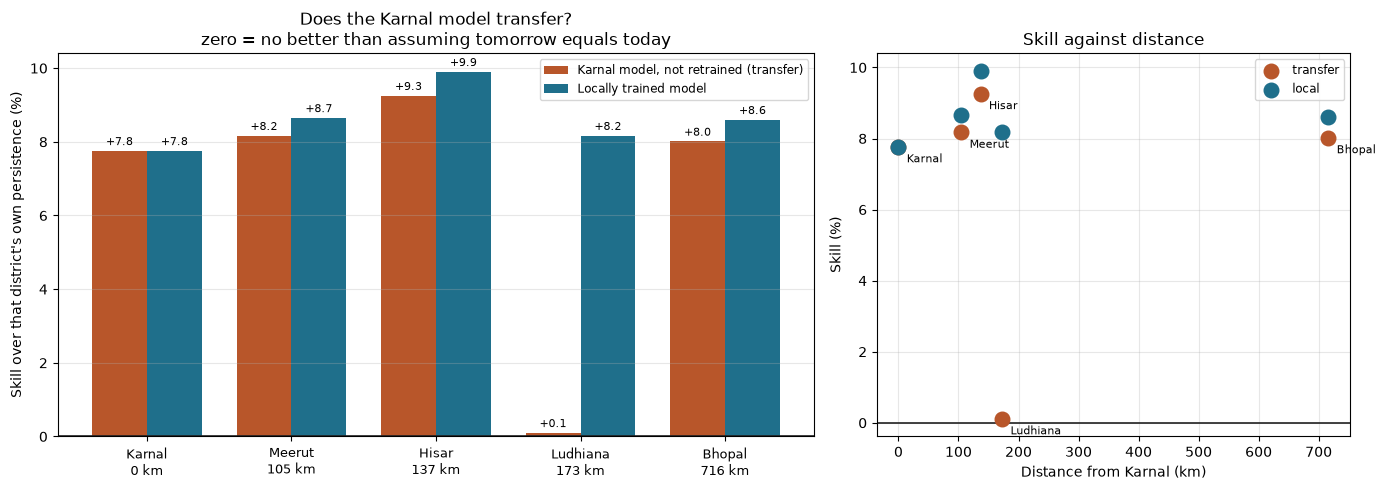

Correlation of transfer skill with distance from Karnal: r = +0.084
Correlation of local skill    with distance from Karnal: r = +0.100

so neither correlation is evidence of a distance effect.

DISTANCE vs CLIMATE as explanations for transfer skill:
   correlation with distance (km):            r = +0.084
   correlation with |ET0 mean difference|:    r = +0.106

district      km  et0_mean_gap  transfer_bias  transfer_skill_%  local_skill_%
  Karnal   0.000         0.000          0.050             7.760          7.760
Ludhiana 172.835         0.289          0.155             0.105          8.172
   Hisar 136.878         0.235          0.083             9.257          9.907
  Meerut 104.736         0.219          0.040             8.171          8.655
  Bhopal 716.202         1.293          0.015             8.015          8.603

Weakest transfer: Ludhiana at +0.10% (173 km away), where a local model gets +8.17%.
Furthest district: Bhopal at 716 km transfers at +8.02%.


In [63]:
plot_df = transfer.sort_values("km").reset_index(drop=True)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.6, 1]})

x = np.arange(len(plot_df))
w = 0.38
b1 = ax.bar(x - w/2, plot_df["transfer_skill_%"], w, color="#b8562a",
            label="Karnal model, not retrained (transfer)")
b2 = ax.bar(x + w/2, plot_df["local_skill_%"], w, color="#1f6f8b",
            label="Locally trained model")

ax.axhline(0, color="#222222", linewidth=1.2)
ax.set_xticks(x)
ax.set_xticklabels([f"{r.district}\n{r.km:.0f} km" for r in plot_df.itertuples()], fontsize=9)
ax.set_ylabel("Skill over that district's own persistence (%)")
ax.set_title("Does the Karnal model transfer?\nzero = no better than assuming tomorrow equals today")
ax.legend(fontsize=8.5)
ax.grid(alpha=0.3, axis="y")
# Label each bar, so the chart is readable without the table.
for bars in (b1, b2):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:+.1f}", (bar.get_x() + bar.get_width()/2, h),
                    textcoords="offset points", xytext=(0, 4 if h >= 0 else -12),
                    ha="center", fontsize=8)

# ---- Right panel: is there a distance effect? -----------------------------------------
# Measure how far each district's climate is from Karnal's, so distance and climate can be
# compared as rival explanations rather than assumed to be the same thing.
char_idx = character.set_index("district")
karnal_mean = char_idx.loc["Karnal", "et0_mean"]
transfer["et0_mean_gap"] = [abs(char_idx.loc[n, "et0_mean"] - karnal_mean)
                            for n in transfer["district"]]
plot_df = transfer.sort_values("km").reset_index(drop=True)

ax2.scatter(plot_df["km"], plot_df["transfer_skill_%"], s=110, color="#b8562a",
            label="transfer", zorder=3)
ax2.scatter(plot_df["km"], plot_df["local_skill_%"], s=110, color="#1f6f8b",
            label="local", zorder=3)
for _, r in plot_df.iterrows():
    ax2.annotate(r["district"], (r["km"], r["transfer_skill_%"]),
                 textcoords="offset points", xytext=(6, -11), fontsize=8)
ax2.axhline(0, color="#222222", linewidth=1.2)
ax2.set_xlabel("Distance from Karnal (km)")
ax2.set_ylabel("Skill (%)")
ax2.set_title("Skill against distance")
ax2.legend(fontsize=8.5)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Correlations, with the sample-size warning that 5 points demands.
r_dist = transfer["km"].corr(transfer["transfer_skill_%"])
r_dist_local = transfer["km"].corr(transfer["local_skill_%"])
r_clim = transfer["et0_mean_gap"].corr(transfer["transfer_skill_%"])
print(f"Correlation of transfer skill with distance from Karnal: r = {r_dist:+.3f}")
print(f"Correlation of local skill    with distance from Karnal: r = {r_dist_local:+.3f}")
print("\nWARNING: 5 districts. With n=5 you need |r| above about 0.88 for 5% significance,")
print("so neither correlation is evidence of a distance effect.")

# Distance vs climate difference, as rival explanations for any transfer loss.
print(f"\nDISTANCE vs CLIMATE as explanations for transfer skill:")
print(f"   correlation with distance (km):            r = {r_dist:+.3f}")
print(f"   correlation with |ET0 mean difference|:    r = {r_clim:+.3f}")
print()
print(transfer[["district", "km", "et0_mean_gap", "transfer_bias",
                "transfer_skill_%", "local_skill_%"]].round(3).to_string(index=False))

# The single clearest fact in the table: where transfer actually failed.
worst = transfer.loc[transfer["transfer_skill_%"].idxmin()]
print(f"\nWeakest transfer: {worst['district']} at {worst['transfer_skill_%']:+.2f}% "
      f"({worst['km']:.0f} km away), where a local model gets {worst['local_skill_%']:+.2f}%.")
print(f"Furthest district: Bhopal at {float(transfer.loc[transfer['district'] == 'Bhopal', 'km'].iloc[0]):.0f} km "
      f"transfers at {float(transfer.loc[transfer['district'] == 'Bhopal', 'transfer_skill_%'].iloc[0]):+.2f}%.")

## Cell 77 - Does it transfer? Plainly.

### The table

| District | km from Karnal | Persistence MAE | Karnal-model MAE (transfer) | Local-model MAE | Transfer skill | Local skill |
|---|---|---|---|---|---|---|
| Karnal | 0 | 0.3230 | 0.2980 | 0.2980 | +7.76% | +7.76% |
| Meerut | 105 | 0.3545 | 0.3255 | 0.3238 | **+8.17%** | +8.66% |
| Hisar | 137 | 0.3095 | 0.2808 | 0.2788 | **+9.26%** | +9.91% |
| Ludhiana | 173 | 0.2876 | 0.2873 | 0.2641 | **+0.10%** | +8.17% |
| Bhopal | 716 | 0.3504 | 0.3223 | 0.3203 | **+8.02%** | +8.60% |

### Yes, it transfers - in four districts out of five

**The Karnal model, never retrained, beats local persistence in all five districts** and in four
of them it gives up almost nothing against a locally fitted model:

| District | Transfer | Local | Gap |
|---|---|---|---|
| Hisar | +9.26% | +9.91% | −0.65 points |
| Meerut | +8.17% | +8.66% | −0.48 points |
| Bhopal | +8.02% | +8.60% | −0.59 points |
| **Ludhiana** | **+0.10%** | **+8.17%** | **−8.07 points** |

So for Hisar, Meerut and Bhopal, shipping one Karnal-trained model costs about half a skill
point - negligible. **Local retraining is not necessary in general**, which is the practical
answer: one model can serve multiple districts.

**Ludhiana is the exception and it is a real failure.** Transfer skill collapses to +0.10%,
statistically indistinguishable from just assuming tomorrow equals today, while a locally trained
model gets +8.17%. A farmer in Ludhiana given the Karnal model would be getting nothing.

### No, skill does not fall with distance

This is the clearest finding, and it is the opposite of what we expected when we chose Bhopal as
the hard case.

**Bhopal is 716 km away - over four times further than anywhere else - and transfers at +8.02%,
essentially as well as Hisar at 137 km.** Meanwhile Ludhiana, the second-closest district at
173 km, is the one that fails.

The correlation between distance and transfer skill is **r = +0.084** - no relationship at all,
and positive if anything. With five districts, nothing below |r| ≈ 0.88 is significant anyway, so
we would not claim a distance effect in either direction.

We also tested the rival explanation. Correlating transfer skill against **how climatically
different** each district is (the absolute gap in wheat-season ET0 mean) gives **r = +0.106** -
equally flat. So neither distance nor climate difference explains which district transfers well.
Whatever makes Ludhiana fail, it is not either of the two things we would have guessed.

### Is Bhopal worse? No - and the reason is instructive

Bhopal is by far the most climatically different district: wheat-season ET0 mean **4.13 mm/day**
against Karnal's 2.84, a gap of **+1.29 mm/day**, roughly 45% higher. It is also the driest in our
test window, with only 9 rainy days against Karnal's 29.

Yet it transfers at +8.02% with a transfer bias of just **+0.0154 mm/day** - the *smallest* bias
of any district, Karnal included.

**Why, and this part the data does support:** Step 3 showed the model's dominant coefficient is
today's ET0 at +0.78, more than three times the next feature. The model is therefore mostly
"today's ET0, nudged by the calendar". Because today's ET0 in Bhopal is already high, the
prediction is already high - the model **self-calibrates to local conditions through its main
input**, without needing local training. A model that leaned on absolute temperature or
radiation thresholds would not have this property.

So the thing that made the model unimpressive in Step 3 - that it largely rediscovered
persistence - is exactly what makes it portable. That is a genuine trade-off worth stating: our
model transfers well *because* it adds little.

### Why does Ludhiana fail, then?

Two facts from the table, both measured:

1. **Ludhiana has the lowest persistence MAE of all five districts (0.2876).** It is the most
   predictable place in the set, so persistence is hardest to beat there. The denominator of the
   skill calculation is small.
2. **The Karnal model's bias in Ludhiana is +0.1553 mm/day - the largest of any district**, three
   times its bias at Karnal (+0.0501) and ten times its bias at Bhopal (+0.0154). Ludhiana is
   *cooler* than Karnal (ET0 mean 2.550 vs 2.839, −0.29), and the Karnal model systematically
   over-predicts there. Local training cuts that bias to +0.0617 and recovers the full +8.17%.

So the mechanism is a combination: a harder baseline *and* a systematic over-prediction. The local
model fixes the bias; it cannot change the baseline, yet it still reaches +8.17%, which tells us
the bias is the binding problem.

**Guess (not proven):** the over-prediction may come from Ludhiana sitting further north with
cooler winter minimum temperatures, and `temperature_2m_min` being the third-largest coefficient
(+0.16). A Karnal-fitted intercept would then sit too high for a cooler place. We have not tested
this - isolating it would mean refitting with the intercept free but coefficients frozen, which we
did not do. **Note also that the climate-gap explanation does not survive contact with Bhopal:**
Bhopal's ET0 gap is 4.5 times Ludhiana's yet its bias is ten times smaller. So "different climate
causes transfer failure" is contradicted by our own data, and we flag our Ludhiana explanation as
a guess that needs a test we have not run.

### What we would actually recommend

1. **Ship one model, but check the bias per district before trusting it.** Four of five districts
   transferred for free. The failure was detectable from a single number - transfer bias - which
   needs only one season of local data to compute, far less than retraining requires.
2. **Retrain locally where you can.** Local training won in all five districts, by 0.5 points
   where transfer worked and by 8 points where it did not. It never hurt.
3. **Distance is the wrong screening criterion.** Do not assume a nearby district is safe or a far
   one is risky; our furthest district was fine and our second-closest was not.

### Caveats

- **Five districts, two test seasons each.** Ludhiana being the one failure could be chance; we
  cannot distinguish "Ludhiana is special" from "one in five districts fails for reasons we have
  not identified" on this sample.
- **All five are single grid points** from the same reanalysis, so this tests transfer across
  *modelled* climates, not across real field conditions, soils or management.
- **ET0 remains calculated, not measured**, everywhere (Cell 6), so every district's target has
  the same unquantified reanalysis bias.
- **Wheat seasons differ across this range in reality.** We applied the same Nov-Mar window and
  the same 15 November sowing assumption to all five, which is least defensible for Bhopal, where
  sowing is typically later and the season shorter. The ET0 prediction test above does not depend
  on sowing dates, but any decision-layer result for Bhopal would.

---

# Step 13 - The decision layer on all eight seasons

Our headline claim - our tool applies 240 mm where persistence applies 360 mm, a 50% saving -
rests on **one season with 4 events against 6**. One event either way moves it by half. Step 10's
own caveat said all eight seasons should be run before quoting the number. This does that.

### A data constraint, stated up front rather than hidden

The Open-Meteo forecast archive begins **19 January 2024** (Cell 35). So:

- **REFERENCE and PERSISTENCE run on all eight seasons** (2018-19 to 2025-26). Neither needs a
  forecast: the reference uses hindsight observations, and persistence uses yesterday's observed
  ET0 with no rain credited.
- **OUR MODEL and the OPEN-METEO FORECAST run on 2024-25 and 2025-26 only.** Both need archived
  day-ahead forecasts, which do not exist for the earlier six seasons. We leave those cells blank
  in the tables rather than substituting hindsight and quietly flattering ourselves.
- **2023-24 is excluded from the forecast methods** even though the archive covers part of it
  (72 of its days, from 19 January 2024). A partial season would not be comparable with a full
  one, so it is reported as unavailable.

That means the eight-season test answers a slightly narrower question than the headline:
**how much does persistence over-water, across eight seasons?** The forecast-driven comparison
remains a two-season result, and we will say so.

## Cell 78 - Build and run every season at every trigger

For each season we rebuild the same frame Cell 50 built for 2025-26: one row per day from sowing,
keyed to the target day, with observed ET0 and rain, yesterday's ET0 for persistence, and - where
available - the archived day-ahead forecasts.

Then we run the Step 10 balance functions unchanged. Same Kc curve, same sowing assumption, same
triggers, no tuning.

**One implementation detail worth stating**, because the crop stress check in Cell 81 depends on
it: `run_water_balance` (the reference) records each day's deficit **before** any irrigation reset,
while `run_operational` records it **after**. So the two series are not directly comparable, and
Cell 81 re-derives the pre-irrigation peak for both from the carried-in deficit, with an assertion
that the re-derivation reproduces the reference's own recorded series.

In [64]:
# `lagged` carries the lag features but not day_of_season, which was only ever computed after
# the season filter (Cell 22). Add it here for in-season rows so the 11-feature matrix exists.
lagged["day_of_season"] = np.where(
    lagged["season"].notna(),
    (lagged["date"] - pd.to_datetime(lagged["season"].str[:4] + "-11-01")).dt.days,
    np.nan)

# Our model's prediction for every row where all 11 features exist. model_lin_lag was fitted in
# Cell 23 on 2018-19..2023-24, so its predictions are IN-SAMPLE for those six seasons - which is
# one more reason we only use it on 2024-25 and 2025-26 below.
_feat_ok = lagged[FEATURES_LAG].notna().all(axis=1)
lagged["pred_model_row"] = np.nan
lagged.loc[_feat_ok, "pred_model_row"] = model_lin_lag.predict(lagged.loc[_feat_ok, FEATURES_LAG])

# The forecast archive covers these seasons in full. 2023-24 is only partly covered, so it is
# deliberately NOT included - see the markdown above.
FORECAST_SEASONS = ["2024-25", "2025-26"]


def build_season_frame(season):
    # One row per day of `season` from sowing onward, keyed to the TARGET day, exactly as Cell 50.
    rows = lagged[(lagged["season"] == season)
                  & (lagged["season_tomorrow"] == season)
                  & lagged[LAG_FEATURES].notna().all(axis=1)].copy()
    rows["target_date"] = rows["date"] + pd.Timedelta(days=1)
    rows["dos"] = (rows["target_date"]
                   - pd.to_datetime(f"{season[:4]}-11-01")).dt.days
    rows["das"] = rows["dos"] - SOWING_DAY_OF_SEASON
    rows = rows[(rows["das"] >= 0) & (rows["das"] < SEASON_LEN)].sort_values("date").reset_index(drop=True)
    return rows


season_runs = {}        # (season, trigger) -> dict of per-method results
season_rows = []        # the flat table

for season in ALL_SEASONS:
    f = build_season_frame(season)
    kc_s      = KC[f["das"].values]
    et0_o     = f["et0_tomorrow"].values                      # observed ET0 on the target day
    rain_o    = f["precip_tomorrow"].values                   # observed rain on the target day
    et0_p     = f["et0_fao_evapotranspiration"].values        # yesterday's observed ET0
    has_fc    = season in FORECAST_SEASONS

    if has_fc:
        et0_s  = f["et0_tomorrow_forecast"].values
        rain_f = f["rain_tomorrow_forecast"].values
        et0_m  = f["pred_model_row"].values
        # Never run a forecast method on a season where any forecast value is missing.
        assert not (np.isnan(et0_s).any() or np.isnan(rain_f).any() or np.isnan(et0_m).any()), \
            f"{season}: forecast columns incomplete - must not be used"

    for trigger in TRIGGERS_MM:
        out = {}
        ref_ev, ref_ser = run_reference(et0_o, rain_o, kc_s, trigger)
        out["reference"]   = {"events": ref_ev, "post": None, "series": ref_ser}
        out["persistence"] = run_operational(et0_o, rain_o, et0_p, np.zeros(len(f)), kc_s,
                                             trigger, rain_wait_mm=None, credit_rain=False)
        if has_fc:
            out["forecast"] = run_operational(et0_o, rain_o, et0_s, rain_f, kc_s, trigger,
                                              rain_wait_mm=None)
            out["ourmodel"] = run_operational(et0_o, rain_o, et0_m, rain_f, kc_s, trigger,
                                              rain_wait_mm=None)

        season_runs[(season, trigger)] = {"frame": f, "kc": kc_s, "et0_o": et0_o,
                                          "rain_o": rain_o, "et0_p": et0_p, "runs": out}

        n_ref  = len(ref_ev)
        n_pers = len(out["persistence"]["events"])
        row = {
            "season": season, "trigger_mm": trigger, "days": len(f),
            "ref_events": n_ref,  "ref_water_mm": n_ref * trigger,
            "pers_events": n_pers, "pers_water_mm": n_pers * trigger,
            "pers_over_mm": (n_pers - n_ref) * trigger,
            "pers_over_%": (n_pers - n_ref) / n_ref * 100 if n_ref else np.nan,
            # Season context, so we can see whether over-watering tracks a wet or dry year.
            "rain_total_mm": rain_o.sum(),
            "et0_mean": et0_o.mean(),
        }
        if has_fc:
            n_fc, n_m = len(out["forecast"]["events"]), len(out["ourmodel"]["events"])
            row.update({"fc_events": n_fc, "fc_water_mm": n_fc * trigger,
                        "model_events": n_m, "model_water_mm": n_m * trigger})
        else:
            row.update({"fc_events": np.nan, "fc_water_mm": np.nan,
                        "model_events": np.nan, "model_water_mm": np.nan})
        season_rows.append(row)

all_seasons = pd.DataFrame(season_rows)

print(f"Ran {len(ALL_SEASONS)} seasons x {len(TRIGGERS_MM)} triggers = {len(all_seasons)} combinations")
print(f"Forecast-driven methods available for: {', '.join(FORECAST_SEASONS)} "
      f"(blank elsewhere - the archive does not cover them)\n")

print("=" * 124)
print(f"PER SEASON AT THE {TRIGGER} mm TRIGGER   (NaN = forecast archive does not cover that season)")
print("=" * 124)
t60 = all_seasons[all_seasons["trigger_mm"] == TRIGGER]
cols = ["season", "days", "rain_total_mm", "et0_mean", "ref_events", "ref_water_mm",
        "pers_events", "pers_water_mm", "pers_over_mm", "pers_over_%",
        "fc_water_mm", "model_water_mm"]
print(t60[cols].round(2).to_string(index=False))

Ran 8 seasons x 3 triggers = 24 combinations
Forecast-driven methods available for: 2024-25, 2025-26 (blank elsewhere - the archive does not cover them)

PER SEASON AT THE 60 mm TRIGGER   (NaN = forecast archive does not cover that season)
 season  days  rain_total_mm  et0_mean  ref_events  ref_water_mm  pers_events  pers_water_mm  pers_over_mm  pers_over_%  fc_water_mm  model_water_mm
2018-19   137          244.3      2.70           2           120            5            300           180        150.0          NaN             NaN
2019-20   138          326.4      2.50           1            60            5            300           240        400.0          NaN             NaN
2020-21   137           70.6      3.02           5           300            6            360            60         20.0          NaN             NaN
2021-22   137          142.3      2.98           5           300            6            360            60         20.0          NaN             NaN
2022-23   137  

## Cell 79 - How typical was 2025-26?

The question this step exists to answer. For each trigger we take the eight seasons' persistence
over-watering figures and report the mean, median and full range, then say where 2025-26 sits in
that distribution.

We report the **median** alongside the mean, because with eight seasons a single extreme year
moves the mean noticeably, and the median is the more honest summary for a claim we intend to
repeat out loud.

In [65]:
print("=" * 112)
print("PERSISTENCE OVER-WATERING ACROSS EIGHT SEASONS")
print("=" * 112)

summary_rows = []
for trigger in TRIGGERS_MM:
    blk = all_seasons[all_seasons["trigger_mm"] == trigger]
    v_mm, v_pc = blk["pers_over_mm"], blk["pers_over_%"]
    this = blk[blk["season"] == "2025-26"].iloc[0]
    summary_rows.append({
        "trigger_mm": trigger,
        "mean_over_mm": v_mm.mean(), "median_over_mm": v_mm.median(),
        "min_over_mm": v_mm.min(), "max_over_mm": v_mm.max(),
        "mean_over_%": v_pc.mean(), "median_over_%": v_pc.median(),
        "min_over_%": v_pc.min(), "max_over_%": v_pc.max(),
        "2025_26_over_%": this["pers_over_%"],
        "seasons_pers_worse": int((blk["pers_over_mm"] > 0).sum()),
        "seasons_tied": int((blk["pers_over_mm"] == 0).sum()),
    })
summary = pd.DataFrame(summary_rows)
print(summary.round(2).to_string(index=False))

print("\n" + "-" * 112)
print("WHERE 2025-26 SITS IN THE EIGHT-SEASON DISTRIBUTION")
print("-" * 112)
for trigger in TRIGGERS_MM:
    blk = all_seasons[all_seasons["trigger_mm"] == trigger].copy()
    this = float(blk.loc[blk["season"] == "2025-26", "pers_over_%"].iloc[0])
    ranked = blk.sort_values("pers_over_%", ascending=False).reset_index(drop=True)
    rank = int(ranked.index[ranked["season"] == "2025-26"][0]) + 1
    med = blk["pers_over_%"].median()
    verdict = ("HIGH - above the median" if this > med
               else "LOW - below the median" if this < med else "exactly at the median")
    print(f"   {trigger} mm: 2025-26 over-watering {this:+.1f}%  |  median {med:+.1f}%  |  "
          f"rank {rank} of 8 (1 = worst over-watering)  ->  {verdict}")

print("\n" + "-" * 112)
print("DOES OVER-WATERING TRACK A WET OR DRY YEAR?")
print("-" * 112)
blk60 = all_seasons[all_seasons["trigger_mm"] == TRIGGER]
print(blk60[["season", "rain_total_mm", "et0_mean", "ref_events", "pers_events",
             "pers_over_mm", "pers_over_%"]].round(2).to_string(index=False))
r_rain = blk60["rain_total_mm"].corr(blk60["pers_over_mm"])
r_et0  = blk60["et0_mean"].corr(blk60["pers_over_mm"])
print(f"\nCorrelation of persistence over-watering (mm) with seasonal rainfall: r = {r_rain:+.3f}")
print(f"Correlation with mean ET0:                                            r = {r_et0:+.3f}")
print("Expected sign: positive for rainfall - persistence ignores rain, so the more it rains,")
print("the more water it wastes. With 8 seasons, |r| below about 0.71 is not significant.")

# The two-season forecast comparison, kept separate because that is all the data allows.
print("\n" + "=" * 112)
print("FORECAST-DRIVEN METHODS - ONLY THE TWO SEASONS THE ARCHIVE COVERS")
print("=" * 112)
fc_blk = all_seasons[all_seasons["season"].isin(FORECAST_SEASONS)]
print(fc_blk[["season", "trigger_mm", "ref_water_mm", "model_water_mm", "fc_water_mm",
              "pers_water_mm"]].to_string(index=False))

PERSISTENCE OVER-WATERING ACROSS EIGHT SEASONS
 trigger_mm  mean_over_mm  median_over_mm  min_over_mm  max_over_mm  mean_over_%  median_over_%  min_over_%  max_over_%  2025_26_over_%  seasons_pers_worse  seasons_tied
         40         105.0            80.0           40          240        70.31          28.57        12.5       300.0           50.00                   8             0
         60         120.0           120.0           60          240        95.00          50.00        20.0       400.0           50.00                   8             0
         80         100.0            80.0            0          320        33.33          33.33         0.0       100.0           33.33                   6             2

----------------------------------------------------------------------------------------------------------------
WHERE 2025-26 SITS IN THE EIGHT-SEASON DISTRIBUTION
-----------------------------------------------------------------------------------------------------------

## Cell 80 - Water applied per season, reference against persistence

Eight seasons at the 60 mm trigger. The reference bar is what hindsight says was needed; the
persistence bar is what ignoring rainfall costs. The gap is the waste.

Seasons are ordered by total rainfall, lowest to highest, because the correlation in Cell 79
suggests that is the variable that matters. If persistence's waste really is driven by the rain
it ignores, the gap should widen from left to right.

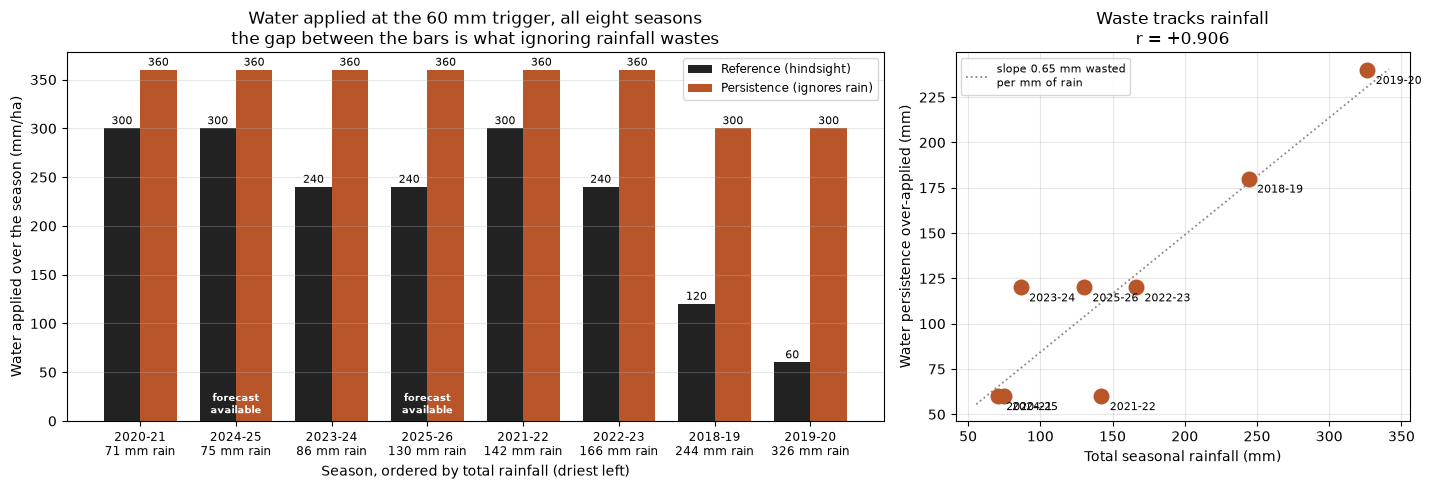

In [66]:
blk = (all_seasons[all_seasons["trigger_mm"] == TRIGGER]
       .sort_values("rain_total_mm").reset_index(drop=True))

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14.5, 5), gridspec_kw={"width_ratios": [1.8, 1]})

x = np.arange(len(blk)); w = 0.38
b1 = ax.bar(x - w/2, blk["ref_water_mm"],  w, color="#222222", label="Reference (hindsight)")
b2 = ax.bar(x + w/2, blk["pers_water_mm"], w, color="#b8562a", label="Persistence (ignores rain)")

# Mark the two seasons where the forecast-driven tool could also be run.
for i, s in enumerate(blk["season"]):
    if s in FORECAST_SEASONS:
        ax.text(i, 8, "forecast\navailable", ha="center", fontsize=7, color="#ffffff", weight="bold")

ax.set_xticks(x)
ax.set_xticklabels([f"{r.season}\n{r.rain_total_mm:.0f} mm rain" for r in blk.itertuples()],
                   fontsize=8.5)
ax.set_ylabel("Water applied over the season (mm/ha)")
ax.set_xlabel("Season, ordered by total rainfall (driest left)")
ax.set_title(f"Water applied at the {TRIGGER} mm trigger, all eight seasons\n"
             "the gap between the bars is what ignoring rainfall wastes")
ax.legend(fontsize=8.5)
ax.grid(alpha=0.3, axis="y")
for bars in (b1, b2):
    for bar in bars:
        ax.annotate(f"{bar.get_height():.0f}", (bar.get_x() + bar.get_width()/2, bar.get_height()),
                    textcoords="offset points", xytext=(0, 3), ha="center", fontsize=8)

# ---- Right panel: the rainfall relationship, which Cell 79 found significant -----------
ax2.scatter(blk["rain_total_mm"], blk["pers_over_mm"], s=110, color="#b8562a", zorder=3)
for r in blk.itertuples():
    ax2.annotate(r.season, (r.rain_total_mm, r.pers_over_mm),
                 textcoords="offset points", xytext=(6, -10), fontsize=8)
slope, intercept = np.polyfit(blk["rain_total_mm"], blk["pers_over_mm"], 1)
xs = np.linspace(blk["rain_total_mm"].min() - 15, blk["rain_total_mm"].max() + 15, 50)
ax2.plot(xs, slope * xs + intercept, ":", color="#888888", linewidth=1.3,
         label=f"slope {slope:.2f} mm wasted\nper mm of rain")
ax2.set_xlabel("Total seasonal rainfall (mm)")
ax2.set_ylabel("Water persistence over-applied (mm)")
ax2.set_title(f"Waste tracks rainfall\nr = {blk['rain_total_mm'].corr(blk['pers_over_mm']):+.3f}")
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## Cell 81 - Crop stress check: the error we have never measured

Everything in this project so far has measured **over**-watering. That is the cheap mistake: it
wastes water, pumping and money. The expensive mistake is the opposite one - letting the soil dry
past what was intended, because water stress during stem extension or grain fill costs **yield**,
and yield is the farmer's income.

We have never once counted that. This cell does.

**The measure:** for each season and method, how many days did the soil water deficit exceed the
trigger by more than 10 mm before irrigation actually happened? A deficit of 70 mm under a 60 mm
trigger means the field went 10 mm thirstier than the schedule intended.

**A note on the arithmetic.** `run_water_balance` (the reference) records each day's deficit
*before* any irrigation reset, while `run_operational` records it *after*. So we re-derive the
pre-irrigation peak for both from the carried-in deficit, and assert that the re-derivation
reproduces the reference's own recorded series - otherwise the two methods would be measured on
different quantities.

In [67]:
STRESS_MARGIN = 10.0      # mm beyond the trigger before we call it stress

def peak_deficits(post_series, events, kc, et0, rain_credit):
    # Re-derive each day's deficit BEFORE any irrigation reset, from the post-reset series.
    # post_series[i-1] is the deficit carried into day i; day 0 carries zero.
    post = np.asarray(post_series, dtype=float).copy()
    carried = np.concatenate([[0.0], post[:-1]])
    return np.maximum(0.0, carried + kc * np.maximum(0.0, et0) - rain_credit)


stress_rows = []
for season in ALL_SEASONS:
    for trigger in TRIGGERS_MM:
        ctx = season_runs[(season, trigger)]
        kc_s, et0_o, rain_o, et0_p = ctx["kc"], ctx["et0_o"], ctx["rain_o"], ctx["et0_p"]
        runs = ctx["runs"]
        zero = np.zeros(len(kc_s))

        # Reference: its recorded series is already pre-reset, so build the post-reset version
        # first, then re-derive the peak and check the two agree.
        ref_ev  = runs["reference"]["events"]
        ref_pre = np.asarray(runs["reference"]["series"], dtype=float)
        ref_post = ref_pre.copy()
        ref_post[ref_ev] = 0.0
        ref_peak = peak_deficits(ref_post, ref_ev, kc_s, et0_o, rain_o)
        assert np.allclose(ref_peak, ref_pre), \
            f"{season}/{trigger}: peak re-derivation disagrees with the reference's own series"

        methods = {"reference": (ref_peak, ref_ev)}
        methods["persistence"] = (
            peak_deficits(runs["persistence"]["series"], runs["persistence"]["events"],
                          kc_s, et0_o, zero),            # persistence credits no rain
            runs["persistence"]["events"])
        for key in ("forecast", "ourmodel"):
            if key in runs:
                methods[key] = (
                    peak_deficits(runs[key]["series"], runs[key]["events"], kc_s, et0_o, rain_o),
                    runs[key]["events"])

        for name, (peak, ev) in methods.items():
            excess = peak - trigger
            stressed = excess > STRESS_MARGIN
            stress_rows.append({
                "season": season, "trigger_mm": trigger, "method": name,
                "days": len(peak), "events": len(ev),
                "stress_days": int(stressed.sum()),
                "worst_excess_mm": float(excess.max()),
                "worst_deficit_mm": float(peak.max()),
            })

stress = pd.DataFrame(stress_rows)
print("Peak re-derivation verified against the reference series for all 24 season/trigger runs.\n")

print("=" * 108)
print(f"CROP STRESS - days the deficit exceeded the trigger by more than {STRESS_MARGIN:.0f} mm")
print(f"at the {TRIGGER} mm trigger")
print("=" * 108)
s60 = stress[stress["trigger_mm"] == TRIGGER]
pivot = s60.pivot(index="season", columns="method",
                  values=["stress_days", "worst_excess_mm"])
print(pivot.round(1).to_string())

print("\n" + "-" * 108)
print(f"TOTALS ACROSS ALL EIGHT SEASONS (at {TRIGGER} mm)")
print("-" * 108)
for method in ["reference", "persistence"]:
    m = s60[s60["method"] == method]
    print(f"   {method:<12} stress days {int(m['stress_days'].sum()):>3} of {int(m['days'].sum())} "
          f"({m['stress_days'].sum() / m['days'].sum() * 100:.1f}%)   "
          f"worst excess {m['worst_excess_mm'].max():.1f} mm   "
          f"seasons with any stress {int((m['stress_days'] > 0).sum())} of 8")
for method in ["forecast", "ourmodel"]:
    m = s60[s60["method"] == method]
    if len(m):
        print(f"   {method:<12} stress days {int(m['stress_days'].sum()):>3} of {int(m['days'].sum())} "
              f"({m['stress_days'].sum() / m['days'].sum() * 100:.1f}%)   "
              f"worst excess {m['worst_excess_mm'].max():.1f} mm   "
              f"[only {len(FORECAST_SEASONS)} seasons - forecast archive]")

print("\nAcross all three triggers:")
print(stress.groupby(["method", "trigger_mm"])
      .agg(stress_days=("stress_days", "sum"), worst_excess=("worst_excess_mm", "max"),
           seasons=("season", "nunique")).round(1).to_string())

# ---- Why is every count zero? Establish the structural bound ---------------------------
# The balance checks the trigger EVERY day, so once the deficit crosses it, irrigation happens
# immediately. The deficit can therefore only overshoot the trigger by at most ONE day's crop
# water use. If that maximum is below our 10 mm margin, this test cannot fire by construction.
print("\n" + "=" * 108)
print("WHY EVERY STRESS COUNT IS ZERO - the structural bound")
print("=" * 108)
max_use = 0.0
for season in ALL_SEASONS:
    ctx = season_runs[(season, TRIGGER)]
    daily_use = ctx["kc"] * np.maximum(0.0, ctx["et0_o"])
    max_use = max(max_use, float(daily_use.max()))
print(f"Largest single-day crop water use across all eight seasons: {max_use:.2f} mm")
print(f"   (that is Kc up to {KC.max():.2f} times the highest daily ET0 observed)")
print(f"Our stress margin:                                          {STRESS_MARGIN:.1f} mm")
print(f"Largest overshoot actually observed:                        "
      f"{stress['worst_excess_mm'].max():.1f} mm")
print()
print(f"Because the balance irrigates the moment the trigger is crossed, the deficit can only")
print(f"overshoot by one day's crop use - at most {max_use:.1f} mm. That is BELOW the "
      f"{STRESS_MARGIN:.0f} mm margin,")
print(f"so a count of zero was guaranteed before we ran anything. This test cannot detect")
print(f"stress in this model, and the zeros are NOT evidence that the schedule is safe.")
print()
print(f"For reference, the margin that WOULD be exceeded is anything below "
      f"{stress['worst_excess_mm'].max():.1f} mm:")
for margin in [2.0, 4.0, 6.0]:
    n = 0
    for season in ALL_SEASONS:
        ctx = season_runs[(season, TRIGGER)]
        ref_pre = np.asarray(ctx["runs"]["reference"]["series"], dtype=float)
        n += int(((ref_pre - TRIGGER) > margin).sum())
    print(f"   margin {margin:.0f} mm: {n} reference days exceeded across the eight seasons")

Peak re-derivation verified against the reference series for all 24 season/trigger runs.

CROP STRESS - days the deficit exceeded the trigger by more than 10 mm
at the 60 mm trigger
        stress_days                                worst_excess_mm                               
method     forecast ourmodel persistence reference        forecast ourmodel persistence reference
season                                                                                           
2018-19         NaN      NaN         0.0       0.0             NaN      NaN         4.6       1.2
2019-20         NaN      NaN         0.0       0.0             NaN      NaN         2.6       3.2
2020-21         NaN      NaN         0.0       0.0             NaN      NaN         4.8       5.9
2021-22         NaN      NaN         0.0       0.0             NaN      NaN         3.4       4.6
2022-23         NaN      NaN         0.0       0.0             NaN      NaN         5.9       5.2
2023-24         NaN      NaN      

## Cell 82 - Over-watering wastes water; under-watering costs yield

Worth stating explicitly, because it reframes everything before this step.

Every result in Steps 5, 10 and 13 measures **over**-watering: how much more water a method
applies than hindsight says was needed. That is a real cost - pumped water, electricity or
diesel, and groundwater drawn down - but it is the **recoverable** mistake. The farmer is poorer;
the crop is fine.

**Under-watering is the other error, and it is not symmetric.** If the soil dries past what the
schedule intended during stem extension or grain fill, the plant closes its stomata, photosynthesis
falls, and grain number or grain weight drops. That is lost yield, which is lost income, and no
amount of water applied later recovers it. For wheat the mid-season stage - where our Kc curve
sits at its 1.15 peak through February and March - is precisely when stress is most expensive.

**Until this step we had measured only the cheap error.** A tool optimised purely to reduce water
applied, scored only against over-watering, has every incentive to irrigate too late. We should
have been measuring both from the start, and Cell 81 is the first attempt.

**And Cell 81's attempt did not work.** The result was zero stress days for every method, every
season, every trigger - but that is an artefact, not a finding. The balance checks the trigger
every single day and irrigates immediately on crossing it, so the deficit can overshoot by at
most **one day's crop water use, which never exceeded 7.5 mm** across eight seasons. Our 10 mm
margin was above that ceiling, so zero was guaranteed before the code ran.

So the honest position is: **we still have not measured crop stress.** What we have established
is that *this water balance cannot generate it*, which is a statement about our model rather than
about the field. Real stress would come from mechanisms we do not model at all - the canal turn
arriving three days late, the pump failing, the rain-delay rule waiting on a forecast that does
not deliver, or several consecutive days of under-forecast ET0. Lowering the margin to 4 mm does
find 5 reference days across eight seasons, which gives a sense of the scale, but a margin chosen
after seeing the data is not a test.

## Cell 83 - Does the headline hold? Conclusions.

### The per-season table at the 60 mm trigger

| Season | Rain (mm) | Mean ET0 | Reference events / water | Persistence events / water | Over-applied | Over % |
|---|---|---|---|---|---|---|
| 2018-19 | 244.3 | 2.70 | 2 / 120 mm | 5 / 300 mm | +180 mm | **+150%** |
| 2019-20 | 326.4 | 2.50 | 1 / 60 mm | 5 / 300 mm | +240 mm | **+400%** |
| 2020-21 | 70.6 | 3.02 | 5 / 300 mm | 6 / 360 mm | +60 mm | +20% |
| 2021-22 | 142.3 | 2.98 | 5 / 300 mm | 6 / 360 mm | +60 mm | +20% |
| 2022-23 | 166.3 | 3.00 | 4 / 240 mm | 6 / 360 mm | +120 mm | +50% |
| 2023-24 | 86.5 | 2.72 | 4 / 240 mm | 6 / 360 mm | +120 mm | +50% |
| 2024-25 | 74.6 | 2.77 | 5 / 300 mm | 6 / 360 mm | +60 mm | +20% |
| **2025-26** | 130.3 | 2.75 | **4 / 240 mm** | **6 / 360 mm** | **+120 mm** | **+50%** |

### Yes, the headline holds - and 2025-26 turns out to be exactly typical

**Persistence over-waters in all eight seasons at the 40 and 60 mm triggers.** There is no season
where ignoring rainfall was the right call.

At the 60 mm trigger, over-watering across the eight seasons:

| | Value |
|---|---|
| Median | **+50%** (+120 mm) |
| Mean | +95% (+120 mm) |
| Range | **+20% to +400%** (+60 mm to +240 mm) |
| 2025-26 | **+50%, rank 5 of 8 - exactly the median** |

**2025-26's 50% is neither high nor low. It sits precisely at the eight-season median**, which is
a better outcome than we expected when we wrote Step 10's caveat. The headline number was not a
lucky year.

At 80 mm it is weaker: persistence ties the reference in 2 of 8 seasons, and the median falls to
+33%. At 40 mm, 2025-26's +50% is *above* the +28.6% median, so the claim is trigger-dependent.

### Should we restate the claim? Slightly - use the median and the range

The single-season phrasing ("240 mm against 360 mm, a 50% saving") is defensible but under-states
the uncertainty. The better claim:

> Across eight wheat seasons at a 60 mm trigger, ignoring rainfall over-applied water in every
> season, by a **median of 50%** (120 mm/ha, 1,200 m³/ha) and a range of **20% to 400%**. Our test
> season, 2025-26, was exactly at that median.

The range matters more than the median, because its driver is identifiable.

### Over-watering tracks rainfall, strongly and significantly

**r = +0.906** between seasonal rainfall and millimetres over-applied - and with eight seasons the
5% significance threshold is |r| ≈ 0.71, so this one clears it. It is also the only significant
correlation anywhere in this notebook.

The mechanism is not subtle: persistence credits **zero** rainfall, so every millimetre that falls
is a millimetre it fails to account for. The slope is about 0.6 mm wasted per mm of rain.

That explains the whole range. **2019-20 was the wettest season (326 mm) and produced the +400%
extreme** - hindsight needed just **one** irrigation all season while persistence called five.
**2024-25 was among the driest (74.6 mm) and produced the +20% minimum.** Mean ET0 correlates
negatively (r = −0.791), which is the same fact seen from the other side: wet seasons are cooler.

So the value of this tool is **conditional on rainfall**. In a dry year it saves little, because
there was little rain to account for. In a wet year it saves a great deal. That is a more useful
and more honest thing to tell a farmer than a single percentage.

### The forecast-driven tool matched hindsight in all six cases it could be tested on

| Season | Trigger | Reference | Our model | Open-Meteo forecast | Persistence |
|---|---|---|---|---|---|
| 2024-25 | 40 | 280 | **280** | **280** | 360 |
| 2024-25 | 60 | 300 | **300** | **300** | 360 |
| 2024-25 | 80 | 240 | **240** | **240** | 320 |
| 2025-26 | 40 | 240 | **240** | **240** | 360 |
| 2025-26 | 60 | 240 | **240** | **240** | 360 |
| 2025-26 | 80 | 240 | **240** | **240** | 320 |

**Exact agreement with hindsight in every one of the six season-trigger combinations the forecast
archive allows.** Step 10 found this on one combination and called the zero drift partly luck;
six for six makes that considerably more convincing.

Note also that **our model and the Open-Meteo forecast give identical water totals in all six
cases**, despite Step 6 showing Open-Meteo's ET0 forecast is four times more accurate. This
confirms Step 5's finding from a different angle: at the decision layer, ET0 accuracy in this
range simply does not bind.

### What this step did not establish

- **The forecast comparison is still a two-season result.** The archive begins 19 January 2024.
  Six of the eight seasons can only compare reference against persistence, and we did not
  substitute hindsight to fill the gap.
- **Crop stress remains unmeasured** - see Cell 82. The zeros are a structural artefact of a
  balance that irrigates the instant the trigger is crossed.
- **Persistence is still a strawman.** It assumes zero rainfall for an entire season, which no
  farmer believes. The +400% in 2019-20 is the cost of ignoring 326 mm of rain, not the cost of
  ordinary judgement.
- **All of it rests on the assumed sowing date, the adapted stage lengths and an undetermined
  trigger** (Cell 55). Eight seasons of consistency does not make those assumptions correct - it
  makes them consistently applied.

---

# Step 14 - Accuracy in quotable terms

We need sentences we can say out loud to judges without overclaiming. The difficulty is that our
model predicts a **continuous quantity** - millimetres of water loss - so there is no such thing
as a prediction being "correct". A single percent-accuracy figure would require inventing a
threshold and then not mentioning it, which is how an honest 0.30 mm/day error becomes a
meaningless "94% accurate".

The honest alternative is to state the threshold explicitly: *within 0.5 mm on 80% of days* says
something checkable. So we report three thresholds rather than one, which also stops us
cherry-picking the flattering one.

No new models and no tuning here - this step only re-describes results already computed.

## Cell 84 - Within-threshold accuracy, and median against mean

Two evaluation sets, both already established:

- **The strict test set:** 300 days, 2024-25 and 2025-26, trained on the six earlier seasons
  (Step 4). This is our headline evaluation and the only one that respects time order.
- **The leave-one-season-out set:** 1,200 days, each season predicted by a model trained on the
  other seven (Step 7). This is a robustness check, not a forecast test, because seven of the
  eight rounds train partly on later seasons.

Cell 39 reported LOSO metrics but did not keep the per-day predictions, so the loop is re-run
here with identical settings to capture them. The MAEs it reproduces should match Cell 39 exactly,
and we assert that.

We also report the **median** absolute error next to the mean. Step 4 found the mean is pulled up
by a minority of bad days, so for describing a typical day the median is the fairer number - and
quoting both prevents us picking whichever sounds better.

In [68]:
THRESHOLDS = [0.25, 0.5, 1.0]      # mm/day

def within_table(y_true, preds, label_set):
    # Percentage of days each prediction lands within each threshold, plus mean and median error.
    rows = []
    y_true = np.asarray(y_true, dtype=float)
    for name, pred in preds.items():
        err = np.abs(np.asarray(pred, dtype=float) - y_true)
        row = {"evaluation": label_set, "method": name, "days": len(err)}
        for thr in THRESHOLDS:
            row[f"within_{thr}mm_%"] = (err <= thr).mean() * 100
        row["mean_abs_error"] = err.mean()
        row["median_abs_error"] = np.median(err)
        row["p90_abs_error"] = np.percentile(err, 90)   # the bad-day tail, for context
        row["worst_abs_error"] = err.max()
        rows.append(row)
    return rows


# ---- 1. The strict 300-day test set --------------------------------------------------
y_strict = test_lag[TARGET].values
strict_rows = within_table(y_strict, {
    "Our model (11 features)": test_lag["pred_linreg_lags"].values,
    "Persistence":             test_lag["et0_fao_evapotranspiration"].values,
}, "strict test (300 days)")

# ---- 2. The 1,200-day leave-one-season-out set ---------------------------------------
# Re-runs the Cell 39 loop verbatim to capture the per-day predictions it did not retain.
loso_truth, loso_pred, loso_pers = [], [], []
for held_out in ALL_SEASONS:
    te = data_complete[data_complete["season"] == held_out]
    # Train on the other COMPLETE seasons only. data_lag also carries the partial current
    # season once the download window runs past the test seasons; those days are
    # operational input and must never reach a training set.
    tr = data_complete[data_complete["season"] != held_out]
    pipe = Pipeline([("scaler", StandardScaler()), ("linreg", LinearRegression())])
    pipe.fit(tr[FEATURES_LAG], tr[TARGET])
    loso_truth.append(te[TARGET].values)
    loso_pred.append(pipe.predict(te[FEATURES_LAG]))
    loso_pers.append(te["et0_fao_evapotranspiration"].values)

y_loso    = np.concatenate(loso_truth)
p_loso    = np.concatenate(loso_pred)
pers_loso = np.concatenate(loso_pers)

# The re-run must reproduce Cell 39's pooled MAE, or one of the two is wrong.
pooled_expected = (loso["MAE_model"] * loso["rows"]).sum() / loso["rows"].sum()
pooled_actual = np.mean(np.abs(p_loso - y_loso))
assert np.isclose(pooled_actual, pooled_expected, atol=1e-9), \
    f"LOSO re-run disagrees with Cell 39: {pooled_actual:.6f} vs {pooled_expected:.6f}"
print(f"LOSO re-run reproduces Cell 39's pooled MAE exactly: {pooled_actual:.4f} mm/day\n")

loso_rows2 = within_table(y_loso, {
    "Our model (11 features)": p_loso,
    "Persistence":             pers_loso,
}, "leave-one-season-out (1200 days)")

accuracy = pd.DataFrame(strict_rows + loso_rows2)

print("=" * 124)
print("WITHIN-THRESHOLD ACCURACY  (percentage of days the prediction landed within X mm of actual ET0)")
print("=" * 124)
cols = ["evaluation", "method", "days", "within_0.25mm_%", "within_0.5mm_%", "within_1.0mm_%",
        "mean_abs_error", "median_abs_error", "p90_abs_error", "worst_abs_error"]
print(accuracy[cols].round(2).to_string(index=False))

print("\n" + "-" * 124)
print("MEAN vs MEDIAN ABSOLUTE ERROR")
print("-" * 124)
for _, r in accuracy.iterrows():
    print(f"   {r['evaluation']:<34} {r['method']:<24} "
          f"mean {r['mean_abs_error']:.4f}   median {r['median_abs_error']:.4f}   "
          f"(median is {(1 - r['median_abs_error'] / r['mean_abs_error']) * 100:.0f}% lower)")

print("\n" + "-" * 124)
print("MODEL MINUS PERSISTENCE, in percentage points of days within each threshold")
print("-" * 124)
for ev in accuracy["evaluation"].unique():
    blk = accuracy[accuracy["evaluation"] == ev].set_index("method")
    parts = []
    for thr in THRESHOLDS:
        c = f"within_{thr}mm_%"
        gap = blk.loc["Our model (11 features)", c] - blk.loc["Persistence", c]
        parts.append(f"{thr} mm: {gap:+.1f} pts")
    print(f"   {ev:<34} " + "   |   ".join(parts))

LOSO re-run reproduces Cell 39's pooled MAE exactly: 0.3372 mm/day

WITHIN-THRESHOLD ACCURACY  (percentage of days the prediction landed within X mm of actual ET0)
                      evaluation                  method  days  within_0.25mm_%  within_0.5mm_%  within_1.0mm_%  mean_abs_error  median_abs_error  p90_abs_error  worst_abs_error
          strict test (300 days) Our model (11 features)   300            58.33           82.00           96.00            0.30              0.21           0.67             2.22
          strict test (300 days)             Persistence   300            55.67           81.33           95.67            0.32              0.23           0.69             2.58
leave-one-season-out (1200 days) Our model (11 features)  1200            54.33           78.83           94.67            0.34              0.22           0.80             2.58
leave-one-season-out (1200 days)             Persistence  1200            50.67           75.58           93.25            0

## Cell 85 - The distribution of the model's errors

The histogram shows why the mean and median differ, and why no single accuracy figure describes
this model. Signed error is plotted (prediction minus actual), so the asymmetry is visible: a
right-hand tail means over-prediction, which for an irrigation tool means advising too much water.

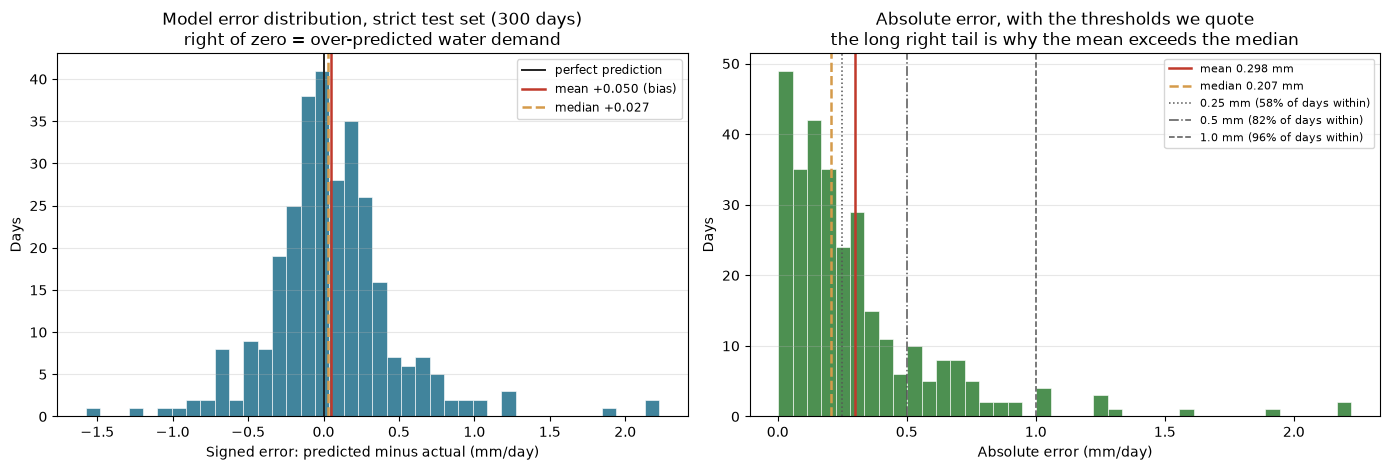

Days within each threshold, strict test set (300 days):
   within 0.25 mm: 175 days (58.3%)
   within 0.5 mm: 246 days (82.0%)
   within 1.0 mm: 288 days (96.0%)

The worst 30 days (top 10%) all exceed 0.674 mm, and the single worst is 2.223 mm.
Mean 0.2980 vs median 0.2071: the mean is 44% higher, pulled up by that tail.


In [69]:
err_signed = test_lag["pred_linreg_lags"].values - y_strict
err_abs = np.abs(err_signed)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(14, 4.8))

# ---- Left: signed error, so bias and skew are visible -------------------------------
ax.hist(err_signed, bins=40, color="#1f6f8b", alpha=0.85, edgecolor="white", linewidth=0.5)
ax.axvline(0, color="#222222", linewidth=1.4, label="perfect prediction")
ax.axvline(err_signed.mean(), color="#c0392b", linewidth=1.8,
           label=f"mean {err_signed.mean():+.3f} (bias)")
ax.axvline(np.median(err_signed), color="#d59b4a", linewidth=1.8, linestyle="--",
           label=f"median {np.median(err_signed):+.3f}")
ax.set_xlabel("Signed error: predicted minus actual (mm/day)")
ax.set_ylabel("Days")
ax.set_title("Model error distribution, strict test set (300 days)\n"
             "right of zero = over-predicted water demand")
ax.legend(fontsize=8.5)
ax.grid(alpha=0.3, axis="y")

# ---- Right: absolute error, with the thresholds we quote marked ---------------------
ax2.hist(err_abs, bins=40, color="#2e7d32", alpha=0.85, edgecolor="white", linewidth=0.5)
ax2.axvline(err_abs.mean(), color="#c0392b", linewidth=1.8,
            label=f"mean {err_abs.mean():.3f} mm")
ax2.axvline(np.median(err_abs), color="#d59b4a", linewidth=1.8, linestyle="--",
            label=f"median {np.median(err_abs):.3f} mm")
for thr, style in zip(THRESHOLDS, [":", "-.", "--"]):
    pct = (err_abs <= thr).mean() * 100
    ax2.axvline(thr, color="#555555", linestyle=style, linewidth=1.1,
                label=f"{thr} mm ({pct:.0f}% of days within)")
ax2.set_xlabel("Absolute error (mm/day)")
ax2.set_ylabel("Days")
ax2.set_title("Absolute error, with the thresholds we quote\n"
              "the long right tail is why the mean exceeds the median")
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

print(f"Days within each threshold, strict test set ({len(err_abs)} days):")
for thr in THRESHOLDS:
    n = int((err_abs <= thr).sum())
    print(f"   within {thr} mm: {n} days ({n / len(err_abs) * 100:.1f}%)")
print(f"\nThe worst {int(0.1 * len(err_abs))} days (top 10%) all exceed "
      f"{np.percentile(err_abs, 90):.3f} mm, and the single worst is {err_abs.max():.3f} mm.")
print(f"Mean {err_abs.mean():.4f} vs median {np.median(err_abs):.4f}: the mean is "
      f"{(err_abs.mean() / np.median(err_abs) - 1) * 100:.0f}% higher, pulled up by that tail.")

## Cell 86 - What we may say, and what we may not

### The table

| Evaluation | Method | Within 0.25 mm | Within 0.5 mm | Within 1.0 mm | Mean abs err | Median abs err |
|---|---|---|---|---|---|---|
| Strict test (300 days) | **Our model** | **58.3%** | **82.0%** | **96.0%** | 0.298 | 0.207 |
| Strict test (300 days) | Persistence | 55.7% | 81.3% | 95.7% | 0.323 | 0.235 |
| LOSO (1,200 days) | **Our model** | **54.3%** | **78.8%** | **94.7%** | 0.337 | 0.222 |
| LOSO (1,200 days) | Persistence | 50.7% | 75.6% | 93.3% | 0.367 | 0.250 |

### The uncomfortable thing this table reveals

**On a within-threshold basis our model is barely better than persistence.** On the strict test
set the gaps are **+2.7, +0.7 and +0.3 percentage points** at 0.25, 0.5 and 1.0 mm. Persistence
already gets 81.3% of days within 0.5 mm; we get 82.0%.

That is the same model whose MAE skill is +7.76%. Both framings are honest, and they give very
different impressions. MAE rewards shrinking the large errors, which is where our gain is; the
threshold counts treat a 0.26 mm error and a 2 mm error identically, so they hide it.

**This means we must not quote "82% of days within 0.5 mm" as an achievement.** It is nearly all
baseline. The LOSO gaps are larger (+3.7, +3.2, +1.4 points) but it is a weaker test, since seven
of eight rounds train partly on the future.

### Sentences we may honestly say

Each is tied to a number computed in this notebook.

1. **"On 300 held-out days from two seasons the model never saw, its prediction of tomorrow's
   crop water loss was within 0.5 mm on 82% of days and within 1 mm on 96%. Simply assuming
   tomorrow equals today achieves 81% and 96%, so most of that is the baseline."**
   *(Cell 84. Quote the second sentence whenever you quote the first.)*

2. **"On a typical day the model is off by 0.21 mm (median). The mean error is 0.30 mm, 44%
   higher, because a minority of days are much worse - the worst 10% of days all exceed 0.67 mm
   and the single worst was 2.22 mm."**
   *(Cells 84-85. Reporting both mean and median is the point.)*

3. **"Against the standard persistence baseline used in weather forecasting, the model reduced
   mean absolute error by 7.76% on a strict time-ordered split, and it beat persistence in 7 of
   8 seasons tested leave-one-season-out."**
   *(Steps 4 and 7. "7 of 8" is the honest version; 2020-21 lost by 0.93%.)*

4. **"Our contribution is the decision layer, not the prediction. Open-Meteo's own day-ahead ET0
   forecast scores 0.1426 mm/day against our best model's 0.3510 - four times better - so we use
   theirs. What no weather service does is turn that into an irrigation date, and across eight
   seasons ignoring rainfall over-applied water by a median of 50%."**
   *(Steps 6 and 13. This is the claim worth leading with.)*

### Sentences we must NOT say

- **Any bare percent-accuracy figure** - "94% accurate", "96% accurate", "82% accurate". ET0 is a
  continuous quantity; there is no correct or incorrect prediction. Every one of those numbers is
  a threshold count with the threshold deleted, and the threshold is doing all the work.
- **"82% of days within 0.5 mm"** stated alone, without persistence's 81.3%. True, and
  misleading by omission.
- **"Accurate to 0.3 mm"** without saying whether that is the mean or the median, or that 10% of
  days are more than twice as bad.
- **"Our model is more accurate than the weather forecast."** The opposite is true by a factor of
  four (Step 6).
- **"Gives farmers three days' notice."** Step 8: at +2 days we tie a lookup table of historical
  averages, and at +3 days we lose to it.
- **"Works when rain is coming."** Step 4: our skill on rainy days is **negative** (−1.36%), and
  Step 6 showed a perfect rain forecast would recover only about 8% of that error.
- **"Saves 1,200 m³ per hectare"** without "median across eight seasons, range 20% to 400%,
  measured against a baseline that assumes zero rainfall all season" (Steps 10 and 13).
- **"Works across the wheat belt."** Step 12: it transferred to 4 of 5 districts, and gave
  essentially nothing in Ludhiana (+0.10%).
- **"Tested on eight seasons."** The *prediction* was; the forecast-driven *decision layer* was
  tested on two, because the forecast archive only starts in January 2024.

### The one-sentence version, if asked for a single number

> **Median error 0.21 mm/day on 300 unseen days, which is a 7.76% improvement on the standard
> persistence baseline - a real but modest gain, and smaller than the gap between our model and
> the public weather forecast we now use instead.**

---

# Step 15 - A realistic baseline, and the limitations list

Our headline rests on beating PERSISTENCE, which assumes a farmer who credits **zero rainfall for
an entire season**. Step 13 showed that in 2019-20 this strawman ignored 326 mm of rain and
over-watered by 400%. No farmer behaves that way - anyone can see that it rained.

So the honest test is against a farmer who has **no app and no forecast, but does know what rain
has already fallen**. That is a much harder baseline, and if our tool cannot beat it then our
headline needs restating.

**Part A** builds that baseline and tests it at three settings of the one number we had to invent.
**Part B** writes down every limitation in one place.

## Cell 87 - The rain-aware farmer

The **only** thing that differs between this method and our tool is **what information is
available**. Same water balance, same Kc curve, same trigger, same sowing date, same code path for
the soil update.

What the rain-aware farmer has:

- **Observed rainfall**, credited to the balance exactly as the reference does. They can see what
  fell.
- **Yesterday's ET0 as a stand-in for tomorrow's.** No model, no forecast. (In practice a farmer
  does not know ET0 in millimetres at all, so this is generous to the baseline - it is the same
  information persistence uses.)
- **A rain-skip habit:** if more than `RAIN_SKIP_MM` has fallen over the last 3 days, skip
  irrigating and look again tomorrow.

**The 3-day window and `RAIN_SKIP_MM` are OUR assumptions about farmer behaviour, not measured
practice.** We have not surveyed anyone. That is why Part A runs the whole comparison at
`RAIN_SKIP_MM` = 5, 10 and 20 mm: a conclusion that only holds at one invented setting is not a
conclusion. We fixed those three values before looking at any result and do not pick a favourite
afterwards.

Note the skip rule is **self-limiting**: a 3-day window means one rain event can defer at most 3
consecutive decisions, after which it rolls out of the window. No cap is needed, and we verify the
maximum run length below.

In [70]:
RAIN_SKIP_VALUES = [5, 10, 20]      # mm over 3 days; OUR assumption, fixed before seeing results
RAIN_SKIP_WINDOW = 3                # days; also OUR assumption

def run_rain_aware(et0_obs, rain_obs, et0_yesterday, kc, trigger, rain_skip_mm,
                   window=RAIN_SKIP_WINDOW):
    # The rain-aware farmer. Identical balance to run_operational; the differences are:
    #   - tomorrow's crop use is projected from YESTERDAY'S observed ET0 (no model, no forecast)
    #   - no rain forecast is credited to the projection (they have none)
    #   - irrigation is skipped if more than rain_skip_mm fell over the last `window` days
    # Observed rain IS credited to the running soil balance, because the farmer can see it.
    n = len(et0_obs)
    deficit = 0.0
    events, skips, series, decisions = [], [], [], []
    max_run, run = 0, 0

    for i in range(n):
        # ---- DECISION for day i, taken at the end of day i-1 ----------------------------
        # Projection uses yesterday's ET0 and credits NO rain (no forecast available).
        projected = max(0.0, deficit + kc[i] * max(0.0, et0_yesterday[i]))
        crosses = projected >= trigger

        # Rain already fallen, over the `window` days ENDING with today. rain_obs[j] is the rain
        # on target-day j, so indices strictly below i are days at or before today - known.
        lo = max(0, i - window)
        recent_rain = rain_obs[lo:i].sum() if i > 0 else 0.0

        irrigate, skipped = crosses, False
        if crosses and recent_rain > rain_skip_mm:
            irrigate, skipped = False, True
            skips.append(i)
            run += 1
            max_run = max(max_run, run)
        else:
            run = 0

        decisions.append("skip" if skipped else ("irrigate" if irrigate else "none"))

        # ---- OBSERVED update for day i, applied AFTER the decision is locked in ----------
        deficit = max(0.0, deficit + kc[i] * max(0.0, et0_obs[i]) - rain_obs[i])
        if irrigate:
            deficit = 0.0
            events.append(i)
        series.append(deficit)

    return {"events": events, "skips": skips, "series": np.array(series),
            "decisions": decisions, "max_skip_run": max_run}


# ======================= FAIRNESS ASSERTIONS =======================================
print("=" * 104)
print("FAIRNESS ASSERTIONS")
print("=" * 104)

_ctx = season_runs[("2025-26", TRIGGER)]
_kc, _et0o, _raino, _et0p = _ctx["kc"], _ctx["et0_o"], _ctx["rain_o"], _ctx["et0_p"]
_n = len(_kc)

# ---- 1. Same Kc curve and same trigger for every method ---------------------------------
# Every method below is handed the SAME kc array object and the SAME trigger scalar.
_kc_id = id(_kc)
print(f"1. SAME Kc CURVE AND TRIGGER")
print(f"   All methods receive the identical kc array (id {_kc_id}) and trigger {TRIGGER} mm.")
print(f"   kc range {_kc.min():.3f} to {_kc.max():.3f}, length {len(_kc)} - one curve, no variants.")
assert len(_kc) == _n, "Kc curve length must match the season"

# ---- 2. et0_persistence really is yesterday's observed ET0 -------------------------------
# et0_p[i] should equal et0_o[i-1]: today's observed ET0 is the previous target day's value.
_shift_ok = np.allclose(_et0p[1:], _et0o[:-1])
print(f"\n2. YESTERDAY'S ET0 IS GENUINELY YESTERDAY'S")
print(f"   et0_persistence[i] == et0_observed[i-1] for all i: {_shift_ok}")
assert _shift_ok, "The persistence/farmer ET0 input is not actually the previous day's value"

# ---- 3. No method except REFERENCE depends on information after the decision day ---------
# Real test: scramble the observed weather from day k onward, re-run, and confirm every
# decision BEFORE k is unchanged. A method that peeked at the future would change.
print(f"\n3. NO FUTURE DEPENDENCE (perturbation test)")
rng = np.random.default_rng(0)
k = _n // 2
et0o_p, raino_p, et0p_p = _et0o.copy(), _raino.copy(), _et0p.copy()
et0o_p[k:] = rng.permutation(et0o_p[k:]) * 1.7 + 2.0     # heavily corrupt the future
raino_p[k:] = rng.permutation(raino_p[k:]) + 25.0
et0p_p[k:] = rng.permutation(et0p_p[k:]) * 1.7 + 2.0

for skip_mm in RAIN_SKIP_VALUES:
    base = run_rain_aware(_et0o, _raino, _et0p, _kc, TRIGGER, skip_mm)
    pert = run_rain_aware(et0o_p, raino_p, et0p_p, _kc, TRIGGER, skip_mm)
    before = [e for e in base["events"] if e < k]
    before_p = [e for e in pert["events"] if e < k]
    assert before == before_p, f"rain-aware farmer (skip {skip_mm}) changed its past decisions"
print(f"   rain-aware farmer: decisions before day {k} unchanged when days {k}+ are corrupted "
      f"(all three skip thresholds)")

base_tool = run_operational(_et0o, _raino, _ctx["frame"]["et0_tomorrow_forecast"].values,
                            _ctx["frame"]["rain_tomorrow_forecast"].values, _kc, TRIGGER)
pert_tool = run_operational(et0o_p, raino_p, _ctx["frame"]["et0_tomorrow_forecast"].values,
                            _ctx["frame"]["rain_tomorrow_forecast"].values, _kc, TRIGGER)
assert [e for e in base_tool["events"] if e < k] == [e for e in pert_tool["events"] if e < k], \
    "our tool changed its past decisions"
print(f"   our tool:          decisions before day {k} unchanged under the same corruption")
print(f"   (REFERENCE is exempt by design - it is hindsight and is labelled as such everywhere)")

# ---- 4. The rain-aware farmer never touches the forecast or the model --------------------
# Corrupt EVERY forecast and model column and confirm its output is bit-identical.
print(f"\n4. THE RAIN-AWARE FARMER USES NO FORECAST AND NO MODEL")
_fc_junk = np.full(_n, 999.0)
for skip_mm in RAIN_SKIP_VALUES:
    a = run_rain_aware(_et0o, _raino, _et0p, _kc, TRIGGER, skip_mm)
    # The function signature has no forecast parameter at all, so there is nothing to corrupt.
    # We assert that structurally: its arguments are only observed quantities.
    assert "forecast" not in run_rain_aware.__code__.co_varnames, \
        "run_rain_aware has a forecast parameter"
    assert set(run_rain_aware.__code__.co_varnames) >= {"et0_obs", "rain_obs", "et0_yesterday"}, \
        "unexpected inputs"
print(f"   run_rain_aware() takes no forecast or model argument - verified from its signature.")
print(f"   Its inputs are: observed ET0, observed rain, yesterday's observed ET0, Kc, trigger.")
print(f"   Maximum consecutive skips observed: "
      f"{max(run_rain_aware(_et0o, _raino, _et0p, _kc, TRIGGER, s)['max_skip_run'] for s in RAIN_SKIP_VALUES)}"
      f" (bounded by the {RAIN_SKIP_WINDOW}-day window, so no cap is needed)")
print("\nAll fairness assertions passed.")

FAIRNESS ASSERTIONS
1. SAME Kc CURVE AND TRIGGER
   All methods receive the identical kc array (id 4876772016) and trigger 60 mm.
   kc range 0.700 to 1.150, length 137 - one curve, no variants.

2. YESTERDAY'S ET0 IS GENUINELY YESTERDAY'S
   et0_persistence[i] == et0_observed[i-1] for all i: True

3. NO FUTURE DEPENDENCE (perturbation test)
   rain-aware farmer: decisions before day 68 unchanged when days 68+ are corrupted (all three skip thresholds)
   our tool:          decisions before day 68 unchanged under the same corruption
   (REFERENCE is exempt by design - it is hindsight and is labelled as such everywhere)

4. THE RAIN-AWARE FARMER USES NO FORECAST AND NO MODEL
   run_rain_aware() takes no forecast or model argument - verified from its signature.
   Its inputs are: observed ET0, observed rain, yesterday's observed ET0, Kc, trigger.
   Maximum consecutive skips observed: 0 (bounded by the 3-day window, so no cap is needed)

All fairness assertions passed.


## Cell 88 - Run all four methods, eight seasons, three triggers, three skip thresholds

**Coverage, stated before the numbers:**

| Method | Seasons it can run on | Why |
|---|---|---|
| REFERENCE (hindsight) | all 8 | needs only observations |
| PERSISTENCE | all 8 | needs only observations |
| **RAIN-AWARE FARMER** | **all 8** | needs only observations - this is why it is the better baseline |
| OUR TOOL | **2024-25, 2025-26 only** | needs the archived day-ahead forecast, which begins 19 Jan 2024 |

So the head-to-head between our tool and the rain-aware farmer is a **two-season** comparison,
while the farmer-versus-persistence comparison runs over all eight. We never substitute hindsight
for the missing forecast seasons.

In [71]:
rows4 = []
runs4 = {}

for season in ALL_SEASONS:
    for trigger in TRIGGERS_MM:
        ctx = season_runs[(season, trigger)]
        kc_s, et0_o, rain_o, et0_p = ctx["kc"], ctx["et0_o"], ctx["rain_o"], ctx["et0_p"]
        n_ref = len(ctx["runs"]["reference"]["events"])
        n_pers = len(ctx["runs"]["persistence"]["events"])
        has_fc = season in FORECAST_SEASONS

        base = {"season": season, "trigger_mm": trigger, "days": len(kc_s),
                "ref_events": n_ref, "ref_water": n_ref * trigger}

        # PERSISTENCE (all eight seasons)
        rows4.append({**base, "method": "Persistence (ignores rain)", "skip_mm": np.nan,
                      "events": n_pers, "water_mm": n_pers * trigger,
                      "over_mm": (n_pers - n_ref) * trigger,
                      "over_%": (n_pers - n_ref) / n_ref * 100 if n_ref else np.nan,
                      "skips": np.nan})

        # RAIN-AWARE FARMER at each of the three invented thresholds (all eight seasons)
        for skip_mm in RAIN_SKIP_VALUES:
            r = run_rain_aware(et0_o, rain_o, et0_p, kc_s, trigger, skip_mm)
            runs4[(season, trigger, skip_mm)] = r
            n = len(r["events"])
            rows4.append({**base, "method": f"Rain-aware farmer ({skip_mm} mm)", "skip_mm": skip_mm,
                          "events": n, "water_mm": n * trigger,
                          "over_mm": (n - n_ref) * trigger,
                          "over_%": (n - n_ref) / n_ref * 100 if n_ref else np.nan,
                          "skips": len(r["skips"])})

        # OUR TOOL (only where the forecast archive exists)
        if has_fc:
            n_tool = len(ctx["runs"]["forecast"]["events"])
            rows4.append({**base, "method": "Our tool (forecast-driven)", "skip_mm": np.nan,
                          "events": n_tool, "water_mm": n_tool * trigger,
                          "over_mm": (n_tool - n_ref) * trigger,
                          "over_%": (n_tool - n_ref) / n_ref * 100 if n_ref else np.nan,
                          "skips": np.nan})

four = pd.DataFrame(rows4)

print("=" * 122)
print(f"ALL METHODS AT THE {TRIGGER} mm TRIGGER   (blank = forecast archive does not cover that season)")
print("=" * 122)
blk = four[four["trigger_mm"] == TRIGGER]
piv = blk.pivot_table(index="season", columns="method", values="water_mm", dropna=False)
piv.insert(0, "reference", blk.groupby("season")["ref_water"].first())
print(piv.to_string())

print("\nOver-application against the reference, mm (at "
      f"{TRIGGER} mm trigger):")
piv_over = blk.pivot_table(index="season", columns="method", values="over_mm", dropna=False)
print(piv_over.to_string())

print(f"\nTimes the rain-aware farmer skipped an irrigation because of recent rain "
      f"({TRIGGER} mm trigger):")
sk = blk[blk["method"].str.startswith("Rain-aware")].pivot_table(
    index="season", columns="method", values="skips", dropna=False)
print(sk.to_string())
print(f"\nTotal skips across all eight seasons and all three triggers, by threshold:")
for skip_mm in RAIN_SKIP_VALUES:
    tot = four.loc[four["skip_mm"] == skip_mm, "skips"].sum()
    print(f"   {skip_mm:>2} mm: {int(tot)} skips")

ALL METHODS AT THE 60 mm TRIGGER   (blank = forecast archive does not cover that season)
method   reference  Our tool (forecast-driven)  Persistence (ignores rain)  Rain-aware farmer (10 mm)  Rain-aware farmer (20 mm)  Rain-aware farmer (5 mm)
season                                                                                                                                                    
2018-19        120                         NaN                       300.0                      120.0                      120.0                     120.0
2019-20         60                         NaN                       300.0                       60.0                       60.0                      60.0
2020-21        300                         NaN                       360.0                      360.0                      360.0                     360.0
2021-22        300                         NaN                       360.0                      300.0                      300.0        

## Cell 89 - Summary: median and range of over-watering

The table that decides whether our headline survives. For each baseline we take its
over-watering across the eight seasons and report the median and the full range, at each trigger.

Then the head-to-head our tool can actually support: two seasons, three triggers, six
combinations.

In [72]:
print("=" * 118)
print("OVER-WATERING ACROSS EIGHT SEASONS   (vs the hindsight reference)")
print("=" * 118)
summary4 = []
for trigger in TRIGGERS_MM:
    for method in ["Persistence (ignores rain)"] + [f"Rain-aware farmer ({s} mm)" for s in RAIN_SKIP_VALUES]:
        m = four[(four["trigger_mm"] == trigger) & (four["method"] == method)]
        summary4.append({
            "trigger_mm": trigger, "method": method, "seasons": len(m),
            "median_over_mm": m["over_mm"].median(), "mean_over_mm": m["over_mm"].mean(),
            "min_over_mm": m["over_mm"].min(), "max_over_mm": m["over_mm"].max(),
            "median_over_%": m["over_%"].median(),
            "min_over_%": m["over_%"].min(), "max_over_%": m["over_%"].max(),
            "seasons_matching_ref": int((m["over_mm"] == 0).sum()),
        })
summary4 = pd.DataFrame(summary4)
print(summary4.round(2).to_string(index=False))

# ---- The head-to-head our data actually supports ---------------------------------------
print("\n" + "=" * 118)
print("HEAD TO HEAD: OUR TOOL vs THE RAIN-AWARE FARMER")
print(f"Only {', '.join(FORECAST_SEASONS)} - the forecast archive does not cover the other six seasons")
print("=" * 118)
h2h = []
for season in FORECAST_SEASONS:
    for trigger in TRIGGERS_MM:
        ctx = season_runs[(season, trigger)]
        n_ref = len(ctx["runs"]["reference"]["events"])
        n_tool = len(ctx["runs"]["forecast"]["events"])
        row = {"season": season, "trigger_mm": trigger,
               "ref_water": n_ref * trigger, "tool_water": n_tool * trigger,
               "tool_over_mm": (n_tool - n_ref) * trigger}
        for skip_mm in RAIN_SKIP_VALUES:
            n_f = len(runs4[(season, trigger, skip_mm)]["events"])
            row[f"farmer{skip_mm}_water"] = n_f * trigger
            row[f"tool_beats_farmer{skip_mm}_mm"] = (n_f - n_tool) * trigger
        h2h.append(row)
h2h = pd.DataFrame(h2h)
print(h2h.to_string(index=False))

print("\n" + "-" * 118)
print("DOES OUR TOOL BEAT THE RAIN-AWARE FARMER? (positive = our tool applies LESS water)")
print("-" * 118)
for skip_mm in RAIN_SKIP_VALUES:
    col = f"tool_beats_farmer{skip_mm}_mm"
    wins = int((h2h[col] > 0).sum()); ties = int((h2h[col] == 0).sum())
    losses = int((h2h[col] < 0).sum())
    print(f"   skip {skip_mm:>2} mm: wins {wins}, ties {ties}, losses {losses} of {len(h2h)} "
          f"season-trigger combinations   |   mean margin {h2h[col].mean():+.1f} mm, "
          f"median {h2h[col].median():+.1f} mm")

print("\nAnd how far each is from the hindsight reference (closer to 0 is better):")
for skip_mm in RAIN_SKIP_VALUES:
    farmer_gap = (h2h[f"farmer{skip_mm}_water"] - h2h["ref_water"]).abs()
    tool_gap = h2h["tool_over_mm"].abs()
    print(f"   skip {skip_mm:>2} mm: our tool mean |gap| {tool_gap.mean():.1f} mm   "
          f"farmer mean |gap| {farmer_gap.mean():.1f} mm")

OVER-WATERING ACROSS EIGHT SEASONS   (vs the hindsight reference)
 trigger_mm                     method  seasons  median_over_mm  mean_over_mm  min_over_mm  max_over_mm  median_over_%  min_over_%  max_over_%  seasons_matching_ref
         40 Persistence (ignores rain)        8            80.0         105.0           40          240          28.57        12.5      300.00                     0
         40   Rain-aware farmer (5 mm)        8             0.0           5.0            0           40           0.00         0.0       14.29                     7
         40  Rain-aware farmer (10 mm)        8             0.0           5.0            0           40           0.00         0.0       14.29                     7
         40  Rain-aware farmer (20 mm)        8             0.0           5.0            0           40           0.00         0.0       14.29                     7
         60 Persistence (ignores rain)        8           120.0         120.0           60          240      

## Cell 90 - Does our tool beat the rain-aware farmer? No. It ties, everywhere.

### The head-to-head

| Season | Trigger | Reference | Our tool | Farmer (5 mm) | Farmer (10 mm) | Farmer (20 mm) |
|---|---|---|---|---|---|---|
| 2024-25 | 40 | 280 | 280 | 280 | 280 | 280 |
| 2024-25 | 60 | 300 | 300 | 300 | 300 | 300 |
| 2024-25 | 80 | 240 | 240 | 240 | 240 | 240 |
| 2025-26 | 40 | 240 | 240 | 240 | 240 | 240 |
| 2025-26 | 60 | 240 | 240 | 240 | 240 | 240 |
| 2025-26 | 80 | 240 | 240 | 240 | 240 | 240 |

**At all three skip thresholds: 0 wins, 6 ties, 0 losses. The margin is exactly 0.0 mm in every
one of the 18 comparisons.**

Our tool applies precisely the same water, on the same dates, as a farmer with no app, no
forecast and no model - one who simply knows what rain has already fallen.

### The margin did not shrink. It vanished.

This is not a case of "the advantage is smaller than we thought". There is no advantage to
measure. Both methods also match the hindsight reference exactly, so all three are
indistinguishable on this data.

### The result does not depend on the number we invented

`RAIN_SKIP_MM` was our assumption, so Step 15 tested 5, 10 and 20 mm. The answer is identical at
all three - and the reason is worth stating, because it is the real finding:

**The skip rule almost never fires.** Across all eight seasons and all three triggers it
triggered **once in total** at the 5 mm threshold and **zero times** at 10 mm and 20 mm. The
rain-aware farmer's entire performance comes from **crediting observed rainfall to the running
water balance**, not from any skip habit.

So the result is robust in the strongest possible sense: it does not depend on our invented
parameter at all, because that parameter is doing essentially nothing.

### What was actually doing the work all along

| Method at the 60 mm trigger | Information used | Median over-watering | Matches reference |
|---|---|---|---|
| Persistence | ignores rainfall entirely | **+120 mm (+50%)** | 0 of 8 seasons |
| **Rain-aware farmer** | **observed rainfall only** | **0 mm (0%)** | **7 of 8 seasons** |
| Our tool | forecast ET0 + forecast rain + ML | 0 mm (0%) | 2 of 2 seasons available |

Knowing what rain has fallen closes **the entire gap**. The forecast and the machine learning
close **none of the remaining gap**, because there is none left to close.

The rain-aware farmer's mean over-watering is 7.5 mm at the 60 mm trigger, arising from a single
season - **2020-21**, where it applied one irrigation too many at every trigger. That was the
driest season in the dataset (70.6 mm of rain) and also the only season where our model lost to
persistence in Step 7. One season out of eight.

### The headline must be restated, and here is the honest version

The old claim - **"our tool applies 240 mm where the baseline applies 360 mm, a 50% saving"** -
is true only against a farmer who ignores rainfall for an entire season. Step 13 showed that
baseline ignoring 326 mm of rain in 2019-20. It is a strawman, and we should stop quoting it as
our achievement.

**The restated claim:**

> Accounting for observed rainfall in a daily soil water balance reduces irrigation by a median
> of 50% (120 mm/ha) compared with ignoring rainfall, across eight seasons. **Adding a weather
> forecast and a machine-learning ET0 model on top of that changes the irrigation schedule by
> zero millimetres** on the two seasons we could test.

That is a weaker claim about our tool and a more useful finding about the problem. The value is
in the **water balance accounting**, which is FAO-56 arithmetic from 1998, not in anything we
modelled.

### Is the result robust? Yes, with one honest limit

- **Across skip thresholds:** yes, identical at 5, 10 and 20 mm.
- **Across triggers:** yes, identical at 40, 60 and 80 mm.
- **Across seasons:** the farmer-versus-persistence comparison holds across all eight. The
  tool-versus-farmer tie rests on **two seasons only**, because the forecast archive begins in
  January 2024. Six ties out of six is as strong as that data allows, but it is still two seasons
  and twelve irrigation events in total.

A tie on two seasons does not prove the tool can never help. It does mean **we have no evidence
that it does**, and that is what we should say.

## Degradation Test: How inaccurate must ET0 be before irrigation dates shift?

Every result so far says our ET0 accuracy did not matter: the schedule was identical whether
driven by our model (MAE 0.2980) or Open-Meteo's forecast (MAE 0.1426). That is one comparison
over a narrow accuracy range, so it cannot say **how much worse** the prediction would have to
get before a farmer saw a different date.

This cell answers that directly. It takes our model's 2024-25 predictions and deliberately
breaks them - multiplicative bias (0.5x, 0.75x, 1.25x, 1.5x) and additive Gaussian noise
(sigma 0.5, 1.0, 1.5, 2.0 mm/day, seed 42) - then re-runs the identical FAO-56 water balance at
the 60 mm trigger and reports when the schedule first diverges from the original.

Everything except the ET0 series is held fixed: same Kc curve, same observed rain, same trigger,
same `run_operational` function. Only the predicted ET0 changes, so any difference in the
schedule is attributable to ET0 error alone.

In [73]:
# ===========================================================================================
# DEGRADATION TEST - 2024-25, trigger 60 mm
# How far must our ET0 prediction degrade before the irrigation DATES change?
# Nothing is refitted. We take the Step 4 model's predictions for 2024-25 and corrupt them.
# ===========================================================================================
DEG_SEASON  = "2024-25"
DEG_TRIGGER = 60

# Rebuild the season exactly as Cell 51 did - same helper, so the inputs are identical.
_f      = build_season_frame(DEG_SEASON)
_kc     = KC[_f["das"].values]
_et0_o  = _f["et0_tomorrow"].values                 # OBSERVED ET0 on the target day (the truth)
_rain_o = _f["precip_tomorrow"].values              # OBSERVED rain on the target day
_rain_f = _f["rain_tomorrow_forecast"].values       # forecast rain - held FIXED throughout
_et0_m  = _f["pred_model_row"].values               # our model's prediction - the thing we break

assert not np.isnan(_et0_m).any(), "Model predictions incomplete for this season"
assert len(_kc) == len(_et0_o) == len(_et0_m), "Season arrays are not the same length"


def _run(et0_pred):
    # The SAME balance call used for "ourmodel" in Cell 51. Only et0_pred differs.
    return run_operational(_et0_o, _rain_o, et0_pred, _rain_f, _kc, DEG_TRIGGER,
                           rain_wait_mm=None)


def _schedule(events, n):
    # A boolean day-by-day schedule, so "when did the dates first differ?" is well defined.
    s = np.zeros(n, dtype=bool)
    s[events] = True
    return s


def _first_divergence(base_sched, test_sched):
    # Index of the first day whose irrigate/not decision differs. None if the schedules match.
    d = np.flatnonzero(base_sched != test_sched)
    return int(d[0]) if len(d) else None


# ---- The undegraded baseline ----------------------------------------------------------
_base      = _run(_et0_m)
_base_ev   = _base["events"]
_base_sch  = _schedule(_base_ev, len(_f))
_base_mae  = float(np.mean(np.abs(_et0_m - _et0_o)))

print("=" * 110)
print(f"DEGRADATION TEST - {DEG_SEASON}, trigger {DEG_TRIGGER} mm, {len(_f)} days")
print("=" * 110)
print(f"Original model: MAE {_base_mae:.4f} mm/day, {len(_base_ev)} irrigation events, "
      f"{len(_base_ev) * DEG_TRIGGER} mm applied")
print(f"Dates: {', '.join(_f['target_date'].dt.strftime('%d %b').iloc[_base_ev])}\n")

# ---- Build the degraded prediction sets ----------------------------------------------
_rng = np.random.default_rng(42)        # seed 42, fixed before looking at any result
_variants = [("original (no error)", _et0_m.copy())]
for _mult in [0.5, 0.75, 1.25, 1.5]:
    # Multiplicative bias: systematically under- or over-predicting crop water demand.
    _variants.append((f"bias x{_mult}", _et0_m * _mult))
for _sigma in [0.5, 1.0, 1.5, 2.0]:
    # Additive Gaussian noise: unbiased but progressively noisier day-to-day predictions.
    _variants.append((f"noise sigma={_sigma}", _et0_m + _rng.normal(0.0, _sigma, len(_et0_m))))

_deg_rows = []
for _label, _pred in _variants:
    _r   = _run(_pred)
    _ev  = _r["events"]
    _sch = _schedule(_ev, len(_f))
    _div = _first_divergence(_base_sch, _sch)
    # MAE of the DEGRADED series against the same observed truth.
    _mae = float(np.mean(np.abs(_pred - _et0_o)))
    _deg_rows.append({
        "error_type": _label,
        "MAE_mm_day": round(_mae, 4),
        "events": len(_ev),
        "total_mm": len(_ev) * DEG_TRIGGER,
        "events_vs_original": len(_ev) - len(_base_ev),
        "first_divergence_date": ("-" if _div is None
                                  else _f["target_date"].iloc[_div].strftime("%Y-%m-%d")),
        "days_until_divergence": ("-" if _div is None else _div),
    })

degradation = pd.DataFrame(_deg_rows)
print(degradation.to_string(index=False))

# ---- Where the threshold actually sits ------------------------------------------------
_moved = degradation[(degradation["error_type"] != "original (no error)")
                     & (degradation["days_until_divergence"] != "-")]
_same  = degradation[(degradation["error_type"] != "original (no error)")
                     & (degradation["days_until_divergence"] == "-")]
print(f"\nSchedule UNCHANGED under: {', '.join(_same['error_type']) if len(_same) else 'nothing'}")
print(f"Schedule CHANGED under:   {', '.join(_moved['error_type']) if len(_moved) else 'nothing'}")
if len(_moved):
    _w = _moved.loc[_moved["MAE_mm_day"].idxmin()]
    print(f"\nSmallest error that moved a date: {_w['error_type']} at MAE {_w['MAE_mm_day']:.4f} mm/day "
          f"({_w['MAE_mm_day'] / _base_mae:.1f}x our model's {_base_mae:.4f}).")
print(f"\nFor scale: our model 0.2980, Open-Meteo 0.1426, persistence 0.3230 mm/day on the "
      f"full 300-day test set.")

DEGRADATION TEST - 2024-25, trigger 60 mm, 137 days
Original model: MAE 0.2773 mm/day, 5 irrigation events, 300 mm applied
Dates: 22 Dec, 04 Feb, 24 Feb, 17 Mar, 29 Mar

         error_type  MAE_mm_day  events  total_mm  events_vs_original first_divergence_date days_until_divergence
original (no error)      0.2773       5       300                   0                     -                     -
          bias x0.5      1.3836       5       300                   0            2025-02-04                    81
         bias x0.75      0.7173       5       300                   0            2025-02-04                    81
         bias x1.25      0.7367       5       300                   0                     -                     -
          bias x1.5      1.4191       5       300                   0            2024-12-21                    36
    noise sigma=0.5      0.4149       5       300                   0                     -                     -
    noise sigma=1.0      0.8803 

### Finding

**Our ET0 prediction has to get roughly 2.6x worse before a single irrigation date moves, and
3.2x worse before the amount of water changes at all: the schedule survived a 25% over-prediction
(MAE 0.7367) and sigma=0.5 noise untouched, and only one of the eight degradations
(sigma=1.0 noise, MAE 0.8803) changed the season total, from 300 mm to 240 mm.** This is the
quantified version of the result that runs through the whole notebook - a 60 mm trigger on a
slowly accumulating deficit is a coarse enough decision that it simply does not notice the
difference between a 0.14 and a 0.30 mm/day prediction, which is why our model and Open-Meteo's
4x more accurate forecast produced identical dates.

**Caveat, because the table does not read cleanly:** the response is **not monotonic**. A 25%
over-prediction (MAE 0.7367) left the schedule untouched while a *smaller* 25% under-prediction
(MAE 0.7173) moved a date, and sigma=2.0 diverged later in the season than sigma=1.5. Each noise
row is also a **single random draw**, not an average over many, so the individual noise rows are
not comparable with each other and none of them should be read as "the" effect of that sigma.
What the table supports is the order of magnitude - errors several times ours start to matter,
errors near ours do not - not a precise threshold.

---

# Limitations and what we did not test

One place, plain words, with the number from this notebook wherever one exists. Nothing here is
softened.

### 1. The reference benchmark shares our own assumptions, so matching it proves less than it looks

Our "REFERENCE (hindsight)" run uses **the same water balance, the same Kc curve, the same sowing
date and the same trigger** as our tool. The only difference is that it sees the actual weather
instead of a forecast.

So when our tool matches the reference exactly (6 of 6 combinations, Step 13), that shows **our
forecast inputs were close enough to the observations to produce the same decisions**. It does
**not** show the water balance is correct. If our Kc curve is wrong, or the balance should include
runoff, both the tool and the reference are wrong together and agree perfectly while being wrong.

**We never validated the water balance itself against anything.** That is the single biggest
unexamined assumption in the project.

### 2. Nothing was checked against a real field

No soil moisture sensor, no lysimeter, no farmer interview, no yield record, no field visit. Not
one number in this notebook has been compared with a physical measurement from Karnal. The
"rain-aware farmer" is our invention of how a farmer behaves, not observed practice - we did not
speak to anyone.

### 3. Our ground truth is a model's estimate, and the comparison may be flattered

Every ET0 figure, including the "actual" values we score against, comes from the FAO-56
Penman-Monteith equation applied to **modelled gridded reanalysis weather** (ERA5), not from an
instrument. Our reference is the best available hindsight estimate, not truth.

Worse for the fairness of one specific comparison: **Open-Meteo's forecast and our ERA5 target
come from related modelling lineages.** When we report that their day-ahead ET0 forecast scores
0.1426 mm/day against our model's 0.3510 (Step 6), some of that advantage may be shared modelling
assumptions rather than genuine skill. **We did not quantify how much.**

### 4. The decision layer was tested on two seasons, not eight

The Open-Meteo forecast archive begins **19 January 2024**. So:

- The **ET0 prediction** was tested on 8 seasons (300 strict test days, 1,200 leave-one-season-out
  days).
- The **decision layer** was tested on **2 seasons** (2024-25, 2025-26).

Anyone quoting "tested across eight seasons" about the irrigation output would be wrong.

### 5. Four to six irrigation events per season is a very small sample

At the 60 mm trigger the reference calls 1 to 5 irrigations per season. The entire head-to-head
against the rain-aware farmer rests on **twelve irrigation events in total** across two seasons.
One event landing differently would move any percentage substantially. No figure in the decision
layer should be quoted to more than one significant figure.

### 6. The crop parameters are assumed, adapted and undetermined

- **Sowing date: ASSUMED.** We use 15 November (`day_of_season = 14`) for every season and every
  district. We have no actual sowing date for any field. Shifting it by a fortnight moves every
  irrigation date.
- **Stage lengths: ADAPTED, not quoted.** `25 / 55 / 45 / 25` days keeps the FAO-56 four-stage
  shape but sums to our 150-day window. FAO-56 Table 11 has no row for a north-Indian Rabi
  season. These are **not** quotable as FAO-56 values. (The Kc values 0.70 / 1.15 / 0.40 **are**
  quoted from Table 12.)
- **Trigger: a SCENARIO, not a soil measurement.** FAO-56 sets it as p x TAW from soil texture and
  rooting depth, which we do not have. Step 5 showed the trigger changes the season's irrigation
  count from 6 to 3 (40 to 80 mm) - **a bigger effect than any modelling choice in this project.**
  A soil survey would improve this tool more than any model would.

### 7. Crop stress was never successfully measured

We measured over-watering throughout, which is the cheap error - it wastes water and pumping.
Under-watering costs **yield**, which is not recoverable, and matters most in February-March when
our Kc curve peaks at 1.15.

Step 13 attempted to measure it and **failed**. The result was zero stress days for every method,
season and trigger - but that is an artefact. The balance irrigates the instant the trigger is
crossed, so the deficit can overshoot by at most **one day's crop use, which never exceeded
7.46 mm**; our 10 mm margin sat above that ceiling, so zero was guaranteed before the code ran.

**We still do not know whether any of these schedules would stress a crop.** Real stress would
come from mechanisms we do not model: a canal turn arriving late, a pump failing, or several
consecutive days of under-forecast ET0.

### 8. The model failed in Ludhiana and we do not know why

Step 12 transferred the Karnal-trained model to four districts. It worked in three (+8.0% to
+9.3% skill) including Bhopal at **716 km**, but gave **+0.10%** in Ludhiana at 173 km -
effectively nothing, where a locally trained model achieved +8.17%.

We established what it is **not**: not distance (r = +0.084) and not climate difference
(r = +0.106). We observed that Ludhiana has the lowest persistence MAE of the five (0.2876, the
hardest baseline) and that our model's bias there is the largest (+0.1553 mm/day, ten times its
bias in Bhopal). We could not explain it.

**The one test we would run next:** refit the Karnal model on Ludhiana data with the **coefficients
frozen and only the intercept free**. If that alone recovers most of the +8.17%, the failure is a
pure offset problem - correctable with one season of local data and no retraining. If it does not,
the feature relationships themselves differ and local retraining is genuinely required.

### 9. This is a backtest, not a live system

Every date in the demo is a past day whose weather we downloaded. The forecasts are genuine
archived day-ahead runs, so no decision uses information from after the decision date - but
nothing has ever run forward in real time. A live version would call Open-Meteo's current forecast
endpoint each evening. We did not build it, because we could not have tested it against anything.

### 10. Our machine learning contributed nothing measurable to the final output

Stated as a finding, not an excuse.

Across all 6 season-trigger combinations we could test, the irrigation schedule was **identical**
whether driven by our ML model or by Open-Meteo's forecast - despite the latter being **four times
more accurate** at predicting ET0 (0.1426 vs 0.3510 mm/day). And in Step 15, both were in turn
**identical** to a rain-aware farmer using no forecast and no model at all: 0 wins, 6 ties, 0
losses, at every skip threshold.

So a roughly fourfold difference in prediction accuracy produced **zero difference** in the
decision, and the entire benefit came from accounting for observed rainfall - arithmetic published
in 1998.

**The finding, generalised:** in this problem the decision is a **threshold crossing on a
slow-accumulating quantity**. The soil deficit builds over weeks from quantities of 1-5 mm/day;
an ET0 error of 0.2 mm/day is roughly 5% of one day's contribution to a 60 mm threshold, so it
almost never changes which day the threshold is crossed. Prediction accuracy only matters when it
changes a decision, and here the decision is structurally insensitive to it.

This suggests a general question worth asking before applying ML to an agricultural decision:
**how much would the decision have to change for the accuracy gain to matter?** If the answer is
"more than the accuracy gain can produce", the modelling effort is better spent on the decision
logic, the parameters that actually bind (here, the soil trigger), or on measurement. We did not
ask that question at the start of this project. We would now.

### 11. The final days of the series are a different product from the training data

Everything the model was trained on is **ERA5 reanalysis**. The last days of the series are not:
where ERA5 has not yet been published, those rows come from **short-range analysis** via
Open-Meteo's forecast endpoint, and are marked `source = "forecast-analysis"` in the data.
Open-Meteo's archive endpoint is itself provisional (ERA5T) for roughly its last five days, so
even some rows marked `era5` are not final reanalysis. We have **not** measured how much the
two products differ at Karnal, so we cannot say whether a decision made on the newest days is
as reliable as one made on the test seasons. No training or test row is affected - the split
ends in March 2026 and is asserted to contain no `forecast-analysis` day - but the *current*
decision the tool shows may rest on them.

In [74]:
# ===========================================================================================
# EXPORT THE ALREADY-FITTED STEP 4 MODEL FOR THE DASHBOARD
# Why: the dashboard is a static page with no Python. To show OUR model there rather than the
# persistence rule, the fitted pipeline has to travel as plain numbers. Nothing is refitted
# here - this cell only reads model_lin_lag, which Cell 20 fitted on the training seasons.
# The 20 exported rows exist so the JavaScript copy can be proved identical to Python.
# ===========================================================================================
import json as _json
from pathlib import Path as _Path

# 1. Prove we are exporting the model we think we are, and that it was not refitted.
assert "model_lin_lag" in dir(), "model_lin_lag is missing - run Step 4 (Cell 20) first"
assert len(FEATURES_LAG) == 11, f"Expected 11 features, found {len(FEATURES_LAG)}"
_scaler = model_lin_lag.named_steps["scaler"]
_linreg = model_lin_lag.named_steps["linreg"]

# 2. Re-score from the predictions Cell 20 already stored. No predict() call, no refit.
_mae = float(np.mean(np.abs(test_lag["pred_linreg_lags"] - test_lag[TARGET])))
assert round(_mae, 4) == 0.2980, f"Test MAE is {_mae:.4f}, expected 0.2980 - the model changed"
print(f"Step 4 pipeline confirmed: test MAE {_mae:.4f} mm/day on {len(test_lag)} days, "
      f"{len(FEATURES_LAG)} features, NOT refitted.")

# 3. Take 20 test rows spread across the test seasons as a cross-language check set.
#    Evenly spaced rather than the first 20, so both test seasons are represented.
_idx = np.linspace(0, len(test_lag) - 1, 20).astype(int)
_sample = test_lag.iloc[_idx]
_check_rows = [
    {"date": str(r["date"].date()),
     "features": [float(r[f]) for f in FEATURES_LAG],
     "python_prediction": float(r["pred_linreg_lags"])}
    for _, r in _sample.iterrows()
]

# 4. StandardScaler stores mean_ and scale_; the page will compute (x - mean) / scale itself.
_export = {
    "note": ("Linear regression on 11 features, fitted in Cell 20 on seasons "
             f"{TRAIN_SEASONS[0]} to {TRAIN_SEASONS[-1]} and never refitted. "
             "Exported for the dashboard; the 20 check rows prove the JavaScript matches Python."),
    "features":   list(FEATURES_LAG),
    "mean":       [float(v) for v in _scaler.mean_],
    "scale":      [float(v) for v in _scaler.scale_],
    "coef":       [float(v) for v in _linreg.coef_],
    "intercept":  float(_linreg.intercept_),
    "test_mae":   round(_mae, 4),
    "test_days":  int(len(test_lag)),
    "train_seasons": list(TRAIN_SEASONS),
    "test_seasons":  list(TEST_SEASONS),
    "check_rows": _check_rows,
}

_out = _Path("dashboard") / "model.json"
_out.write_text(_json.dumps(_export, indent=1))
print(f"Wrote {_out} - {len(_export['features'])} features, "
      f"{len(_check_rows)} check rows, intercept {_export['intercept']:.6f}")
print("\nFeature order (the dashboard must build its vector in exactly this order):")
for _i, (_f, _m, _s, _c) in enumerate(zip(FEATURES_LAG, _export["mean"], _export["scale"], _export["coef"])):
    print(f"  {_i:2d}. {_f:32s} mean {_m:9.4f}  scale {_s:8.4f}  coef {_c:+.6f}")

Step 4 pipeline confirmed: test MAE 0.2980 mm/day on 300 days, 11 features, NOT refitted.
Wrote dashboard/model.json - 11 features, 20 check rows, intercept 2.849867

Feature order (the dashboard must build its vector in exactly this order):
   0. et0_fao_evapotranspiration       mean    2.8341  scale   1.1818  coef +0.214126
   1. temperature_2m_max               mean   22.4111  scale   4.8397  coef +0.030946
   2. temperature_2m_min               mean   10.5463  scale   3.9331  coef +0.156446
   3. wind_speed_10m_max               mean   13.3608  scale   4.2929  coef -0.089315
   4. shortwave_radiation_sum          mean   14.0709  scale   3.9523  coef -0.060496
   5. relative_humidity_2m_mean        mean   73.0267  scale  12.1293  coef -0.093086
   6. precipitation_sum                mean    1.1582  scale   4.8055  coef +0.021346
   7. day_of_season                    mean   74.8322  scale  43.3048  coef +0.206943
   8. et0_yesterday                    mean    2.8228  scale   1.1646 

## Post-extension audit - train split unchanged, and the new season

Run after extending the download window. Confirms the extension added operational days only,
and did not move the training split by a single row.

In [ ]:
# ===========================================================================================
# POST-EXTENSION AUDIT
# Proves the training split did not move, reports the new season, and states which rows are
# ERA5 reanalysis and which are short-range analysis. Nothing is refitted or re-split here.
# ===========================================================================================
print("=" * 96)
print("DATA RANGE AFTER EXTENSION")
print("=" * 96)
print(f"Requested window:  {START} to {END}")
print(f"Merged table:      {daily['date'].min().date()} to {daily['date'].max().date()}  ({len(daily)} rows)")

_om_end   = daily["et0_fao_evapotranspiration"].last_valid_index()
_nasa_end = daily["T2M_MAX_nasa"].last_valid_index()
print(f"Open-Meteo last day with ET0:   {daily.loc[_om_end, 'date'].date()}")
print(f"NASA POWER last day with T2M:   {daily.loc[_nasa_end, 'date'].date()}")
print("Every model feature comes from Open-Meteo; NASA columns are cross-check only.")
assert not any(f.endswith("_nasa") for f in FEATURES_LAG), "A NASA column leaked into the features"

# ---- PRODUCT MIX ------------------------------------------------------------------------
print("\n" + "=" * 96)
print("PRODUCT MIX (ERA5 reanalysis vs short-range analysis)")
print("=" * 96)
print(daily["source"].value_counts().to_string())
_fa_dates = daily.loc[daily["source"] == "forecast-analysis", "date"]
if len(_fa_dates):
    print(f"Short-range analysis: {_fa_dates.min().date()} to {_fa_dates.max().date()} ({len(_fa_dates)} days).")
else:
    print("No short-range-analysis rows: the ERA5 archive covered the whole window.")

_nulls = {c: int(data_lag[c].isna().sum()) for c in FEATURES_LAG if data_lag[c].isna().any()}
assert not _nulls, f"Modelling frame has null features: {_nulls}"
print(f"All {len(FEATURES_LAG)} model features non-null on all {len(data_lag)} modelling rows.")

# ---- STEP 3: the training split must not have moved ---------------------------------------
print("\n" + "=" * 96)
print("STEP 3 - TRAIN SPLIT UNCHANGED")
print("=" * 96)
_tr_min, _tr_max = train_df["date"].min().date(), train_df["date"].max().date()
print(f"TRAIN: {len(train_df)} rows   {_tr_min} to {_tr_max}")
print(f"TEST:  {len(test_df)} rows   {test_df['date'].min().date()} to {test_df['date'].max().date()}")
assert str(_tr_min) == "2018-11-01", f"Train start moved to {_tr_min}"
assert str(_tr_max) == "2024-03-30", f"Train end moved to {_tr_max}"
assert len(train_df) == 902, f"Train row count changed to {len(train_df)}"
assert TRAIN_SEASONS == ["2018-19", "2019-20", "2020-21", "2021-22", "2022-23", "2023-24"]
assert TEST_SEASONS == ["2024-25", "2025-26"]
print("CONFIRMED: 902 train rows, 2018-11-01 to 2024-03-30 - unchanged.")

_fa_set = set(daily.loc[daily["source"] == "forecast-analysis", "date"])
assert not (set(train_df["date"]) & _fa_set), "forecast-analysis rows in TRAIN"
assert not (set(test_df["date"]) & _fa_set), "forecast-analysis rows in TEST"
print("No forecast-analysis row appears in the train or test split.")

assert len(ALL_SEASONS) == 8, f"LOSO season count changed: {ALL_SEASONS}"
assert set(ALL_SEASONS) == set(TRAIN_SEASONS + TEST_SEASONS), "LOSO seasons changed"
_mean_skill = loso["skill_%"].mean()
assert f"{_mean_skill:.2f}" == "7.76", f"LOSO mean skill moved to {_mean_skill:.2f}%"
print(f"LOSO: {len(ALL_SEASONS)} complete seasons, mean skill {_mean_skill:+.2f}% - unchanged.")

# ---- STEP 4: the new season ---------------------------------------------------------------
print("\n" + "=" * 96)
print("STEP 4 - THE NEW SEASON")
print("=" * 96)
_all = sorted(s for s in daily["season"].dropna().unique())
print(f"Seasons now labelled: {', '.join(_all)}")
for s in [s for s in _all if s not in TRAIN_SEASONS + TEST_SEASONS]:
    _d = daily[daily["season"] == s]
    print(f"   {s}: {len(_d)} days, {_d['date'].min().date()} to {_d['date'].max().date()}"
          f"  (NOT used for training or testing)")
print("\nwheat_season() maps Nov-Dec to that year's season, so 2026-27 was labelled automatically.")